# Feature sweep — one column at a time

Goal: walk through **every column** of the challenge files, one per section. For each: what it
actually is in plain words, order statistics, and a picture of its distribution — over the 2025
training data and, where meaningful, side by side with the Jan/Jul 2026 `ranking.parquet`.

Data comes from the parquet mirror in `../data/` (see `README.md`). Sections get appended as we go.

**Roadmap** (column order of the files) —
`MVT_ID_mvt` ✅ · `FLIGHT_ID_mvt` ✅ · `FLIGHT_mvt` ✅ · `FLIGHT_RULE_mvt` ✅ · `ADEP_mvt` ✅ · `ADES_mvt` ✅ ·
`PHASE_mvt` ✅ · `MVT_TIME_UTC_mvt` ✅ · `BLOCK_TIME_UTC_mvt` ✅ · `SCHED_TIME_UTC_mvt` ✅ ·
`AIRCRAFT_TYPE_mvt` ✅ · `RUNWAY_mvt` ✅ · `STAND_mvt` ✅ · `TAXITIME_SEC_mvt` (target) ✅ · `LOBT_flt` ✅ ·
`CALLSIGN_flt` · `ADEP_flt` · `ADES_flt` · `ADES_FILED_flt` · `MARKET_SEGMENT_flt` · `IOBT_flt` ·
`FLIGHT_RULE_flt` · `FLIGHT_TYPE_flt` · `AIRCRAFT_TYPE_flt` · `WK_TBL_CAT_flt` ·
`AIRCRAFT_OPERATOR_flt` · `EOBT_1_flt` · `ARVT_1_flt` · `AOBT_3_flt` · `ARVT_3_flt`

Every section ends with a **correlation with the target** cell (Pearson/Spearman for numerics, the correlation ratio η for categoricals), and a running **association matrix** of the features covered so far closes the notebook — new sections go in before it.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
con = duckdb.connect()
con.sql("SET TimeZone='UTC'")

# relations: full files; filter PHASE_mvt yourself where it matters
T = f"read_parquet('{ROOT}/data/training_2025-*.parquet')"
R = f"read_parquet('{ROOT}/data/ranking.parquet')"

# chart chrome (dataviz reference palette, light mode)
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, BASELINE = "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # series: blue = training, orange = ranking
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "text.color": INK,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9.5, "figure.dpi": 110,
})


def style(ax, *, x_grid=False, y_grid=True):
    ax.grid(axis="x", visible=x_grid)
    ax.grid(axis="y", visible=y_grid)
    ax.tick_params(length=0)


def order_stats(expr, where="TRUE"):
    """Order statistics of a numeric expression, training vs ranking."""
    out = []
    for name, src in [("training 2025", T), ("ranking 2026", R)]:
        out.append(con.sql(f"""
            SELECT '{name}' AS "set", count(*) n,
                   count(*) FILTER (({expr}) IS NULL) n_null,
                   count(DISTINCT ({expr})) n_unique,
                   min({expr}) min,
                   quantile_cont({expr}, 0.01) p01,
                   quantile_cont({expr}, 0.25) p25,
                   quantile_cont({expr}, 0.50) p50,
                   quantile_cont({expr}, 0.75) p75,
                   quantile_cont({expr}, 0.99) p99,
                   max({expr}) max
            FROM {src} WHERE {where}""").df())
    return pd.concat(out, ignore_index=True).set_index("set")


def cat_stats(expr, where="TRUE"):
    """Counts overview of a categorical/string expression, training vs ranking."""
    out = []
    for name, src in [("training 2025", T), ("ranking 2026", R)]:
        out.append(con.sql(f"""
            SELECT '{name}' AS "set", count(*) n,
                   count(*) FILTER (({expr}) IS NULL) n_null,
                   round(100.0*count(*) FILTER (({expr}) IS NULL)/count(*), 2) pct_null,
                   count(DISTINCT ({expr})) n_unique
            FROM {src} WHERE {where}""").df())
    return pd.concat(out, ignore_index=True).set_index("set")

In [57]:
# ---- association helpers: "correlation with the target" cells in every section, and the matrix at the end ----
import itertools
import textwrap
# The target rows everywhere below: training departures with a plausible label (1–3600 s).
TGT = f"(SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)"


def eta(expr, src=None, y="TAXITIME_SEC_mvt", min_support=1):
    """Correlation ratio η of y across the levels of a categorical expression: sqrt(between-level
    variance / total variance) — the categorical analogue of |r|, i.e. the R of a one-hot regression
    on the levels. Levels with fewer than min_support rows are pooled into one. Returns (η, levels)."""
    return con.sql(f"""
        WITH d AS (SELECT coalesce(CAST(({expr}) AS VARCHAR), '∅') g, ({y})::DOUBLE v
                   FROM {src or TGT} WHERE ({y}) IS NOT NULL),
             p AS (SELECT CASE WHEN count(*) OVER (PARTITION BY g) >= {min_support} THEN g ELSE '_rare_' END g, v
                   FROM d),
             w AS (SELECT g, v, avg(v) OVER (PARTITION BY g) mg, avg(v) OVER () m FROM p)
        SELECT sqrt(1 - sum((v - mg)^2) / sum((v - m)^2)), count(DISTINCT g) FROM w""").fetchone()


def rho(expr, src=None, y="TAXITIME_SEC_mvt"):
    """Pearson r and Spearman ρ between a numeric expression and y. Returns (r, ρ, n)."""
    return con.sql(f"""
        SELECT corr(x, v), corr(rx, rv), count(*) FROM (
            SELECT x, v, rank() OVER (ORDER BY x) rx, rank() OVER (ORDER BY v) rv
            FROM (SELECT ({expr})::DOUBLE x, ({y})::DOUBLE v FROM {src or TGT})
            WHERE x IS NOT NULL AND v IS NOT NULL)""").fetchone()


def cramers_v(a, b, src, min_a=1, min_b=1):
    """Cramér's V between two categorical expressions — χ² of the contingency table from pair
    counts, normalised to 0–1 by min(levels) − 1. Rare levels of each side pooled."""
    return con.sql(f"""
        WITH d AS (SELECT coalesce(CAST(({a}) AS VARCHAR), '∅') a, coalesce(CAST(({b}) AS VARCHAR), '∅') b FROM {src}),
             p AS (SELECT CASE WHEN count(*) OVER (PARTITION BY a) >= {min_a} THEN a ELSE '_rare_' END a,
                          CASE WHEN count(*) OVER (PARTITION BY b) >= {min_b} THEN b ELSE '_rare_' END b FROM d),
             ab AS (SELECT a, b, count(*)::DOUBLE n FROM p GROUP BY 1, 2),
             ra AS (SELECT a, count(*)::DOUBLE na FROM p GROUP BY 1),
             cb AS (SELECT b, count(*)::DOUBLE nb FROM p GROUP BY 1)
        SELECT sqrt(greatest(sum(n * n / (na * nb)) - 1, 0)
                    / greatest(least((SELECT count(*) FROM ra), (SELECT count(*) FROM cb)) - 1, 1))
        FROM ab JOIN ra USING (a) JOIN cb USING (b)""").fetchone()[0]


def target_assoc(items):
    """items: (label, kind, expr[, min_support[, src[, y]]]), kind 'num' or 'cat'. One row per item:
    Pearson r and Spearman ρ for a numeric, η and the number of levels for a categorical."""
    rows = []
    for it in items:
        label, kind, expr = it[:3]
        ms, src, y = (list(it[3:]) + [1, None, "TAXITIME_SEC_mvt"][len(it) - 3:])
        if kind == "num":
            r, s, n = rho(expr, src, y)
            rows.append((label, "numeric", n, round(r, 3), round(s, 3), np.nan))
        else:
            e, k = eta(expr, src, y, ms)
            rows.append((label, "categorical", k, np.nan, np.nan, round(e, 3)))
    df = pd.DataFrame(rows, columns=["feature", "kind", "n / levels", "pearson_r", "spearman_ρ", "η"])
    print(df.to_string(index=False, na_rep=""))
    return df


def assoc_chart(df, main, kind="cat", src=None, y="TAXITIME_SEC_mvt", min_support=1, title="feature"):
    """Left: the association of every row of a target_assoc table. Right: taxi-out against the
    feature's main form — mean and p25–p75 per level (≤ 24 levels), the spread of per-level means
    (more levels), or the mean per quantile bin (numeric)."""
    src = src or TGT
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})
    vals = df["η"].fillna(df["spearman_ρ"].abs())
    yy = np.arange(len(df))
    a1.barh(yy, vals, height=0.6, color=BLUE)
    for i, v in enumerate(vals):
        a1.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
    a1.set_yticks(yy, [textwrap.shorten(s, 40, placeholder="…") for s in df.feature], color=INK2)
    a1.invert_yaxis()
    a1.set_xlim(0, 1)
    a1.set_title("Association with taxi-out")
    a1.set_xlabel("η (categorical) · |Spearman ρ| (numeric)")
    style(a1, x_grid=True, y_grid=False)
    if kind == "num":
        prof = con.sql(f"""
            WITH d AS (SELECT ({main})::DOUBLE x, ({y})::DOUBLE v FROM {src}
                       WHERE ({main}) IS NOT NULL AND ({y}) IS NOT NULL),
                 b AS (SELECT ntile(20) OVER (ORDER BY x) q, v FROM d)
            SELECT q, avg(v) m, quantile_cont(v, 0.25) p25, quantile_cont(v, 0.75) p75
            FROM b GROUP BY 1 ORDER BY 1""").df()
        a2.fill_between(prof.q, prof.p25, prof.p75, color=BLUE, alpha=0.15, lw=0)
        a2.plot(prof.q, prof.m, "o-", color=BLUE, ms=4)
        a2.set_xticks(range(1, 21, 2))
        a2.set_xlabel(f"{title} — 20 quantile bins, low to high")
        a2.set_ylabel("taxi-out (s): mean, p25–p75 band")
        a2.set_title(f"{title}: taxi-out along the feature")
        style(a2)
    else:
        lv = con.sql(f"""
            WITH d AS (SELECT coalesce(CAST(({main}) AS VARCHAR), '∅') g, ({y})::DOUBLE v FROM {src}
                       WHERE ({y}) IS NOT NULL),
                 p AS (SELECT CASE WHEN count(*) OVER (PARTITION BY g) >= {min_support} THEN g ELSE '_rare_' END g, v
                       FROM d)
            SELECT g, count(*) n, avg(v) m, quantile_cont(v, 0.25) p25, quantile_cont(v, 0.75) p75
            FROM p GROUP BY 1 ORDER BY m""").df()
        if len(lv) <= 24:
            yy = np.arange(len(lv))
            a2.hlines(yy, lv.p25, lv.p75, color=BLUE, lw=5, alpha=0.45)
            a2.plot(lv.m, yy, "o", color=INK, ms=4.5, zorder=3)
            a2.set_yticks(yy, lv.g, color=INK2, fontsize=8.5)
            a2.set_xlabel("taxi-out (s): mean · p25–p75")
            a2.set_title(f"{title}: taxi-out by level")
            style(a2, x_grid=True, y_grid=False)
        else:
            overall = con.sql(f"SELECT avg(({y})::DOUBLE) FROM {src}").fetchone()[0]
            a2.hist(lv.m, bins=40, weights=lv.n, color=BLUE)
            a2.axvline(overall, color=INK2, ls="--", lw=1)
            a2.text(overall + 10, a2.get_ylim()[1] * 0.92, f"all rows · {overall:.0f} s", fontsize=8.5, color=INK2)
            a2.set_xlabel("mean taxi-out of the level (s)")
            a2.set_ylabel("departures in levels with that mean")
            a2.set_title(f"{title}: {len(lv):,} levels — how far their means spread")
            style(a2)
    fig.tight_layout(w_pad=2.5)
    plt.show()

## 1 · `MVT_ID_mvt` — the movement record's serial number

Every row in these files is one **movement**: one aircraft either departing from or arriving at
one of the 10 challenge airports. `MVT_ID_mvt` is simply the unique number the data pipeline
stamped on that record — a ticket number, nothing more. It is stored as a `double` but always
holds a whole number.

It matters for exactly one reason: it is the **join key**. `submitting.parquet` lists the
344,841 IDs (the ranking file's departures) we must attach a prediction to, and the scorer
matches our rows back by this value.

Worth checking anyway: are IDs handed out in time order, and do the training and ranking ranges
overlap?

In [3]:
non_int = con.sql(f"SELECT count(*) FROM {T} WHERE MVT_ID_mvt != floor(MVT_ID_mvt)").fetchone()[0]
overlap = con.sql(f"""SELECT count(*) FROM (SELECT MVT_ID_mvt FROM {T}) t
                      JOIN (SELECT MVT_ID_mvt FROM {R}) r USING (MVT_ID_mvt)""").fetchone()[0]
sub_match = con.sql(f"""
    SELECT count(*) = 0 FROM (
        SELECT MVT_ID_mvt FROM read_parquet('{ROOT}/data/submitting.parquet')
        FULL JOIN (SELECT MVT_ID_mvt AS id2, 1 one FROM {R} WHERE PHASE_mvt = 'DEP') r
            ON MVT_ID_mvt = id2
        WHERE MVT_ID_mvt IS NULL OR id2 IS NULL)""").fetchone()[0]
rank_corr = con.sql(f"""
    SELECT round(corr(rank_id, rank_t), 4) FROM (
        SELECT rank() OVER (ORDER BY MVT_ID_mvt) rank_id,
               rank() OVER (ORDER BY MVT_TIME_UTC_mvt) rank_t
        FROM (SELECT * FROM {T} USING SAMPLE reservoir(100000) REPEATABLE (42)))""").fetchone()[0]

print(f"non-integer values in training:            {non_int}")
print(f"IDs shared between training and ranking:   {overlap}")
print(f"submitting.parquet IDs == ranking DEP IDs: {sub_match}")
print(f"rank corr(MVT_ID, movement time), 100k:    {rank_corr}")

non-integer values in training:            0
IDs shared between training and ranking:   0
submitting.parquet IDs == ranking DEP IDs: True
rank corr(MVT_ID, movement time), 100k:    0.9927


           feature    kind  n / levels  pearson_r  spearman_ρ  η
MVT_ID_mvt (value) numeric     2080533      0.009       0.011   


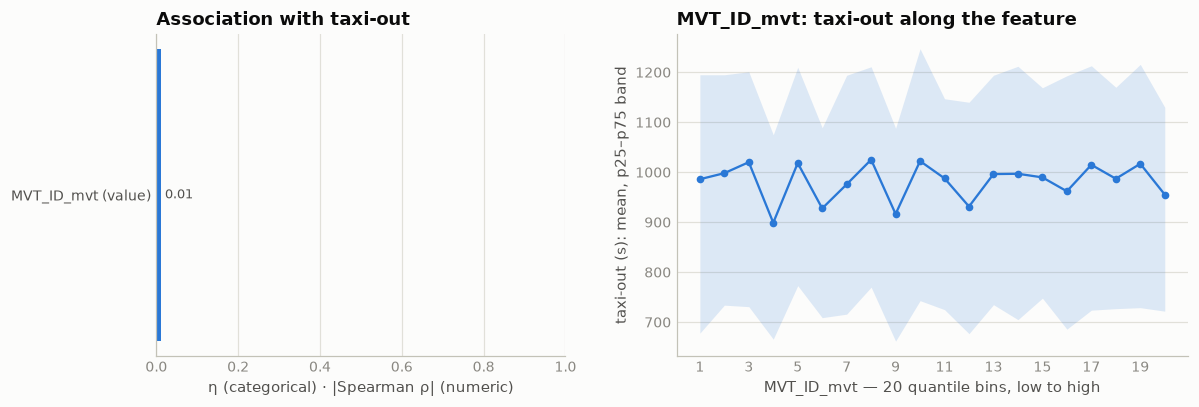

In [56]:
# correlation with the target — the ID is a counter; whatever it carries is the calendar's, not its own
a = target_assoc([("MVT_ID_mvt (value)", "num", "MVT_ID_mvt")])
assoc_chart(a, "MVT_ID_mvt", kind="num", title="MVT_ID_mvt")

**Findings**

- A unique whole-number key, never null in either file, with no value shared between training
  and ranking; `submitting.parquet` is exactly the ranking departures' ID set. Treat it as an
  `int64` join key and nothing else.
- It is a clock in disguise: IDs were issued in near time order (rank corr ≈ 0.99 with movement
  time), so the 2026 rows carry numbers the model has never seen. **Use in modeling: none** — it
  never enters the feature set, and it must be stripped before any adversarial validation or it
  separates the two files on its own. Whatever time signal it carries comes honestly from the
  timestamp columns.

## 2 · `FLIGHT_ID_mvt` — the matched flight plan's serial number

Two systems feed these files. Airports record **movements** (a plane pushed back, a plane took
off); EUROCONTROL's Network Manager (NM) records **flight plans**. This column holds the ID of
the NM flight the movement was matched to — *when* that match succeeded — and every `*_flt`
column to the right comes along with it. One NM flight is one leg, so when both ends of a leg
are challenge airports the same ID legitimately appears twice: as `DEP` at the origin and as
`ARR` at the destination.

| step | question | what came out |
|---|---|---|
| **2 · census** | how often is it missing, is missing-ness structured, what do the duplicates mean? | missing ⇒ the whole `_flt` block is missing; the is-missing flag is a feature; an ID on two rows is one leg seen from both ends |
| **2a · who is unmatched** | are the unmatched IFR rows junk or real flights? | a fifth fly to Ercan, where no plan can exist; the rest are matching failures of ordinary flights |
| **2b · why matching fails, exact-twin recovery** | what breaks the match, and can the plan be found elsewhere? | heavily delayed flights whose off-block estimate was never refiled; the twin arrival row still carries the plan → recovery layer 1 |
| **2c · relaxed twins, history imputation** | how much further can recovery go? | layers 2 and 3; 265 of 344,841 predictions stay bare |
| **how the pipeline consumes it** | rules | coalesce raw → 1 → 2 → 3; keep the no-plan flag on imputed rows |

presence by file × phase, and the ID range:
     src  ph       n  n_null  pct_null  n_unique  min_id_m  max_id_m
training ARR 2082750    8506      0.41   2074244     280.3     294.6
training DEP 2085047   22424      1.08   2062620     280.4     294.6
 ranking ARR  344693    1409      0.41    343284     294.6     303.0
 ranking DEP  344841    5283      1.53    339557     294.6     303.0

appearances per non-null ID (training) — and what the doubles are:


 cnt   n_ids  dep_arr_pairs  dep_dest_equals_arr_airport  dep_dep
   1 3506323              0                            0        0
   2  315272         315269                       313639        3

ID missing vs whole _flt block missing (training):
 id_null  flt_block_null       n   n_arr
   False           False 4129878 2067301
    True            True   30930    8506
   False            True    6989    6943

VFR departures: 2,930 — unmatched: 2,930
FLIGHT_IDs in BOTH files: 4 — training side from 2025-12-31 21:34, ranking side until 2026-01-01 01:38

taxi-out by rule × match (training DEP):
flight_rule  unmatched       n  med_taxi_out
          I      False 2062460         911.0
          I       True   19454        1009.0
          V       True    2930         232.0


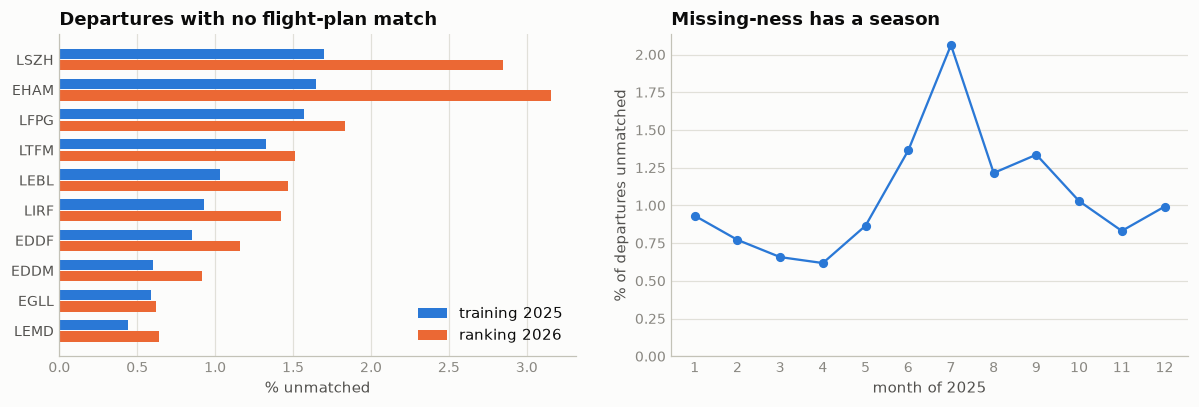

In [5]:
APS = "('LTFM','EHAM','LFPG','EGLL','EDDF','LEMD','LEBL','EDDM','LIRF','LSZH')"  # the ten hubs

print("presence by file × phase, and the ID range:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) n_null,
           round(100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*), 2) pct_null,
           count(DISTINCT FLIGHT_ID_mvt) n_unique,
           round(min(FLIGHT_ID_mvt)/1e6, 1) min_id_m, round(max(FLIGHT_ID_mvt)/1e6, 1) max_id_m
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nappearances per non-null ID (training) — and what the doubles are:")
print(con.sql(f"""
    SELECT cnt, count(*) n_ids,
           count(*) FILTER (phases = 'ARR+DEP') dep_arr_pairs,
           count(*) FILTER (phases = 'ARR+DEP' AND same_leg) dep_dest_equals_arr_airport,
           count(*) FILTER (phases = 'DEP+DEP') dep_dep
    FROM (SELECT FLIGHT_ID_mvt, count(*) cnt,
                 string_agg(PHASE_mvt, '+' ORDER BY PHASE_mvt) phases,
                 max(CASE WHEN PHASE_mvt = 'DEP' THEN ADES_mvt END)
                   = max(CASE WHEN PHASE_mvt = 'ARR' THEN ADES_mvt END) same_leg
          FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nID missing vs whole _flt block missing (training):")
print(con.sql(f"""
    SELECT FLIGHT_ID_mvt IS NULL id_null, CALLSIGN_flt IS NULL flt_block_null,
           count(*) n, count(*) FILTER (PHASE_mvt = 'ARR') n_arr
    FROM {T} GROUP BY 1, 2 ORDER BY n DESC""").df().to_string(index=False))

vfr = con.sql(f"""SELECT count(*), count(*) FILTER (FLIGHT_ID_mvt IS NULL)
                  FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'V'""").fetchone()
shared = con.sql(f"""
    SELECT count(DISTINCT t.FLIGHT_ID_mvt),
           min(strftime(t.MVT_TIME_UTC_mvt, '%Y-%m-%d %H:%M')), max(strftime(r.MVT_TIME_UTC_mvt, '%Y-%m-%d %H:%M'))
    FROM {T} t JOIN {R} r ON t.FLIGHT_ID_mvt = r.FLIGHT_ID_mvt""").fetchone()
print(f"\nVFR departures: {vfr[0]:,} — unmatched: {vfr[1]:,}")
print(f"FLIGHT_IDs in BOTH files: {shared[0]} — training side from {shared[1]}, ranking side until {shared[2]}")

print("\ntaxi-out by rule × match (training DEP):")
print(con.sql(f"""
    SELECT FLIGHT_RULE_mvt flight_rule, FLIGHT_ID_mvt IS NULL unmatched, count(*) n,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi_out
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt IN ('I', 'V')
    GROUP BY 1, 2 ORDER BY 1, 2""").df().to_string(index=False))

# where and when the departure-side match fails
unm = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt a, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
               FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt a, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
               FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT t.a airport, t.pct pct_t, r.pct pct_r FROM t JOIN r ON t.a = r.a ORDER BY t.pct""").df()
mon = con.sql(f"""
    SELECT month(MVT_TIME_UTC_mvt) m, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
    FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(unm))
a1.barh(y + 0.19, unm.pct_t, height=0.34, color=BLUE, label="training 2025")
a1.barh(y - 0.19, unm.pct_r, height=0.34, color=ORANGE, label="ranking 2026")
a1.set_yticks(y, unm.airport, color=INK2)
a1.set_title("Departures with no flight-plan match")
a1.set_xlabel("% unmatched")
a1.legend(loc="lower right")
style(a1, x_grid=True, y_grid=False)
a2.plot(mon.m, mon.pct, "o-", color=BLUE, ms=5)
a2.set_xticks(range(1, 13))
a2.set_ylim(bottom=0)
a2.set_title("Missing-ness has a season")
a2.set_xlabel("month of 2025")
a2.set_ylabel("% of departures unmatched")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

| fact | evidence (training unless noted) | what it means for us |
|---|---|---|
| Missing on 1.08% of departures and 0.41% of arrivals; **1.53%** of ranking departures | presence table | the no-plan path is a small slice, ~1.5× more common at prediction time than in training |
| Missing ID ⇒ the whole `_flt` block is empty | 30,930 rows null on both, never an ID-less row with plan data | one flag covers all sixteen `_flt` columns |
| The reverse does not quite hold | 6,989 rows carry an ID but an empty block, almost all arrivals | matched, but the plan data did not come through; irrelevant for the departures we model |
| Every VFR departure is unmatched | 2,930 of 2,930 | VFR flights do not file NM plans — expected, not a bug |
| Missing-ness is structured, not random | highest at Zurich and Schiphol; peaks in summer | general-aviation season at GA-heavy hubs, plus the matching failures of 2a–2b |
| An ID on two rows is one leg seen from both ends | 315,272 IDs appear twice; 315,269 are a `DEP`+`ARR` pair and for 313,639 (99.5%) the departure's destination is the arrival's airport; 3 odd `DEP`+`DEP` | the leg's two ends can be linked — 2b builds its recovery on this |
| The files were split by movement date, not by flight | 4 IDs in both files: departed on 31 Dec 2025, landed on 1 Jan 2026 | ranking's ID block sits just above training's |
| Unmatched flights taxi differently | IFR unmatched median 1,009 s vs 911 s matched; VFR unmatched 232 s | the flag carries signal of its own |

**Use in modeling.** The value is a join key — no signal beyond record time. The **is-missing
indicator** is a feature: it flags VFR/GA traffic, delayed flights (2b), and the rows where the
`AOBT_3` taxi anchor cannot exist. The `DEP`+`ARR` pairing is the basis of the recovery in 2b.

### 2a · Who is unmatched — expected gaps, or failures?

A missing VFR plan is expected: VFR flights do not file with NM. An IFR flight must, yet IFR
turns out to be the bulk of the unmatched rows. The cell profiles the unmatched IFR movements —
which hubs, which other end of the leg, which months, how complete the movement half is — and
checks whether the same pattern is in the ranking file.

In [6]:
U = f"{T} WHERE FLIGHT_ID_mvt IS NULL AND FLIGHT_RULE_mvt = 'I'"

xtab = con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '?') AS flight_rule,
           count(*) FILTER (PHASE_mvt = 'DEP') dep,
           count(*) FILTER (PHASE_mvt = 'ARR') arr, count(*) total
    FROM {T} WHERE FLIGHT_ID_mvt IS NULL GROUP BY 1 ORDER BY total DESC""").df()
by_ap = con.sql(f"""
    SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END airport, count(*) n,
           round(100.0*count(*)/sum(count(*)) OVER (), 1) pct
    FROM {U} GROUP BY 1 ORDER BY n DESC LIMIT 5""").df()
other_end = con.sql(f"""
    SELECT coalesce(CASE WHEN PHASE_mvt = 'DEP' THEN ADES_mvt ELSE ADEP_mvt END, '?') other_end,
           count(*) n
    FROM {U} GROUP BY 1 ORDER BY n DESC LIMIT 8""").df()
by_month = con.sql(f"""
    SELECT month(MVT_TIME_UTC_mvt) m, count(*) n FROM {U} GROUP BY 1 ORDER BY 1""").df()
complete = con.sql(f"""
    SELECT count(*) n, count(*) FILTER (SCHED_TIME_UTC_mvt IS NULL) sched_null,
           count(*) FILTER (RUNWAY_mvt IS NULL) rwy_null,
           count(*) FILTER (STAND_mvt IS NULL) stand_null,
           count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL) actype_null,
           count(*) FILTER (regexp_matches(FLIGHT_mvt, '^[A-Z]{{3}}[0-9]')) icao_callsign
    FROM {U}""").df()
rk = con.sql(f"""
    SELECT count(*) FILTER (FLIGHT_RULE_mvt = 'I') ifr_unmatched,
           count(*) FILTER (FLIGHT_RULE_mvt = 'I'
               AND CASE WHEN PHASE_mvt='DEP' THEN ADES_mvt ELSE ADEP_mvt END = 'LCEN') ifr_ercan,
           count(*) FILTER (PHASE_mvt = 'DEP' AND ADES_mvt = 'LCEN') dep_to_ercan
    FROM {R} WHERE FLIGHT_ID_mvt IS NULL""").df()

print("unmatched rows by flight rule (training):")
print(xtab.to_string(index=False))
print("\nunmatched IFR — top challenge airports:")
print(by_ap.to_string(index=False))
print("\nunmatched IFR — the leg's other end (note LCEN = Ercan, Northern Cyprus):")
print(other_end.to_string(index=False))
print("\nunmatched IFR — by month:")
print(by_month.set_index("m").T.to_string())
print("\nunmatched IFR — completeness of the movement half:")
print(complete.to_string(index=False))
print("\nranking file: unmatched IFR rows:", rk.ifr_unmatched[0],
      "| involving Ercan:", rk.ifr_ercan[0],
      "| DEP→LCEN rows we must predict:", rk.dep_to_ercan[0])

unmatched rows by flight rule (training):
flight_rule   dep  arr  total
          I 19454 5294  24748
          V  2930 3149   6079
          ?    40   63    103

unmatched IFR — top challenge airports:
airport    n  pct
   LTFM 6660 26.9
   LFPG 4073 16.5
   EHAM 3965 16.0
   EDDF 2006  8.1
   LEBL 1736  7.0

unmatched IFR — the leg's other end (note LCEN = Ercan, Northern Cyprus):
other_end    n
     LCEN 5543
     EHAM  531
     LLBG  499
     EINN  393
     DAAG  354
     LFMN  307
     LPPT  296
     HRYR  290

unmatched IFR — by month:
m    1     2     3     4     5     6     7     8     9     10    11    12
n  1631  1203  1152  1210  1798  2650  4177  2495  2693  2213  1612  1914

unmatched IFR — completeness of the movement half:
    n  sched_null  rwy_null  stand_null  actype_null  icao_callsign
24748           0         0          26         1645          18700

ranking file: unmatched IFR rows: 5771 | involving Ercan: 1189 | DEP→LCEN rows we must predict: 594


**Findings**

| observation | evidence | reading |
|---|---|---|
| IFR is the bulk of the unmatched rows | 24,748 IFR vs 6,079 VFR and 103 with no rule | most gaps are not the expected VFR kind |
| **Ercan explains the biggest chunk** | 5,543 of 24,748 unmatched-IFR rows (22%) have Ercan (`LCEN`, Northern Cyprus) as the leg's other end; Istanbul tops the hub list at 27% | not a bug: Northern Cyprus is unrecognized, so NM never processes these flights — **there is no plan to match** |
| The rest are real flights, not junk | 76% carry proper ICAO callsigns; schedule and runway present on 100%, stand on 99.9%; ordinary A320/B738 fleet; other ends include Tel Aviv, Algiers and Kigali but also Amsterdam and Shannon | scheduled flights whose NM match simply failed, more often on legs touching the edge of the IFPS zone |
| Summer peak | July 4,177 vs 1,150–1,900 in the winter months | matching degrades under load — the same bump as the overall unmatched rate |
| It persists at prediction time | ranking: 5,771 unmatched IFR rows, 1,189 involving Ercan, **594 departures to Ercan to predict** | the no-plan path (no `AOBT_3`, operator, segment) is a real, Istanbul-heavy slice of the eval set |

### 2b · Why matching fails, and the exact-twin recovery

Ercan aside, the unmatched IFR departures are **matching failures**: 0.80% of departures. Three
tests say what they are, and the third also shows where the missing plan can be found.

| test | question | how |
|---|---|---|
| **1 · delay** | are failed flights unusual? | takeoff − schedule, failed vs matched IFR departures |
| **2 · episodic?** | do failures strike particular flight numbers, or ordinary ones on a bad day? | share of failed departures whose flight number is matched on > 90% of its *other* 2025 occurrences |
| **3 · the twin** | did a plan exist at all? | a leg between two challenge airports has **two rows** — the origin's `DEP` and the destination's `ARR` — each matched to NM independently. If the departure's twin arrival (same flight number, same route, landing within 8 h) carries a `FLIGHT_ID`, the plan was there and only the departure-side link broke |

**Recovery rule.** For an unmatched departure whose twin arrival is (a) the *only* candidate in
the 8 h window and (b) agrees on aircraft type (or type is missing on one side), take the
twin's `FLIGHT_ID` and entire `_flt` block as the departure's own — same leg, so the plan fields
apply verbatim. It works identically at prediction time because ranking arrivals are fully
populated. Output: `data/derived/recovered_flt_blocks.parquet`.

In [7]:
# evidence 1: delay of failed vs matched IFR departures (Ercan excluded)
print("evidence 1 — delay (DEP IFR, Ercan excluded):")
print(con.sql(f"""
    SELECT CASE WHEN FLIGHT_ID_mvt IS NULL THEN 'unmatched IFR' ELSE 'matched IFR' END grp,
           count(*) n, round(quantile_cont(d, 0.5)) med_delay_min,
           round(quantile_cont(d, 0.9)) p90_delay_min,
           round(100.0*count(*) FILTER (d > 180)/count(*), 1) pct_over_3h
    FROM (SELECT FLIGHT_ID_mvt, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 d
          FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'I'
            AND coalesce(ADES_mvt, '') != 'LCEN')
    GROUP BY 1""").df().to_string(index=False))

# evidence 2: failures strike flight numbers that are usually matched
usual = con.sql(f"""
    WITH occ AS (SELECT FLIGHT_mvt f, count(*) n_tot,
                        count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL) n_m
                 FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL GROUP BY 1)
    SELECT round(100.0*count(*) FILTER (o.n_tot >= 6 AND o.n_m::DOUBLE/(o.n_tot-1) > 0.9)
                 /count(*), 1)
    FROM {T} u JOIN occ o ON u.FLIGHT_mvt = o.f
    WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL AND u.FLIGHT_RULE_mvt = 'I'
      AND coalesce(u.ADES_mvt, '') != 'LCEN'""").fetchone()[0]
print(f"\nevidence 2 — failed departures whose flight number is matched >90% of other days: {usual}%")

# evidence 3: the twin test — is the same leg's ARR row matched?
print("\nevidence 3 — twin test:")
print(con.sql(f"""
    SELECT count(*) n_unmatched_dep_to_hub, count(*) FILTER (found) twin_found,
           count(*) FILTER (found_matched) twin_has_flight_id
    FROM (SELECT
        EXISTS (SELECT 1 FROM {T} a WHERE a.PHASE_mvt='ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
                AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
                AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                           AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR) found,
        EXISTS (SELECT 1 FROM {T} a WHERE a.PHASE_mvt='ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
                AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
                AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                           AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
                AND a.FLIGHT_ID_mvt IS NOT NULL) found_matched
      FROM {T} u
      WHERE u.PHASE_mvt='DEP' AND u.FLIGHT_ID_mvt IS NULL AND u.FLIGHT_RULE_mvt='I'
        AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL)""").df().to_string(index=False))

# sanity checks that the twin is the same flight, and the mechanism behind the failure
PAIRS = f"""
    SELECT u.MVT_ID_mvt, u.AIRCRAFT_TYPE_mvt u_type, a.AIRCRAFT_TYPE_mvt a_type,
           u.BLOCK_TIME_UTC_mvt u_block, u.SCHED_TIME_UTC_mvt u_sched,
           u.MVT_TIME_UTC_mvt u_takeoff, a.MVT_TIME_UTC_mvt a_landing,
           a.AOBT_3_flt aobt3, a.EOBT_1_flt eobt1, a.IOBT_flt iobt, a.ARVT_3_flt arvt3,
           count(*) OVER (PARTITION BY u.MVT_ID_mvt) n_cand,
           row_number() OVER (PARTITION BY u.MVT_ID_mvt ORDER BY a.MVT_TIME_UTC_mvt) rn
    FROM {T} u JOIN {T} a
      ON a.PHASE_mvt = 'ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
     AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
     AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
     AND a.FLIGHT_ID_mvt IS NOT NULL AND a.CALLSIGN_flt IS NOT NULL
    WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL
      AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL"""
print("\nsanity checks on the twin pairs, and the mechanism (training):")
print(con.sql(f"""
    SELECT count(*) n_pairs,
      round(100.0*count(*) FILTER (n_cand = 1)/count(*), 1) pct_unique_twin,
      round(100.0*count(*) FILTER (u_type = a_type)
            /count(*) FILTER (u_type IS NOT NULL AND a_type IS NOT NULL), 1) pct_actype_agree,
      round(quantile_cont(abs(epoch(u_block - aobt3))/60.0, 0.5), 1) med_blk_vs_aobt3_min,
      round(100.0*count(*) FILTER (abs(epoch(a_landing - arvt3)) <= 900)
            /count(*) FILTER (arvt3 IS NOT NULL), 1) pct_arvt3_landing_15m,
      round(100.0*count(*) FILTER (epoch(u_takeoff - aobt3) BETWEEN 120 AND 3600)
            /count(*) FILTER (aobt3 IS NOT NULL), 1) pct_taxi_plausible,
      -- the mechanism: actual delay vs how far the plan's EOBT ever moved
      round(quantile_cont(epoch(u_block - u_sched)/60.0, 0.5)) med_actual_delay_min,
      round(quantile_cont(epoch(eobt1 - u_sched)/60.0, 0.5)) med_eobt1_shift_min,
      round(quantile_cont(epoch(eobt1 - iobt)/60.0, 0.5)) med_eobt1_vs_iobt_min
    FROM ({PAIRS}) WHERE rn = 1""").df().T.rename(columns={0: "value"}).to_string())

evidence 1 — delay (DEP IFR, Ercan excluded):


          grp       n  med_delay_min  p90_delay_min  pct_over_3h
unmatched IFR   16683           99.0          167.0          7.9
  matched IFR 2062459           23.0           56.0          0.6

evidence 2 — failed departures whose flight number is matched >90% of other days: 86.3%

evidence 3 — twin test:
 n_unmatched_dep_to_hub  twin_found  twin_has_flight_id
                   2207         907                 896

sanity checks on the twin pairs, and the mechanism (training):
                       value
n_pairs                906.0
pct_unique_twin        100.0
pct_actype_agree        98.2
med_blk_vs_aobt3_min     3.1
pct_arvt3_landing_15m   99.7
pct_taxi_plausible      97.7
med_actual_delay_min    79.0
med_eobt1_shift_min     20.0
med_eobt1_vs_iobt_min    0.0


In [8]:
# perform the recovery -> data/derived/recovered_flt_blocks.parquet, then account for every unmatched departure
FLT_COLS = ["LOBT_flt", "CALLSIGN_flt", "ADEP_flt", "ADES_flt", "ADES_FILED_flt",
            "MARKET_SEGMENT_flt", "IOBT_flt", "FLIGHT_RULE_flt", "FLIGHT_TYPE_flt",
            "AIRCRAFT_TYPE_flt", "WK_TBL_CAT_flt", "AIRCRAFT_OPERATOR_flt",
            "EOBT_1_flt", "ARVT_1_flt", "AOBT_3_flt", "ARVT_3_flt"]


def recover(u_src, a_src, tag):
    """Recover _flt blocks for unmatched DEPs in u_src from twin ARRs in a_src."""
    a_cols = ", ".join(f"a.{c}" for c in FLT_COLS)
    return con.sql(f"""
        SELECT * EXCLUDE (n_cand, rn, u_type, a_type) FROM (
            SELECT u.MVT_ID_mvt, '{tag}' dataset,
                   a.FLIGHT_ID_mvt FLIGHT_ID_recovered,
                   a.MVT_ID_mvt recovered_from_arr_mvt_id, {a_cols},
                   u.AIRCRAFT_TYPE_mvt u_type, a.AIRCRAFT_TYPE_mvt a_type,
                   count(*) OVER (PARTITION BY u.MVT_ID_mvt) n_cand,
                   row_number() OVER (PARTITION BY u.MVT_ID_mvt
                                      ORDER BY a.MVT_TIME_UTC_mvt) rn
            FROM {u_src} u JOIN {a_src} a
              ON a.PHASE_mvt = 'ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
             AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
             AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                        AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
             AND a.FLIGHT_ID_mvt IS NOT NULL AND a.CALLSIGN_flt IS NOT NULL
            WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL
              AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL)
        WHERE rn = 1 AND n_cand = 1
          AND (u_type = a_type OR u_type IS NULL OR a_type IS NULL)""").df()


rec_train = recover(T, T, "training")
# a ranking DEP's twin ARR normally sits in the ranking file itself;
# the union covers legs crossing the Dec-31 -> Jan-1 file boundary
rec_rank = recover(R, f"(SELECT * FROM {R} UNION ALL SELECT * FROM {T})", "ranking")
recovered = pd.concat([rec_train, rec_rank], ignore_index=True)

out = ROOT / "data" / "derived"
out.mkdir(parents=True, exist_ok=True)
recovered.to_parquet(out / "recovered_flt_blocks.parquet", index=False)
print(f"recovered {len(rec_train):,} training and {len(rec_rank):,} ranking departures "
      f"-> {out / 'recovered_flt_blocks.parquet'}")

REC = f"read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
both = f"(SELECT * FROM {T} UNION ALL SELECT * FROM {R})"

print("\nwhere every unmatched departure stands:")
print(con.sql(f"""
    WITH u AS (
        SELECT dataset, MVT_ID_mvt, coalesce(FLIGHT_RULE_mvt, '?') AS flight_rule,
               coalesce(ADES_mvt = 'LCEN', FALSE) is_ercan
        FROM (SELECT 'training' AS dataset, * FROM {T}
              UNION ALL SELECT 'ranking' AS dataset, * FROM {R})
        WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL),
    tot AS (SELECT 'training' dataset, count(*) n_dep FROM {T} WHERE PHASE_mvt = 'DEP'
            UNION ALL SELECT 'ranking', count(*) FROM {R} WHERE PHASE_mvt = 'DEP')
    SELECT u.dataset, count(*) unmatched_dep,
           count(*) FILTER (r.MVT_ID_mvt IS NOT NULL) recovered,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND is_ercan) ercan_no_plan,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND NOT is_ercan
                            AND flight_rule = 'V') vfr_no_plan,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND NOT is_ercan
                            AND flight_rule != 'V') residual_failures,
           round(100.0*count(*) FILTER (r.MVT_ID_mvt IS NULL AND NOT is_ercan
                                        AND flight_rule != 'V')/any_value(tot.n_dep), 2) residual_pct_of_dep
    FROM u LEFT JOIN {REC} r ON u.MVT_ID_mvt = r.MVT_ID_mvt JOIN tot ON tot.dataset = u.dataset
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

# the wrinkle: recovery did not filter on flight rule — six recovered departures are flagged VFR
print("\nmovement rule × plan rule on the recovered rows:")
print(con.sql(f"""
    SELECT t.FLIGHT_RULE_mvt rule_mvt, r.FLIGHT_RULE_flt rule_plan, count(*) n
    FROM {REC} r JOIN {both} t ON t.MVT_ID_mvt = r.MVT_ID_mvt
    GROUP BY 1, 2 ORDER BY n DESC""").df().to_string(index=False))
print("\nthe V-flagged recoveries:")
print(con.sql(f"""
    SELECT t.FLIGHT_mvt, t.ADEP_mvt, t.ADES_mvt,
           strftime(t.MVT_TIME_UTC_mvt, '%m-%d %H:%M') takeoff,
           t.FLIGHT_RULE_mvt rule_mvt, r.FLIGHT_RULE_flt rule_plan,
           r.MARKET_SEGMENT_flt segment, t.AIRCRAFT_TYPE_mvt actype
    FROM {REC} r JOIN {both} t ON t.MVT_ID_mvt = r.MVT_ID_mvt
    WHERE t.FLIGHT_RULE_mvt = 'V' ORDER BY t.MVT_TIME_UTC_mvt""").df().to_string(index=False))

recovered 892 training and 226 ranking departures -> /home/gunes/PRC/data/derived/recovered_flt_blocks.parquet

where every unmatched departure stands:
 dataset  unmatched_dep  recovered  ercan_no_plan  vfr_no_plan  residual_failures  residual_pct_of_dep
training          22424        892           2771         2924              15837                 0.76
 ranking           5283        226            594          419               4044                 1.17

movement rule × plan rule on the recovered rows:
rule_mvt rule_plan    n
       I         I 1112
       V         Z    3
       V         I    2
       V         Y    1

the V-flagged recoveries:
FLIGHT_mvt ADEP_mvt ADES_mvt     takeoff rule_mvt rule_plan  segment actype
    FCK2FT     LSZH     LSZH 03-11 21:58        V         I    Other   B350
     ICC03     LEBL     LEBL 08-16 06:47        V         Z Business   C208
     ICC03     LEBL     LEBL 09-18 08:54        V         Z Business   C208
    NCG01A     EHAM     EHAM 10-25 09:

**Findings**

| test | result | reading |
|---|---|---|
| **1 · delay** | failed departures ran a median **99 min** late vs 23 min for matched; 7.9% more than 3 h late vs 0.6% | failures are heavily delayed flights |
| **2 · episodic** | 86% of failed departures carry a flight number that is matched on > 90% of its other 2025 occurrences | ordinary flights on a bad day, not bad flight numbers |
| **3 · the twin** | of 2,207 unmatched departures to another hub, 907 have a locatable twin arrival and **896 of those carry a `FLIGHT_ID`** | the plan existed; only the departure-side link broke |

**Why the link breaks**, read off the twins' plan data: the aircraft left a median **79 min**
late, but the plan's expected off-block `EOBT_1` moved only **20 min** from schedule, and for
the median flight still *equals* the initially filed `IOBT`. The airline never refiled the
delay. A matcher pairing movements to plans inside a window around `EOBT` loses exactly these
flights; the arrival side survives because it keys on the flown arrival time (`ARVT_3` within
15 min of the actual landing for 99.7%).

| sanity check that the twin is the same flight | result |
|---|---|
| twin unique in its 8 h window | 100% of 906 pairs |
| aircraft type logged by the two airports agrees | 98.2% |
| plan's actual off-block vs the departure's own block time | median 3.1 min apart |
| implied taxi (takeoff − `AOBT_3`) between 2 and 60 min | 97.7% |

**Where this leaves the unmatched departures**

| | unmatched DEP | recovered (twin) | Ercan — no plan | VFR — no plan | **residual failures** |
|---|---:|---:|---:|---:|---:|
| training | 22,424 | 892 | 2,771 | 2,924 | **15,837** (0.76% of departures) |
| ranking | 5,283 | 226 | 594 | 419 | **4,044** (1.17%) |

The residual rate is ~1.5× higher in ranking: 2026's matching is worse, so the fallback path
matters more at prediction time than in CV.

| decision on the residual rows | why |
|---|---|
| **Keep them in training** | real, sanity-checked flights; the eval set contains their kind (1.17% of predictions) — dropping them would starve exactly that path |
| **Make "no flight plan" an explicit feature** | for IFR it is a delay fingerprint (median 99 min late vs 23) and goes with longer taxi (median 1,009 s vs 911 s) |
| **Lean on the movement half** | airport, runway, stand, aircraft type, schedule and congestion features are all present; only the `AOBT_3` anchor is lost |
| **Optionally read the callsign prefix** | `FLIGHT_mvt`'s `THY` / `KLM` / `RYR` prefix is an operator token when the anonymized `AIRCRAFT_OPERATOR_flt` is missing |

**A wrinkle: six recovered rows are flagged VFR — kept.**

| objection | answer |
|---|---|
| A VFR flight's missing plan should be *correct*; nothing to recover | these six provably filed with NM — that is what their matched twin established; 4 of 6 filed **mixed-rule plans** (`Z` = VFR then IFR, `Y` = IFR then VFR) |
| How can the two rule flags disagree? | `FLIGHT_RULE_mvt` is the rule *when the airport saw the movement*; `FLIGHT_RULE_flt` is the *filed plan*; rules switch mid-flight legitimately, e.g. weather forcing a VFR flight onto instruments |
| Who are they? | circular flights (Zurich→Zurich, Barcelona→Barcelona, Amsterdam→Amsterdam) on King Air, Caravan, Dash-8 and Do228 — survey, calibration, patrol: exactly the operations that mix VFR and IFR segments |
| Why keep them? | the recovery rule requires the twin to carry a `FLIGHT_ID`, i.e. **evidence that a plan existed**. A purely-VFR flight that never filed cannot pass, which is why only 6 of ~2,930 V-flagged unmatched departures were recovered — precisely the six whose "no plan" was wrong. Evidence beats a flag we have just watched be wrong six times |

### 2c · Extended recovery — relaxed twins and history imputation

Two further pathways, designed and stress-tested in a multi-agent research run: each pathway's
numbers were re-derived by an adversarial verifier before adoption; a third pathway
(stand-rotation linking) validated too but was shelved because history imputation fills most
of the same rows. A valuation study sized the total eval-RMSE stakes at **~0.1 s** — this is
about feature completeness and one unified model, not a metric win.

**Idea 1 — relaxed twin matching**, recovering the full `_flt` block, `AOBT_3` anchor
included. 2b required the departure's `FLIGHT_mvt` to equal the arrival's verbatim, but
identifiers get logged in different spellings (`KL1825` vs `KLM53T`), so real twins slip
through. A waterfall, strictest stage first:

| stage | identifier rule | landing window |
|---|---|---|
| **A** cross-field verbatim | DEP `FLIGHT_mvt` equals the ARR's `CALLSIGN_flt` *or* its `FLIGHT_mvt` | 15 min – 8 h after takeoff |
| **B** normalized | airline prefix mapped IATA→ICAO with a map *learned from the data* (matched rows where both spellings share the numeric tail; kept at ≥ 30 observations and ≥ 90% dominance); numeric tails stripped of leading zeros | 15 min – 8 h |
| **C** identifier-free | none — route, aircraft type and timing only | 0.8× – 1.3× the route's median airborne time (+ 15 min); routes with ≥ 20 matched pairs |

Every stage also requires: same ADEP and ADES, equal aircraft type, **exactly one** surviving
candidate, and an ARR `FLIGHT_ID` not already claimed by a matched departure (a plan cannot
belong to two departures). Twin collisions — two probes claiming one ARR — are dropped.

| validation of idea 1 | result |
|---|---|
| 25,000 held-out matched hub-to-hub departures, reference tables rebuilt without them | **99.91% correct** (A 99.91 / B 99.80 / C 99.96) |
| disruption days | ~99% |
| false-return rate with the true twin hidden from the pool | 0.06–0.13% |

**Idea 2 — flight-number history imputation** of the static fields only (timestamps are
unrecoverable by construction). `KL1825` flies the same route daily; its matched occurrences on
*other days* supply the stable fields through a gated cascade per field. This is the only
pathway that reaches the Ercan and VFR rows.

| level | key | gate: support, agreement |
|---|---|---|
| **L1** | same `FLIGHT_mvt` + `ADEP` | ≥ 3, ≥ 0.80 |
| **L2** | callsign prefix + `ADEP` | ≥ 3, ≥ 0.80 — tightened to ≥ 10, ≥ 0.99 for segment and flight type |
| **L3** | callsign prefix | as L2 |
| **LT** | the row's own `AIRCRAFT_TYPE_mvt`, through a majority type → value map | ≥ 3, ≥ 0.80 |

Leave-one-out validated accuracy per field and level, from 30k random + 20k delayed matched
departures (the worse of the two), plus out-of-sample on the twin-recovered rows — a genuinely
unmatched population. Cascade order is left to right; wake and aircraft type try `LT` first.

| field | LT own type | L1 flight + ADEP | L2 prefix + ADEP | L3 prefix |
|---|---|---|---|---|
| `AIRCRAFT_OPERATOR_flt` | — | 99.96% | 99.57% | 97.06% |
| `MARKET_SEGMENT_flt` | — | 99.04% | 94.76% | 95.21% |
| `FLIGHT_TYPE_flt` | — | 99.71% | 80.28% ⚑ | 78.26% ⚑ |
| `WK_TBL_CAT_flt` | **99.98%** | 99.43% | 99.57% | — |
| `AIRCRAFT_TYPE_flt` | **99.51%** | 92.55% ⚑ | — | — |

⚑ kept, but written with `low_confidence = TRUE`. These are the `POLICY` table in the code.

In [9]:
# ---- Idea 1: relaxed twin waterfall -> data/derived/recovered_flt_relaxed.parquet ----
con.sql(f"""CREATE OR REPLACE VIEW allrows AS
    SELECT *, 'training' AS dataset FROM {T}
    UNION ALL SELECT *, 'ranking' AS dataset FROM {R}""")
con.sql("""CREATE OR REPLACE VIEW arr_matched AS
    SELECT * FROM allrows WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL""")

# identifier normalization macros: style, airline prefix, numeric tail (no leading zeros)
con.sql("""
    CREATE OR REPLACE MACRO id_style(s) AS
      CASE WHEN s IS NULL THEN NULL
           WHEN regexp_matches(s, '^[A-Z]{3}[0-9]') THEN 'icao'
           WHEN regexp_matches(s, '^([A-Z][A-Z]|[A-Z][0-9]|[0-9][A-Z])[0-9]{1,4}[A-Z]?$') THEN 'iata'
           ELSE 'other' END;
    CREATE OR REPLACE MACRO id_prefix(s) AS
      CASE id_style(s) WHEN 'icao' THEN s[1:3] WHEN 'iata' THEN s[1:2] ELSE NULL END;
    CREATE OR REPLACE MACRO id_rest(s) AS
      CASE id_style(s) WHEN 'icao' THEN s[4:] WHEN 'iata' THEN s[3:] ELSE NULL END;
    CREATE OR REPLACE MACRO id_tail(s) AS
      CASE WHEN regexp_matches(id_rest(s), '^[0-9]+[A-Z]{0,3}$')
           THEN NULLIF(regexp_replace(id_rest(s), '^0+', ''), '') ELSE NULL END;
""")

# reference tables (all computable at deployment time)
con.sql("""
    CREATE OR REPLACE TABLE iata_map AS      -- empirical IATA(2) -> ICAO(3) airline codes
    WITH pairs AS (
        SELECT id_prefix(FLIGHT_mvt) iata2, id_prefix(CALLSIGN_flt) icao3, count(*) n
        FROM allrows
        WHERE FLIGHT_ID_mvt IS NOT NULL AND id_style(FLIGHT_mvt) = 'iata'
          AND id_style(CALLSIGN_flt) = 'icao' AND id_tail(FLIGHT_mvt) = id_tail(CALLSIGN_flt)
        GROUP BY 1, 2),
    ranked AS (SELECT *, sum(n) OVER (PARTITION BY iata2) tot,
                      row_number() OVER (PARTITION BY iata2 ORDER BY n DESC) rk FROM pairs)
    SELECT iata2, icao3 FROM ranked WHERE rk = 1 AND n >= 30 AND n/tot >= 0.90""")
con.sql("""
    CREATE OR REPLACE TABLE route_dur AS     -- median airborne time per route
    SELECT d.ADEP_mvt, d.ADES_mvt, median(epoch(a.MVT_TIME_UTC_mvt - d.MVT_TIME_UTC_mvt)) med_s
    FROM allrows d JOIN arr_matched a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt
         AND a.MVT_TIME_UTC_mvt > d.MVT_TIME_UTC_mvt
         AND a.MVT_TIME_UTC_mvt < d.MVT_TIME_UTC_mvt + INTERVAL 16 HOUR
    WHERE d.PHASE_mvt = 'DEP' AND d.FLIGHT_ID_mvt IS NOT NULL
    GROUP BY 1, 2 HAVING count(*) >= 20""")
con.sql("""
    CREATE OR REPLACE TABLE claimed AS       -- plans already attached to a matched DEP
    SELECT DISTINCT FLIGHT_ID_mvt FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL""")

# probes: still-missing DEP rows with a challenge-airport destination
con.sql(f"""
    CREATE OR REPLACE TABLE cand AS
    SELECT MVT_ID_mvt, dataset, FLIGHT_mvt, ADEP_mvt, ADES_mvt, MVT_TIME_UTC_mvt, AIRCRAFT_TYPE_mvt
    FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL AND ADES_mvt IN {APS}
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {REC})""")

VARIANTS = {
    'A': dict(ident="(a.CALLSIGN_flt = p.FLIGHT_mvt OR a.FLIGHT_mvt = p.FLIGHT_mvt)",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 15 MINUTE "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR", extra=""),
    'B': dict(ident="(p_al IS NOT NULL AND p_tl IS NOT NULL AND "
                    "((p_al = a_al_f AND p_tl = a_tl_f) OR (p_al = a_al_c AND p_tl = a_tl_c)))",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 15 MINUTE "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR", extra=""),
    'C': dict(ident="TRUE",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 1 SECOND * (0.80 * rd.med_s) "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 1 SECOND * (1.30 * rd.med_s + 900)",
              extra="JOIN route_dur rd ON rd.ADEP_mvt = p.ADEP_mvt AND rd.ADES_mvt = p.ADES_mvt"),
}
for v, s in VARIANTS.items():
    con.sql(f"""
        CREATE OR REPLACE TABLE m_{v} AS
        WITH probe_n AS (
            SELECT p0.*, coalesce(CASE id_style(p0.FLIGHT_mvt) WHEN 'icao'
                                  THEN id_prefix(p0.FLIGHT_mvt) END, im.icao3) p_al,
                   id_tail(p0.FLIGHT_mvt) p_tl
            FROM cand p0 LEFT JOIN iata_map im
              ON id_style(p0.FLIGHT_mvt) = 'iata' AND im.iata2 = id_prefix(p0.FLIGHT_mvt)),
        arr_n AS (
            SELECT a0.MVT_ID_mvt, a0.FLIGHT_ID_mvt, a0.FLIGHT_mvt, a0.CALLSIGN_flt,
                   a0.ADEP_mvt, a0.ADES_mvt, a0.MVT_TIME_UTC_mvt, a0.AIRCRAFT_TYPE_mvt,
                   coalesce(CASE id_style(a0.FLIGHT_mvt) WHEN 'icao'
                            THEN id_prefix(a0.FLIGHT_mvt) END, imf.icao3) a_al_f,
                   id_tail(a0.FLIGHT_mvt) a_tl_f,
                   coalesce(CASE id_style(a0.CALLSIGN_flt) WHEN 'icao'
                            THEN id_prefix(a0.CALLSIGN_flt) END, imc.icao3) a_al_c,
                   id_tail(a0.CALLSIGN_flt) a_tl_c
            FROM arr_matched a0
            LEFT JOIN iata_map imf ON id_style(a0.FLIGHT_mvt) = 'iata' AND imf.iata2 = id_prefix(a0.FLIGHT_mvt)
            LEFT JOIN iata_map imc ON id_style(a0.CALLSIGN_flt) = 'iata' AND imc.iata2 = id_prefix(a0.CALLSIGN_flt))
        SELECT p.MVT_ID_mvt probe_mvt_id, p.dataset, a.MVT_ID_mvt twin_arr_mvt_id,
               a.FLIGHT_ID_mvt twin_flight_id, '{v}' stage
        FROM probe_n p {s['extra']}
        JOIN arr_n a ON a.ADEP_mvt = p.ADEP_mvt AND a.ADES_mvt = p.ADES_mvt
         AND {s['window']} AND {s['ident']}
         AND p.AIRCRAFT_TYPE_mvt = a.AIRCRAFT_TYPE_mvt
         AND a.FLIGHT_ID_mvt NOT IN (SELECT FLIGHT_ID_mvt FROM claimed)
        QUALIFY count(*) OVER (PARTITION BY p.MVT_ID_mvt) = 1""")

con.sql("""
    CREATE OR REPLACE TABLE waterfall AS
    WITH stages AS (
        SELECT * FROM m_A
        UNION ALL SELECT * FROM m_B WHERE probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_A)
        UNION ALL SELECT * FROM m_C WHERE probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_A)
              AND probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_B))
    SELECT * FROM stages
    QUALIFY count(*) OVER (PARTITION BY twin_arr_mvt_id) = 1  -- drop twin collisions""")

a_cols = ", ".join(f"a.{c}" for c in FLT_COLS)
con.sql(f"""
    COPY (SELECT w.probe_mvt_id AS MVT_ID_mvt, w.dataset, w.stage AS matcher_variant,
                 w.twin_arr_mvt_id AS recovered_from_arr_mvt_id,
                 a.FLIGHT_ID_mvt AS FLIGHT_ID_recovered, {a_cols}
          FROM waterfall w JOIN arr_matched a ON a.MVT_ID_mvt = w.twin_arr_mvt_id)
    TO '{ROOT}/data/derived/recovered_flt_relaxed.parquet' (FORMAT PARQUET)""")

print(con.sql("SELECT dataset, stage, count(*) n FROM waterfall GROUP BY 1,2 ORDER BY 1 DESC,2")
      .df().to_string(index=False))
print(con.sql("SELECT dataset, count(*) n FROM waterfall GROUP BY 1 ORDER BY 1 DESC")
      .df().to_string(index=False))
print("wrote data/derived/recovered_flt_relaxed.parquet")

 dataset stage   n
training     A 527
training     B 217
training     C 263
 ranking     A 102
 ranking     B  50
 ranking     C 101
 dataset    n
training 1007
 ranking  253
wrote data/derived/recovered_flt_relaxed.parquet


In [10]:
# ---- Idea 2: history imputation of static _flt fields -> data/derived/imputed_flt_static.parquet ----
RELAXED = f"read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet')"

con.sql("""
    CREATE OR REPLACE TABLE hist AS   -- matched DEP history, both files (deployment-legal)
    SELECT FLIGHT_mvt, id_prefix(FLIGHT_mvt) prefix, ADEP_mvt, AIRCRAFT_TYPE_mvt,
           AIRCRAFT_OPERATOR_flt, MARKET_SEGMENT_flt, FLIGHT_TYPE_flt,
           WK_TBL_CAT_flt, AIRCRAFT_TYPE_flt
    FROM allrows WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL""")
miss = con.sql(f"""
    SELECT MVT_ID_mvt, dataset, FLIGHT_mvt, id_prefix(FLIGHT_mvt) prefix, ADEP_mvt,
           AIRCRAFT_TYPE_mvt,
           CASE WHEN ADES_mvt = 'LCEN' THEN 'lcen'
                WHEN FLIGHT_RULE_mvt = 'V' THEN 'vfr' ELSE 'failure' END subgroup
    FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {REC})
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {RELAXED})""").df()

LEVEL_KEYS = {
    "L1_flight_adep": ["FLIGHT_mvt", "ADEP_mvt"],
    "L2_prefix_adep": ["prefix", "ADEP_mvt"],
    "L3_prefix":      ["prefix"],
    "LT_actype":      ["AIRCRAFT_TYPE_mvt"],   # the row's own movement-side type
}
# per field: ordered (level, min_support, min_agreement, LOO-validated accuracy, low_confidence)
# accuracies from the research run's leave-one-out validation (worse of random/delayed samples)
POLICY = {
    "AIRCRAFT_OPERATOR_flt": [("L1_flight_adep", 3, 0.80, 0.9996, False),
                              ("L2_prefix_adep", 3, 0.80, 0.9957, False),
                              ("L3_prefix",      3, 0.80, 0.9706, False)],
    "MARKET_SEGMENT_flt":    [("L1_flight_adep", 3, 0.80, 0.9904, False),
                              ("L2_prefix_adep", 10, 0.99, 0.9476, False),
                              ("L3_prefix",      10, 0.99, 0.9521, False)],
    "FLIGHT_TYPE_flt":       [("L1_flight_adep", 3, 0.80, 0.9971, False),
                              ("L2_prefix_adep", 10, 0.99, 0.8028, True),
                              ("L3_prefix",      10, 0.99, 0.7826, True)],
    "WK_TBL_CAT_flt":        [("LT_actype",      3, 0.80, 0.9998, False),
                              ("L1_flight_adep", 3, 0.80, 0.9943, False),
                              ("L2_prefix_adep", 3, 0.90, 0.9957, False)],
    "AIRCRAFT_TYPE_flt":     [("LT_actype",      3, 0.80, 0.9951, False),
                              ("L1_flight_adep", 3, 0.80, 0.9255, True)],
}

def tier(a):
    return ">=99" if a >= 0.99 else "95-99" if a >= 0.95 else "90-95" if a >= 0.90 else "<90"

mode_tables = {}
for level, keys in LEVEL_KEYS.items():
    fields = ["WK_TBL_CAT_flt", "AIRCRAFT_TYPE_flt"] if level == "LT_actype" else list(POLICY)
    keycols = ", ".join(keys)
    notnull = " AND ".join(f"{k} IS NOT NULL" for k in keys)
    for f in fields:
        mode_tables[(level, f)] = con.sql(f"""
            WITH c AS (SELECT {keycols}, {f} val, count(*)::BIGINT c FROM hist
                       WHERE {f} IS NOT NULL AND {notnull} GROUP BY ALL)
            SELECT {keycols}, arg_max(val, c) pred, sum(c) n, max(c) cmax
            FROM c GROUP BY ALL""").df()

long_rows = []
for f, steps in POLICY.items():
    resolved = pd.Series(False, index=miss.index)
    for level, min_sup, min_agr, acc, low_conf in steps:
        j = miss.merge(mode_tables[(level, f)], on=LEVEL_KEYS[level], how="left")
        ok = (~resolved) & j.pred.notna() & (j.n >= min_sup) & (j.cmax / j.n >= min_agr)
        sel = j[ok.values]
        if len(sel):
            long_rows.append(pd.DataFrame({
                "MVT_ID_mvt": sel.MVT_ID_mvt.values, "dataset": sel.dataset.values,
                "subgroup": sel.subgroup.values, "field": f, "value": sel.pred.values,
                "level": level, "n_support": sel.n.values,
                "agreement": (sel.cmax / sel.n).values, "acc_validated": acc,
                "tier": tier(acc), "low_confidence": low_conf}))
        resolved = resolved | ok.values

imp = pd.concat(long_rows, ignore_index=True)
wide = miss[["MVT_ID_mvt", "dataset", "subgroup"]].copy()
for f in POLICY:
    sub = imp[imp.field == f].set_index("MVT_ID_mvt")
    base = f.replace("_flt", "")
    wide[f] = wide.MVT_ID_mvt.map(sub["value"])
    wide[base + "_tier"] = wide.MVT_ID_mvt.map(sub["tier"])
    wide[base + "_low_conf"] = wide.MVT_ID_mvt.map(sub["low_confidence"])
wide.to_parquet(ROOT / "data" / "derived" / "imputed_flt_static.parquet", index=False)

core3 = (wide.AIRCRAFT_OPERATOR_flt.notna() & (wide.AIRCRAFT_OPERATOR_tier.isin([">=99", "95-99"]))
         & wide.WK_TBL_CAT_flt.notna() & wide.AIRCRAFT_TYPE_flt.notna())
print(f"imputation targets: {len(miss):,} still-missing DEP rows "
      f"({(miss.dataset == 'ranking').sum():,} ranking)")
print("\nper-field coverage (any value / at >=95% validated accuracy):")
for f in POLICY:
    d = imp[imp.field == f]
    d95 = d[d.tier.isin([">=99", "95-99"])]
    print(f"  {f:24s} any={len(d):6,}   ge95={len(d95):6,}   "
          f"(ranking ge95: {(d95.dataset == 'ranking').sum():,})")
print(f"\ncore-3 rows (operator+wake+type all imputed, operator at >=95%): "
      f"{core3.sum():,}  (ranking: {(core3 & (wide.dataset == 'ranking')).sum():,})")
print("wrote data/derived/imputed_flt_static.parquet")

# ---- after everything: what changed for the departures we model ----
IMP = f"read_parquet('{ROOT}/data/derived/imputed_flt_static.parquet')"
STATIC = ["AIRCRAFT_OPERATOR_flt", "MARKET_SEGMENT_flt", "FLIGHT_TYPE_flt", "WK_TBL_CAT_flt", "AIRCRAFT_TYPE_flt"]
con.sql(f"""
    CREATE OR REPLACE TABLE dep_after AS
    SELECT d.dataset, d.MVT_ID_mvt,
           d.FLIGHT_ID_mvt id_raw,
           coalesce(d.FLIGHT_ID_mvt, l1.FLIGHT_ID_recovered) id_l1,
           coalesce(d.FLIGHT_ID_mvt, l1.FLIGHT_ID_recovered, l2.FLIGHT_ID_recovered) id_l2,
           d.AOBT_3_flt AOBT_3_flt_raw, coalesce(d.AOBT_3_flt, l1.AOBT_3_flt, l2.AOBT_3_flt) AOBT_3_flt_after,
           {", ".join(f"d.{c} {c}_raw, coalesce(d.{c}, l1.{c}, l2.{c}, l3.{c}) {c}_after" for c in STATIC)}
    FROM (SELECT * FROM allrows WHERE PHASE_mvt = 'DEP') d
    LEFT JOIN {REC} l1 USING (MVT_ID_mvt)
    LEFT JOIN {RELAXED} l2 USING (MVT_ID_mvt)
    LEFT JOIN {IMP} l3 USING (MVT_ID_mvt)""")

print("\nFLIGHT_ID on departures — missing before and after each layer:")
print(con.sql("""
    SELECT dataset, count(*) departures,
           count(*) FILTER (id_raw IS NULL) missing_raw,
           count(*) FILTER (id_l1 IS NULL) after_layer1,
           count(*) FILTER (id_l2 IS NULL) after_layer2,
           round(100.0*count(*) FILTER (id_raw IS NULL)/count(*), 2) pct_raw,
           round(100.0*count(*) FILTER (id_l2 IS NULL)/count(*), 2) pct_after
    FROM dep_after GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe _flt fields the model uses — % of departures missing, raw -> after all layers:")
rows = []
for c in ["AOBT_3_flt"] + STATIC:
    raw, aft = f"{c}_raw", f"{c}_after"
    rows.append(con.sql(f"""
        SELECT '{c}' field,
               round(100.0*count(*) FILTER (dataset = 'training' AND {raw} IS NULL)
                     /count(*) FILTER (dataset = 'training'), 2) train_raw,
               round(100.0*count(*) FILTER (dataset = 'training' AND {aft} IS NULL)
                     /count(*) FILTER (dataset = 'training'), 2) train_after,
               round(100.0*count(*) FILTER (dataset = 'ranking' AND {raw} IS NULL)
                     /count(*) FILTER (dataset = 'ranking'), 2) rank_raw,
               round(100.0*count(*) FILTER (dataset = 'ranking' AND {aft} IS NULL)
                     /count(*) FILTER (dataset = 'ranking'), 2) rank_after
        FROM dep_after""").df())
print(pd.concat(rows, ignore_index=True).to_string(index=False))

imputation targets: 25,329 still-missing DEP rows (4,804 ranking)

per-field coverage (any value / at >=95% validated accuracy):
  AIRCRAFT_OPERATOR_flt    any=23,696   ge95=23,696   (ranking ge95: 4,539)
  MARKET_SEGMENT_flt       any=20,364   ge95=19,219   (ranking ge95: 3,638)
  FLIGHT_TYPE_flt          any=22,745   ge95=19,658   (ranking ge95: 3,780)
  WK_TBL_CAT_flt           any=24,229   ge95=24,229   (ranking ge95: 4,622)
  AIRCRAFT_TYPE_flt        any=23,436   ge95=22,607   (ranking ge95: 4,299)

core-3 rows (operator+wake+type all imputed, operator at >=95%): 22,923  (ranking: 4,419)
wrote data/derived/imputed_flt_static.parquet



FLIGHT_ID on departures — missing before and after each layer:
 dataset  departures  missing_raw  after_layer1  after_layer2  pct_raw  pct_after
training     2085047        22424         21532         20525     1.08       0.98
 ranking      344841         5283          5057          4804     1.53       1.39

the _flt fields the model uses — % of departures missing, raw -> after all layers:
                field  train_raw  train_after  rank_raw  rank_after
           AOBT_3_flt       1.08         0.99      1.53        1.40
AIRCRAFT_OPERATOR_flt       1.08         0.07      1.53        0.08
   MARKET_SEGMENT_flt       1.08         0.20      1.53        0.27
      FLIGHT_TYPE_flt       1.08         0.11      1.53        0.12
       WK_TBL_CAT_flt       1.08         0.05      1.54        0.06
    AIRCRAFT_TYPE_flt       1.08         0.08      1.53        0.09


                                                  feature        kind  n / levels  pearson_r  spearman_ρ     η
                                    FLIGHT_ID_mvt (value)     numeric     2059447      0.011       0.015      
                           FLIGHT_ID_mvt is missing — raw categorical           2                        0.007
FLIGHT_ID is missing — after layers 1–2 (twin recoveries) categorical           2                        0.008


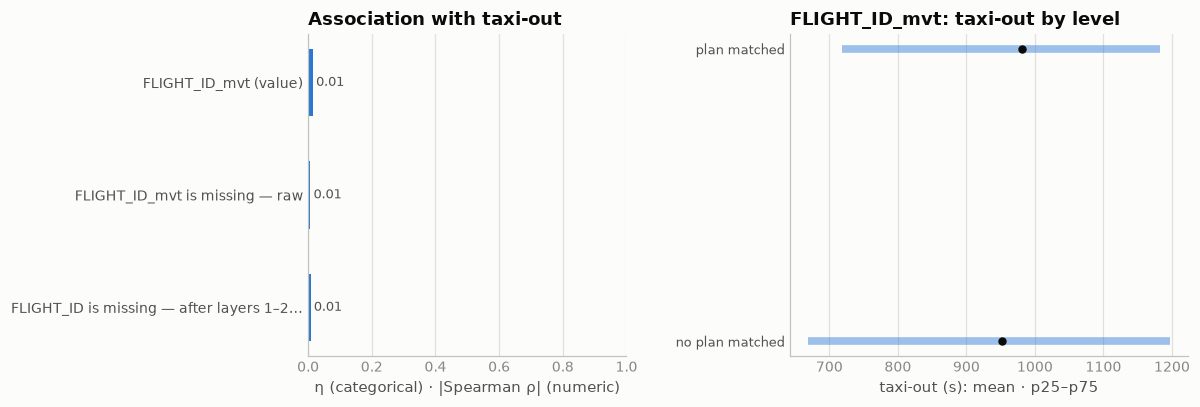

In [55]:
# correlation with the target: the value (a counter), and the is-missing flag before and after the twin layers
L12 = (f"(SELECT t.*, coalesce(t.FLIGHT_ID_mvt, l1.FLIGHT_ID_recovered, l2.FLIGHT_ID_recovered) fid_after "
       f"FROM {TGT} t "
       f"LEFT JOIN read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') l1 USING (MVT_ID_mvt) "
       f"LEFT JOIN read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet') l2 USING (MVT_ID_mvt))")
a = target_assoc([("FLIGHT_ID_mvt (value)", "num", "FLIGHT_ID_mvt"),
              ("FLIGHT_ID_mvt is missing — raw", "cat", "FLIGHT_ID_mvt IS NULL"),
              ("FLIGHT_ID is missing — after layers 1–2 (twin recoveries)", "cat", "fid_after IS NULL", 1, L12)])
assoc_chart(a, "CASE WHEN FLIGHT_ID_mvt IS NULL THEN 'no plan matched' ELSE 'plan matched' END", title="FLIGHT_ID_mvt")

**Findings**

| layer | training | ranking | what it restores |
|---|---:|---:|---|
| 1 · exact twin (2b) | 892 | 226 | full `_flt` block + `FLIGHT_ID` |
| 2 · relaxed twin (2c), stages A / B / C | 1,007 = 527 / 217 / 263 | 253 = 102 / 50 / 101 | full `_flt` block + `FLIGHT_ID` |
| 3 · history imputation (2c) | 19,157 | 4,539 | static fields only, operator at ≥ 95% validated accuracy |
| **still bare** | 1,368 | **265 — 0.08% of predictions** | |
| unmatched departures in total | 22,424 | 5,283 | |

Imputation targets were the 25,329 departures still missing after layers 1–2 (4,804 ranking):

| field | any value | at ≥ 95% validated accuracy | of which ranking |
|---|---:|---:|---:|
| `AIRCRAFT_OPERATOR_flt` | 23,696 | 23,696 | 4,539 |
| `WK_TBL_CAT_flt` | 24,229 | 24,229 | 4,622 |
| `AIRCRAFT_TYPE_flt` | 23,436 | 22,607 | 4,299 |
| `FLIGHT_TYPE_flt` | 22,745 | 19,658 | 3,780 |
| `MARKET_SEGMENT_flt` | 20,364 | 19,219 | 3,638 |

Rows with operator, wake and aircraft type all imputed, operator at ≥ 95%: 22,923 (4,419 ranking).

**After everything — what changed for the departures we model**

| `FLIGHT_ID_mvt` missing on departures | raw | after layer 1 | after layer 2 |
|---|---:|---:|---:|
| training (2,085,047) | 22,424 — 1.08% | 21,532 | 20,525 — 0.98% |
| ranking (344,841) | 5,283 — 1.53% | 5,057 | 4,804 — 1.39% |

| field, % of departures missing | training raw → after | ranking raw → after |
|---|---:|---:|
| `AOBT_3_flt` (layers 1–2 only) | 1.08 → 0.99 | 1.53 → 1.40 |
| `AIRCRAFT_OPERATOR_flt` | 1.08 → 0.07 | 1.53 → 0.08 |
| `WK_TBL_CAT_flt` | 1.08 → 0.05 | 1.54 → 0.06 |
| `AIRCRAFT_TYPE_flt` | 1.08 → 0.08 | 1.53 → 0.09 |
| `FLIGHT_TYPE_flt` | 1.08 → 0.11 | 1.53 → 0.12 |
| `MARKET_SEGMENT_flt` | 1.08 → 0.20 | 1.53 → 0.27 |

The ID itself, and with it the `AOBT_3` anchor, moves by a tenth of a point: twins exist only for
legs between two hubs. The static categoricals are what recovery really buys — from 1.5% missing
to under 0.3% on the rows we predict.

**How the pipeline should consume the three layers** — a row appears in at most one:

| priority | file | fields | join |
|---|---|---|---|
| 0 · raw `_flt` | the challenge files | | |
| 1 · exact twin | `data/derived/recovered_flt_blocks.parquet` | full block + `FLIGHT_ID` | `MVT_ID_mvt` |
| 2 · relaxed twin | `data/derived/recovered_flt_relaxed.parquet` | full block + `FLIGHT_ID` + `matcher_variant` | `MVT_ID_mvt` |
| 3 · history imputation | `data/derived/imputed_flt_static.parquet` | static fields, with per-field `_tier` / `_low_conf` | `MVT_ID_mvt` |

| rule | why |
|---|---|
| coalesce raw → 1 → 2 → 3 | strictest evidence first |
| treat twin-recovered rows like matched rows | they are real plan data; the `AOBT_3` implied-taxi anchor works |
| keep the "no flight plan" indicator TRUE on imputed rows | imputed values are estimates, and the flag carries the delay signal |
| ignore `FLIGHT_TYPE_flt` values flagged `_low_conf` | 78–80% validated accuracy |
| never expect timestamps from layer 3 | unrecoverable by construction |
| regenerate all three files by running this notebook top to bottom | derived, gitignored artifacts |

## 3 · `FLIGHT_mvt` — the flight number (sort of)

The docs describe it as *"what you see on your boarding pass"*. In practice the airport logged
whatever identifier the movement flew under, and that comes in flavors:

- **~78%** ICAO-callsign style — 3-letter airline code + digits (`ITY058`, `UAE81W`);
- **~21%** IATA marketing style — 2-character code + digits (`LH440`);
- **~1%** everything else, mostly **aircraft registrations** (`HBLVC`, `N77LD`, `CSDHX`) —
  business/general aviation with no commercial flight number flies under its tail number.

A flight number is an *identity*: the same number flies the same route at the same slot, day
after day. So the interesting stats are how many movements share one number, how it relates to
`CALLSIGN_flt`, whether 2026 still uses 2025's numbers — and whether the identity carries
taxi-time signal.

In [17]:
cat_stats("FLIGHT_mvt")

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,410,0.01,74532
ranking 2026,689534,97,0.01,35546


In [18]:
# the few rows with no number at all: matched flights that simply lack the field
print("rows with a null/empty FLIGHT_mvt:")
print(con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL) n_matched,
           count(*) FILTER (CALLSIGN_flt IS NOT NULL) has_callsign,
           count(*) FILTER (PHASE_mvt = 'DEP') dep,
           round(100.0*count(*) FILTER (hub = 'LIRF')/count(*)) pct_at_lirf
    FROM (SELECT *, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub
          FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R}))
    WHERE FLIGHT_mvt IS NULL OR trim(FLIGHT_mvt) = ''
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

FMT = """CASE
    WHEN FLIGHT_mvt IS NULL THEN 'null'
    WHEN regexp_matches(FLIGHT_mvt, '^[A-Z]{3}[0-9]') THEN 'ICAO style (XXX123)'
    WHEN regexp_matches(FLIGHT_mvt, '^[A-Z0-9]{2}[0-9]{1,4}[A-Z]?$') THEN 'IATA style (XX123)'
    ELSE 'registration / other' END"""

per_num = con.sql(f"""
    SELECT round(avg(c)) mean, quantile_cont(c, 0.5) med, quantile_cont(c, 0.9) p90, max(c) max,
           count(*) FILTER (c = 1) seen_once
    FROM (SELECT count(*) c FROM {T} WHERE FLIGHT_mvt IS NOT NULL GROUP BY FLIGHT_mvt)""").df()
top = con.sql(f"SELECT FLIGHT_mvt, count(*) n FROM {T} GROUP BY 1 ORDER BY n DESC LIMIT 5").df()
cs = con.sql(f"""
    SELECT round(100.0*count(*) FILTER (FLIGHT_mvt = CALLSIGN_flt)/count(*), 1)
    FROM {T} WHERE FLIGHT_mvt IS NOT NULL AND CALLSIGN_flt IS NOT NULL""").fetchone()[0]
cov = con.sql(f"""
    SELECT round(100.0*count(*) FILTER (FLIGHT_mvt IN
               (SELECT FLIGHT_mvt FROM {T} WHERE FLIGHT_mvt IS NOT NULL))/count(*), 1),
           count(*) FILTER (FLIGHT_mvt NOT IN
               (SELECT FLIGHT_mvt FROM {T} WHERE FLIGHT_mvt IS NOT NULL)),
           count(DISTINCT FLIGHT_mvt) FILTER (FLIGHT_mvt NOT IN
               (SELECT FLIGHT_mvt FROM {T} WHERE FLIGHT_mvt IS NOT NULL))
    FROM {R} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL""").fetchone()

print("\nmovements per flight number (training):")
print(per_num.to_string(index=False))
print("\nbusiest numbers (≈ twice daily, year round):")
print(top.to_string(index=False))
print(f"\nFLIGHT_mvt == CALLSIGN_flt (where both present):  {cs}%")
print(f"ranking DEP rows whose number was seen in 2025:  {cov[0]}%  "
      f"({cov[1]:,} rows carry one of {cov[2]:,} new numbers)")

# signal check, honest: per-number means fitted on Jan–Oct (support ≥ 20), scored on Nov+Dec;
# a number without history falls back to the airport mean, itself fitted on Jan–Oct
print("\ndoes the number beat the airport? fit Jan–Oct 2025, score Nov+Dec (1–3600 s):")
print(con.sql(f"""
    WITH d AS (SELECT FLIGHT_mvt f, ADEP_mvt ap, TAXITIME_SEC_mvt::DOUBLE y,
                      month(MVT_TIME_UTC_mvt) <= 10 fit
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
                 AND FLIGHT_mvt IS NOT NULL),
         apm AS (SELECT ap, avg(y) m FROM d WHERE fit GROUP BY 1),
         fm AS (SELECT f, avg(y) m FROM d WHERE fit GROUP BY 1 HAVING count(*) >= 20)
    SELECT count(*) n_val,
           round(100.0*count(*) FILTER (fm.m IS NOT NULL)/count(*), 1) pct_with_history,
           round(sqrt(avg((y - apm.m)^2)), 1) rmse_airport_mean,
           round(sqrt(avg((y - coalesce(fm.m, apm.m))^2)), 1) rmse_number_mean_w_fallback,
           round(sqrt(avg((y - apm.m)^2) FILTER (fm.m IS NOT NULL)), 1) rmse_airport_covered_rows,
           round(sqrt(avg((y - fm.m)^2) FILTER (fm.m IS NOT NULL)), 1) rmse_number_covered_rows
    FROM d JOIN apm USING (ap) LEFT JOIN fm USING (f) WHERE NOT fit""").df().to_string(index=False))

rows with a null/empty FLIGHT_mvt:
     src   n  n_matched  has_callsign  dep  pct_at_lirf
training 410        309           309  188        100.0
 ranking  97         66            65   58        100.0



movements per flight number (training):
 mean  med   p90  max  seen_once
 56.0  4.0 208.9  730      24555

busiest numbers (≈ twice daily, year round):
FLIGHT_mvt   n
    UAE81W 730
    ITY058 728
    UAE256 727
     SQ026 727
    ITY316 727

FLIGHT_mvt == CALLSIGN_flt (where both present):  72.8%
ranking DEP rows whose number was seen in 2025:  80.7%  (66,616 rows carry one of 6,756 new numbers)

does the number beat the airport? fit Jan–Oct 2025, score Nov+Dec (1–3600 s):
 n_val  pct_with_history  rmse_airport_mean  rmse_number_mean_w_fallback  rmse_airport_covered_rows  rmse_number_covered_rows
327455              63.4              357.3                        337.6                      360.3                     328.9


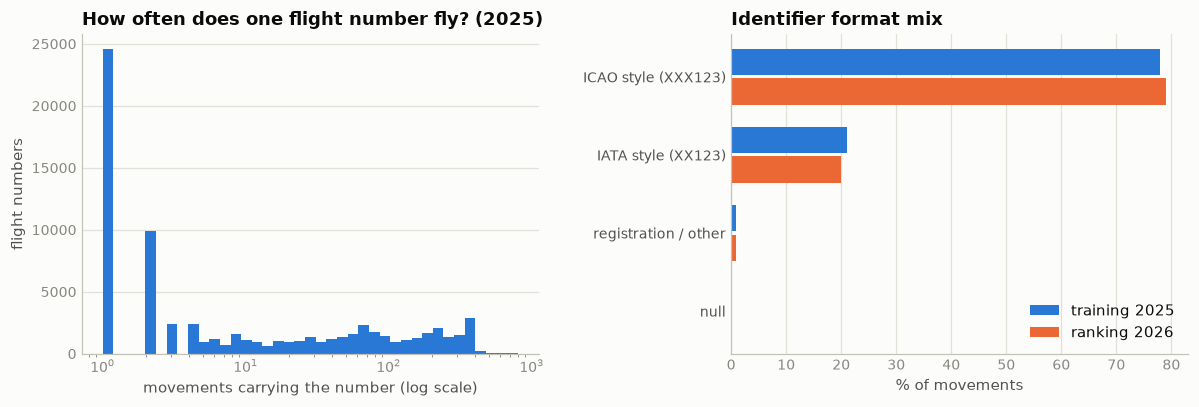

In [19]:
cnts = con.sql(f"""
    SELECT count(*) c FROM {T} WHERE FLIGHT_mvt IS NOT NULL GROUP BY FLIGHT_mvt""").df().c
fmt_mix = con.sql(f"""
    WITH t AS (SELECT {FMT} f, 100.0*count(*)/sum(count(*)) OVER () pct FROM {T} GROUP BY 1),
         r AS (SELECT {FMT} f, 100.0*count(*)/sum(count(*)) OVER () pct FROM {R} GROUP BY 1)
    SELECT coalesce(t.f, r.f) fmt, coalesce(t.pct, 0) pct_t, coalesce(r.pct, 0) pct_r
    FROM t FULL JOIN r USING (f) ORDER BY pct_t""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.logspace(0, np.log10(800), 40)
a1.hist(cnts, bins=bins, color=BLUE)
a1.set_xscale("log")
a1.set_title("How often does one flight number fly? (2025)")
a1.set_xlabel("movements carrying the number (log scale)")
a1.set_ylabel("flight numbers")
style(a1)

y = np.arange(len(fmt_mix))
a2.barh(y + 0.19, fmt_mix.pct_t, height=0.34, color=BLUE, label="training 2025")
a2.barh(y - 0.19, fmt_mix.pct_r, height=0.34, color=ORANGE, label="ranking 2026")
a2.set_yticks(y, fmt_mix.fmt, color=INK2)
a2.set_title("Identifier format mix")
a2.set_xlabel("% of movements")
a2.legend(loc="lower right")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

                                                  feature        kind  n / levels  pearson_r  spearman_ρ     η
FLIGHT_mvt — levels with ≥ 20 departures, the rest pooled categorical       14237                        0.608
         format class — ICAO / IATA / registration / null categorical           4                        0.215
                               flies under a registration categorical           2                        0.057


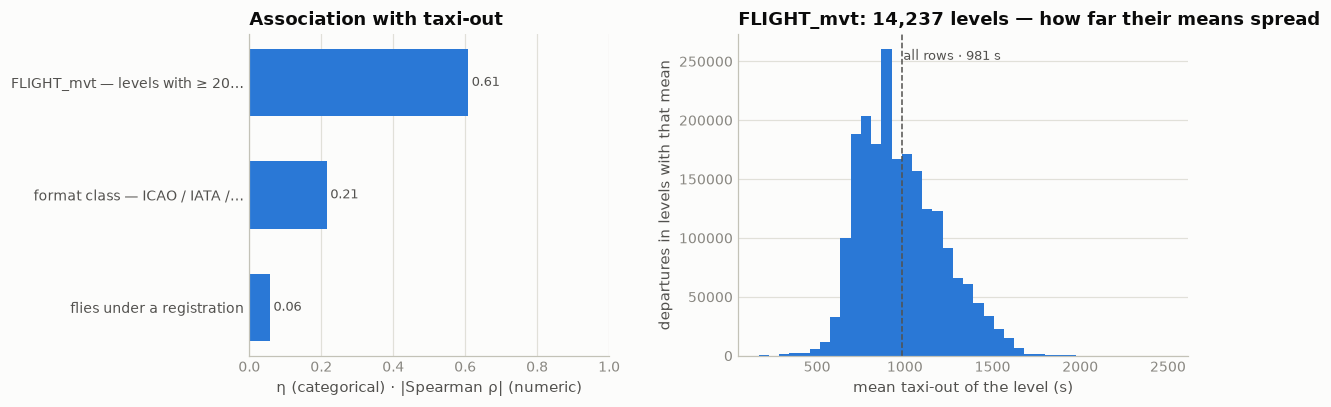

In [54]:
# correlation with the target: the number itself (frequent levels only), its format, and the registration flag
a = target_assoc([("FLIGHT_mvt — levels with ≥ 20 departures, the rest pooled", "cat", "FLIGHT_mvt", 20),
              ("format class — ICAO / IATA / registration / null", "cat", FMT),
              ("flies under a registration", "cat", f"({FMT}) = 'registration / other'")])
assoc_chart(a, "FLIGHT_mvt", min_support=20, title="FLIGHT_mvt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| Practically never null — and the gap is Rome's | 410 training rows and 97 ranking rows (0.01%), **all at LIRF**; 309 and 66 of them are matched and carry a `CALLSIGN_flt` | the callsign fills the hole when the number is missing; nothing to recover |
| A heavy-tailed identity | 74,532 distinct numbers in 2025; the median number flies **4×** a year, 24,555 fly once, the busiest (`UAE81W`, `ITY058`, `SQ026`) ~730× | any encoding must cope with numbers seen a handful of times |
| Near-duplicate of `CALLSIGN_flt` | equal on 72.8% of matched rows; the rest is IATA-vs-ICAO spelling (`LH440` vs `DLH440`) | one identity in two spellings — the IATA→ICAO map of §2c is learned from exactly these pairs |
| Format mix is stable | ~78% ICAO style, ~21% IATA style, ~1% registrations, the same in 2026 | no drift; the registration slice is the GA/bizav marker |
| Schedule churn | 80.7% of ranking departures reuse a 2025 number; **66,616 rows (19.3%) carry one of 6,756 new numbers** | a raw category would be blind on a fifth of the predictions |
| The identity carries signal — honestly measured | per-number means fitted on Jan–Oct, scored on Nov+Dec: airport mean **357.3 s → 337.6 s** with fallback; on the 63.4% of rows whose number has ≥ 20 prior flights, 360.3 → 328.9 s | a number bundles airline, route, slot and terminal in one token. (The in-sample version of this check said 344 → 301 s — flattering; this is the number to trust) |

**Use in modeling.** Not as a raw high-cardinality category. Use smoothed target and frequency
encodings with fallback to coarser identities — operator, route, airport — and a "flies under a
registration" flag. Two roles it already plays elsewhere: its **prefix is an operator token**
when the plan block is missing (§2b), and it is the **key for history imputation** (§2c).

## 4 · `FLIGHT_RULE_mvt` — flight rules: instrument or visual

The docs promise three values — `I` = IFR, `V` = VFR, `NA` = unknown — but the file uses a real
NULL where the docs say `NA`. At ten major hubs essentially everything flies IFR, so this is less
a category than a **rare-event flag**: who on earth flies *visually* out of Schiphol, and does
that change how long they taxi?

| step | question | what came out |
|---|---|---|
| **4 · the flag** | how rare are `V` and NULL, is the mix stable into 2026, how does the rule relate to §2's match and to its `FLIGHT_RULE_flt` sibling, does it carry taxi signal? | 0.15% `V`, every one unmatched; the plan side adds the mixed-rule codes `Y`/`Z`; VFR is two hubs' special-mission fleets, taxiing in their own way |
| **4a · the 689 rows with no rule** | noise or structure — and can the rule be recovered? | three stories, none random; recovered from the plan, a history vote, or the airframe |
| **final form** | one rule for every movement | precedence *recovered null → `V` from the movement → `Y`/`Z` from any plan → `I`*; 100% coverage, before → after at the end |

In [21]:
display(cat_stats("FLIGHT_RULE_mvt"))

con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅ null') "rule",
           count(*) FILTER (src = 't' AND PHASE_mvt = 'DEP') t_dep,
           count(*) FILTER (src = 't' AND PHASE_mvt = 'ARR') t_arr,
           count(*) FILTER (src = 'r' AND PHASE_mvt = 'DEP') r_dep,
           count(*) FILTER (src = 'r' AND PHASE_mvt = 'ARR') r_arr,
           round(100.0 * count(*) FILTER (src = 't')
                 / sum(count(*) FILTER (src = 't')) OVER (), 3) pct_train,
           round(100.0 * count(*) FILTER (src = 'r')
                 / sum(count(*) FILTER (src = 'r')) OVER (), 3) pct_rank
    FROM (SELECT 't' src, PHASE_mvt, FLIGHT_RULE_mvt FROM {T}
          UNION ALL SELECT 'r', PHASE_mvt, FLIGHT_RULE_mvt FROM {R})
    GROUP BY 1 ORDER BY t_dep DESC""").df()

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,689,0.02,2
ranking 2026,689534,84,0.01,2


,rule,t_dep,t_arr,r_dep,r_arr,pct_train,pct_rank
0,I,2081914,2079115,344402,344150,99.838,99.858
1,V,2930,3149,419,479,0.146,0.130
2,∅ null,203,486,20,64,0.017,0.012


In [22]:
# how the rule interacts with the flight-plan match of §2
print("share of movements without a flight-plan match, by rule:")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅') "rule", count(*) n,
           round(100.0 * count(*) FILTER (FLIGHT_ID_mvt IS NULL) / count(*), 1) pct_unmatched
    FROM {T} GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nmatched rows — FLIGHT_RULE_mvt vs FLIGHT_RULE_flt:")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅') mvt, coalesce(FLIGHT_RULE_flt, '∅') flt, count(*) n
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1, 2 ORDER BY n DESC""").df().to_string(index=False))

print("\nmedian DEP taxi by FLIGHT_RULE_flt (matched, 1–3600 s):")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_flt, '∅') flt, count(*) n,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

share of movements without a flight-plan match, by rule:
rule       n  pct_unmatched
   I 4161029            0.6
   V    6079          100.0
   ∅     689           14.9

matched rows — FLIGHT_RULE_mvt vs FLIGHT_RULE_flt:
mvt flt       n
  I   I 4126828
  I   ∅    7129
  I   Y    1425
  I   Z     895
  ∅   I     432
  ∅   Y      79
  ∅   Z      74
  I   V       4
  ∅   ∅       1

median DEP taxi by FLIGHT_RULE_flt (matched, 1–3600 s):
flt       n  med_taxi
  I 2057904     911.0
  Y    1414     654.0
  ∅     120     661.5
  Z       5     563.0
  V       4     412.5


top VFR departure identities (ICAO-style callsigns, training):
pfx  typ   ap   n
ZXP A139 EHAM 845
NCG DH8A EHAM 544
ICC C208 LEBL 134
FCK B350 EDDF  15
RGA A109 LSZH   8
BPO AS32 EDDM   6


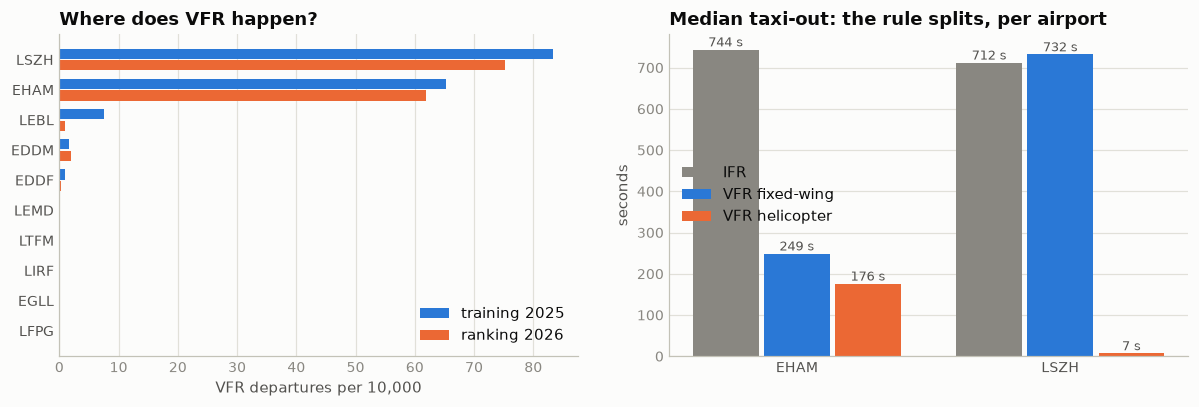

VFR departures, Nov+Dec holdout (1–3600 s):
 n_vfr_val  rmse_airport_mean  rmse_airport_x_vfr_x_heli
       343              559.9                      278.1


In [23]:
# who flies VFR at a top-10 hub, and how do they taxi?
VFR_ID = "regexp_matches(FLIGHT_mvt, '^[A-Z]{3}[0-9]')"
HELI = ("('A139','A109','A169','A189','AS32','AS50','B06','B407','B429','B505',"
        "'EC20','EC35','EC45','EC55','H145','H160','R44','S76')")

print("top VFR departure identities (ICAO-style callsigns, training):")
print(con.sql(f"""
    SELECT substr(FLIGHT_mvt, 1, 3) pfx, mode(AIRCRAFT_TYPE_mvt) typ, mode(ADEP_mvt) ap, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'V' AND {VFR_ID}
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

vfr_rate = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, 1e4 * count(*) FILTER (FLIGHT_RULE_mvt = 'V') / count(*) r
               FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, 1e4 * count(*) FILTER (FLIGHT_RULE_mvt = 'V') / count(*) r
               FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, t.r rate_t, r.r rate_r FROM t JOIN r USING (ap) ORDER BY rate_t""").df()

med = con.sql(f"""
    SELECT ADEP_mvt ap,
           CASE WHEN FLIGHT_RULE_mvt = 'I' THEN 'IFR'
                WHEN AIRCRAFT_TYPE_mvt IN {HELI} THEN 'VFR helicopter'
                ELSE 'VFR fixed-wing' END grp,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt IN ('EHAM', 'LSZH')
      AND FLIGHT_RULE_mvt IS NOT NULL AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1, 2""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(vfr_rate))
a1.barh(y + 0.19, vfr_rate.rate_t, height=0.34, color=BLUE, label="training 2025")
a1.barh(y - 0.19, vfr_rate.rate_r, height=0.34, color=ORANGE, label="ranking 2026")
a1.set_yticks(y, vfr_rate.ap, color=INK2)
a1.set_title("Where does VFR happen?")
a1.set_xlabel("VFR departures per 10,000")
a1.legend(loc="lower right")
style(a1, x_grid=True, y_grid=False)

d = med.set_index(["ap", "grp"]).med
x = np.arange(2)
for i, (g, c) in enumerate([("IFR", MUTED), ("VFR fixed-wing", BLUE), ("VFR helicopter", ORANGE)]):
    bars = a2.bar(x + (i - 1) * 0.27, [d.get(("EHAM", g)), d.get(("LSZH", g))],
                  width=0.25, color=c, label=g)
    a2.bar_label(bars, fmt="%.0f s", fontsize=8.5, color=INK2)
a2.set_xticks(x, ["EHAM", "LSZH"], color=INK2)
a2.set_title("Median taxi-out: the rule splits, per airport")
a2.set_ylabel("seconds")
a2.legend()
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

# signal check on the rows the flag touches — honest: means fitted on Jan–Oct, scored on Nov+Dec
print("VFR departures, Nov+Dec holdout (1–3600 s):")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt ap, FLIGHT_RULE_mvt fr,
                      CASE WHEN AIRCRAFT_TYPE_mvt IN {HELI} THEN 'h' ELSE 'f' END k,
                      TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) <= 10 fit
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         apm AS (SELECT ap, avg(y) m FROM d WHERE fit GROUP BY 1),
         grp AS (SELECT ap, k, avg(y) m FROM d WHERE fit AND fr = 'V' GROUP BY 1, 2)
    SELECT count(*) n_vfr_val, round(sqrt(avg((y - apm.m)^2)), 1) rmse_airport_mean,
           round(sqrt(avg((y - coalesce(grp.m, apm.m))^2)), 1) rmse_airport_x_vfr_x_heli
    FROM d JOIN apm USING (ap) LEFT JOIN grp USING (ap, k) WHERE NOT fit AND fr = 'V'""").df().to_string(index=False))

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| Practically constant | **99.85% `I`**, 0.14% `V` (6,079 movements in 2025), 689 true NULLs — the docs' `NA` never appears as a string. Same mix in ranking; 419 of the 344,841 predictions are VFR | a rare-event flag, not a category |
| **`V` ⇒ unmatched, without exception** | all 6,079 VFR movements have no `FLIGHT_ID_mvt` and a fully NULL `_flt` block | NM plans are an IFR affair. This is §2's *excused* slice: §2b/2c chased unmatched IFR only, so for VFR rows the `_flt` features are structurally missing and the "no flight plan" indicator stays TRUE |
| The plan side is finer, not different | matched rows agree; 2,320 movements are `Y`/`Z` (rule change en route) that `_mvt` flattens to `I`, and they taxi shorter — median 654 s vs 911 s for pure-IFR departures | keep `Y`/`Z` distinct |
| The nulls are mostly matched rows | 85% of the 689 carry a plan; 79 of the 203 DEP nulls are `Y` | the airport system chokes on mixed-rule plans — 4a |
| VFR at a top-10 hub = special-mission fleets at two airports | EHAM 65/10k (`ZXP` AW139 helicopters, `NCG` coastguard Dash-8s), LSZH 83/10k (HB-registered light singles, `RGA` Rega helicopters); a sprinkle at LEBL (`ICC` Cessna Caravans), EDDM, EDDF; **zero** at LTFM, LFPG, EGLL, LIRF. The same fleets show up in 2026 | the flag only means something together with the airport |
| A big lever on its own rows, in opposite directions per airport | EHAM medians: helicopter 176 s, fixed-wing 249 s, IFR 744 s. LSZH: fixed-wing VFR 732 s like an airliner, helicopters **7 s** (Rega departs from its own base). Honest holdout on the 343 Nov+Dec VFR departures: airport mean 560 s → airport × VFR × helicopter mean **278 s** | an IFR-trained model predicts a 12-minute taxi for a helipad departure |

**Use in modeling.** Feed the model `coalesce(FLIGHT_RULE_mvt, FLIGHT_RULE_flt)` (keeping
`Y`/`Z` distinct) plus an is-helicopter flag from `AIRCRAFT_TYPE_mvt`, and let them interact
with airport. Only ~0.12% of ranking rows are VFR, so the total-RMSE gain is well under 1 s —
but it is free, and these are exactly the rows where the model would otherwise embarrass itself.

### 4a · The 689 rows with no rule

689 training rows and 84 ranking rows (20 of them predictions) carry no `FLIGHT_RULE_mvt`.
Three questions: are they random (a logging hiccup) or a particular kind of traffic; can the
rule be recovered — from the matched plan, from the identity's history, or from the airframe;
and should the pipeline care?

In [24]:
NLL = f"(SELECT *, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub FROM {T} WHERE FLIGHT_RULE_mvt IS NULL)"

print("null-rule rows by hub × phase × what the matched plan says:")
print(con.sql(f"""
    SELECT hub, PHASE_mvt ph, coalesce(FLIGHT_RULE_flt, '(unmatched)') flt, count(*) n
    FROM {NLL} GROUP BY 1, 2, 3 ORDER BY hub, ph, n DESC""").df().to_string(index=False))

print("\nwho loses the flag? market segment, null rows vs the whole file:")
print(con.sql(f"""
    WITH a AS (SELECT MARKET_SEGMENT_flt seg, count(*) n FROM {NLL} GROUP BY 1),
         b AS (SELECT MARKET_SEGMENT_flt seg, count(*) n FROM {T} GROUP BY 1)
    SELECT coalesce(a.seg, '(unmatched)') seg, a.n,
           round(100.0 * a.n / sum(a.n) OVER (), 1) pct_of_nulls,
           round(100.0 * b.n / sum(b.n) OVER (), 1) pct_of_all
    FROM a JOIN b ON a.seg IS NOT DISTINCT FROM b.seg ORDER BY a.n DESC""").df().to_string(index=False))

print("\nnull count by date — one date dominates:")
print(con.sql(f"""
    SELECT MVT_TIME_UTC_mvt::DATE d, count(*) n, mode(hub) hub FROM {NLL}
    GROUP BY 1 ORDER BY n DESC LIMIT 4""").df().to_string(index=False))

print("\nEHAM on 20 July 2025, hour by hour — the flag drops for part of the afternoon:")
print(con.sql(f"""
    SELECT hour(MVT_TIME_UTC_mvt) h, count(*) mvts,
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL) n_null
    FROM {T}
    WHERE (CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) = 'EHAM'
      AND MVT_TIME_UTC_mvt::DATE = DATE '2025-07-20'
    GROUP BY 1 ORDER BY 1""").df().set_index("h").T.to_string())

# the unmatched nulls, and how far history can carry the rest
print("unmatched null-rule rows — top airframes and the identities they fly under:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n,
           substr(string_agg(DISTINCT FLIGHT_mvt, ', '), 1, 48) ids
    FROM {NLL} WHERE FLIGHT_ID_mvt IS NULL GROUP BY 1 ORDER BY n DESC LIMIT 8""").df().to_string(index=False))

print("\nrecovery accounting (training):")
print(con.sql(f"""
    WITH hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM {T}
                  WHERE FLIGHT_RULE_mvt IS NOT NULL AND FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
         vote AS (SELECT FLIGHT_mvt, arg_max(r, c) r FROM hist GROUP BY 1)
    SELECT CASE
        WHEN FLIGHT_RULE_flt = 'I' THEN '1 · plan says I'
        WHEN FLIGHT_RULE_flt = 'Y' AND PHASE_mvt = 'DEP' THEN '2 · Y dep (IFR at the hub)'
        WHEN FLIGHT_RULE_flt = 'Z' AND PHASE_mvt = 'ARR' THEN '2 · Z arr (IFR at the hub)'
        WHEN v.r IS NOT NULL THEN '3 · history vote → ' || v.r
        ELSE '4 · unknown' END bucket, count(*) n
    FROM {NLL} LEFT JOIN vote v USING (FLIGHT_mvt) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nhow unanimous are the history votes?")
print(con.sql(f"""
    WITH ids AS (SELECT DISTINCT FLIGHT_mvt FROM {NLL}
                 WHERE FLIGHT_RULE_flt IS NULL AND FLIGHT_mvt IS NOT NULL),
         hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM {T}
                  WHERE FLIGHT_RULE_mvt IS NOT NULL AND FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
         agg AS (SELECT FLIGHT_mvt, arg_max(r, c) r, sum(c) tot, max(c) top FROM hist GROUP BY 1)
    SELECT r vote, count(*) identities, round(avg(100.0 * top / tot), 1) avg_purity_pct,
           min(tot) min_history, max(tot) max_history
    FROM ids JOIN agg USING (FLIGHT_mvt) GROUP BY 1""").df().to_string(index=False))

null-rule rows by hub × phase × what the matched plan says:
 hub  ph         flt   n
EDDF ARR           Z  72
EDDF ARR           I  24
EDDF ARR (unmatched)  20
EDDF DEP           Y  79
EDDF DEP (unmatched)  15
EDDF DEP           I   3
EDDM ARR           I  70
EDDM ARR (unmatched)   2
EDDM DEP           I   4
EHAM ARR           I 254
EHAM ARR (unmatched)  42
EHAM ARR           Z   2
EHAM DEP           I  77
EHAM DEP (unmatched)  25

who loses the flag? market segment, null rows vs the whole file:
          seg   n  pct_of_nulls  pct_of_all
     Business 260          37.7         2.1
     Mainline 166          24.1        63.6
  (unmatched) 104          15.1         0.9
     Regional  80          11.6        10.2
      Lowcost  40           5.8        19.2
Non-Scheduled  12           1.7         0.7
        Cargo  11           1.6         2.9
        Other  10           1.5         0.4
     Military   6           0.9         0.0

null count by date — one date dominates:
         d   n  h

h       0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
mvts     8   2   1  15  31  84  90  78  94  88  80  96  76  92  81  81  86  73  75  83  83  38  15  10
n_null   0   0   0   0   0   0   0   0   1   7   7  29  27  35  24  15  14  14   8   3   1   0   0   0
unmatched null-rule rows — top airframes and the identities they fly under:
 typ  n                                              ids
EH10 13              ZJ995, ZK001, ZJ995A, ZJ119, ZK001A
PC12 11 YY98872, YY98542, YY98242, JFA047Z, YY98352, YY9
A139 11 ZXP25B, ZXP25Z, ZXP24B, ZXP26B, ZXP24A, NCG04A, 
LYNX  7                   AAC105, AAC103, AAC102, AAC101
PC24  6 FYL023V, FYL024V, FYL081G, FYL021G, DCOIN1, DCJM
 S61  6                                     NH60A, NH60B
AS32  5                              S441A, S449A, S455A
PRM1  4               YY98262, YY98162, YY98306, YY98961

recovery accounting (training):
                    bucket   n
           1 · plan says I 432
2 · Y d

In [25]:
# recover every null (training + ranking) with provenance -> data/derived/rule_recovered.parquet
# §4's HELI list + the military/SAR rotorcraft seen above (types the excused VFR fleet never uses)
HELI_ALL = HELI[:-1] + ",'EH10','LYNX','S61','S92','H47','NH90','PUMA')"

rec = con.sql(f"""
    WITH pool AS (
        SELECT MVT_ID_mvt, 'training' dataset, PHASE_mvt, FLIGHT_mvt, FLIGHT_RULE_flt,
               AIRCRAFT_TYPE_mvt FROM {T} WHERE FLIGHT_RULE_mvt IS NULL
        UNION ALL
        SELECT MVT_ID_mvt, 'ranking', PHASE_mvt, FLIGHT_mvt, FLIGHT_RULE_flt,
               AIRCRAFT_TYPE_mvt FROM {R} WHERE FLIGHT_RULE_mvt IS NULL),
    hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM
                 (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt FROM {T} WHERE FLIGHT_RULE_mvt IS NOT NULL
                  UNION ALL
                  SELECT FLIGHT_mvt, FLIGHT_RULE_mvt FROM {R} WHERE FLIGHT_RULE_mvt IS NOT NULL)
             WHERE FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
    vote AS (SELECT FLIGHT_mvt, arg_max(r, c) r FROM hist GROUP BY 1)
    SELECT MVT_ID_mvt, dataset,
           CASE WHEN FLIGHT_RULE_flt IS NOT NULL THEN FLIGHT_RULE_flt
                WHEN v.r IS NOT NULL THEN v.r
                WHEN AIRCRAFT_TYPE_mvt IN {HELI_ALL} THEN 'V' ELSE 'I' END rule_rec,
           CASE WHEN FLIGHT_RULE_flt IS NOT NULL THEN 'flt'
                WHEN v.r IS NOT NULL THEN 'history_vote'
                ELSE 'type_guess' END rule_src
    FROM pool LEFT JOIN vote v USING (FLIGHT_mvt)""").df()

out = ROOT / "data/derived/rule_recovered.parquet"
rec.to_parquet(out, index=False)
print(f"wrote {len(rec):,} rows → {out.relative_to(ROOT)}")
print(rec.groupby(["dataset", "rule_src"]).rule_rec.value_counts().unstack(fill_value=0))

wrote 773 rows → data/derived/rule_recovered.parquet
rule_rec                 I   V   Y   Z
dataset  rule_src                     
ranking  flt            47   0   8   6
         history_vote   11   3   0   0
         type_guess      9   0   0   0
training flt           432   0  79  74
         history_vote   38  25   0   0
         type_guess     17  24   0   0


In [26]:
# ---- final accounting: one rule for every movement ----
REC = f"read_parquet('{ROOT}/data/derived/rule_recovered.parquet')"
TWIN = (f"(SELECT MVT_ID_mvt, FLIGHT_RULE_flt frw FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
        f" UNION ALL SELECT MVT_ID_mvt, FLIGHT_RULE_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")

# precedence: recovered nulls (4a) · mvt's V (the hub-leg fact) · Y/Z from any plan source
# (refines a flat I) · mvt's I. The twin layers' six Y/Z rows sit on mvt-V movements, so V wins.
FINAL = f"""
    SELECT t.*, CASE
             WHEN t.FLIGHT_RULE_mvt IS NULL THEN rec.rule_rec
             WHEN t.FLIGHT_RULE_mvt = 'V' THEN 'V'
             WHEN coalesce(t.FLIGHT_RULE_flt, w.frw) IN ('Y', 'Z') THEN coalesce(t.FLIGHT_RULE_flt, w.frw)
             ELSE t.FLIGHT_RULE_mvt END rule_final,
           CASE
             WHEN t.FLIGHT_RULE_mvt IS NULL THEN 'was null · ' || rec.rule_src
             WHEN t.FLIGHT_RULE_mvt = 'V' THEN 'mvt says V'
             WHEN coalesce(t.FLIGHT_RULE_flt, w.frw) IN ('Y', 'Z') THEN 'flt Y/Z refines a flat I'
             ELSE 'mvt says I' END prov
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R}) t
    LEFT JOIN {TWIN} w USING (MVT_ID_mvt)
    LEFT JOIN {REC} rec USING (MVT_ID_mvt)"""

left_over = con.sql(f"WITH f AS ({FINAL}) SELECT count(*) FROM f WHERE rule_final IS NULL").fetchone()[0]
print(f"rows still without a rule: {left_over}")
assert left_over == 0

print("\nbefore -> after, by file × phase:")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT ds, PHASE_mvt ph, count(*) n,
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL) null_raw, count(*) FILTER (rule_final IS NULL) null_after,
           count(*) FILTER (FLIGHT_RULE_mvt = 'I') i_raw, count(*) FILTER (rule_final = 'I') i_after,
           count(*) FILTER (FLIGHT_RULE_mvt = 'V') v_raw, count(*) FILTER (rule_final = 'V') v_after,
           count(*) FILTER (rule_final = 'Y') y_after, count(*) FILTER (rule_final = 'Z') z_after
    FROM f GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nwhere every movement's rule now comes from:")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT prov, count(*) FILTER (ds = 'training') training, count(*) FILTER (ds = 'ranking') ranking
    FROM f GROUP BY 1 ORDER BY training DESC""").df().to_string(index=False))

print("\ntaxi time by final rule (training, 1–3600 s):")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT PHASE_mvt ph, rule_final, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean,
           quantile_cont(TAXITIME_SEC_mvt, 0.25) p25, quantile_cont(TAXITIME_SEC_mvt, 0.5) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.75) p75
    FROM f WHERE ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1, 2 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

# worth, honest: airport means and airport × rule means fitted on Jan–Oct, scored on Nov+Dec
print("\nairport mean vs airport × rule, Nov+Dec holdout (support ≥ 30, else the airport mean):")
print(con.sql(f"""WITH f AS ({FINAL}),
    d AS (SELECT ADEP_mvt ap, rule_final rf, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) <= 10 fit
          FROM f WHERE ds = 'training' AND PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
    apm AS (SELECT ap, avg(y) m FROM d WHERE fit GROUP BY 1),
    grm AS (SELECT ap, rf, avg(y) m, count(*) c FROM d WHERE fit GROUP BY 1, 2)
    SELECT count(*) n_val, round(sqrt(avg((y - apm.m)^2)), 2) rmse_airport,
           round(sqrt(avg((y - coalesce(CASE WHEN grm.c >= 30 THEN grm.m END, apm.m))^2)), 2) rmse_airport_x_rule,
           count(*) FILTER (rf != 'I') n_non_i,
           round(sqrt(avg((y - apm.m)^2) FILTER (rf != 'I')), 1) rmse_airport_non_i,
           round(sqrt(avg((y - coalesce(CASE WHEN grm.c >= 30 THEN grm.m END, apm.m))^2) FILTER (rf != 'I')), 1) rmse_rule_non_i
    FROM d JOIN apm USING (ap) LEFT JOIN grm USING (ap, rf) WHERE NOT fit""").df().to_string(index=False))

rows still without a rule: 0

before -> after, by file × phase:


      ds  ph       n  null_raw  null_after   i_raw  i_after  v_raw  v_after  y_after  z_after
training ARR 2082750       486           0 2079115  2078521   3149     3180       85      964
training DEP 2085047       203           0 2081914  2080675   2930     2948     1419        5
 ranking ARR  344693        64           0  344150   343996    479      482       17      198
 ranking DEP  344841        20           0  344402   344172    419      419      247        3

where every movement's rule now comes from:
                    prov  training  ranking
              mvt says I   4158709   688101
              mvt says V      6079      898
flt Y/Z refines a flat I      2320      451
          was null · flt       585       61
 was null · history_vote        63       14
   was null · type_guess        41        9

taxi time by final rule (training, 1–3600 s):


 ph rule_final       n  mean   p25   med     p75
DEP          I 2076404 982.0 720.0 911.0 1185.00
DEP          V    2710 381.0 124.0 244.5  577.50
DEP          Y    1414 746.0 411.0 654.0 1041.00
DEP          Z       5 500.0 424.0 563.0  575.00
ARR          I 2078021 536.0 324.0 481.0  665.00
ARR          V    3004 268.0 125.0 213.0  316.25
ARR          Z     963 421.0 299.0 381.0  496.00
ARR          Y      85 474.0 260.0 438.0  569.00

airport mean vs airport × rule, Nov+Dec holdout (support ≥ 30, else the airport mean):


 n_val  rmse_airport  rmse_airport_x_rule  n_non_i  rmse_airport_non_i  rmse_rule_non_i
327485        357.33               356.97      598               505.2            338.4


                            feature        kind  n / levels  pearson_r  spearman_ρ     η
FLIGHT_RULE_mvt — raw, ∅ as a level categorical           3                        0.056
         rule_final — I / V / Y / Z categorical           4                        0.058
is helicopter — the rotorcraft list categorical           3                        0.050


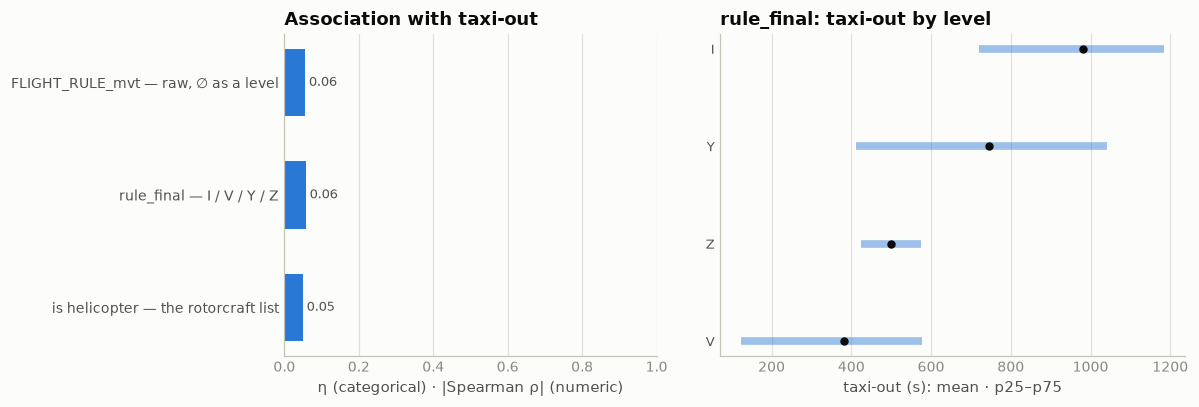

In [53]:
# correlation with the target: the raw rule (∅ as its own level), the final rule, and the helicopter flag
FIN_T = f"(SELECT * FROM ({FINAL}) WHERE ds = 'training' AND PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)"
a = target_assoc([("FLIGHT_RULE_mvt — raw, ∅ as a level", "cat", "FLIGHT_RULE_mvt"),
              ("rule_final — I / V / Y / Z", "cat", "rule_final", 1, FIN_T),
              ("is helicopter — the rotorcraft list", "cat", f"AIRCRAFT_TYPE_mvt IN {HELI_ALL}")])
assoc_chart(a, "rule_final", src=FIN_T, title="rule_final")

**Findings**

The 689 nulls are three different stories, none of them random:

| story | evidence | reading |
|---|---|---|
| **One afternoon at Schiphol** | 185 rows (27%) are EHAM on **20 July 2025**, ~09:00–19:00 UTC, up to ~40% of movements in the worst hour; the plan says `I` for nearly all of them | the flag silently dropped off part of the stream while everything else logged normally — ordinary IFR traffic. EDDM's little pile is the same disease: 44 of its 76 nulls fall on one September day |
| **Frankfurt's allergy to mixed-rule plans** | EDDF contributes 3 plain-IFR departure nulls; its nulls *are* the `Y` departures (79) and `Z` arrivals (72) | other airports flatten `Y`/`Z` to `I`; EDDF writes nothing. Both legs at the hub are technically IFR, but keep the codes distinct — `Y`-plans taxi ~4 min shorter |
| **Traffic the system barely knows** | Business Aviation is 37.7% of the nulls against 2.1% of all movements (18× over); the 104 unmatched nulls are mostly military/SAR rotorcraft — Merlins under `ZJ`/`ZK` airframe serials, Army Air Corps Lynx, Sea Kings | the organizers removed military traffic *mostly* |

**Recovery** works in layers, mirroring §2c, and is saved with provenance to
`data/derived/rule_recovered.parquet` (773 rows, joined on `MVT_ID_mvt`):

| layer | the rule comes from | training | ranking | confidence |
|---|---|---:|---:|---|
| 1 | the matched plan's `FLIGHT_RULE_flt` | 585 | 61 | exact |
| 2 | majority vote of the identity's other movements | 63 | 14 | 94–97% purity |
| 3 | the airframe: rotorcraft → `V`, else `I` | 41 | 9 | a guess |

**The rule feature, final form.** Precedence *recovered null → `V` from the movement → `Y`/`Z`
from any plan source → `I`*. The movement's `V` outranks the plan on purpose: §2b's six
V-flagged twin recoveries carry `Y`/`Z` plans, but the hub leg was flown visually, and that is
the fact that moves taxi time.

| before → after | training DEP | training ARR | ranking DEP | ranking ARR |
|---|---:|---:|---:|---:|
| NULL | 203 → **0** | 486 → **0** | 20 → **0** | 64 → **0** |
| `I` | 2,081,914 → 2,080,675 | 2,079,115 → 2,078,521 | 344,402 → 344,172 | 344,150 → 343,996 |
| `V` | 2,930 → 2,948 | 3,149 → 3,180 | 419 → 419 | 479 → 482 |
| `Y` | — → 1,419 | — → 85 | — → 247 | — → 17 |
| `Z` | — → 5 | — → 964 | — → 3 | — → 198 |

| level | training | ranking | of which predictions | median DEP taxi |
|---|---:|---:|---:|---:|
| `I` | 4,159,196 (99.794%) | 688,168 | 344,172 | 911 s |
| `V` | 6,128 (0.147%) | 901 | 419 | 244 s |
| `Y` | 1,504 (0.036%) | 264 | 247 | 654 s |
| `Z` | 969 (0.023%) | 201 | 3 | 563 s (n = 5) |

- Provenance: the raw `_mvt` column covers 99.98%; plan-side `Y`/`Z` refines 2,320 + 451 flat
  `I`s; 4a's file supplies the 773 former nulls.
- The levels are ordered and real on both sides of the operation: DEP medians 911 / 654 / 244 s
  for `I` / `Y` / `V`, taxi-in 481 / 381 / 213 s for `I` / `Z` / `V`. `Z` departures are
  near-nonexistent (5 training rows) — the level earns its keep on arrivals.
- Worth, measured honestly (fit Jan–Oct, score Nov+Dec): airport mean → airport × rule moves
  departure RMSE by **−0.4 s** (357.3 → 357.0), all of it in the 598 non-`I` holdout rows,
  where it is 505 → 338 s. A cheap, clean, never-missing categorical — exactly what §4 asked for.
- **Pipeline recipe:** the `CASE` in the cell above, verbatim — inputs are the raw columns plus
  `rule_recovered.parquet` and the two twin-recovery layers, all joined on `MVT_ID_mvt`.

## 5 · `ADEP_mvt` — aerodrome of departure

The ICAO code of the airport the flight departed from — the first column that is a *feature* in
the everyday sense. Its role flips with phase: on `DEP` rows it names the hub whose taxi-out we
predict; on `ARR` rows it is the origin — anywhere on earth — and the hub sits in `ADES_mvt`.

| step | question | what came out |
|---|---|---|
| **integrity** | nulls, ICAO's `ZZZZ` "no aerodrome" stand-in, is every departure at one of the ten hubs, does the plan's `ADEP_flt` agree? | departures flawless; on arrivals two spellings of missing and 1.2% source disagreement |
| **mix** | how traffic splits across the hubs, and whether the split holds into Jan/Jul 2026 | it holds |
| **signal** | how much taxi-out the airport alone explains | the baseline every later feature must beat |
| **decisions** | what to repair | nothing — diagnosis only, with the reasons in the closing table |

In [28]:
display(cat_stats("ADEP_mvt"))

# phase-split integrity: on DEP rows the column should be exactly the ten hub codes (APS, §2b)
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (ADEP_mvt IS NULL) n_null,
           count(DISTINCT ADEP_mvt) n_unique,
           count(*) FILTER (ADEP_mvt NOT IN {APS}) n_not_hub
    FROM (SELECT 'training' src, PHASE_mvt, ADEP_mvt FROM {T}
          UNION ALL SELECT 'ranking', PHASE_mvt, ADEP_mvt FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndoes the matched plan agree? (training, by phase):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n_matched,
           count(*) FILTER (ADEP_flt IS NULL) flt_null,
           count(*) FILTER (ADEP_mvt = ADEP_flt) agree,
           count(*) FILTER (ADEP_mvt != ADEP_flt) disagree
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,84,0.0,1581
ranking 2026,689534,13,0.0,1107


     src  ph       n  n_null  n_unique  n_not_hub
training ARR 2082750      84      1581    1763487
training DEP 2085047       0        10          0
 ranking ARR  344693      13      1107     292935
 ranking DEP  344841       0        10          0

does the matched plan agree? (training, by phase):
 ph  n_matched  flt_null   agree  disagree
ARR    2074244      6943 2042696     24554
DEP    2062623        46 2062577         0


In [29]:
# the ARR side: origin airports, and two sources that sometimes tell different stories
print("top ADEP_mvt ≠ ADEP_flt pairs (training arrivals) — recurring, schedule-level:")
print(con.sql(f"""
    SELECT ADEP_mvt, ADEP_flt, ADES_mvt hub, mode(CALLSIGN_flt) callsign, count(*) n
    FROM {T} WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL AND ADEP_mvt != ADEP_flt
    GROUP BY 1, 2, 3 ORDER BY n DESC LIMIT 10""").df().to_string(index=False))

# "missing" has two spellings: a real NULL, and ICAO's ZZZZ = departed from a place with
# no code at all (helipad, hospital site, ship). AFIL (air-filed plan) never appears.
print("\nnull vs ZZZZ origins, arrivals only (departures have neither):")
print(con.sql(f"""
    SELECT src, count(*) FILTER (ADEP_mvt IS NULL) mvt_null, count(*) FILTER (ADEP_mvt = 'ZZZZ') mvt_zzzz,
           count(*) FILTER (ADEP_flt = 'ZZZZ') flt_zzzz,
           count(*) FILTER (ADEP_mvt = 'AFIL' OR ADEP_flt = 'AFIL') afil
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})
    WHERE PHASE_mvt = 'ARR' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nwho they are (training):")
print(con.sql(f"""
    SELECT CASE WHEN ADEP_mvt IS NULL THEN '∅ null' ELSE 'ZZZZ' END kind, ADES_mvt hub,
           count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) unmatched,
           count(*) FILTER (ADEP_flt IS NOT NULL AND ADEP_flt != 'ZZZZ') flt_names_one,
           mode(AIRCRAFT_TYPE_mvt) typ, mode(MARKET_SEGMENT_flt) seg
    FROM {T} WHERE PHASE_mvt = 'ARR' AND (ADEP_mvt IS NULL OR ADEP_mvt = 'ZZZZ')
    GROUP BY 1, 2 ORDER BY 1, n DESC""").df().to_string(index=False))

top ADEP_mvt ≠ ADEP_flt pairs (training arrivals) — recurring, schedule-level:
ADEP_mvt ADEP_flt  hub callsign    n
    ETNB     EDDB EGLL  BAW87AM 2430
    LSSB     LFSB LFPG  AFR1393 1037
    OKBK     OKKK EGLL   KAC101  823
    EVRS     EVRA LFPG   BTI8GJ  546
    NTTT     KLAX LFPG     THT8  538
    KBSZ     UCFM LTFM   THY345  390
    TNCA     TNCB EHAM   KLM765  364
    HAAB     LIMC LSZH   ETH736  355
    APPH     YPPH EGLL     QFA9  348
    SKBO     SKCG EHAM   KLM749  346

null vs ZZZZ origins, arrivals only (departures have neither):
     src  mvt_null  mvt_zzzz  flt_zzzz  afil
training        84       111        20     0
 ranking        13        24         6     0

who they are (training):
  kind  hub  n  unmatched  flt_names_one  typ      seg
  ZZZZ LSZH 61         49             10 AS50 Business
  ZZZZ EHAM 45         42              0 A139 Military
  ZZZZ LIRF  4          1              3 F900 Business
  ZZZZ EDDM  1          0              0 C525 Business
∅ null EDDF 68

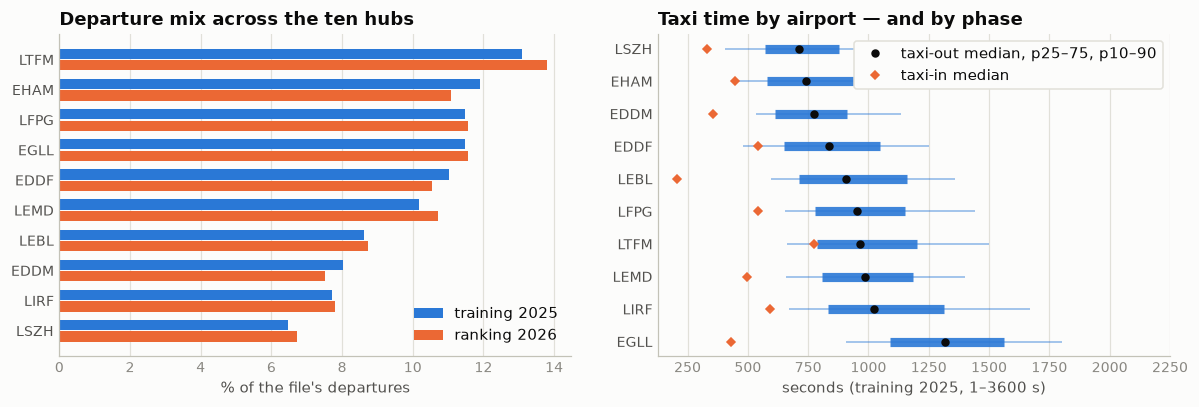

like-for-like traffic: Jan+Jul 2025 vs Jan+Jul 2026 departures per hub:
  ap   n25   n26  delta_pct
EHAM 40949 38182       -6.8
EDDM 27091 25966       -4.2
EDDF 36830 36317       -1.4
EGLL 40210 39840       -0.9
LFPG 39612 39872        0.7
LIRF 26528 26899        1.4
LTFM 46539 47581        2.2
LSZH 22346 23150        3.6
LEBL 28986 30080        3.8
LEMD 35328 36954        4.6


In [30]:
mix = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, 100.0 * count(*) / sum(count(*)) OVER () s FROM {T}
               WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, 100.0 * count(*) / sum(count(*)) OVER () s FROM {R}
               WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, t.s share_t, r.s share_r FROM t JOIN r USING (ap) ORDER BY share_t""").df()

taxi = con.sql(f"""
    SELECT ADEP_mvt ap,
           quantile_cont(TAXITIME_SEC_mvt, 0.10) p10, quantile_cont(TAXITIME_SEC_mvt, 0.25) p25,
           quantile_cont(TAXITIME_SEC_mvt, 0.50) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.75) p75, quantile_cont(TAXITIME_SEC_mvt, 0.90) p90
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY med DESC""").df()
taxi_in = con.sql(f"""
    SELECT ADES_mvt ap, quantile_cont(TAXITIME_SEC_mvt, 0.5) med FROM {T}
    WHERE PHASE_mvt = 'ARR' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 GROUP BY 1""").df().set_index("ap").med

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(mix))
a1.barh(y + 0.19, mix.share_t, height=0.34, color=BLUE, label="training 2025")
a1.barh(y - 0.19, mix.share_r, height=0.34, color=ORANGE, label="ranking 2026")
a1.set_yticks(y, mix.ap, color=INK2)
a1.set_title("Departure mix across the ten hubs")
a1.set_xlabel("% of the file's departures")
a1.legend(loc="lower right")
style(a1, x_grid=True, y_grid=False)

y = np.arange(len(taxi))
a2.hlines(y, taxi.p10, taxi.p90, color=BLUE, lw=1.2, alpha=0.45)
a2.hlines(y, taxi.p25, taxi.p75, color=BLUE, lw=6, alpha=0.9)
a2.plot(taxi.med, y, "o", color=INK, ms=4.5, zorder=3, label="taxi-out median, p25–75, p10–90")
a2.plot(taxi_in[taxi.ap].values, y, "D", color=ORANGE, ms=4, label="taxi-in median")
a2.set_yticks(y, taxi.ap, color=INK2)
a2.set_title("Taxi time by airport — and by phase")
a2.set_xlabel("seconds (training 2025, 1–3600 s)")
a2.set_xlim(right=2250)
a2.legend(loc="upper right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

print("like-for-like traffic: Jan+Jul 2025 vs Jan+Jul 2026 departures per hub:")
print(con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, count(*) n25 FROM {T}
               WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, count(*) n26 FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, n25, n26, round(100.0 * (n26 - n25) / n25, 1) delta_pct
    FROM t JOIN r USING (ap) ORDER BY delta_pct""").df().to_string(index=False))

In [31]:
# how much does the airport alone explain? Honest: means fitted on Jan–Oct, scored on Nov+Dec —
# the same holdout every later section uses — with the whole-year in-sample figure for reference
print("global mean vs airport mean:")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt ap, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) <= 10 fit
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         g AS (SELECT avg(y) m FROM d WHERE fit), a AS (SELECT ap, avg(y) am FROM d WHERE fit GROUP BY 1),
         g_all AS (SELECT avg(y) m FROM d), a_all AS (SELECT ap, avg(y) am FROM d GROUP BY 1)
    SELECT 'Nov+Dec holdout, fit Jan–Oct' basis, count(*) FILTER (NOT fit) n,
           round(sqrt(avg((y - g.m)^2) FILTER (NOT fit)), 1) rmse_global_mean,
           round(sqrt(avg((y - a.am)^2) FILTER (NOT fit)), 1) rmse_airport_mean
    FROM d CROSS JOIN g JOIN a USING (ap)
    UNION ALL
    SELECT 'whole year, in-sample', count(*), round(sqrt(avg((y - g_all.m)^2)), 1), round(sqrt(avg((y - a_all.am)^2)), 1)
    FROM d CROSS JOIN g_all JOIN a_all USING (ap)""").df().to_string(index=False))

print("\ntaxi-out by hub — and the two ranking months against the 2025 medians:")
print(con.sql(f"""
    SELECT ADEP_mvt ap, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean, round(stddev(TAXITIME_SEC_mvt)) sd,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (month(MVT_TIME_UTC_mvt) = 1) med_jan,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (month(MVT_TIME_UTC_mvt) = 7) med_jul
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY med DESC""").df().to_string(index=False))

global mean vs airport mean:
                       basis       n  rmse_global_mean  rmse_airport_mean
Nov+Dec holdout, fit Jan–Oct  327485             392.5              357.3
       whole year, in-sample 2080533             388.0              346.6

taxi-out by hub — and the two ranking months against the 2025 medians:
  ap      n   mean    sd    med  med_jan  med_jul
EGLL 238818 1354.0 373.0 1319.0   1260.0   1371.0
LIRF 158737 1117.0 443.0 1022.0    972.0   1090.0
LEMD 212242 1015.0 313.0  985.0    954.0   1002.0
LTFM 272169 1043.0 379.0  963.0    967.0   1011.0
LFPG 239091 1013.0 365.0  954.0    907.0    962.0
LEBL 179699  957.0 331.0  906.0    838.0    945.0
EDDF 230068  862.0 324.0  837.0    825.0    839.0
EDDM 167275  811.0 294.0  774.0    729.0    780.0
EHAM 247866  783.0 311.0  742.0    726.0    751.0
LSZH 134568  741.0 292.0  712.0    706.0    720.0


In [32]:
# closing state — the column after §5, which changed nothing: no derived file, no value touched
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(DISTINCT ADEP_mvt) n_unique,
           count(*) FILTER (ADEP_mvt IS NULL) null_,
           count(*) FILTER (ADEP_mvt = 'ZZZZ') zzzz,
           count(*) FILTER (ADEP_mvt NOT IN {APS}) not_hub,
           count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL AND ADEP_flt IS NOT NULL
                            AND ADEP_mvt != ADEP_flt) disagree_with_plan
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))
print("\nbefore = after on every count: §5 repairs nothing (see the decisions table)")

     src  ph       n  n_unique  null_  zzzz  not_hub  disagree_with_plan
training ARR 2082750      1581     84   111  1763487               24554
training DEP 2085047        10      0     0        0                   0
 ranking ARR  344693      1107     13    24   292935                4260
 ranking DEP  344841        10      0     0        0                   0

before = after on every count: §5 repairs nothing (see the decisions table)


               feature        kind  n / levels  pearson_r  spearman_ρ    η
ADEP_mvt — the airport categorical          10                        0.45


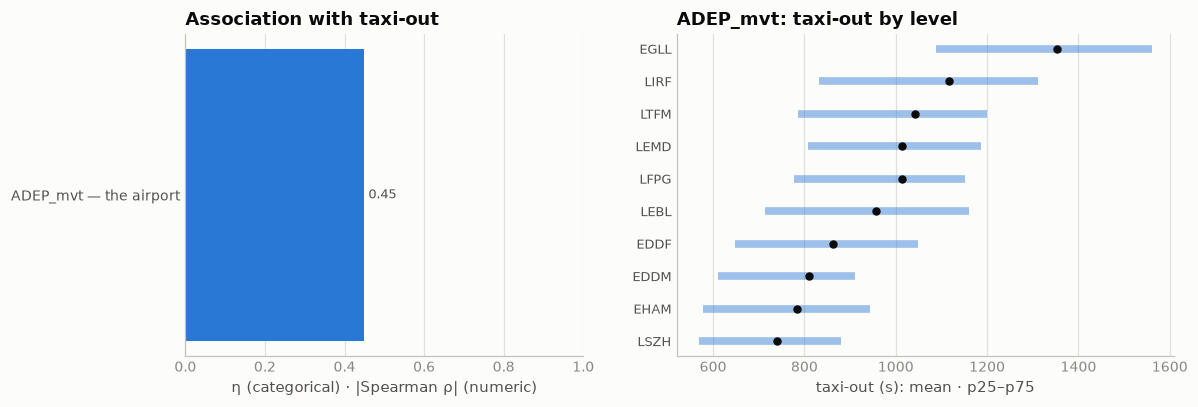

In [52]:
# correlation with the target — the airport alone
a = target_assoc([("ADEP_mvt — the airport", "cat", "ADEP_mvt")])
assoc_chart(a, "ADEP_mvt", title="ADEP_mvt")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The departure side is flawless** | zero nulls; every one of the 2,085,047 training and 344,841 ranking departures carries one of the ten hub codes — never anything else, not even `ZZZZ`; the matched plan's `ADEP_flt` agrees on all 2,062,577 comparable rows (46 plan-side nulls) | ten levels, never missing, never unseen: the pipeline's primary categorical, and the interaction partner for nearly everything |
| On arrivals it is the origin | 1,581 airports in 2025 with a long tail; 15.3% of arrivals come from a sister hub | not a feature — arrivals are never predicted |
| "Missing" comes in two spellings, arrivals only | 84 true NULLs (the system lost a code — four-fifths EDDF business aviation, PC12 shuttles) and 111 `ZZZZ`, ICAO's code for *there is no code*: LSZH and EHAM rotorcraft from helipads, hospital sites and ships — §4's special-mission fleets again, mostly unmatched, correctly so. The plan side has 20 `ZZZZ` of its own | a NULL is data loss; `ZZZZ` is a statement. They are not the same defect |
| The two sources disagree on 24,554 arrivals (1.2% of matched) | 1,291 recurring schedule-level pairs — the same "wrong" code all year. Two mechanisms: **through-flights**, where `_mvt` keeps the commercial origin and `_flt` the flown leg (Air Tahiti Nui into LFPG "from" Papeete vs the LAX leg; Ethiopian's Addis→Milan→Zurich; KLM's Caribbean tag flights), and **garbled or stale codes**, mostly on `_mvt` (BA's Berlin traffic lands at EGLL "from" the military-prefix `ETNB`; Riga's `EVRS` for `EVRA`; Bali under retired `WRRR`) — though not always (Kuwait Airways' *plans* file the retired `OKKK`) | upstream mapping tables, not noise. Where origin matters, the plan's word is the better one |
| Traffic mix holds into 2026 | LTFM 13.1% down to LSZH 6.5%; like-for-like Jan+Jul, EHAM −6.8% and EDDM −4.2% against LEMD +4.6%, LEBL +3.8%, LSZH +3.6% | no airport enters or leaves |
| **The anchor feature** | median taxi-out 712 s (LSZH) to 1,319 s (EGLL) — Heathrow's *25th percentile* (1,088 s) beats every other hub's median. Nov+Dec holdout, fit Jan–Oct: global mean **392.5 → airport mean 357.3 s** (whole year in-sample: 388.0 → 346.6) | 357.3 s is the reference every later feature must beat, on the same holdout as §3, §4, §8. Within-airport spread is the whole problem: sd 292–443 s, LIRF widest |
| The phase flip is in the target, not just the schema | taxi-in has its own ordering — LEBL 906 s out vs 207 s in, EGLL 1,319 vs 428 | never pool the phases |
| July runs longer than January at every hub | EGLL 1,371 vs 1,260 s — and Jan+Jul is what we predict | owned by §8 |

**Decisions**

| issue | decision | why |
|---|---|---|
| `ADEP_mvt` ≠ `ADEP_flt` (arrivals only) | **no repair.** If origin is ever used, take `coalesce(nullif(ADEP_flt, 'ZZZZ'), nullif(ADEP_mvt, 'ZZZZ'))` | departures agree 100%; arrivals are never predicted; the plan is right more often on the garbled pairs |
| NULL and `ZZZZ` origins (arrivals only) | **left as they are**, no derived file | not predicted, and origin is not a feature. The sentinel policy for the departures' *destination* is §6's business |
| 66 origins unseen in 2026 (162 rows) | nothing | origin is not a feature |

**State after §5** — unchanged, by design:

| | training ARR | ranking ARR | DEP, both files |
|---|---:|---:|---:|
| NULL | 84 → 84 | 13 → 13 | 0 |
| `ZZZZ` | 111 → 111 | 24 → 24 | 0 |
| disagrees with the plan | 24,554 → 24,554 | 4,260 → 4,260 | 0 |

## 6 · `ADES_mvt` — aerodrome of destination

§5's mirror: on `ARR` rows this names the hub; on `DEP` rows — the rows we predict — it is
the destination, anywhere on earth. Unlike the origin, the destination *is* a feature the
pipeline uses, so its gaps land on prediction rows and get repaired here.

| step | question | what came out |
|---|---|---|
| **integrity** | the full sentinel set — ∅ / `ZZZZ` / `AFIL` — and is every arrival's destination a hub? | arrivals flawless; 243 departures carry a sentinel, 29 of them predictions |
| **agreement** | does the plan tell the same story — through-flights and garbles again, plus this side's own wrinkle, diversions, where `ADES_FILED_flt` and `ADES_flt` part ways? | 1.4% disagree, schedule-level; on diversions the movement sides with the *filed* destination |
| **signal** | what does the destination know about taxi-out? | the strongest single feature after the airport |
| **6a · recovery** | one destination for every departure: real code, `OFF_AIRPORT`, or `UNKNOWN` | a policy that treats ∅ as data loss and `ZZZZ` as a statement; before → after at the end |

In [32]:
display(cat_stats("ADES_mvt"))

# the full sentinel set this time: NULL, ZZZZ ("no such aerodrome"), AFIL (air-filed plan)
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n,
           count(*) FILTER (ADES_mvt IS NULL) n_null,
           count(*) FILTER (ADES_mvt = 'ZZZZ') n_zzzz,
           count(*) FILTER (ADES_mvt = 'AFIL') n_afil,
           count(DISTINCT ADES_mvt) n_unique,
           count(*) FILTER (PHASE_mvt = 'ARR' AND ADES_mvt NOT IN {APS}) arr_not_hub
    FROM (SELECT 'training' src, PHASE_mvt, ADES_mvt FROM {T}
          UNION ALL SELECT 'ranking', PHASE_mvt, ADES_mvt FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndoes the matched plan agree? (training, by phase):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n_matched,
           count(*) FILTER (ADES_flt IS NULL) flt_null,
           count(*) FILTER (ADES_mvt = ADES_flt) agree,
           count(*) FILTER (ADES_mvt != ADES_flt) disagree
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,122,0.0,1568
ranking 2026,689534,13,0.0,1105


     src  ph       n  n_null  n_zzzz  n_afil  n_unique  arr_not_hub
training ARR 2082750       0       0       0        10            0
training DEP 2085047     122      92       0      1568            0
 ranking ARR  344693       0       0       0        10            0
 ranking DEP  344841      13      16       0      1105            0

does the matched plan agree? (training, by phase):
 ph  n_matched  flt_null   agree  disagree
ARR    2074244      6943 2067301         0
DEP    2062623        46 2033337     29160


In [33]:
# §5's two mechanisms mirrored outbound — plus Turkish Airlines' tag flights joining the party
print("top ADES_mvt ≠ ADES_flt pairs (training departures):")
print(con.sql(f"""
    SELECT ADES_mvt, ADES_flt, ADEP_mvt hub, mode(CALLSIGN_flt) callsign, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL AND ADES_mvt != ADES_flt
    GROUP BY 1, 2, 3 ORDER BY n DESC LIMIT 12""").df().to_string(index=False))

print("\ndiversions (ADES_flt ≠ ADES_FILED_flt) — which story does the movement side tell?")
print(con.sql(f"""
    SELECT count(*) FILTER (ADES_flt != ADES_FILED_flt) diverted,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt = ADES_FILED_flt) mvt_says_filed,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt = ADES_flt) mvt_says_actual,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt NOT IN (ADES_flt, ADES_FILED_flt)) mvt_third
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL
      AND ADES_flt IS NOT NULL AND ADES_FILED_flt IS NOT NULL AND ADES_mvt IS NOT NULL""").df().to_string(index=False))

print("\nthe departure destination space, and what 2026 adds:")
print(con.sql(f"""
    SELECT count(DISTINCT ADES_mvt) dests_2025,
           round(100.0 * count(*) FILTER (ADES_mvt IN {APS}) / count(*), 1) pct_sister_hub
    FROM {T} WHERE PHASE_mvt = 'DEP'""").df().to_string(index=False))
print(con.sql(f"""
    WITH seen AS (SELECT DISTINCT ADES_mvt FROM {T} WHERE ADES_mvt IS NOT NULL)
    SELECT count(DISTINCT ADES_mvt) dests_2026,
           count(*) FILTER (ADES_mvt NOT IN (SELECT * FROM seen)) unseen_rows,
           count(DISTINCT ADES_mvt) FILTER (ADES_mvt NOT IN (SELECT * FROM seen)) unseen_dests
    FROM {R} WHERE PHASE_mvt = 'DEP' AND ADES_mvt IS NOT NULL""").df().to_string(index=False))

top ADES_mvt ≠ ADES_flt pairs (training departures):
ADES_mvt ADES_flt  hub callsign    n
    ETNB     EDDB EGLL  BAW986G 2426
    LSSB     LFSB LFPG  AFR1192 1016
    OKBK     OKKK EGLL   KAC102  815
    NTTT     KLAX LFPG     THT7  548
    EVRS     EVRA LFPG   BTI69R  545
    MMUN     MMMX LTFM   THY184  486
    HUEN     HRYR LTFM   THY43K  362
    MPTO     SKBO LTFM   THY801  362
    SAEZ     SBGR LTFM    THY15  356
    HAAB     LIMC LSZH   ETH737  354
    APPH     YPPH EGLL    QFA10  352
    ZGGG     UAAA LTFM  THY6538  333

diversions (ADES_flt ≠ ADES_FILED_flt) — which story does the movement side tell?
 diverted  mvt_says_filed  mvt_says_actual  mvt_third
     2070            1397              641         32

the departure destination space, and what 2026 adds:
 dests_2025  pct_sister_hub
       1568            15.3
 dests_2026  unseen_rows  unseen_dests
       1105          174            62


Nov+Dec holdout RMSE (s):


 n_val  rmse_airport  rmse_plus_country  rmse_plus_dest
327449         357.3              339.4           336.4


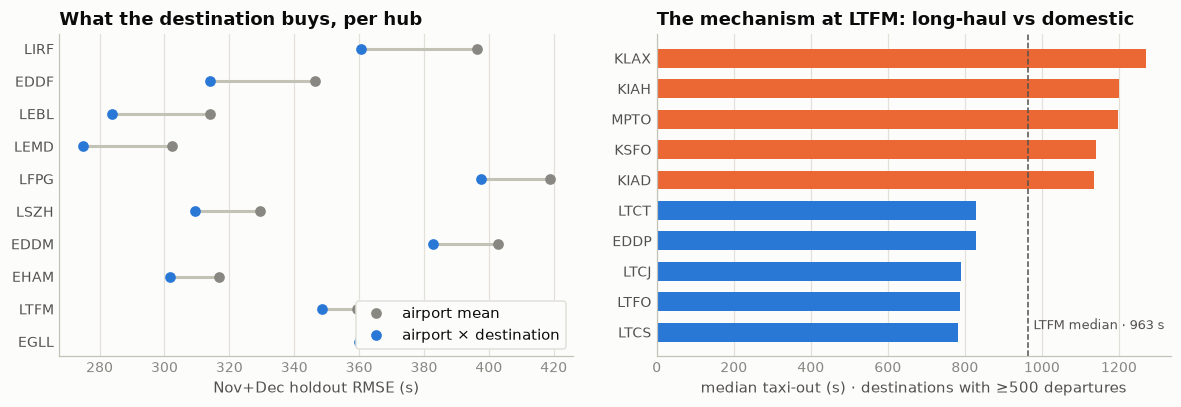

In [34]:
# does knowing where you're headed tell you how long you'll taxi? Honest: group means fitted
# on Jan–Oct (support ≥ 200, else the coarser level), scored on the Nov+Dec holdout
LAD = f"""
    WITH d AS (SELECT ADEP_mvt ap, ADES_mvt de, substr(ADES_mvt, 1, 2) cc, TAXITIME_SEC_mvt::DOUBLE y,
                      month(MVT_TIME_UTC_mvt) <= 10 fit
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
                 AND ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ'),
         am AS (SELECT ap, avg(y) m FROM d WHERE fit GROUP BY 1),
         cm AS (SELECT ap, cc, avg(y) m FROM d WHERE fit GROUP BY 1, 2 HAVING count(*) >= 200),
         dm AS (SELECT ap, de, avg(y) m FROM d WHERE fit GROUP BY 1, 2 HAVING count(*) >= 200)
    SELECT ap, y, am.m m_airport, coalesce(cm.m, am.m) m_country, coalesce(dm.m, cm.m, am.m) m_dest
    FROM d JOIN am USING (ap) LEFT JOIN cm USING (ap, cc) LEFT JOIN dm USING (ap, de) WHERE NOT fit"""
print("Nov+Dec holdout RMSE (s):")
print(con.sql(f"""
    SELECT count(*) n_val, round(sqrt(avg((y - m_airport)^2)), 1) rmse_airport,
           round(sqrt(avg((y - m_country)^2)), 1) rmse_plus_country,
           round(sqrt(avg((y - m_dest)^2)), 1) rmse_plus_dest
    FROM ({LAD})""").df().to_string(index=False))

gain = con.sql(f"""
    SELECT ap, round(sqrt(avg((y - m_airport)^2)), 1) r_airport, round(sqrt(avg((y - m_dest)^2)), 1) r_dest
    FROM ({LAD}) GROUP BY 1 ORDER BY r_airport - r_dest""").df()

lt = con.sql(f"""
    WITH d AS (SELECT ADES_mvt de, TAXITIME_SEC_mvt y FROM {T}
               WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LTFM' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         m AS (SELECT de, count(*) n, quantile_cont(y, 0.5) med FROM d GROUP BY 1 HAVING count(*) >= 500)
    (SELECT * FROM m ORDER BY med DESC LIMIT 5) UNION ALL (SELECT * FROM m ORDER BY med LIMIT 5)
    ORDER BY med""").df()
lt_med = con.sql(f"""
    SELECT quantile_cont(TAXITIME_SEC_mvt, 0.5) FROM {T}
    WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LTFM' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600""").fetchone()[0]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(gain))
a1.hlines(y, gain.r_dest, gain.r_airport, color=BASELINE, lw=2)
a1.plot(gain.r_airport, y, "o", color=MUTED, ms=6, label="airport mean")
a1.plot(gain.r_dest, y, "o", color=BLUE, ms=6, label="airport × destination")
a1.set_yticks(y, gain.ap, color=INK2)
a1.set_title("What the destination buys, per hub")
a1.set_xlabel("Nov+Dec holdout RMSE (s)")
a1.legend(loc="lower right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a1, x_grid=True, y_grid=False)

y = np.arange(len(lt))
colors = [ORANGE if m > lt_med else BLUE for m in lt.med]
a2.barh(y, lt.med, height=0.62, color=colors)
a2.axvline(lt_med, color=INK2, ls="--", lw=1)
a2.text(lt_med + 15, 0.1, f"LTFM median · {lt_med:.0f} s", color=INK2, fontsize=8.5)
a2.set_yticks(y, lt.de, color=INK2)
a2.set_title("The mechanism at LTFM: long-haul vs domestic")
a2.set_xlabel("median taxi-out (s) · destinations with ≥500 departures")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The mirror of §5 holds exactly** | on arrivals this column is the hub: ten codes, zero sentinels, and the matched plan agrees 2,067,301 times out of 2,067,301 (6,943 plan-side nulls) | nothing to do on the arrival side |
| On departures it is a real feature | 1,568 destinations, 15.3% of departures headed to a sister hub (the network is symmetric); 2026 adds 62 unseen destinations, 174 rows | a core categorical with a long tail — the model needs a fallback for the 174 |
| The sentinel census, this time on prediction rows | 122 ∅ + 92 `ZZZZ` in training, 13 + 16 in ranking — 29 predictions; `AFIL` appears nowhere | repaired in 6a |
| The two sources disagree on 29,160 departures (1.4% of matched) | §5's mechanisms viewed outbound — the same garbles and through-flights (BA's Berlin rows now *leave* "for" `ETNB`; THT7 departs LFPG "for Papeete" against the plan's KLAX leg) — plus Turkish Airlines' tag network: THY184 leaves Istanbul "for Cancún" while the plan flies the Mexico City leg, ditto Kigali→Entebbe, Bogotá→Panama, São Paulo→Buenos Aires, Almaty→Guangzhou | `_mvt` speaks the commercial through-destination, `_flt` the flown leg; both are schedule-level constants, so the pairs are left alone and any encoder can learn either dialect |
| **Diversions barely touch this column, and in the right way** | of the 2,070 diverted matched departures (`ADES_flt` ≠ `ADES_FILED_flt`), `ADES_mvt` sides with the *filed* destination 2:1 (1,397 vs 641) | the movement record is mostly a pre-departure fact — exactly what a feature should be |
| **The signal is real — honestly measured** | Nov+Dec holdout, fit Jan–Oct: airport mean **357.3 → + country prefix 339.4 → + destination 336.4 s**. Per hub the gain runs from −35.5 s (LIRF), −32.3 (EDDF), −30.1 (LEBL) down to −10.9 (LTFM) and −10.3 (EGLL). The mechanism is plain at LTFM: the median departure to `KLAX` taxis 1,270 s against 782 s for domestic `LTCS` — eight minutes of destination signal inside one airport | the strongest single feature after the airport itself. Destination is entangled with aircraft size and terminal geography; the model, not this ladder, apportions the credit |

**Use in modeling.** Destination joins airport as a core categorical. The two-letter prefix
captures most of the lift at a tiny fraction of the cardinality — keep both granularities and
let the model choose. 6a makes the column complete first.

### 6a · One destination for every departure

The sentinel policy, applied where it counts: 29 prediction rows carry a sentinel destination.
The two sentinels say opposite things, so they get opposite treatment.

| sentinel | what it means | treatment |
|---|---|---|
| **∅ null** | data loss — the system dropped a code that exists | §4a's waterfall: the matched plan → the identity's history vote → rotorcraft/VFR guess → an honest `UNKNOWN` |
| **`ZZZZ`** | a statement — this flight went where no ICAO code goes (EHAM's coastguard patrols, LSZH's rescue helicopters) | believed, and becomes the level `OFF_AIRPORT` — unless the matched plan names a real aerodrome (a lazy-entry tail of fixed-wing jets logged `ZZZZ` at the terminal) |

One design choice needs evidence rather than taste — should the history vote outrank
`OFF_AIRPORT` for `ZZZZ` rows too? — so it gets a cell.

In [35]:
# the 243 sentinel departures: what each recovery source can offer, by sentinel kind
POOLD = f"""(SELECT 'training' ds, MVT_ID_mvt, ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_mvt, ADES_mvt,
                    coalesce(nullif(ADES_flt, 'ZZZZ'), nullif(ADES_FILED_flt, 'ZZZZ')) plan_dest,
                    coalesce(AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V', FALSE) heli_vfr
             FROM {T} WHERE PHASE_mvt = 'DEP' AND (ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ')
             UNION ALL
             SELECT 'ranking', MVT_ID_mvt, ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_mvt, ADES_mvt,
                    coalesce(nullif(ADES_flt, 'ZZZZ'), nullif(ADES_FILED_flt, 'ZZZZ')),
                    coalesce(AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V', FALSE)
             FROM {R} WHERE PHASE_mvt = 'DEP' AND (ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ'))"""
VOTED = f"""(SELECT FLIGHT_mvt, arg_max(d, c) dest, max(c) top, sum(c) tot FROM
                (SELECT FLIGHT_mvt, ADES_mvt d, count(*) c
                 FROM (SELECT FLIGHT_mvt, PHASE_mvt, ADES_mvt FROM {T}
                       UNION ALL SELECT FLIGHT_mvt, PHASE_mvt, ADES_mvt FROM {R})
                 WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL
                   AND ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ'
                 GROUP BY 1, 2) GROUP BY 1)"""

print(con.sql(f"""
    SELECT ds, CASE WHEN ADES_mvt IS NULL THEN '∅ null' ELSE 'ZZZZ' END kind, count(*) n,
           count(plan_dest) plan_names_one,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NOT NULL) vote_could,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NULL AND heli_vfr) heli_vfr_rest,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NULL AND NOT heli_vfr) bare
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nwhere a vote would land the believed-ZZZZ rows — plausible, but it un-says the record:")
print(con.sql(f"""
    SELECT v.dest would_become, ADEP_mvt hub, mode(AIRCRAFT_TYPE_mvt) typ, count(*) n,
           round(avg(100.0 * top / tot), 0) purity_pct
    FROM {POOLD} p JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE ADES_mvt = 'ZZZZ' AND plan_dest IS NULL
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 8""").df().to_string(index=False))

print("\nvote quality on the null rows it actually serves:")
print(con.sql(f"""
    SELECT count(*) n_rows, round(avg(100.0 * top / tot), 1) avg_purity,
           min(tot) min_history, max(tot) max_history
    FROM {POOLD} p JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE ADES_mvt IS NULL AND plan_dest IS NULL""").df().to_string(index=False))

print("\nthe bare remainder — nulls with nothing to recover from:")
print(con.sql(f"""
    SELECT ds, ADEP_mvt hub, coalesce(AIRCRAFT_TYPE_mvt, '∅') typ,
           coalesce(FLIGHT_mvt, '∅') ident, count(*) n
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE plan_dest IS NULL AND v.dest IS NULL AND NOT heli_vfr
    GROUP BY 1, 2, 3, 4 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

      ds   kind   n  plan_names_one  vote_could  heli_vfr_rest  bare
training   ZZZZ  92              14          58             17     3
training ∅ null 122              80          19              4    19
 ranking   ZZZZ  16               2          13              1     0
 ranking ∅ null  13               7           5              0     1

where a vote would land the believed-ZZZZ rows — plausible, but it un-says the record:
would_become  hub  typ  n  purity_pct
        EHAM EHAM A139 39        89.0
        LSXA LSZH EC30  8        86.0
        LSZO LSZH AS50  5        61.0
        LSGS LSZH AS50  5        80.0
        LSGK LSZH EC20  3        67.0
        LSXU LSZH AS50  2        70.0
        LSZM LSZH B429  2        58.0
        LSZS LSZH B429  1        24.0

vote quality on the null rows it actually serves:
 n_rows  avg_purity  min_history  max_history
     24        63.3          1.0          7.0

the bare remainder — nulls with nothing to recover from:
      ds  hub  typ   ide

In [36]:
# perform the recovery -> data/derived/dest_recovered.parquet, then account for every departure
rec = con.sql(f"""
    SELECT MVT_ID_mvt, ds dataset,
           CASE WHEN plan_dest IS NOT NULL THEN plan_dest
                WHEN ADES_mvt = 'ZZZZ' THEN 'OFF_AIRPORT'
                WHEN v.dest IS NOT NULL THEN v.dest
                WHEN heli_vfr THEN 'OFF_AIRPORT'
                ELSE 'UNKNOWN' END ades_rec,
           CASE WHEN plan_dest IS NOT NULL THEN 'flt'
                WHEN ADES_mvt = 'ZZZZ' THEN 'zzzz_believed'
                WHEN v.dest IS NOT NULL THEN 'history_vote'
                WHEN heli_vfr THEN 'type_guess'
                ELSE 'unknown' END ades_src
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)""").df()

out = ROOT / "data/derived/dest_recovered.parquet"
rec.to_parquet(out, index=False)
print(f"wrote {len(rec):,} rows → {out.relative_to(ROOT)}")
print(rec.groupby(["dataset", "ades_src"]).size().unstack(fill_value=0))

DREC = f"read_parquet('{ROOT}/data/derived/dest_recovered.parquet')"
FINALD = f"""
    SELECT t.*, CASE WHEN t.ADES_mvt IS NULL OR t.ADES_mvt = 'ZZZZ' THEN rec.ades_rec
                     ELSE t.ADES_mvt END dest_final
    FROM (SELECT 'training' ds, * FROM {T} WHERE PHASE_mvt = 'DEP'
          UNION ALL SELECT 'ranking', * FROM {R} WHERE PHASE_mvt = 'DEP') t
    LEFT JOIN {DREC} rec USING (MVT_ID_mvt)"""

left = con.sql(f"WITH f AS ({FINALD}) SELECT count(*) FROM f WHERE dest_final IS NULL").fetchone()[0]
print(f"\ndepartures still without a destination: {left}")
assert left == 0

print("\nbefore -> after, departures by file:")
print(con.sql(f"""WITH f AS ({FINALD})
    SELECT ds, count(*) n,
           count(*) FILTER (ADES_mvt IS NULL) null_raw, count(*) FILTER (ADES_mvt = 'ZZZZ') zzzz_raw,
           count(*) FILTER (ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ') real_code_raw,
           count(*) FILTER (dest_final IS NULL) null_after,
           count(*) FILTER (dest_final NOT IN ('OFF_AIRPORT', 'UNKNOWN')) real_code_after,
           count(*) FILTER (dest_final = 'OFF_AIRPORT') off_airport_after,
           count(*) FILTER (dest_final = 'UNKNOWN') unknown_after
    FROM f GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nthe two synthetic levels, and how they taxi (training, 1–3600 s):")
print(con.sql(f"""WITH f AS ({FINALD})
    SELECT dest_final, count(*) FILTER (ds = 'training') train_n,
           count(*) FILTER (ds = 'ranking') rank_n,
           quantile_cont(TAXITIME_SEC_mvt, 0.5)
               FILTER (ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600) med_taxi
    FROM f WHERE dest_final IN ('OFF_AIRPORT', 'UNKNOWN') GROUP BY 1""").df().to_string(index=False))

wrote 243 rows → data/derived/dest_recovered.parquet
ades_src  flt  history_vote  type_guess  unknown  zzzz_believed
dataset                                                        
ranking     9             5           0        1             14
training   94            19           4       19             78



departures still without a destination: 0

before -> after, departures by file:
      ds       n  null_raw  zzzz_raw  real_code_raw  null_after  real_code_after  off_airport_after  unknown_after
training 2085047       122        92        2084833           0          2084946                 82             19
 ranking  344841        13        16         344812           0           344826                 14              1

the two synthetic levels, and how they taxi (training, 1–3600 s):
 dest_final  train_n  rank_n  med_taxi
OFF_AIRPORT       82      14     254.5
    UNKNOWN       19       1     843.0


                                                      feature        kind  n / levels  pearson_r  spearman_ρ     η
ADES_mvt — raw; levels with ≥ 200 departures, the rest pooled categorical         551                        0.328
               country prefix — first two letters of ADES_mvt categorical         232                        0.296
                          dest_final — after 6a; ≥ 200 pooled categorical         551                        0.328
     dest_final country — the two synthetic levels kept apart categorical         232                        0.296


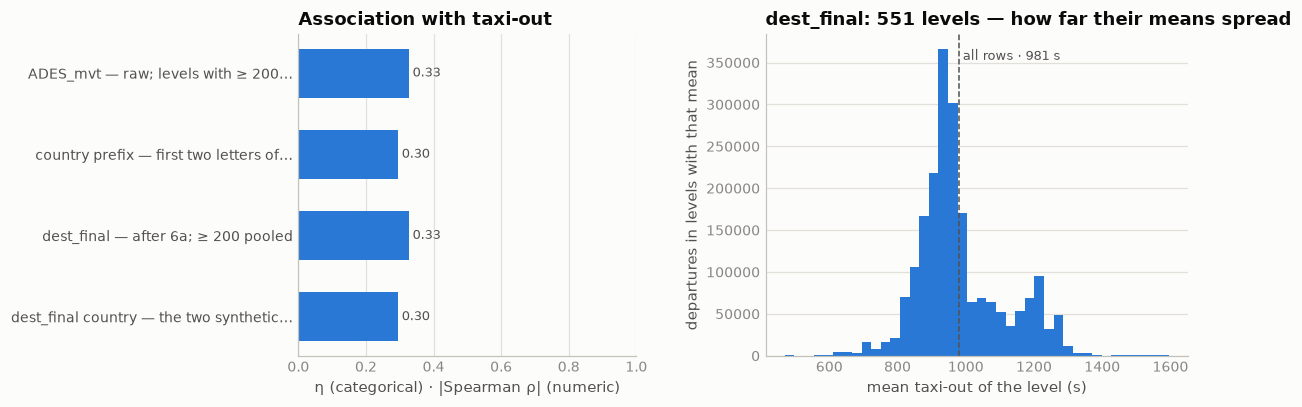

In [51]:
# correlation with the target: the raw destination, its country prefix, and the final form from 6a
FIND_T = f"(SELECT * FROM ({FINALD}) WHERE ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600)"
a = target_assoc([("ADES_mvt — raw; levels with ≥ 200 departures, the rest pooled", "cat", "ADES_mvt", 200),
              ("country prefix — first two letters of ADES_mvt", "cat", "substr(ADES_mvt, 1, 2)"),
              ("dest_final — after 6a; ≥ 200 pooled", "cat", "dest_final", 200, FIND_T),
              ("dest_final country — the two synthetic levels kept apart", "cat",
               "CASE WHEN dest_final IN ('OFF_AIRPORT', 'UNKNOWN') THEN dest_final ELSE substr(dest_final, 1, 2) END", 1, FIND_T)])
assoc_chart(a, "dest_final", src=FIND_T, min_support=200, title="dest_final")

**Findings**

| outcome | evidence | reading |
|---|---|---|
| The waterfall settles all 243 sentinel departures with provenance | `data/derived/dest_recovered.parquet`, joined on `MVT_ID_mvt` | never missing, three semantics: real code / `OFF_AIRPORT` / `UNKNOWN` |
| **Why `ZZZZ` skips the history vote** | a vote *could* name an aerodrome for 71 of the believed rows, and its answers are eerily plausible — EHAM's patrol helicopters "return to EHAM" (their logged flights are EHAM→EHAM loops), Rega's rows land on named mountain helipads (`LSXA`, `LSGS`, …) | that would claim a coded field on exactly the days the airport wrote "no coded field", and split one fleet's identical missions across levels. `OFF_AIRPORT` keeps them together — and the target agrees: median taxi-out **254.5 s** for `OFF_AIRPORT` vs **843 s** for `UNKNOWN`. The two synthetic levels mean different things, which was the whole point |
| The `UNKNOWN` remainder | EDDF business aviation (PC12s and Citations under `YY9####` pseudo-identities), two LIRF rows with no aircraft type at all, one prediction row (`TCHKA` at LTFM, type unknown) | §4a's "traffic the system barely knows" again; nothing to recover from |

| layer | the destination comes from | training | ranking |
|---|---|---:|---:|
| 1 | the matched plan (`ADES_flt`, else `ADES_FILED_flt`) — among them 16 "`ZZZZ`" flights really bound for coded airports, the fixed-wing lazy-entry tail | 94 | 9 |
| 2 | `ZZZZ` believed → `OFF_AIRPORT` | 78 | 14 |
| 3 | the identity's history vote | 19 | 5 |
| 4 | rotorcraft / VFR → `OFF_AIRPORT` | 4 | 0 |
| 5 | nothing to go on → `UNKNOWN` | 19 | 1 |

**State after §6** — departures, before → after:

| | training | ranking |
|---|---:|---:|
| ∅ null | 122 → **0** | 13 → **0** |
| `ZZZZ` | 92 → 0 | 16 → 0 |
| real code | 2,084,833 → 2,084,946 | 344,812 → 344,826 |
| `OFF_AIRPORT` | — → 82 | — → 14 |
| `UNKNOWN` | — → 19 | — → 1 |

**Pipeline recipe:** `dest_final` = raw `ADES_mvt` unless ∅/`ZZZZ`, then `ades_rec` from the
parquet (the `CASE` in the cell above, verbatim). Downstream groupings — country prefix, haul
class — must treat the two synthetic levels as their own groups.

## 7 · `PHASE_mvt` — the column that isn't a feature

`DEP` or `ARR`, never anything else, never missing. On the rows we are scored on it is
**constant** — every one of the 344,841 predictions is a departure — so as a predictor it is
worth exactly nothing. That is the whole of its direct story, and it takes one cell to tell.

Its real job is structural: it **partitions the file**. One half is the departures we learn
from and predict; the other is 2,082,750 training and 344,693 ranking arrivals that are never
scored — and never blanked either. The organizers redacted two columns, on departure rows only.
Everything else about every arrival at our ten hubs, on the very days we predict, is handed to
us. So the questions here are not about the column's distribution:

| step | question | what came out |
|---|---|---|
| **integrity & balance** | the two-value census; does each hub launch as many aircraft as it receives? | within ±0.6% — the arrival stream is a same-size mirror |
| **the leak map** | precisely which columns survive on which phase in `ranking.parquet` | two columns, departure rows only: the target's other endpoint is the only secret |
| **the phase flip** | which `_mvt` columns change *meaning* with phase, and the pooling trap that follows | takeoff vs landing, taxi-out vs taxi-in — never pool the phases |
| **signal** | the arrival half is unused by the pipeline; does it know anything about a departure's taxi-out that airport, runway and the off-block anchor don't? | −5.2 s on an honest ladder, every hub gains |
| **7a · the sensor** | one of the two context variables misbehaves at Schiphol — why? | it reads the runway configuration, not congestion; its sign is airport-specific |

In [37]:
display(cat_stats("PHASE_mvt"))

# the leak map: null rate of every column, by file × phase
RANK_COLS = [c[0] for c in con.sql(f"DESCRIBE SELECT * FROM {R}").fetchall()]
pct_null = con.sql(f"""
    SELECT src, PHASE_mvt ph,
           {', '.join(f'round(100.0*count(*) FILTER ({c} IS NULL)/count(*), 2) AS "{c}"'
                      for c in RANK_COLS)}
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().set_index(["src", "ph"]).T

blanked = [c for c in RANK_COLS if pct_null.loc[c, ("ranking", "DEP")] > 50]
print(f"of {len(RANK_COLS)} columns, blanked on ranking DEP rows: {', '.join(blanked)}")
print(f"the other {len(RANK_COLS) - len(blanked)} are as populated at prediction time as in training")
print("\n% NULL by file × phase — every column that is ever missing:")
print(pct_null[pct_null.max(axis=1) > 0].to_string())

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,0,0.0,2
ranking 2026,689534,0,0.0,2


of 30 columns, blanked on ranking DEP rows: BLOCK_TIME_UTC_mvt, TAXITIME_SEC_mvt
the other 28 are as populated at prediction time as in training

% NULL by file × phase — every column that is ever missing:
src                   training       ranking        
ph                         ARR   DEP     ARR     DEP
FLIGHT_ID_mvt             0.41  1.08    0.41    1.53
FLIGHT_mvt                0.01  0.01    0.01    0.02
FLIGHT_RULE_mvt           0.02  0.01    0.02    0.01
ADES_mvt                  0.00  0.01    0.00    0.00
BLOCK_TIME_UTC_mvt        0.00  0.00    0.00  100.00
AIRCRAFT_TYPE_mvt         0.01  0.07    0.01    0.11
TAXITIME_SEC_mvt          0.00  0.00    0.00  100.00
LOBT_flt                  0.74  1.08    0.74    1.53
CALLSIGN_flt              0.74  1.08    0.74    1.53
ADEP_flt                  0.74  1.08    0.74    1.53
ADES_flt                  0.74  1.08    0.74    1.53
ADES_FILED_flt            0.74  1.08    0.74    1.53
MARKET_SEGMENT_flt        0.74  1.08    0.74    1.53

In [38]:
# does each hub launch what it receives?
print("movements at the hub, by phase (DEP counted at ADEP, ARR at ADES):")
print(con.sql(f"""
    SELECT hub, t_dep, t_arr, round(100.0*t_dep/t_arr - 100, 2) t_gap_pct,
           r_dep, r_arr, round(100.0*r_dep/r_arr - 100, 2) r_gap_pct
    FROM (SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
                 count(*) FILTER (src = 't' AND PHASE_mvt = 'DEP') t_dep,
                 count(*) FILTER (src = 't' AND PHASE_mvt = 'ARR') t_arr,
                 count(*) FILTER (src = 'r' AND PHASE_mvt = 'DEP') r_dep,
                 count(*) FILTER (src = 'r' AND PHASE_mvt = 'ARR') r_arr
          FROM (SELECT 't' src, * FROM {T} UNION ALL SELECT 'r' src, * FROM {R})
          GROUP BY 1)
    ORDER BY t_dep DESC""").df().to_string(index=False))

# the phase flip, in the target itself
print("\nthe same columns, two different quantities (training, 1–3600 s):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi,
           count(DISTINCT RUNWAY_mvt) n_runways, count(DISTINCT STAND_mvt) n_stands
    FROM {T} WHERE TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

movements at the hub, by phase (DEP counted at ADEP, ARR at ADES):
 hub  t_dep  t_arr  t_gap_pct  r_dep  r_arr  r_gap_pct
LTFM 272965 273886      -0.34  47581  47764      -0.38
EHAM 247951 247706       0.10  38182  38143       0.10
LFPG 239552 238835       0.30  39872  39733       0.35
EGLL 239546 239511       0.01  39840  39837       0.01
EDDF 230141 230122       0.01  36317  36253       0.18
LEMD 212242 211091       0.55  36954  37093      -0.37
LEBL 179705 179081       0.35  30080  29973       0.36
EDDM 167334 167323       0.01  25966  25935       0.12
LIRF 160704 160504       0.12  26899  26839       0.22
LSZH 134907 134691       0.16  23150  23123       0.12

the same columns, two different quantities (training, 1–3600 s):
 ph       n  mean_taxi  med_taxi  n_runways  n_stands
ARR 2082073      535.0     480.0         54      1849
DEP 2080533      981.0     911.0         53      1897


In [39]:
# One movement stream per hub. Everything below uses ONLY columns the leak map cleared:
# takeoff/landing times (both phases) and arrivals' taxi-in — never a departure's block time.
con.sql(f"""
    CREATE OR REPLACE TABLE mvt_stream AS
    SELECT ds, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
           PHASE_mvt ph, MVT_TIME_UTC_mvt t, RUNWAY_mvt rwy, AOBT_3_flt aobt3,
           CASE WHEN PHASE_mvt = 'ARR' THEN TAXITIME_SEC_mvt END taxi_in,
           CASE WHEN PHASE_mvt = 'DEP' THEN TAXITIME_SEC_mvt END taxi_out
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking' ds, * FROM {R})""")

# airport state over the 60 minutes up to each movement — one query, both files
con.sql("""
    CREATE OR REPLACE TABLE dep_ctx AS
    SELECT *,
           sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER w n_dep_60,
           sum(CASE WHEN ph = 'ARR' THEN 1 ELSE 0 END) OVER w n_arr_60,
           avg(CASE WHEN ph = 'ARR' THEN taxi_in END) OVER w mean_tin_60
    FROM mvt_stream
    WINDOW w AS (PARTITION BY ds, hub ORDER BY t
                 RANGE BETWEEN INTERVAL 60 MINUTE PRECEDING AND CURRENT ROW)""")

print("the same context, computed identically on both files (DEP rows):")
print(con.sql("""
    SELECT ds, count(*) n_dep,
           round(100.0*count(*) FILTER (mean_tin_60 IS NOT NULL)/count(*), 2) pct_with_context,
           round(avg(n_dep_60), 1) mean_dep_60, round(avg(n_arr_60), 1) mean_arr_60,
           round(avg(mean_tin_60)) mean_taxi_in_60
    FROM dep_ctx WHERE ph = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nranking is two disjoint month-blocks, so each opens cold — what does the seam cost?")
print(con.sql("""
    SELECT date_trunc('month', t) block, count(*) n_dep,
           count(*) FILTER (t < date_trunc('month', t) + INTERVAL 60 MINUTE) first_hour
    FROM dep_ctx WHERE ds = 'ranking' AND ph = 'DEP'
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

# and the assumption worth testing: is the AOBT_3 anchor simply the answer?
print("\nthe AOBT_3 anchor on its own (training DEP, 1–3600 s):")
print(con.sql(f"""
    SELECT round(100.0*count(*) FILTER (AOBT_3_flt IS NOT NULL)/count(*), 2) pct_have_anchor,
           round(sqrt(avg((TAXITIME_SEC_mvt - epoch(MVT_TIME_UTC_mvt - AOBT_3_flt))^2)
                      FILTER (AOBT_3_flt IS NOT NULL)), 1) rmse_as_prediction,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) - TAXITIME_SEC_mvt, 0.5)
                 FILTER (AOBT_3_flt IS NOT NULL)) med_bias_s,
           round(100.0*count(*) FILTER (abs(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)
                                            - TAXITIME_SEC_mvt) <= 60)
                 /count(*) FILTER (AOBT_3_flt IS NOT NULL), 1) pct_within_60s
    FROM {T} WHERE PHASE_mvt = 'DEP'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600""").df().to_string(index=False))

the same context, computed identically on both files (DEP rows):
      ds   n_dep  pct_with_context  mean_dep_60  mean_arr_60  mean_taxi_in_60
training 2085047             99.88         35.4         30.8            546.0
 ranking  344841             99.88         34.7         30.1            546.0

ranking is two disjoint month-blocks, so each opens cold — what does the seam cost?
                    block  n_dep  first_hour
2026-01-01 00:00:00+00:00 152719          16
2026-07-01 00:00:00+00:00 192122          14

the AOBT_3 anchor on its own (training DEP, 1–3600 s):


 pct_have_anchor  rmse_as_prediction  med_bias_s  pct_within_60s
           98.98               361.6        52.0            21.1


In [40]:
# Honest ladder: group means fitted on Jan–Oct 2025, scored on Nov+Dec — the pipeline's own
# holdout. Bin edges come from the fit period only; a cell with < 30 rows falls back to the
# next coarser rung. The first three rungs are what the model already has.
con.sql("""
    CREATE OR REPLACE TABLE lad AS
    SELECT hub, rwy, taxi_out::DOUBLE y, n_dep_60, mean_tin_60,
           epoch(t - aobt3) anchor, (t >= TIMESTAMPTZ '2025-11-01') is_val
    FROM dep_ctx
    WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600
      AND rwy IS NOT NULL AND aobt3 IS NOT NULL AND mean_tin_60 IS NOT NULL""")
con.sql("""
    CREATE OR REPLACE TABLE lad_b AS
    WITH cuts AS (
        SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                    quantile_cont(n_dep_60, [0.2,0.4,0.6,0.8]) qd,
                    quantile_cont(mean_tin_60, [0.2,0.4,0.6,0.8]) qt
        FROM lad WHERE NOT is_val GROUP BY 1)
    SELECT lad.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc,
                  list_count(list_filter(qd, x -> x <= n_dep_60)) q_dep,
                  list_count(list_filter(qt, x -> x <= mean_tin_60)) q_tin
    FROM lad JOIN cuts USING (hub)""")

MIN_N = 30
RUNGS = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]),
         ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"]),
         ("+ arrival context", ["hub", "rwy", "q_anc", "q_dep", "q_tin"])]
for i, (_, keys) in enumerate(RUNGS):
    con.sql(f"""CREATE OR REPLACE TABLE rung{i} AS
                SELECT {', '.join(keys)}, avg(y) m, count(*) c
                FROM lad_b WHERE NOT is_val GROUP BY ALL""")

n_val = con.sql("SELECT count(*) FROM lad_b WHERE is_val").fetchone()[0]
print(f"fit Jan–Oct 2025 → scored on {n_val:,} Nov+Dec departures "
      f"(cell support ≥ {MIN_N}, else the next coarser rung):")
joins, preds = [], []
for i, (name, keys) in enumerate(RUNGS):
    joins.append(f"LEFT JOIN rung{i} USING ({', '.join(keys)})")
    preds.append(f"CASE WHEN rung{i}.c >= {MIN_N} THEN rung{i}.m END")
    cascade = "coalesce(" + ", ".join(reversed(preds)) + ", g.m)"
    r = con.sql(f"""SELECT sqrt(avg((v.y - {cascade})^2)) FROM lad_b v {' '.join(joins)}
        CROSS JOIN (SELECT avg(y) m FROM lad_b WHERE NOT is_val) g
        WHERE v.is_val""").fetchone()[0]
    print(f"    {name:20s} {r:7.1f} s")

print("\nwhich half of the context does the work? (each on top of runway + anchor)")
for nm, extra in [("departures in prior hour", ["q_dep"]),
                  ("mean taxi-in in prior hour", ["q_tin"]),
                  ("both", ["q_dep", "q_tin"])]:
    keys = ["hub", "rwy", "q_anc"] + extra
    con.sql(f"""CREATE OR REPLACE TABLE rx AS SELECT {', '.join(keys)}, avg(y) m, count(*) c
                FROM lad_b WHERE NOT is_val GROUP BY ALL""")
    r = con.sql(f"""
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN rx.c >= {MIN_N} THEN rx.m END,
                                        CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                        CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                        rung0.m))^2))
        FROM lad_b v LEFT JOIN rx USING ({', '.join(keys)})
        LEFT JOIN rung2 USING (hub, rwy, q_anc) LEFT JOIN rung1 USING (hub, rwy)
        LEFT JOIN rung0 USING (hub) WHERE v.is_val""").fetchone()[0]
    print(f"    {nm:28s} {r:7.1f} s")

fit Jan–Oct 2025 → scored on 324,227 Nov+Dec departures (cell support ≥ 30, else the next coarser rung):
    airport                355.2 s
    + runway               341.7 s
    + AOBT_3 anchor        283.6 s
    + arrival context      278.4 s

which half of the context does the work? (each on top of runway + anchor)
    departures in prior hour       279.8 s
    mean taxi-in in prior hour     281.5 s
    both                           278.4 s


per-hub holdout RMSE, before and after the arrival context:
 hub  base  with_ctx  gain
EGLL 280.0     278.8   1.2
EHAM 202.9     200.9   2.0
LEMD 235.0     232.8   2.2
EDDM 304.5     300.8   3.6
EDDF 249.1     244.5   4.6
LEBL 248.3     242.4   5.9
LIRF 375.2     369.0   6.2
LFPG 336.8     330.4   6.4
LSZH 247.2     240.4   6.8
LTFM 323.6     312.6  11.0


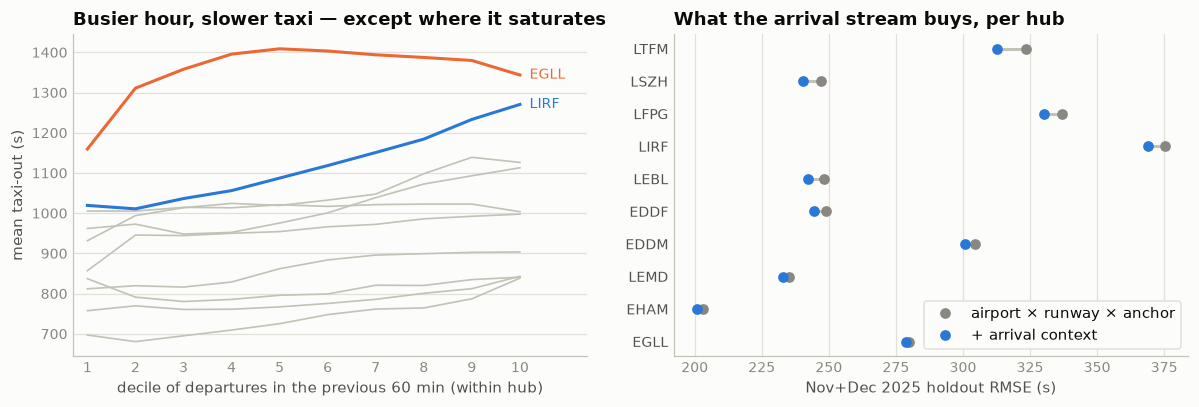

In [41]:
curve = con.sql("""
    WITH d AS (SELECT hub, taxi_out::DOUBLE y, n_dep_60 FROM dep_ctx
               WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600),
         b AS (SELECT *, ntile(10) OVER (PARTITION BY hub ORDER BY n_dep_60) q FROM d)
    SELECT hub, q, avg(y) mean_taxi FROM b GROUP BY 1, 2 ORDER BY 1, 2""").df()
gain = con.sql(f"""
    SELECT hub, sqrt(avg((v.y - coalesce(CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                         CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                         rung0.m))^2)) base,
                sqrt(avg((v.y - coalesce(CASE WHEN rung3.c >= {MIN_N} THEN rung3.m END,
                                         CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                         CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                         rung0.m))^2)) with_ctx
    FROM lad_b v LEFT JOIN rung3 USING (hub, rwy, q_anc, q_dep, q_tin)
    LEFT JOIN rung2 USING (hub, rwy, q_anc) LEFT JOIN rung1 USING (hub, rwy)
    LEFT JOIN rung0 USING (hub)
    WHERE v.is_val GROUP BY 1 ORDER BY base - with_ctx""").df()
print("per-hub holdout RMSE, before and after the arrival context:")
print(gain.assign(gain=(gain.base - gain.with_ctx)).round(1).to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for hub, g in curve.groupby("hub"):
    hi = hub in ("LIRF", "EGLL")
    a1.plot(g.q, g.mean_taxi, color={"LIRF": BLUE, "EGLL": ORANGE}.get(hub, BASELINE),
            lw=2.0 if hi else 1.1, zorder=3 if hi else 1)
    if hi:
        a1.text(10.2, g.mean_taxi.iloc[-1], hub, fontsize=9, va="center",
                color={"LIRF": BLUE, "EGLL": ORANGE}[hub])
a1.set_xticks(range(1, 11))
a1.set_xlim(0.7, 11.4)
a1.set_title("Busier hour, slower taxi — except where it saturates")
a1.set_xlabel("decile of departures in the previous 60 min (within hub)")
a1.set_ylabel("mean taxi-out (s)")
style(a1)

y = np.arange(len(gain))
a2.hlines(y, gain.with_ctx, gain.base, color=BASELINE, lw=2)
a2.plot(gain.base, y, "o", color=MUTED, ms=6, label="airport × runway × anchor")
a2.plot(gain.with_ctx, y, "o", color=BLUE, ms=6, label="+ arrival context")
a2.set_yticks(y, gain.hub, color=INK2)
a2.set_title("What the arrival stream buys, per hub")
a2.set_xlabel("Nov+Dec 2025 holdout RMSE (s)")
a2.legend(loc="lower right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| Constant on the scored rows | two values, 4,857,331 rows, **zero nulls** in either file; every prediction is a `DEP` | the only column whose value we know before reading the row — never enters the model matrix |
| **The leak map is two columns wide** | of the 30 columns, exactly `BLOCK_TIME_UTC_mvt` and `TAXITIME_SEC_mvt` are blanked in `ranking.parquet`, and only on `DEP` rows — 100% null there, 0% everywhere else. The other 28 are as populated at prediction time as in training, `RUNWAY_mvt` and `STAND_mvt` at 0.00% null on both phases and the whole `_flt` block at 1.53%. The one other column that moves between the files is `FLIGHT_ID_mvt` (§2's matching failures, 1.08% → 1.53%) | **the target's other endpoint is the only thing hidden.** Taxi-out is takeoff − off-block; we are given the takeoff and asked for the gap. Any feature that reconstructs a departure's own off-block time from the movement side is a leak. Everything else in the file — *both phases* — is fair game |
| Balance | each hub launches within ±0.6% of what it receives (LEMD +0.55%, LTFM −0.34%), in both files | an airport conserves aircraft: the arrival stream is a same-size mirror of the departure stream, not a small side dataset |
| **The phase flip is a pooling trap** | `ADEP`/`ADES` swap roles (§5, §6), and `MVT_TIME`, `BLOCK_TIME`, `SCHED_TIME`, `RUNWAY`, `STAND` and the target all mean something different on each side: over the same column, 981 s mean taxi-out against 535 s taxi-in, across 53 departure runways and 54 arrival ones | every statistic in this notebook filters on phase, and the pipeline trains on `PHASE_mvt = 'DEP'` for exactly that reason |
| **The arrival half is not a spectator** | two crude context variables built from cleared columns alone — departures in the previous 60 min by takeoff time, mean taxi-in of arrivals in the previous 60 min — move the honest ladder (fit Jan–Oct, score Nov+Dec, support-30 cascade): airport **355.2** → + runway **341.7** → + `AOBT_3` anchor **283.6** → **+ arrival context 278.4 s**. Departures-in-the-hour carries more of it (−3.8 s) than mean taxi-in (−2.1 s), and the two are not redundant. Every hub gains: LTFM −11.0 s, LSZH −6.8, LFPG −6.4, LIRF −6.2 at the top, EGLL −1.2 at the bottom | −5.2 s on top of the three strongest things the model already has, from plain group means and no tuning |
| The `AOBT_3` anchor is not the answer handed over | taken raw, `MVT_TIME − AOBT_3` predicts taxi-out at RMSE 361.6 s — *worse than the airport mean* — with a +52 s median bias and only 21% of rows inside a minute; it is missing on 1.53% of the rows we must predict | NM's actual-off-block for the flown trajectory and the airport's own block time are different clocks. It is the ladder's biggest single step (−58 s) precisely because the model can calibrate that offset per airport and runway; it is not a shortcut |
| The context survives the ranking file's shape | two disjoint month-blocks, so the windows at 00:00 on 1 Jan and 1 Jul open cold — 30 departures of 344,841. Otherwise indistinguishable across the files: 99.88% coverage on both, 34.7 vs 35.4 departures/hour, 30.1 vs 30.8 arrivals/hour, mean prior-hour taxi-in 546 s in each | the recipe computes identically at prediction time |

The ladder's airport rung reads 355.2 s where §5 reports 357.3 s on the same holdout: this
ladder keeps only the 324,227 departures that have a runway, an anchor and a context value.

**Use in modeling.** `PHASE_mvt` is a row filter, never a feature — but it is the key to the
file's other half. Build per-hub rolling airport-state features off the *full* movement stream,
both phases, anchored on `MVT_TIME_UTC_mvt`, and join them onto the departures. No derived
parquet here, deliberately: unlike §2's and §4a's recovery layers, this is one window query
whose parameters were still open when this section was written — §8 has since settled them
(a window *centred* on takeoff, 15–30 min, beats this section's trailing hour). Before
generalizing the recipe, though, 7a: one of these two variables turns out not to be measuring
congestion at all.

### 7a · The arrival stream is a runway-configuration sensor

One of §7's two context variables misbehaves. Mean taxi-in over the previous hour correlates
*positively* with taxi-out at eight of the ten hubs (LFPG +0.20, EGLL +0.16, EDDF +0.13) —
slow surface, slow everywhere, as expected. At Schiphol it correlates **−0.28**: the longer
arrivals have been taxiing in, the *shorter* the departures taxi out. Either the variable is
noise at EHAM, or it is not measuring congestion.

It is not measuring congestion. It is reading the **runway configuration** off the arrival
stream — and Schiphol's geometry makes that reading invert.

In [42]:
print("EHAM taxi-in by arrival runway — the runways are not interchangeable:")
print(con.sql(f"""
    SELECT RUNWAY_mvt rwy, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi_in
    FROM {T} WHERE PHASE_mvt = 'ARR' AND ADES_mvt = 'EHAM'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

print("\nEHAM taxi-out by departure runway — and 36L is 18R's other end:")
print(con.sql(f"""
    SELECT RUNWAY_mvt rwy, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi_out
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

# add "share of arrivals landing on the Polderbaan" to the same rolling window
con.sql(f"""
    CREATE OR REPLACE TABLE eham_ctx AS
    SELECT *, avg(taxi_in) OVER w mean_tin_60,
              avg(CASE WHEN ph = 'ARR' THEN (rwy = '18R')::INT END) OVER w share_18R
    FROM (SELECT PHASE_mvt ph, MVT_TIME_UTC_mvt t, RUNWAY_mvt rwy, TAXITIME_SEC_mvt taxi,
                 CASE WHEN PHASE_mvt = 'ARR' THEN TAXITIME_SEC_mvt END taxi_in
          FROM {T} WHERE (PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM')
                      OR (PHASE_mvt = 'ARR' AND ADES_mvt = 'EHAM'))
    WINDOW w AS (ORDER BY t RANGE BETWEEN INTERVAL 60 MINUTE PRECEDING AND CURRENT ROW)""")

print("\nsorting EHAM departures by the prior hour's mean taxi-in:")
print(con.sql("""
    WITH d AS (SELECT taxi::DOUBLE y, rwy, mean_tin_60, share_18R FROM eham_ctx
               WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND mean_tin_60 IS NOT NULL),
         b AS (SELECT *, ntile(10) OVER (ORDER BY mean_tin_60) q FROM d)
    SELECT q, count(*) n, round(avg(mean_tin_60)) prior_hr_taxi_in,
           round(100*avg(share_18R)) pct_arr_on_18R, mode(rwy) top_dep_rwy,
           round(avg(y)) dep_taxi_out
    FROM b GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe configuration split — one flow, and only one phase pays for the Polderbaan:")
print(con.sql("""
    SELECT CASE WHEN share_18R >= 0.5 THEN '18R landing (south flow)'
                ELSE 'other configuration' END config, count(*) n,
           round(avg(taxi)) mean_taxi_out,
           round(100.0*count(*) FILTER (rwy = '36L')/count(*), 1) pct_dep_36L,
           round(100.0*count(*) FILTER (rwy = '24')/count(*), 1) pct_dep_24,
           round(100.0*count(*) FILTER (rwy = '18L')/count(*), 1) pct_dep_18L
    FROM eham_ctx WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND share_18R IS NOT NULL
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

EHAM taxi-in by arrival runway — the runways are not interchangeable:
rwy     n  mean_taxi_in
18R 92274         776.0
 06 60216         303.0
18C 37554         407.0
36R 28541         289.0
 27 10460         370.0
 22  9724         293.0

EHAM taxi-out by departure runway — and 36L is 18R's other end:
rwy     n  mean_taxi_out
 24 85212          665.0
36L 58570         1082.0
18L 55571          735.0
36C 30899          729.0
 09  7855          836.0
 22  4694          276.0



sorting EHAM departures by the prior hour's mean taxi-in:
 q     n  prior_hr_taxi_in  pct_arr_on_18R top_dep_rwy  dep_taxi_out
 1 24778             258.0             0.0         36L         915.0
 2 24778             296.0             0.0         36L         914.0
 3 24778             331.0             0.0         36L         905.0
 4 24777             385.0             1.0         36L         870.0
 5 24777             496.0            25.0          24         775.0
 6 24777             586.0            53.0          24         661.0
 7 24777             634.0            68.0          24         679.0
 8 24777             677.0            81.0          24         679.0
 9 24777             719.0            89.0          24         688.0
10 24777             816.0            92.0          24         749.0

the configuration split — one flow, and only one phase pays for the Polderbaan:
                  config      n  mean_taxi_out  pct_dep_36L  pct_dep_24  pct_dep_18L
18R landing (sou

 hub      r
EHAM -0.281
LEBL -0.077
LSZH  0.014
LEMD  0.060
LTFM  0.067
LIRF  0.098
EDDM  0.099
EDDF  0.129
EGLL  0.160
LFPG  0.197


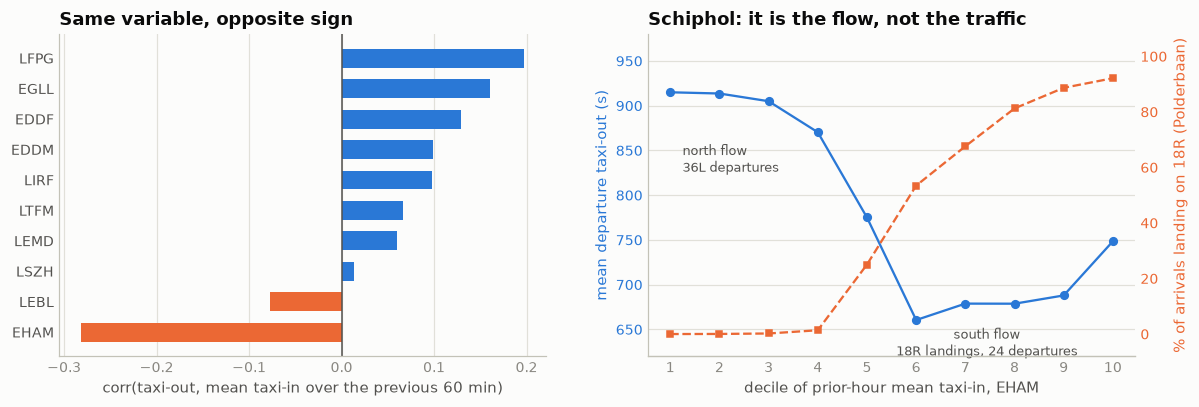

In [43]:
corr = con.sql("""
    SELECT hub, corr(taxi_out, mean_tin_60) r FROM dep_ctx
    WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY r""").df()
mech = con.sql("""
    WITH d AS (SELECT taxi::DOUBLE y, mean_tin_60, share_18R FROM eham_ctx
               WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND mean_tin_60 IS NOT NULL),
         b AS (SELECT *, ntile(10) OVER (ORDER BY mean_tin_60) q FROM d)
    SELECT q, avg(y) taxi_out, 100*avg(share_18R) pct_18R FROM b GROUP BY 1 ORDER BY 1""").df()
print(corr.round(3).to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(corr))
a1.barh(y, corr.r, height=0.62, color=[ORANGE if v < 0 else BLUE for v in corr.r])
a1.axvline(0, color=INK2, lw=1)
a1.set_yticks(y, corr.hub, color=INK2)
a1.set_title("Same variable, opposite sign")
a1.set_xlabel("corr(taxi-out, mean taxi-in over the previous 60 min)")
style(a1, x_grid=True, y_grid=False)

# the two series are named by their own coloured axis labels — no legend to sit on the data
a2.plot(mech.q, mech.taxi_out, "o-", color=BLUE, ms=5)
a2.set_ylabel("mean departure taxi-out (s)", color=BLUE)
a2.tick_params(axis="y", colors=BLUE)
a2.set_ylim(620, 980)
a2.set_xticks(range(1, 11))
a2.set_xlabel("decile of prior-hour mean taxi-in, EHAM")
a2.set_title("Schiphol: it is the flow, not the traffic")
style(a2)
a3 = a2.twinx()
a3.plot(mech.q, mech.pct_18R, "s--", color=ORANGE, ms=4.5)
a3.set_ylabel("% of arrivals landing on 18R (Polderbaan)", color=ORANGE)
a3.tick_params(axis="y", colors=ORANGE, length=0)
a3.set_ylim(-8, 108)
a3.grid(False)
a3.spines[["top", "left", "right"]].set_visible(False)
a2.annotate("north flow\n36L departures", (1, 915), textcoords="offset points", xytext=(8, -52),
            fontsize=8.5, color=INK2)
a2.annotate("south flow\n18R landings, 24 departures", (8, 679), textcoords="offset points",
            xytext=(-18, -34), fontsize=8.5, color=INK2, ha="center")
fig.tight_layout(w_pad=3.2)
plt.show()

                                      feature        kind  n / levels  pearson_r  spearman_ρ     η
           PHASE_mvt on departures — constant categorical           1                        0.000
PHASE_mvt over both phases — the pooling trap categorical           2                        0.542


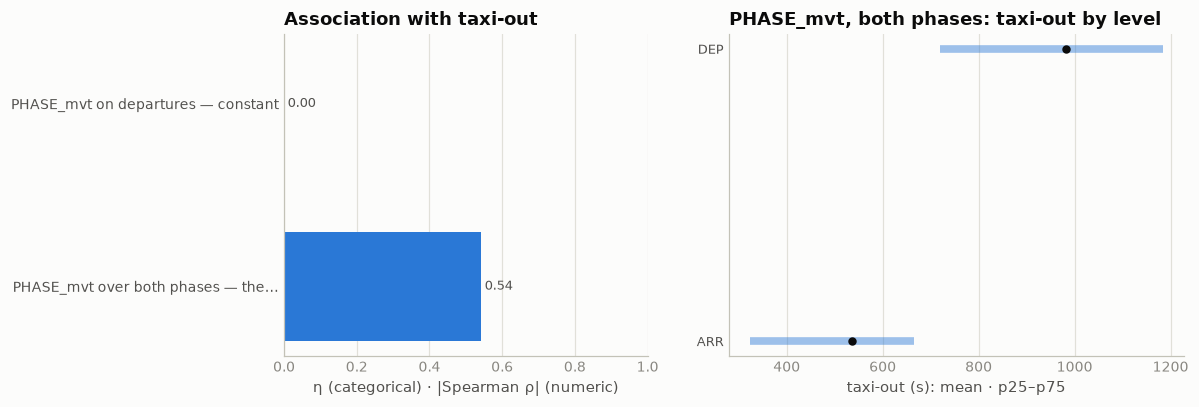

In [50]:
# correlation with the target: on the rows we predict the phase is constant, so there is nothing to
# correlate. Pooled over both phases it looks like a strong feature — that is the pooling trap, not a signal
BOTH_T = f"(SELECT * FROM {T} WHERE TAXITIME_SEC_mvt BETWEEN 1 AND 3600)"
a = target_assoc([("PHASE_mvt on departures — constant", "cat", "PHASE_mvt"),
              ("PHASE_mvt over both phases — the pooling trap", "cat", "PHASE_mvt", 1, BOTH_T)])
assoc_chart(a, "PHASE_mvt", src=BOTH_T, title="PHASE_mvt, both phases")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **EHAM's arrival runways are not interchangeable** | landing on **18R, the Polderbaan**, costs a mean **776 s** of taxi-in; landing on 06 or 36R costs 303 s and 289 s. The Polderbaan sits some 7 km from the terminal — built for noise abatement, not convenience | "mean taxi-in over the last hour" at EHAM is, to first order, a **thermometer for whether 18R is the landing runway** |
| **18R landing implies a configuration in which departures taxi less** | sorting departures by the prior hour's mean taxi-in: in the bottom four deciles 0–1% of arrivals used 18R, the modal departure runway is **36L**, and taxi-out averages 870–915 s. From the sixth decile up, 53–92% of arrivals used 18R, the modal departure runway is **24, the Kaagbaan**, and taxi-out averages 661–749 s. Split at 50% 18R: departures on 36L collapse from 44.0% to 0.2%, runways 24 and 18L take 94.2% of the traffic, and mean taxi-out falls **869 → 685 s** | the asymmetry is geometric, not statistical. **36L is 18R's other end** — and EHAM's longest departure taxi (1,082 s, against 665 s for 24). The Polderbaan is always the long leg; the flow direction only decides *which phase pays for it*. South flow lands on 18R and departs from the near runways; north flow departs from 36L and lands on the near ones. One rolling average of arrival taxi-in tells us which of the two we are in |
| **The sign is airport-specific and must be learned as such** | corr(taxi-out, prior-hour mean taxi-in) runs from +0.20 (LFPG), +0.16 (EGLL) and +0.13 (EDDF) down through +0.01 (LSZH) to −0.08 (LEBL) and −0.28 (EHAM) | a single global "the surface is slow" feature would cancel these against each other; interacted with the hub, the same number carries congestion at eight airports and flow direction at Schiphol. It also explains §7's per-hub table, where EHAM gains the second least — a variable pulling in two directions at once is doing half its job |

**Use in modeling.** Keep the rolling arrival statistics, but as per-airport quantities the
model may interact with `ADEP_mvt` — never globally standardized, which would destroy exactly
the structure above; LightGBM gets the interaction for free from a categorical airport split.
Better still, give it the configuration directly: **the mix of arrival runways in the previous
hour is observable at prediction time** (§7's leak map: `RUNWAY_mvt` is 0.00% null on both
phases of `ranking.parquet`) and names the flow explicitly, where mean taxi-in only proxies
it. `RUNWAY_mvt`'s own section takes that up — the natural home, since the departure runway
is likewise known for every row we predict.

## 8 · `MVT_TIME_UTC_mvt` — the target's known endpoint

The best available movement time: **takeoff** on departure rows, **landing** on arrival rows.
A UTC timestamp at second resolution, never null in either file, on either phase.

It is not an ordinary feature. On every training departure, takeoff − off-block equals the
label to the second. The organizers hand us the *end* of the taxi and hide the start — so
every off-block clock in the file turns into an estimate of the target the moment it is
subtracted from this column. The pipeline already does that five times over, and §7's ladder
showed the `AOBT_3` difference to be the largest single step it has. Everything time-shaped in
the model — hour, weekday, month, the rolling airport state — is anchored here too.

| step | question | what came out |
|---|---|---|
| **integrity** | nulls, span, what carves the year into monthly files — and the clock's resolution: 5% of stamps sit exactly on a minute boundary, three times what random seconds would give | never null; the file's own clock; five hubs run on a jittered minute clock, harmless |
| **the calendar** | hour of day and weekday, and the clock they are read on: nine hubs shift an hour between January and July, Istanbul does not, and the ranking file is exactly those two months | the hour is worth 4–8 s, the local clock beats UTC, weekday nothing; 2026 is 2025's twin hour for hour |
| **the year** | where the squared error lives across months and days, with the corrupt labels of `VALIDATION/FINDINGS.md` shown and then set aside | the mean is flat, the error is not: the ranking months are the heaviest per row, and RMSE is a bad-day metric |
| **the window** | §7 left the rolling-window recipe to this section: its length, and which way it looks — a takeoff-anchored window sees the aircraft that queued alongside ours, before *and* after, and the leak map allows both | a window *centred* on takeoff, 30 min, beats §7's trailing hour; the queue at pushback overlaps the anchor |

In [44]:
# census by file × phase: never null, second resolution, one year against two month-blocks
print("MVT_TIME_UTC_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (MVT_TIME_UTC_mvt IS NULL) n_null,
           strftime(min(MVT_TIME_UTC_mvt), '%Y-%m-%d %H:%M:%S') first_stamp,
           strftime(max(MVT_TIME_UTC_mvt), '%Y-%m-%d %H:%M:%S') last_stamp,
           count(DISTINCT MVT_TIME_UTC_mvt) n_unique,
           round(100.0*count(*) FILTER (extract(second FROM MVT_TIME_UTC_mvt) = 0)/count(*), 2) pct_on_minute
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

# the identity that makes this column half the target
print("\ntakeoff − off-block (DEP) and in-block − landing (ARR) against the label, training:")
print(con.sql(f"""
    SELECT ph, count(*) n, count(*) FILTER (gap = TAXITIME_SEC_mvt) exact,
           count(*) FILTER (gap != TAXITIME_SEC_mvt) mismatch,
           count(*) FILTER (gap IS NULL OR TAXITIME_SEC_mvt IS NULL) missing,
           count(*) FILTER (TAXITIME_SEC_mvt < 0) negative_label
    FROM (SELECT PHASE_mvt ph, TAXITIME_SEC_mvt,
                 CASE WHEN PHASE_mvt = 'DEP' THEN date_diff('second', BLOCK_TIME_UTC_mvt, MVT_TIME_UTC_mvt)
                      ELSE date_diff('second', MVT_TIME_UTC_mvt, BLOCK_TIME_UTC_mvt) END gap
          FROM {T})
    GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

# what carves the training year into monthly files? this clock — to within a few seconds
FN = f"(SELECT *, regexp_extract(filename, 'training_(2025-[0-9][0-9])', 1) fm " \
     f"FROM read_parquet('{ROOT}/data/training_2025-*.parquet', filename=true))"
print("\nrows whose clock disagrees with the month of the file they sit in:")
print(con.sql(f"""
    SELECT count(*) FILTER (strftime(MVT_TIME_UTC_mvt, '%Y-%m') != fm) by_mvt_time,
           count(*) FILTER (strftime(BLOCK_TIME_UTC_mvt, '%Y-%m') != fm) by_block_time,
           count(*) FILTER (strftime(SCHED_TIME_UTC_mvt, '%Y-%m') != fm) by_sched_time
    FROM {FN}""").df().to_string(index=False))
print(con.sql(f"""
    SELECT fm file_month, PHASE_mvt ph, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
           strftime(MVT_TIME_UTC_mvt, '%Y-%m-%d %H:%M:%S') mvt_time
    FROM {FN} WHERE strftime(MVT_TIME_UTC_mvt, '%Y-%m') != fm ORDER BY 4""").df().to_string(index=False))

MVT_TIME_UTC_mvt by file × phase:


     src  ph       n  n_null         first_stamp          last_stamp  n_unique  pct_on_minute
training ARR 2082750       0 2025-01-01 00:01:04 2025-12-31 23:17:54   1937080           5.11
training DEP 2085047       0 2025-01-01 00:05:56 2025-12-31 23:57:36   1933257           5.13
 ranking ARR  344693       0 2026-01-01 00:03:00 2026-07-31 23:46:36    320945           5.21
 ranking DEP  344841       0 2026-01-01 00:01:55 2026-07-31 23:56:19    320158           5.15

takeoff − off-block (DEP) and in-block − landing (ARR) against the label, training:


 ph       n   exact  mismatch  missing  negative_label
DEP 2085047 2085047         0        0             369
ARR 2082750 2082749         0        1             220

rows whose clock disagrees with the month of the file they sit in:


 by_mvt_time  by_block_time  by_sched_time
           6             49            251
file_month  ph  hub            mvt_time
   2025-03 DEP LTFM 2025-02-28 23:59:57
   2025-07 ARR LTFM 2025-06-30 23:59:56
   2025-08 ARR LIRF 2025-07-31 23:59:58
   2025-09 DEP LEMD 2025-08-31 23:59:57
   2025-10 ARR LTFM 2025-09-30 23:59:58
   2025-12 ARR LTFM 2025-11-30 23:59:57


share of stamps within ±6 s of a whole minute (chance: 21.7%):


 hub  DEP takeoff  DEP off-block  ARR landing  ARR in-block  2026 DEP takeoff  2026 ARR in-block
EDDM        100.0          100.0        100.0         100.0             100.0              100.0
LIRF        100.0          100.0        100.0         100.0             100.0              100.0
LFPG        100.0          100.0         99.9         100.0             100.0              100.0
EGLL        100.0          100.0        100.0         100.0             100.0              100.0
LTFM        100.0          100.0        100.0         100.0             100.0              100.0
EDDF         22.8           21.7         21.7          22.3              22.9               22.2
EHAM         22.4           22.3         22.6          23.9              22.1               23.7
LSZH         22.3           24.9         21.8          22.1              23.3               21.5
LEMD         21.7          100.0         21.6         100.0              21.9              100.0
LEBL         21.5          100

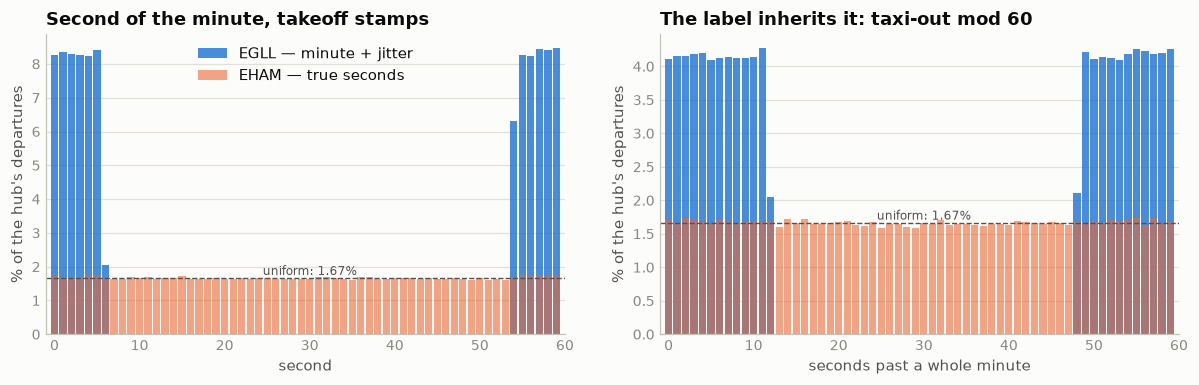

a label built from two jittered stamps is a whole minute ± 12 s, uniform: sd 6.9 s of pure noise

and no bias rides on it — mean taxi-out by whether the takeoff stamp is on the minute (jittered hubs):
 hub      n  on_minute  off_minute
EDDM 167275      810.0       811.0
EGLL 238818     1356.0      1354.0
LFPG 239091     1010.0      1013.0
LIRF 158737     1117.0      1117.0
LTFM 272169     1041.0      1043.0


In [45]:
# seconds-of-minute. A stamp with genuine second resolution lands within ±6 s of a whole
# minute 13 times in 60 (21.7%). Half the hubs do it 94% of the time.
BAND = "NOT BETWEEN 7 AND 53"
print("share of stamps within ±6 s of a whole minute (chance: 21.7%):")
print(con.sql(f"""
    SELECT hub,
           round(100.0*count(*) FILTER (src = 't' AND ph = 'DEP' AND m)/count(*) FILTER (src = 't' AND ph = 'DEP'), 1) "DEP takeoff",
           round(100.0*count(*) FILTER (src = 't' AND ph = 'DEP' AND b)/count(*) FILTER (src = 't' AND ph = 'DEP'), 1) "DEP off-block",
           round(100.0*count(*) FILTER (src = 't' AND ph = 'ARR' AND m)/count(*) FILTER (src = 't' AND ph = 'ARR'), 1) "ARR landing",
           round(100.0*count(*) FILTER (src = 't' AND ph = 'ARR' AND b)/count(*) FILTER (src = 't' AND ph = 'ARR'), 1) "ARR in-block",
           round(100.0*count(*) FILTER (src = 'r' AND ph = 'DEP' AND m)/count(*) FILTER (src = 'r' AND ph = 'DEP'), 1) "2026 DEP takeoff",
           round(100.0*count(*) FILTER (src = 'r' AND ph = 'ARR' AND b)/count(*) FILTER (src = 'r' AND ph = 'ARR'), 1) "2026 ARR in-block"
    FROM (SELECT src, PHASE_mvt ph, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
                 extract(second FROM MVT_TIME_UTC_mvt) {BAND} m,
                 extract(second FROM BLOCK_TIME_UTC_mvt) {BAND} b
          FROM (SELECT 't' src, * FROM {T} UNION ALL SELECT 'r' src, * FROM {R}))
    GROUP BY 1 ORDER BY 2 DESC, 3 DESC""").df().to_string(index=False))

# one jittered hub against one true-seconds hub: the takeoff stamp, and what the label inherits
sec = con.sql(f"""
    SELECT ADEP_mvt hub, extract(second FROM MVT_TIME_UTC_mvt)::INT s,
           100.0*count(*)/sum(count(*)) OVER (PARTITION BY ADEP_mvt) pct
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt IN ('EGLL', 'EHAM') GROUP BY 1, 2""").df()
rem = con.sql(f"""
    SELECT ADEP_mvt hub, TAXITIME_SEC_mvt % 60 r, 100.0*count(*)/sum(count(*)) OVER (PARTITION BY ADEP_mvt) pct
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt IN ('EGLL', 'EHAM') GROUP BY 1, 2""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, d, col, ttl, xl in [(a1, sec, "s", "Second of the minute, takeoff stamps", "second"),
                            (a2, rem, "r", "The label inherits it: taxi-out mod 60", "seconds past a whole minute")]:
    for hub, c, lbl in [("EGLL", BLUE, "EGLL — minute + jitter"), ("EHAM", ORANGE, "EHAM — true seconds")]:
        g = d[d.hub == hub].set_index(col).pct.reindex(range(60), fill_value=0)
        ax.bar(g.index, g.values, width=0.85, color=c, alpha=0.85 if hub == "EGLL" else 0.6, label=lbl)
    ax.axhline(100/60, color=INK2, lw=0.9, ls="--")
    ax.text(30, 100/60, "uniform: 1.67%", fontsize=8, color=INK2, ha="center", va="bottom")
    ax.set_title(ttl)
    ax.set_xlabel(xl)
    ax.set_ylabel("% of the hub's departures")
    ax.set_xlim(-1, 60)
    style(ax)
a1.legend(loc="upper center")
fig.tight_layout(w_pad=2.5)
plt.show()

print(f"a label built from two jittered stamps is a whole minute ± 12 s, uniform: sd {24/np.sqrt(12):.1f} s of pure noise")
print("\nand no bias rides on it — mean taxi-out by whether the takeoff stamp is on the minute (jittered hubs):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n,
           round(avg(TAXITIME_SEC_mvt) FILTER (extract(second FROM MVT_TIME_UTC_mvt) = 0)) on_minute,
           round(avg(TAXITIME_SEC_mvt) FILTER (extract(second FROM MVT_TIME_UTC_mvt) != 0)) off_minute
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
      AND ADEP_mvt IN ('EDDM', 'EGLL', 'LFPG', 'LIRF', 'LTFM')
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

hours ahead of UTC in the two ranking months:
 jan  jul                                    hubs
 3.0  3.0                                    LTFM
 1.0  2.0 EDDF EDDM EHAM LEBL LEMD LFPG LIRF LSZH
 0.0  1.0                                    EGLL

holdout RMSE (s) from group means:


                        fit Jan–Oct → Nov+Dec  fit Feb–Jun+Aug–Dec → Jan+Jul
airport                                 357.3                          376.2
+ UTC hour                              353.2                          368.6
+ local hour                            351.5                          368.2
+ local hour × weekday                  351.8                          367.8


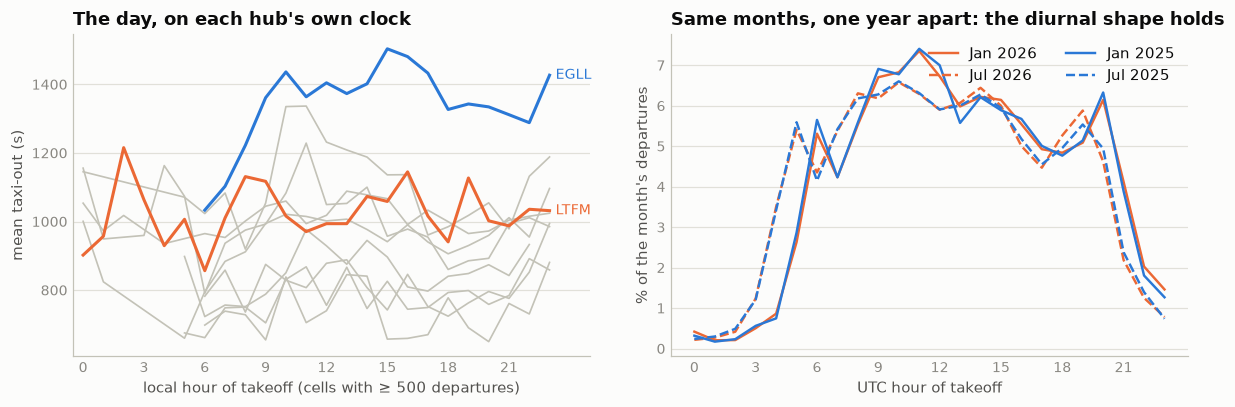

In [46]:
# the calendar. Nine hubs move their clocks between January and July; Istanbul does not.
TZ = """CASE hub WHEN 'LTFM' THEN 'Europe/Istanbul' WHEN 'EGLL' THEN 'Europe/London'
             WHEN 'LEMD' THEN 'Europe/Madrid'    WHEN 'LEBL' THEN 'Europe/Madrid'
             WHEN 'EDDF' THEN 'Europe/Berlin'    WHEN 'EDDM' THEN 'Europe/Berlin'
             WHEN 'EHAM' THEN 'Europe/Amsterdam' WHEN 'LFPG' THEN 'Europe/Paris'
             WHEN 'LIRF' THEN 'Europe/Rome'      WHEN 'LSZH' THEN 'Europe/Zurich' END"""
con.sql(f"""
    CREATE OR REPLACE TABLE dep_clock AS
    SELECT ds, hub, t, taxi, hour(t) h_utc, hour(tl) h_loc, dayofweek(tl) dow_loc, month(t) mon
    FROM (SELECT *, timezone({TZ}, t) tl
          FROM (SELECT 'training' ds, ADEP_mvt hub, MVT_TIME_UTC_mvt t, TAXITIME_SEC_mvt taxi
                FROM {T} WHERE PHASE_mvt = 'DEP'
                UNION ALL
                SELECT 'ranking', ADEP_mvt, MVT_TIME_UTC_mvt, NULL FROM {R} WHERE PHASE_mvt = 'DEP'))""")
print("hours ahead of UTC in the two ranking months:")
print(con.sql(f"""
    SELECT epoch(timezone({TZ}, TIMESTAMPTZ '2026-01-15 12:00:00+00') - TIMESTAMP '2026-01-15 12:00:00')/3600 jan,
           epoch(timezone({TZ}, TIMESTAMPTZ '2026-07-15 12:00:00+00') - TIMESTAMP '2026-07-15 12:00:00')/3600 jul,
           string_agg(hub, ' ' ORDER BY hub) hubs
    FROM (SELECT DISTINCT hub FROM dep_clock) GROUP BY 1, 2 ORDER BY 1 DESC""").df().to_string(index=False))

# how much does the hour buy, and on which clock? §7's recipe — group means, support ≥ 30 or the
# coarser rung — scored on the pipeline's Nov+Dec holdout and on a Jan+Jul 2025 holdout shaped
# like the ranking file
def hour_ladder(fit, val):
    out = {}
    for name, keys in [("airport", "hub"), ("+ UTC hour", "hub, h_utc"), ("+ local hour", "hub, h_loc"),
                       ("+ local hour × weekday", "hub, h_loc, dow_loc")]:
        out[name] = con.sql(f"""
            WITH f AS (SELECT {keys}, avg(taxi) m, count(*) c FROM dep_clock
                       WHERE ds = 'training' AND taxi BETWEEN 1 AND 3600 AND {fit} GROUP BY ALL),
                 h AS (SELECT hub, avg(taxi) m FROM dep_clock
                       WHERE ds = 'training' AND taxi BETWEEN 1 AND 3600 AND {fit} GROUP BY 1)
            SELECT sqrt(avg((v.taxi - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
            FROM (SELECT * FROM dep_clock WHERE ds = 'training' AND taxi BETWEEN 1 AND 3600 AND {val}) v
            LEFT JOIN f USING ({keys}) JOIN h USING (hub)""").fetchone()[0]
    return pd.Series(out)

print("\nholdout RMSE (s) from group means:")
print(pd.DataFrame({"fit Jan–Oct → Nov+Dec": hour_ladder("mon <= 10", "mon >= 11"),
                    "fit Feb–Jun+Aug–Dec → Jan+Jul": hour_ladder("mon NOT IN (1, 7)", "mon IN (1, 7)")})
      .round(1).to_string())

prof = con.sql("""
    SELECT hub, h_loc, avg(taxi) m, count(*) n FROM dep_clock
    WHERE ds = 'training' AND taxi BETWEEN 1 AND 3600 GROUP BY 1, 2 HAVING count(*) >= 500 ORDER BY 1, 2""").df()
shape = con.sql("""
    SELECT h_utc, ds, mon, 100.0*count(*)/sum(count(*)) OVER (PARTITION BY ds, mon) pct
    FROM dep_clock WHERE mon IN (1, 7) GROUP BY 1, 2, 3 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
HI = {"EGLL": BLUE, "LTFM": ORANGE}
for hub, g in prof.groupby("hub"):
    c = HI.get(hub, BASELINE)
    a1.plot(g.h_loc, g.m, color=c, lw=2.0 if hub in HI else 1.1, zorder=3 if hub in HI else 1)
    if hub in HI:
        a1.text(g.h_loc.iloc[-1] + 0.3, g.m.iloc[-1], hub, fontsize=9, va="center", color=c)
a1.set_xticks(range(0, 24, 3))
a1.set_xlim(-0.5, 25)
a1.set_title("The day, on each hub's own clock")
a1.set_xlabel("local hour of takeoff (cells with ≥ 500 departures)")
a1.set_ylabel("mean taxi-out (s)")
style(a1)

for (ds, mon), g in shape.groupby(["ds", "mon"]):
    a2.plot(g.h_utc, g.pct, color=BLUE if ds == "training" else ORANGE, ls="-" if mon == 1 else "--",
            lw=1.6, label=f"{'Jan' if mon == 1 else 'Jul'} {2025 if ds == 'training' else 2026}")
a2.set_xticks(range(0, 24, 3))
a2.set_title("Same months, one year apart: the diurnal shape holds")
a2.set_xlabel("UTC hour of takeoff")
a2.set_ylabel("% of the month's departures")
a2.legend(loc="upper right", ncols=2)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

month by month — share of the year's rows and of its squared error about the hub mean:


 m      n  pct_rows  mean_clean  sd_clean  sd_raw  pct_sse_clean  pct_sse_raw
 1 153706       7.4       985.0     416.0   605.0            9.2          9.5
 2 143732       6.9       981.0     416.0   628.0            8.5          9.5
 3 164449       7.9       967.0     371.0   462.0            7.2          5.5
 4 175288       8.4       967.0     358.0   436.0            7.2          5.2
 5 185202       8.9       981.0     373.0   469.0            8.1          6.3
 6 183142       8.8       962.0     377.0   555.0            7.9          8.9
 7 190713       9.1      1006.0     413.0   745.0           10.2         17.6
 8 191182       9.2       984.0     384.0   534.0            8.7          8.6
 9 183950       8.8       980.0     382.0   560.0            8.1          9.1
10 185674       8.9       985.0     383.0   437.0            8.2          5.1
11 162332       7.8       990.0     393.0   532.0            8.2          7.5
12 165677       7.9       987.0     392.0   515.0            8.5

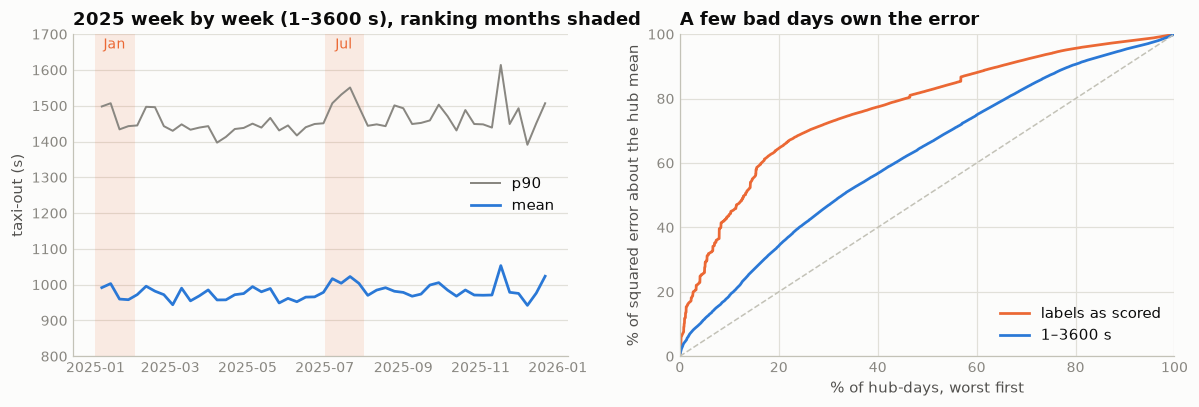

In [47]:
# the year. Two views of every month: the label as scored (raw), and the label with the corrupt
# rows of VALIDATION/FINDINGS.md set aside (1–3600 s), so the calendar's own weather shows through.
print("month by month — share of the year's rows and of its squared error about the hub mean:")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt hub, month(MVT_TIME_UTC_mvt) m, TAXITIME_SEC_mvt::DOUBLE y
               FROM {T} WHERE PHASE_mvt = 'DEP'),
         a AS (SELECT hub, avg(y) am, avg(y) FILTER (y BETWEEN 1 AND 3600) ac FROM d GROUP BY 1)
    SELECT m, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct_rows,
           round(avg(y) FILTER (y BETWEEN 1 AND 3600)) mean_clean,
           round(stddev(y) FILTER (y BETWEEN 1 AND 3600)) sd_clean, round(stddev(y)) sd_raw,
           round(100.0*sum((y - ac)^2) FILTER (y BETWEEN 1 AND 3600)
                 / sum(sum((y - ac)^2) FILTER (y BETWEEN 1 AND 3600)) OVER (), 1) pct_sse_clean,
           round(100.0*sum((y - am)^2)/sum(sum((y - am)^2)) OVER (), 1) pct_sse_raw
    FROM d JOIN a USING (hub) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

# how much of the error lives in a few bad days?
con.sql(f"""
    CREATE OR REPLACE TABLE hub_days AS
    WITH d AS (SELECT ADEP_mvt hub, MVT_TIME_UTC_mvt::DATE dy, TAXITIME_SEC_mvt::DOUBLE y
               FROM {T} WHERE PHASE_mvt = 'DEP'),
         a AS (SELECT hub, avg(y) am, avg(y) FILTER (y BETWEEN 1 AND 3600) ac FROM d GROUP BY 1)
    SELECT hub, dy, count(*) n, avg(y) mean_raw, sum((y - am)^2) sse_raw,
           count(*) FILTER (y BETWEEN 1 AND 3600) n_clean,
           avg(y) FILTER (y BETWEEN 1 AND 3600) mean_clean,
           sum((y - ac)^2) FILTER (y BETWEEN 1 AND 3600) sse_clean
    FROM d JOIN a USING (hub) GROUP BY 1, 2""")
lor = {}
for lbl in ("raw", "clean"):
    lor[lbl] = con.sql(f"""
        SELECT 100.0*row_number() OVER (ORDER BY mean_{lbl} DESC)/count(*) OVER () pct_days,
               100.0*sum(sse_{lbl}) OVER (ORDER BY mean_{lbl} DESC)/sum(sse_{lbl}) OVER () pct_sse
        FROM hub_days ORDER BY 1""").df()
    at = lambda p: lor[lbl].loc[lor[lbl].pct_days <= p, "pct_sse"].max()
    print(f"\n{lbl:5s} labels: worst 1% of hub-days carry {at(1):.1f}% of the squared error, "
          f"worst 5% carry {at(5):.1f}%, worst 10% carry {at(10):.1f}%")

print("\nthe worst days on clean labels (≥ 200 departures) — operations, not data errors:")
print(con.sql("""
    SELECT hub, dy, dayname(dy) weekday, n_clean n, round(mean_clean) mean_taxi_out
    FROM hub_days WHERE n_clean >= 200 ORDER BY mean_clean DESC LIMIT 8""").df().to_string(index=False))

wk = con.sql(f"""
    SELECT date_trunc('week', MVT_TIME_UTC_mvt)::DATE wk, count(*) n,
           avg(TAXITIME_SEC_mvt) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600) mean_clean,
           quantile_cont(TAXITIME_SEC_mvt, 0.9) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600) p90_clean
    FROM {T} WHERE PHASE_mvt = 'DEP'
      AND MVT_TIME_UTC_mvt BETWEEN TIMESTAMPTZ '2025-01-06' AND TIMESTAMPTZ '2025-12-29'
    GROUP BY 1 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for lo, hi in [("2025-01-01", "2025-02-01"), ("2025-07-01", "2025-08-01")]:
    a1.axvspan(pd.Timestamp(lo), pd.Timestamp(hi), color=ORANGE, alpha=0.12, lw=0)
a1.plot(pd.to_datetime(wk.wk), wk.p90_clean, color=MUTED, lw=1.3, label="p90")
a1.plot(pd.to_datetime(wk.wk), wk.mean_clean, color=BLUE, lw=1.8, label="mean")
a1.text(pd.Timestamp("2025-01-16"), 1660, "Jan", ha="center", fontsize=9, color=ORANGE)
a1.text(pd.Timestamp("2025-07-16"), 1660, "Jul", ha="center", fontsize=9, color=ORANGE)
a1.set_title("2025 week by week (1–3600 s), ranking months shaded")
a1.set_ylabel("taxi-out (s)")
a1.set_ylim(800, 1700)
a1.legend(loc="center right")
style(a1)
for lbl, c, nm in [("raw", ORANGE, "labels as scored"), ("clean", BLUE, "1–3600 s")]:
    a2.plot(lor[lbl].pct_days, lor[lbl].pct_sse, color=c, lw=1.8, label=nm)
a2.plot([0, 100], [0, 100], color=BASELINE, lw=1, ls="--")
a2.set_xlim(0, 100)
a2.set_ylim(0, 100)
a2.set_title("A few bad days own the error")
a2.set_xlabel("% of hub-days, worst first")
a2.set_ylabel("% of squared error about the hub mean")
a2.legend(loc="lower right")
style(a2, x_grid=True)
fig.tight_layout(w_pad=2.5)
plt.show()

departure count in the window, on top of airport × runway × anchor — scored on 324,631 Nov+Dec departures:
                  window  corr  base_rmse  with_rmse  gain_s
             trailing_15 0.087    283.642    279.600   4.042
             centered_15 0.098    283.642    278.384   5.258
              leading_15 0.091    283.642    279.314   4.327
             trailing_30 0.097    283.642    279.687   3.954
             centered_30 0.098    283.642    278.127   5.514
              leading_30 0.073    283.642    279.981   3.661
             trailing_60 0.116    283.642    279.786   3.856
             centered_60 0.095    283.642    278.528   5.114
              leading_60 0.059    283.642    280.975   2.667
            trailing_120 0.131    283.642    280.466   3.175
            centered_120 0.103    283.642    279.301   4.341
             leading_120 0.070    283.642    281.028   2.614
       queue_at_pushback 0.296    283.642    279.941   3.701
takeoffs_before_pushback 0.110    283.6

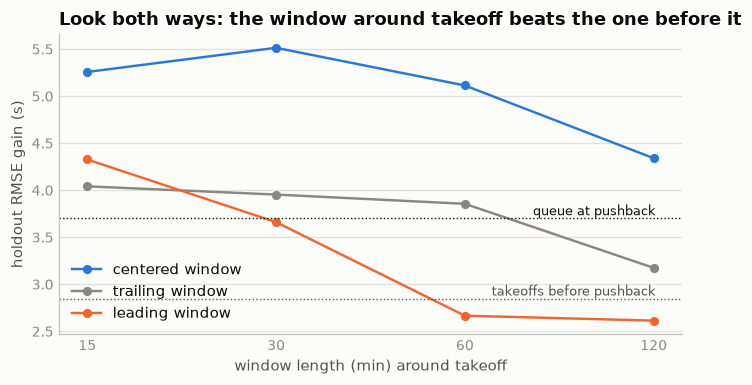

In [48]:
# the window. §7 counted departures in the 60 minutes *before* takeoff and left the shape open.
# Every takeoff time in the file is known at prediction time — before and after ours — so the
# window may look either way. And the off-block anchor offers a second place to stand: at pushback.
# Same honest ladder as §7: airport × runway × AOBT_3-anchor bins, fitted Jan–Oct, scored Nov+Dec.
con.sql(f"""
    CREATE OR REPLACE TABLE dep_stream AS
    SELECT MVT_ID_mvt id, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
           PHASE_mvt ph, MVT_TIME_UTC_mvt t, RUNWAY_mvt rwy, AOBT_3_flt aobt3,
           CASE WHEN PHASE_mvt = 'DEP' THEN TAXITIME_SEC_mvt END taxi_out
    FROM {T}""")
FRAMES = {}
for W in (15, 30, 60, 120):
    FRAMES[f"trailing_{W}"] = f"RANGE BETWEEN INTERVAL {W} MINUTE PRECEDING AND CURRENT ROW"
    FRAMES[f"centered_{W}"] = (f"RANGE BETWEEN INTERVAL {W // 2} MINUTE PRECEDING "
                               f"AND INTERVAL {W // 2} MINUTE FOLLOWING")
    FRAMES[f"leading_{W}"] = f"RANGE BETWEEN CURRENT ROW AND INTERVAL {W} MINUTE FOLLOWING"
con.sql(f"""
    CREATE OR REPLACE TABLE win AS
    SELECT *, {', '.join(f"sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER (PARTITION BY hub ORDER BY t {fr}) {k}"
                         for k, fr in FRAMES.items())}
    FROM dep_stream""")

# two windows anchored at pushback (AOBT_3) instead of takeoff:
#   queue_at_pushback  — departures that had pushed back but not yet taken off when we pushed back
#   takeoffs_before_pushback — takeoffs in the 60 min up to our pushback (§7's window, moved back)
con.sql("""
    CREATE OR REPLACE TABLE at_push AS
    WITH ev AS (SELECT hub, id, aobt3 ts, 1 d FROM dep_stream WHERE ph = 'DEP' AND aobt3 IS NOT NULL
                UNION ALL
                SELECT hub, id, t, -1 FROM dep_stream WHERE ph = 'DEP' AND aobt3 IS NOT NULL),
         q AS (SELECT id, d, sum(d) OVER (PARTITION BY hub ORDER BY ts, d
                                          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) - 1 n
               FROM ev),
         tk AS (SELECT hub, t ts, row_number() OVER (PARTITION BY hub ORDER BY t) cum
                FROM dep_stream WHERE ph = 'DEP'),
         p AS (SELECT id, hub, aobt3 FROM dep_stream WHERE ph = 'DEP' AND aobt3 IS NOT NULL),
         hi AS (SELECT p.id, a.cum FROM p ASOF LEFT JOIN tk a ON p.hub = a.hub AND p.aobt3 >= a.ts),
         lo AS (SELECT p.id, b.cum FROM p ASOF LEFT JOIN tk b
                ON p.hub = b.hub AND p.aobt3 - INTERVAL 60 MINUTE >= b.ts)
    SELECT q.id, q.n queue_at_pushback, coalesce(hi.cum, 0) - coalesce(lo.cum, 0) takeoffs_before_pushback
    FROM q JOIN hi USING (id) JOIN lo USING (id) WHERE q.d = 1""")

con.sql("""
    CREATE OR REPLACE TABLE wlad AS
    SELECT w.*, p.queue_at_pushback, p.takeoffs_before_pushback,
           epoch(w.t - w.aobt3) anchor, (w.t >= TIMESTAMPTZ '2025-11-01') is_val
    FROM win w JOIN at_push p USING (id)
    WHERE w.ph = 'DEP' AND w.taxi_out BETWEEN 1 AND 3600 AND w.rwy IS NOT NULL""")

MIN_N = 30
def ladder_gain(col):
    """Holdout RMSE without / with the context column on top of airport × runway × anchor."""
    con.sql(f"""
        CREATE OR REPLACE TABLE wb AS
        WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                             quantile_cont({col}, [0.2,0.4,0.6,0.8]) qx
                      FROM wlad WHERE NOT is_val GROUP BY 1)
        SELECT hub, rwy, taxi_out::DOUBLE y, is_val,
               list_count(list_filter(qa, x -> x <= anchor)) q_anc,
               list_count(list_filter(qx, x -> x <= {col})) q_x
        FROM wlad JOIN cuts USING (hub)""")
    for i, keys in enumerate(["hub", "hub, rwy", "hub, rwy, q_anc", "hub, rwy, q_anc, q_x"]):
        con.sql(f"CREATE OR REPLACE TABLE wr{i} AS SELECT {keys}, avg(y) m, count(*) c "
                f"FROM wb WHERE NOT is_val GROUP BY ALL")
    return con.sql(f"""
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN wr2.c >= {MIN_N} THEN wr2.m END,
                                        CASE WHEN wr1.c >= {MIN_N} THEN wr1.m END, wr0.m))^2)) base,
               sqrt(avg((v.y - coalesce(CASE WHEN wr3.c >= {MIN_N} THEN wr3.m END,
                                        CASE WHEN wr2.c >= {MIN_N} THEN wr2.m END,
                                        CASE WHEN wr1.c >= {MIN_N} THEN wr1.m END, wr0.m))^2)) with_ctx
        FROM wb v LEFT JOIN wr3 USING (hub, rwy, q_anc, q_x) LEFT JOIN wr2 USING (hub, rwy, q_anc)
        LEFT JOIN wr1 USING (hub, rwy) LEFT JOIN wr0 USING (hub) WHERE v.is_val""").fetchone()

rows = []
for col in list(FRAMES) + ["queue_at_pushback", "takeoffs_before_pushback"]:
    base, with_ctx = ladder_gain(col)
    r = con.sql(f"SELECT corr(taxi_out, {col}) FROM wlad").fetchone()[0]
    rows.append((col, r, base, with_ctx, base - with_ctx))
res = pd.DataFrame(rows, columns=["window", "corr", "base_rmse", "with_rmse", "gain_s"])
n_val = con.sql("SELECT count(*) FROM wlad WHERE is_val").fetchone()[0]
print(f"departure count in the window, on top of airport × runway × anchor — scored on {n_val:,} Nov+Dec departures:")
print(res.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.4, 3.6))
grid = res[res.window.isin(FRAMES)].assign(kind=lambda d: d.window.str.split("_").str[0],
                                                W=lambda d: d.window.str.split("_").str[1].astype(int))
for kind, c in [("centered", BLUE), ("trailing", MUTED), ("leading", ORANGE)]:
    g = grid[grid.kind == kind]
    ax.plot(g.W, g.gain_s, "o-", color=c, ms=5, lw=1.6, label=f"{kind} window")
for nm, c, lbl in [("queue_at_pushback", INK, "queue at pushback"),
                   ("takeoffs_before_pushback", INK2, "takeoffs before pushback")]:
    v = res.loc[res.window == nm, "gain_s"].iloc[0]
    ax.axhline(v, color=c, lw=0.9, ls=":")
    ax.text(121, v, lbl, fontsize=8.5, color=c, va="bottom", ha="right")
ax.set_xscale("log", base=2)
ax.set_xticks([15, 30, 60, 120], ["15", "30", "60", "120"])
ax.set_xlabel("window length (min) around takeoff")
ax.set_ylabel("holdout RMSE gain (s)")
ax.set_title("Look both ways: the window around takeoff beats the one before it")
ax.legend(loc="lower left")
style(ax)
fig.tight_layout()
plt.show()

                                                                       feature        kind  n / levels  pearson_r  spearman_ρ     η
                                          epoch seconds of takeoff — the trend     numeric     2080533      0.012       0.015      
                                                              hour of day, UTC categorical          24                        0.123
                                            hour of day, the hub's local clock categorical          24                        0.124
                                                                weekday, local categorical           7                        0.023
                                                                         month categorical          12                        0.030
departures within ±15 min of takeoff — §8's window (rows with runway + anchor)     numeric     2059401      0.098       0.127      


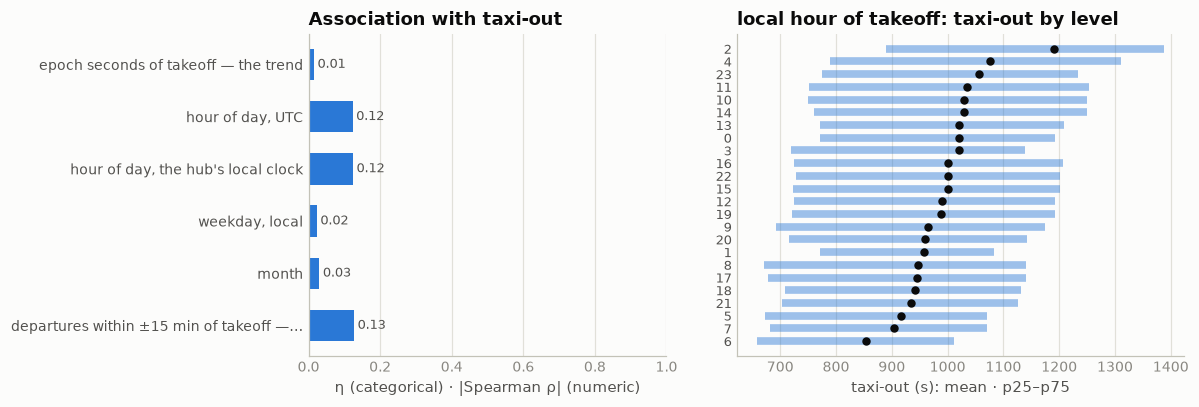

In [49]:
# correlation with the target: the trend, the calendar on both clocks, and §8's window
LOCAL = f"timezone({TZ.replace('CASE hub', 'CASE ADEP_mvt')}, MVT_TIME_UTC_mvt)"
a = target_assoc([("epoch seconds of takeoff — the trend", "num", "epoch(MVT_TIME_UTC_mvt)"),
              ("hour of day, UTC", "cat", "hour(MVT_TIME_UTC_mvt)"),
              ("hour of day, the hub's local clock", "cat", f"hour({LOCAL})"),
              ("weekday, local", "cat", f"dayofweek({LOCAL})"),
              ("month", "cat", "month(MVT_TIME_UTC_mvt)"),
              ("departures within ±15 min of takeoff — §8's window (rows with runway + anchor)", "num",
               "centered_30", 1, "wlad", "taxi_out")])
assoc_chart(a, f"hour({LOCAL})", title="local hour of takeoff")

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Never null, second resolution, and the file's own clock** | 4,857,331 rows across both files and phases, zero missing. Training runs 1 Jan 00:01 to 31 Dec 23:57 2025; ranking is two closed blocks, all of January and all of July 2026. Six rows stamped 23:59:56–59 sit in the *next* month's file; block time disagrees with the file month on 49 rows, the schedule on 251 | this column carves the year into monthly files, on a minute-rounded copy |
| **Half the target** | takeoff − off-block equals the label to the second on all 2,085,047 training departures — sign included: 369 of them are stamped off-block *after* takeoff and carry a negative label. In-block − landing does the same on every arrival but one (an EDDM arrival with neither block time nor label) | nothing is rounded and nothing is estimated: we are given one endpoint of the interval we are asked for. Any feature that reconstructs the other endpoint from the movement side *is* the target. The 369 negative labels are §9's to explain and the target's section to judge |
| **Five hubs run on a jittered minute clock** | at EDDM, EGLL, LFPG, LIRF and LTFM *every* stamp — takeoff, landing, off-block, in-block, 2025 and 2026 — lands within ±6 s of a whole minute, spread evenly over those thirteen seconds. EDDF, EHAM and LSZH keep true seconds throughout. LEMD and LEBL split the difference: runway times at true seconds, block times on the jittered minute. That is the whole story behind the 5.1% of stamps exactly on :00 — one in twelve at the jittered hubs, one in sixty elsewhere | the label inherits it: at the five hubs taxi-out is a whole minute ± 12 s, uniform, which is 6.9 s of pure noise. Against a 280 s RMSE it costs 0.08 s, and it carries no bias — on-minute and off-minute stamps give the same mean taxi-out within 3 s at every hub. Nobody should chase sub-minute structure at Heathrow; not worth a feature |
| **The hour is worth 4–8 s, and the local clock is the right one** | group means on top of the airport: UTC hour takes the Nov+Dec holdout from 357.3 s to 353.2 s, the hub's local hour to **351.5 s**; on a Jan+Jul 2025 holdout shaped like the ranking file, 376.2 → 368.6 → 368.2 s. Weekday adds nothing on either (967–996 s across the seven days) | the local clock wins for a mechanical reason: nine hubs are an hour further from UTC in July than in January, Istanbul is not, so a UTC hour bin fitted across the year pools two local hours at nine airports. The pipeline's `hour` is UTC today; switching it to the hub's local hour is free |
| **2026 is 2025's twin, hour for hour** | the share of each month's departures per UTC hour in Jan 2026 tracks Jan 2025 within a few tenths of a percent, and July likewise — including the earlier morning ramp that daylight saving puts into July's UTC profile. Volume matches too: 4,926 vs 4,958 departures a day in January, 6,197 vs 6,152 in July | nothing about the calendar shifted between the files |
| **The calendar's mean is flat; its error is not** | monthly mean taxi-out on 1–3600 s sits between 962 s and 1,006 s all year. On clean labels the two ranking months are the heaviest per row — January carries 9.2% of the year's squared error on 7.4% of its rows, July 10.2% on 9.1% — and on labels as scored July alone carries **17.6%**, the corrupt Fiumicino rows of `VALIDATION/FINDINGS.md` (§10a reads them off the schedule) | the ranking file was cut from the two hardest months of the year |
| **RMSE is a bad-day metric** | sorting hub-days by their mean taxi-out, the worst 5% of days carry 26.1% of the squared error as scored and 11.5% on clean labels; the worst 10% carry 44.0% and 18.8%. The clean list is operations, not data: LTFM's 19–23 February (1,830–1,994 s a day, consistent with the snow that week), Christmas Eve at EDDM, 17 January at LFPG, the first of September at EGLL | days like these are on no calendar feature — but they are in the file on the day, both phases, which is what the rolling state is for |
| **Look both ways** | counting departures around our takeoff on the §7 ladder, over airport × runway × anchor (283.6 s), the window centred on the takeoff beats the one that ends there at every length: 15 min −5.3 s, **30 min −5.5 s**, 60 min −5.1 s, against −3.9 s for §7's trailing hour and −2.7 s for the hour after it. Two hours is too long in every direction | every takeoff in the ranking file is known, before and after ours, so the centred count is as legal as the trailing one; it reads the runway's discharge rate through our slot rather than the queue that had already cleared |
| The two windows anchored at *pushback* are instructive | the queue when we pushed back — departures off-block and not yet airborne — is by far the most correlated single number (0.30 against ≤ 0.13 for any takeoff window) yet gains only 3.7 s on the ladder. Takeoffs in the hour before pushback gain 2.8 s, the least of all | the anchor bins already hold most of the queue: `MVT_TIME − AOBT_3` is our own taxi with an error, and that error *is* the queue. And by the time we join the queue, last hour's runway is stale |

**On representation.** Convert to epoch seconds to *compute* — every difference against an
off-block clock and every window count is unix arithmetic under the hood — but never hand the
epoch itself to the model. It is §1's ID problem again: every ranking stamp is larger than every
training stamp, so a tree would learn 2025's seasonality as a function of a counter and
extrapolate into a range it has never seen (and it would break adversarial validation on its
own). What the model sees are the pieces that repeat — local hour, weekday, month — and the
differences.

**Use in modeling.** (1) Hour of day on the hub's local clock, weekday optional. (2) Rolling
airport state anchored on this column, **centred, 15–30 minutes**, counting both phases, kept
per hub so the model can learn each airport's sign (§7a). (3) The queue at pushback as a
separate feature from the `AOBT_3` section, where the anchor lives. The two month-blocks of the
ranking file open and close cold — the first and last quarter-hour of each — which a centred
window feels at both ends; at 30 departures a seam it is nothing.

## 9 · `BLOCK_TIME_UTC_mvt` — the target's hidden endpoint

The block time: **off-block** on departure rows — the moment the aircraft leaves its stand — and
**in-block** on arrival rows, the moment it parks. §8's column is the other end of the same
interval: taxi-out is takeoff − off-block, to the second, on every training departure. This is the
half the organizers hide — the only column, with the label itself, that is blank on the 344,841
rows we predict — so the section is not about the column's distribution but about **where the hidden
endpoint sits relative to everything that stays visible**: the five off-block clocks of the flight
plan and the schedule, and the arrival half's in-block times, which do survive.

| step | question | what came out |
|---|---|---|
| **census** | present where, and where not; the one gap; which side of the runway stamp it falls | the only column blanked at prediction time; one arrival without it; 369 departures stamped off-block *after* takeoff |
| **the labels near zero** | one event seen by two sensors, or a stamp that collapsed onto the other? | Zurich's helipad fleet lifts off where it parks — genuine; ~290 airliners a year at LSZH, LFPG and LEBL carry a collapsed stamp the plan's anchor exposes; both persist in 2026's arrivals |
| **the hidden endpoint from where we stand** | how far is it from each visible off-block clock, and what does each buy as a locator of the target? | `AOBT_3` is nearest (median 52 s, 75% within 5 min) but its offset is per-hub, −117 s to +297 s, and seasonal; `EOBT_1` rivals it on the ladder, and the two together beat either by 30 s |
| **the arrival side** | the in-block clock survives at prediction time — is it a feature? | no: 0.91 correlated with the landing clock and nothing on top of it; and any window over *departures'* off-blocks is a leak |


In [4]:
# census by file × phase — present on every row except the ones we predict; the identity with the label is §8's
print("BLOCK_TIME_UTC_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (BLOCK_TIME_UTC_mvt IS NULL) n_null,
           strftime(min(BLOCK_TIME_UTC_mvt), '%Y-%m-%d %H:%M:%S') first_stamp,
           strftime(max(BLOCK_TIME_UTC_mvt), '%Y-%m-%d %H:%M:%S') last_stamp,
           round(100.0*count(*) FILTER (extract(second FROM BLOCK_TIME_UTC_mvt) = 0)
                 /count(BLOCK_TIME_UTC_mvt), 2) pct_on_minute
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe one arrival with no in-block time:")
print(con.sql(f"""
    SELECT ADES_mvt hub, ADEP_mvt origin, FLIGHT_mvt, strftime(MVT_TIME_UTC_mvt, '%Y-%m-%d %H:%M:%S') landing,
           TAXITIME_SEC_mvt taxi_in, RUNWAY_mvt rwy, STAND_mvt stand, (FLIGHT_ID_mvt IS NOT NULL) AS matched_plan,
           strftime(ARVT_3_flt, '%H:%M:%S') plan_in_block
    FROM {T} WHERE PHASE_mvt = 'ARR' AND BLOCK_TIME_UTC_mvt IS NULL""").df().to_string(index=False))

print("\nwhich side of the runway stamp the block stamp falls (training) — and how often the two nearly coincide:")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n,
           count(*) FILTER (BLOCK_TIME_UTC_mvt < MVT_TIME_UTC_mvt) block_before_mvt,
           count(*) FILTER (BLOCK_TIME_UTC_mvt = MVT_TIME_UTC_mvt) block_equal_mvt,
           count(*) FILTER (BLOCK_TIME_UTC_mvt > MVT_TIME_UTC_mvt) block_after_mvt,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN -12 AND 12) label_within_12s
    FROM {T} GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))


BLOCK_TIME_UTC_mvt by file × phase:
     src  ph       n  n_null         first_stamp          last_stamp  pct_on_minute
training ARR 2082750       1 2025-01-01 00:08:55 2025-12-31 23:32:58           6.40
training DEP 2085047       0 2024-12-31 23:38:00 2025-12-31 23:41:59           6.40
 ranking ARR  344693       0 2026-01-01 00:14:57 2026-07-31 23:53:00           6.47
 ranking DEP  344841  344841                 NaN                 NaN            NaN

the one arrival with no in-block time:
 hub origin FLIGHT_mvt             landing  taxi_in rwy stand  matched_plan plan_in_block
EDDM   LBSF     DLH1EK 2025-11-04 19:35:30     <NA>  NA  None          True      20:00:10

which side of the runway stamp the block stamp falls (training) — and how often the two nearly coincide:
 ph       n  block_before_mvt  block_equal_mvt  block_after_mvt  label_within_12s
DEP 2085047           2084659               19              369               758
ARR 2082750               220               16        

In [5]:
# the labels within ±12 s of zero: one event seen twice, or a stamp that collapsed onto the other? Split by fleet,
# with the plan's own off-block AOBT_3 as the referee for what the taxi really was
NEAR0 = (f"(SELECT *, CASE WHEN AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V' THEN 'rotorcraft / VFR' "
         f"ELSE 'IFR fixed-wing' END fleet FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN -12 AND 12)")
print("departures with a label within ±12 s of zero, by hub × fleet (training; groups of ≥ 5):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, fleet, count(*) n, count(*) FILTER (TAXITIME_SEC_mvt < 0) n_negative,
           count(AOBT_3_flt) with_anchor,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med_taxi_implied_by_aobt3,
           mode(AIRCRAFT_TYPE_mvt) typ, mode(STAND_mvt) stand, mode(RUNWAY_mvt) rwy
    FROM {NEAR0} GROUP BY 1, 2 HAVING count(*) >= 5 ORDER BY n DESC""").df().to_string(index=False))

print("\nLSZH's rotorcraft / VFR departures as a whole — where their labels sit:")
print(con.sql(f"""
    SELECT count(*) n, count(*) FILTER (TAXITIME_SEC_mvt BETWEEN -12 AND 12) within_12s,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN -12 AND 12 AND RUNWAY_mvt = 'H') within_12s_from_helipad_h,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN 13 AND 300) s13_300,
           count(*) FILTER (TAXITIME_SEC_mvt > 300) over_300s
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LSZH'
      AND (AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V')""").df().to_string(index=False))

print("\nvalue by value inside ±12 s — a copied stamp would pile up at 0; neither fleet does:")
print(con.sql(f"""
    SELECT TAXITIME_SEC_mvt s, count(*) FILTER (fleet = 'rotorcraft / VFR') rotorcraft_vfr,
           count(*) FILTER (fleet = 'IFR fixed-wing') ifr_fixed_wing
    FROM {NEAR0} GROUP BY 1 ORDER BY 1""").df().set_index("s").T.to_string())

print("\nthe same coincidence on arrivals (in-block within ±12 s of landing), per 10,000 — training vs ranking:")
print(con.sql(f"""
    SELECT ADES_mvt hub,
           round(1e4*count(*) FILTER (src = 't' AND TAXITIME_SEC_mvt BETWEEN -12 AND 12)/count(*) FILTER (src = 't'), 1) train_per_10k,
           round(1e4*count(*) FILTER (src = 'r' AND TAXITIME_SEC_mvt BETWEEN -12 AND 12)/count(*) FILTER (src = 'r'), 1) rank_per_10k,
           count(*) FILTER (src = 'r' AND TAXITIME_SEC_mvt BETWEEN -12 AND 12) rank_rows
    FROM (SELECT 't' src, * FROM {T} UNION ALL SELECT 'r', * FROM {R}) WHERE PHASE_mvt = 'ARR'
    GROUP BY 1 ORDER BY 2 DESC LIMIT 4""").df().to_string(index=False))


departures with a label within ±12 s of zero, by hub × fleet (training; groups of ≥ 5):


 hub            fleet   n  n_negative  with_anchor  med_taxi_implied_by_aobt3  typ stand rwy
LSZH rotorcraft / VFR 456         225            4                      509.0 AS50   HPW   H
LSZH   IFR fixed-wing 149          73          142                      907.0 C56X   GA6  28
LFPG   IFR fixed-wing 128          61          108                      959.0 B738   P73 26R
LEBL   IFR fixed-wing  12           5           12                      933.0 A320  143A 24L

LSZH's rotorcraft / VFR departures as a whole — where their labels sit:
   n  within_12s  within_12s_from_helipad_h  s13_300  over_300s
1141         456                        360       41        644

value by value inside ±12 s — a copied stamp would pile up at 0; neither fleet does:
s               -12  -11  -10  -9   -8   -7   -6   -5   -4   -3   -2   -1   0    1    2    3    4    5    6    7    8    9    10   11   12 
rotorcraft_vfr    4   29   20   16   15   12   35   16   18   17   18   26   10   11   28   17   27   24   1

hidden off-block minus each visible clock (seconds; positive = the airport logged the pushback later):


     clock  pct_present   med    p10    p90  pct_within_1min  pct_within_5min  pct_within_15min
  schedule       100.00 415.0 -242.0 2396.0              9.5             36.6              68.9
  LOBT_flt        98.98 252.0 -264.0 1136.0             11.3             44.2              84.1
  IOBT_flt        98.98 252.0 -246.0 1136.0             11.3             44.3              84.1
EOBT_1_flt        98.98 284.0 -126.0 1036.0             12.7             49.0              86.1
AOBT_3_flt        98.98  52.0 -306.0  363.0             21.1             74.8              97.7

the nearest clock, AOBT_3, per hub:


 hub      n    med    p25   p75  pct_within_5min  pct_block_after_aobt3
LIRF 158737 -117.0 -359.0  61.0             66.4                   34.4
LEBL 179699  -54.0 -179.0  65.0             81.7                   42.4
LSZH 134568  -33.0 -183.0  96.0             82.6                   43.1
LFPG 239091   -4.0 -181.0 123.0             74.0                   45.7
EDDM 167275   -2.0 -177.0 117.0             82.6                   47.4
LEMD 212242    2.0 -122.0 120.0             86.5                   51.3
EGLL 238818   55.0 -124.0 234.0             73.2                   54.8
EDDF 230068   88.0  -44.0 197.0             85.4                   68.0
EHAM 247866  107.0   -3.0 241.0             81.0                   74.2
LTFM 272169  297.0   58.0 479.0             44.5                   78.4



honest ladder on 327,485 Nov+Dec departures — airport mean 357.3 s; then airport × bins of (takeoff − clock):


     clock  raw gap as the prediction  airport × 20 bins  airport × 100 bins
  schedule                     2451.3              320.7               320.6
  LOBT_flt                      679.4              301.2               300.6
  IOBT_flt                      679.1              300.9               300.3
EOBT_1_flt                      626.7              290.1               289.2
AOBT_3_flt                      354.2              293.5               281.7


AOBT_3 (20 bins) × EOBT_1 (5 bins): 252.4 s — the two clocks are not the same information



median off-block − AOBT_3 by month (s) — all hubs, and the two ends of the per-hub range:
mon        1    2    3    4    5    6    7    8    9    10   11   12
all hubs   60   58   57   55   47   28    5   22   17   35   56   54
LTFM      355  355  360  298  295  244  234  240  243  294  304  296
LIRF      -59  -57  -65 -122 -123 -175 -178 -122 -119 -121   -5  -59


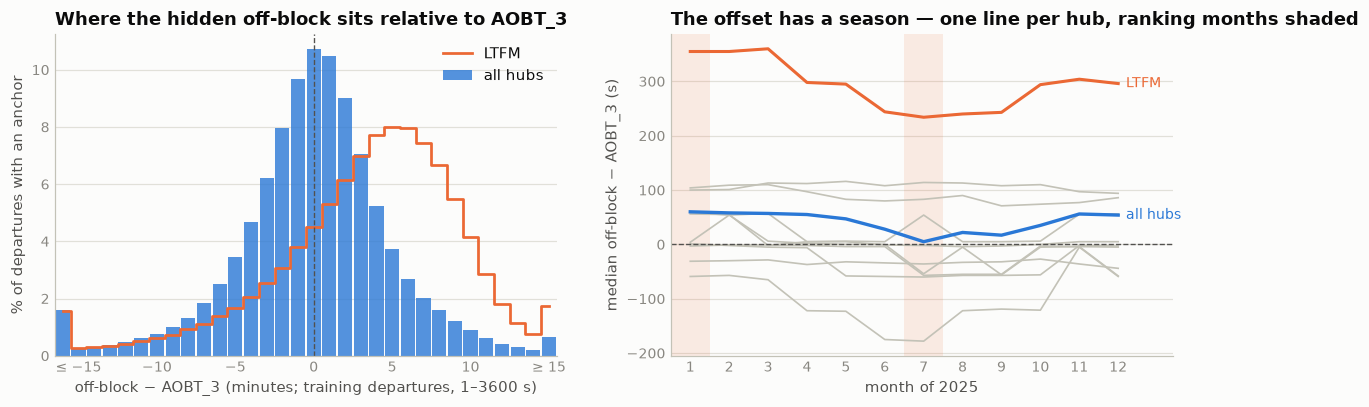

In [6]:
# the hidden off-block against the five visible off-block clocks, on the rows we model: how far each sits from it,
# and — honest ladder, fit Jan–Oct, score Nov+Dec — what each buys as a locator of the target
CLOCKS = [("schedule", "SCHED_TIME_UTC_mvt"), ("LOBT_flt", "LOBT_flt"), ("IOBT_flt", "IOBT_flt"),
          ("EOBT_1_flt", "EOBT_1_flt"), ("AOBT_3_flt", "AOBT_3_flt")]
print("hidden off-block minus each visible clock (seconds; positive = the airport logged the pushback later):")
print(pd.concat([con.sql(f"""
    SELECT '{name}' clock, round(100.0*count({col})/count(*), 2) pct_present,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - {col}), 0.5)) med,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - {col}), 0.10)) p10,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - {col}), 0.90)) p90,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - {col})) <= 60)/count({col}), 1) pct_within_1min,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - {col})) <= 300)/count({col}), 1) pct_within_5min,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - {col})) <= 900)/count({col}), 1) pct_within_15min
    FROM {TGT}""").df() for name, col in CLOCKS], ignore_index=True).to_string(index=False))

print("\nthe nearest clock, AOBT_3, per hub:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.25)) p25,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.75)) p75,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt)) <= 300)/count(AOBT_3_flt), 1) pct_within_5min,
           round(100.0*count(*) FILTER (BLOCK_TIME_UTC_mvt > AOBT_3_flt)/count(AOBT_3_flt), 1) pct_block_after_aobt3
    FROM {TGT} GROUP BY 1 ORDER BY med""").df().to_string(index=False))

# the ladder: airport → airport × quantile bins of (takeoff − clock); bins cut on Jan–Oct, cell support ≥ 30, else the coarser rung
con.sql(f"""
    CREATE OR REPLACE TABLE blk_gap AS
    SELECT ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           {', '.join(f'epoch(MVT_TIME_UTC_mvt - {col}) g_{i}' for i, (_, col) in enumerate(CLOCKS))}
    FROM {TGT}""")


def blk_ladder(*bins):
    """bins: (gap column, number of quantile bins), nested left to right on top of the airport mean."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}"
                     for k, (c, n) in enumerate(bins))
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}"
                    for k, (c, _) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE blk_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM blk_gap WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM blk_gap JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE blk_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM blk_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN blk_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN blk_r{k}.c >= 30 THEN blk_r{k}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2))
                       FROM blk_b v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM blk_gap WHERE is_val").fetchone()[0]
print(f"\nhonest ladder on {n_val:,} Nov+Dec departures — airport mean {blk_ladder():.1f} s; then airport × bins of (takeoff − clock):")
rows = []
for i, (name, _) in enumerate(CLOCKS):
    raw = con.sql(f"SELECT sqrt(avg((y - g_{i})^2)) FROM blk_gap WHERE is_val AND g_{i} IS NOT NULL").fetchone()[0]
    rows.append((name, raw, blk_ladder((f"g_{i}", 20)), blk_ladder((f"g_{i}", 100))))
print(pd.DataFrame(rows, columns=["clock", "raw gap as the prediction", "airport × 20 bins", "airport × 100 bins"])
      .round(1).to_string(index=False))
print(f"AOBT_3 (20 bins) × EOBT_1 (5 bins): {blk_ladder(('g_4', 20), ('g_3', 5)):.1f} s — the two clocks are not the same information")

# shape and season of the anchor's offset
hist = con.sql(f"""
    SELECT ADEP_mvt hub, greatest(least(floor(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt)/60.0), 15), -16)::INT m, count(*) n
    FROM {TGT} WHERE AOBT_3_flt IS NOT NULL GROUP BY 1, 2""").df()
season = con.sql(f"""
    SELECT ADEP_mvt hub, month(MVT_TIME_UTC_mvt) mon, quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.5) med
    FROM {TGT} GROUP BY 1, 2 ORDER BY 1, 2""").df()
season_all = con.sql(f"""
    SELECT month(MVT_TIME_UTC_mvt) mon, quantile_cont(epoch(BLOCK_TIME_UTC_mvt - AOBT_3_flt), 0.5) med
    FROM {TGT} GROUP BY 1 ORDER BY 1""").df()
print("\nmedian off-block − AOBT_3 by month (s) — all hubs, and the two ends of the per-hub range:")
print(pd.DataFrame({"all hubs": season_all.set_index("mon").med, "LTFM": season[season.hub == "LTFM"].set_index("mon").med,
                    "LIRF": season[season.hub == "LIRF"].set_index("mon").med}).T.round(0).astype(int).to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
tot = hist.groupby("m").n.sum()
a1.bar(tot.index, 100 * tot / tot.sum(), width=0.9, color=BLUE, alpha=0.8, label="all hubs")
lt = hist[hist.hub == "LTFM"].set_index("m").n.reindex(tot.index, fill_value=0)
a1.step(lt.index, 100 * lt / lt.sum(), where="mid", color=ORANGE, lw=1.8, label="LTFM")
a1.axvline(0, color=INK2, lw=0.9, ls="--")
a1.set_xlim(-16.5, 15.5)
a1.set_xticks([-15, -10, -5, 0, 5, 10, 15], ["≤ −15", "−10", "−5", "0", "5", "10", "≥ 15"])
a1.set_title("Where the hidden off-block sits relative to AOBT_3")
a1.set_xlabel("off-block − AOBT_3 (minutes; training departures, 1–3600 s)")
a1.set_ylabel("% of departures with an anchor")
a1.legend(loc="upper right")
style(a1)

for lo, hi in [(0.5, 1.5), (6.5, 7.5)]:
    a2.axvspan(lo, hi, color=ORANGE, alpha=0.12, lw=0)
for hub, g in season.groupby("hub"):
    a2.plot(g.mon, g.med, color=BASELINE, lw=1.1)
lt = season[season.hub == "LTFM"]
a2.plot(lt.mon, lt.med, color=ORANGE, lw=2.0, zorder=3)
a2.text(12.2, lt.med.iloc[-1], "LTFM", color=ORANGE, fontsize=9, va="center")
a2.plot(season_all.mon, season_all.med, color=BLUE, lw=2.2, zorder=3)
a2.text(12.2, season_all.med.iloc[-1], "all hubs", color=BLUE, fontsize=9, va="center")
a2.axhline(0, color=INK2, lw=0.9, ls="--")
a2.set_xticks(range(1, 13))
a2.set_xlim(0.5, 13.4)
a2.set_title("The offset has a season — one line per hub, ranking months shaded")
a2.set_xlabel("month of 2025")
a2.set_ylabel("median off-block − AOBT_3 (s)")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()


In [7]:
# the arrival half's in-block clock as a window feature — and the departure half's off-block clock as the leak it would be.
# §8's ladder (airport × runway × AOBT_3 anchor, + departures within ±15 min of takeoff), then arrivals landing vs arrivals
# in-block in the same window. Every count is computed from the movement stream of both phases, per hub.
con.sql(f"""
    CREATE OR REPLACE TABLE blk_ev AS
    SELECT MVT_ID_mvt id, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, PHASE_mvt ph,
           MVT_TIME_UTC_mvt t, BLOCK_TIME_UTC_mvt b, RUNWAY_mvt rwy, AOBT_3_flt aobt3, TAXITIME_SEC_mvt taxi
    FROM {T}""")
con.sql("""
    CREATE OR REPLACE TABLE blk_win AS
    SELECT hub, ts, ph, kind,
           sum(CASE WHEN ph = 'DEP' AND kind = 'mvt' THEN 1 ELSE 0 END) OVER w dep_c30,
           sum(CASE WHEN ph = 'ARR' AND kind = 'mvt' THEN 1 ELSE 0 END) OVER w arr_land_c30,
           sum(CASE WHEN ph = 'ARR' AND kind = 'blk' THEN 1 ELSE 0 END) OVER w arr_inblock_c30,
           sum(CASE WHEN ph = 'DEP' AND kind = 'blk' THEN 1 ELSE 0 END) OVER w dep_offblock_c30
    FROM (SELECT hub, ph, t ts, 'mvt' kind FROM blk_ev
          UNION ALL SELECT hub, ph, b, 'blk' FROM blk_ev WHERE b IS NOT NULL)
    WINDOW w AS (PARTITION BY hub ORDER BY ts
                 RANGE BETWEEN INTERVAL 15 MINUTE PRECEDING AND INTERVAL 15 MINUTE FOLLOWING)""")
con.sql("""
    CREATE OR REPLACE TABLE blk_lad AS
    SELECT e.id, e.hub, e.rwy, e.taxi::DOUBLE y, epoch(e.t - e.aobt3) anchor, (e.t >= TIMESTAMPTZ '2025-11-01') is_val,
           w.dep_c30, w.arr_land_c30, w.arr_inblock_c30, w.dep_offblock_c30
    FROM blk_ev e JOIN blk_win w ON w.hub = e.hub AND w.ts = e.t AND w.kind = 'mvt' AND w.ph = 'DEP'
    WHERE e.ph = 'DEP' AND e.taxi BETWEEN 1 AND 3600 AND e.rwy IS NOT NULL AND e.aobt3 IS NOT NULL
    QUALIFY row_number() OVER (PARTITION BY e.id) = 1""")
print("the window counts against each other (training departures with runway + anchor):")
print(con.sql("""
    SELECT count(*) n, round(corr(arr_land_c30, arr_inblock_c30), 3) corr_landing_vs_inblock,
           round(corr(dep_c30, dep_offblock_c30), 3) corr_takeoff_vs_offblock
    FROM blk_lad""").df().to_string(index=False))

con.sql("""
    CREATE OR REPLACE TABLE blk_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                         quantile_cont(dep_c30, [0.2,0.4,0.6,0.8]) qd, quantile_cont(arr_land_c30, [0.2,0.4,0.6,0.8]) ql,
                         quantile_cont(arr_inblock_c30, [0.2,0.4,0.6,0.8]) qi, quantile_cont(dep_offblock_c30, [0.2,0.4,0.6,0.8]) qo
                  FROM blk_lad WHERE NOT is_val GROUP BY 1)
    SELECT hub, rwy, y, is_val, list_count(list_filter(qa, x -> x <= anchor)) q_anc,
           list_count(list_filter(qd, x -> x <= dep_c30)) q_dep, list_count(list_filter(ql, x -> x <= arr_land_c30)) q_land,
           list_count(list_filter(qi, x -> x <= arr_inblock_c30)) q_inb, list_count(list_filter(qo, x -> x <= dep_offblock_c30)) q_off
    FROM blk_lad JOIN cuts USING (hub)""")


def blk_rungs(rungs):
    """Sequential ladder: holdout RMSE after each rung, cell support ≥ 30 else the coarser rung."""
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE blk_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM blk_wb WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN blk_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN blk_s{i}.c >= 30 THEN blk_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM blk_wb v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM blk_wb WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]), ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"]),
        ("+ departures ±15 min (§8)", ["hub", "rwy", "q_anc", "q_dep"])]
n_val = con.sql("SELECT count(*) FROM blk_wb WHERE is_val").fetchone()[0]
print(f"\nhonest ladder, fit Jan–Oct → scored on {n_val:,} Nov+Dec departures:")
for name, r in blk_rungs(BASE + [("+ arrivals landing ±15 min", ["hub", "rwy", "q_anc", "q_dep", "q_land"]),
                                 ("+ arrivals in-block ±15 min, on top", ["hub", "rwy", "q_anc", "q_dep", "q_land", "q_inb"])]):
    print(f"    {name:40s} {r:7.1f} s")
for name, r in blk_rungs(BASE + [("+ arrivals in-block ±15 min, instead", ["hub", "rwy", "q_anc", "q_dep", "q_inb"])])[-1:]:
    print(f"    {name:40s} {r:7.1f} s")
for name, r in blk_rungs(BASE + [("+ departures off-block ±15 min — the leak", ["hub", "rwy", "q_anc", "q_dep", "q_off"])])[-1:]:
    print(f"    {name:40s} {r:7.1f} s")

print("\nand at prediction time the off-block count does not exist — ranking departures with a block time:")
print(con.sql(f"SELECT count(*) departures, count(BLOCK_TIME_UTC_mvt) with_block_time FROM {R} WHERE PHASE_mvt = 'DEP'")
      .df().to_string(index=False))


the window counts against each other (training departures with runway + anchor):
      n  corr_landing_vs_inblock  corr_takeoff_vs_offblock
2059401                    0.914                     0.775



honest ladder, fit Jan–Oct → scored on 324,631 Nov+Dec departures:
    airport                                    355.4 s
    + runway                                   341.8 s
    + AOBT_3 anchor                            283.6 s
    + departures ±15 min (§8)                  278.1 s
    + arrivals landing ±15 min                 277.4 s
    + arrivals in-block ±15 min, on top        277.9 s


    + arrivals in-block ±15 min, instead       277.2 s
    + departures off-block ±15 min — the leak   275.9 s

and at prediction time the off-block count does not exist — ranking departures with a block time:
 departures  with_block_time
     344841                0


In [8]:
# closing state — the column after §9, which repairs nothing: no derived file, no value touched
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (BLOCK_TIME_UTC_mvt IS NULL) block_null,
           count(*) FILTER (TAXITIME_SEC_mvt IS NULL) label_null,
           count(*) FILTER (TAXITIME_SEC_mvt < 0) label_negative,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN -12 AND 12) label_within_12s
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))
print("\nbefore = after on every count: §9 repairs nothing (see the decisions table)")


     src  ph       n  block_null  label_null  label_negative  label_within_12s
training ARR 2082750           1           1             220               472
training DEP 2085047           0           0             369               758
 ranking ARR  344693           0           0              39                92
 ranking DEP  344841      344841      344841               0                 0

before = after on every count: §9 repairs nothing (see the decisions table)


                                    feature    kind  n / levels  pearson_r  spearman_ρ  η
                off-block epoch — the trend numeric     2080533      0.012       0.015   
                         takeoff − schedule numeric     2080533      0.190       0.383   
                         takeoff − LOBT_flt numeric     2059401      0.499       0.507   
                         takeoff − IOBT_flt numeric     2059401      0.500       0.509   
                       takeoff − EOBT_1_flt numeric     2059401      0.547       0.567   
          takeoff − AOBT_3_flt — the anchor numeric     2059401      0.545       0.616   
 arrivals landing within ±15 min of takeoff numeric     2059401      0.073       0.109   
arrivals in-block within ±15 min of takeoff numeric     2059401      0.080       0.114   


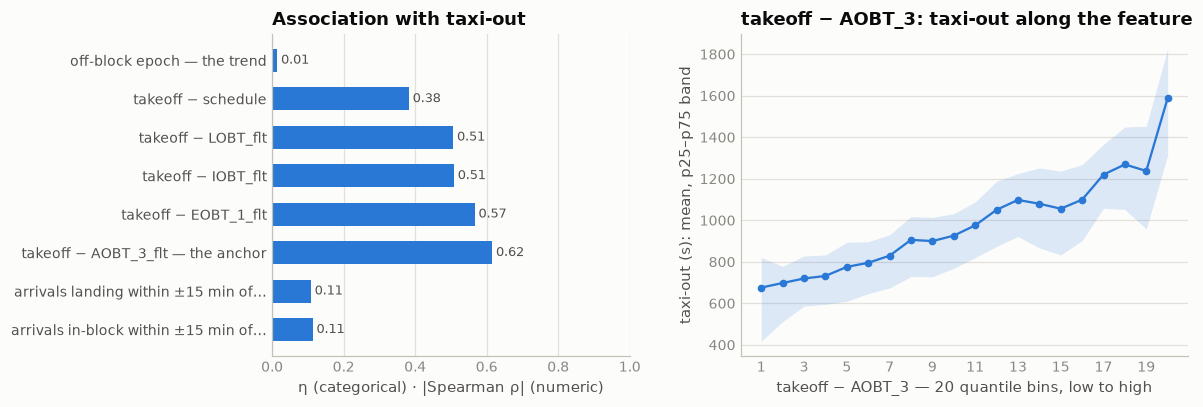

In [9]:
# correlation with the target: the stamp itself is a calendar; its model-facing forms are the five gaps takeoff − visible
# clock (each clock's own section refines its gap) and the arrival stream's in-block count from §9's window table
a = target_assoc([("off-block epoch — the trend", "num", "epoch(BLOCK_TIME_UTC_mvt)"),
                  ("takeoff − schedule", "num", "epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)"),
                  ("takeoff − LOBT_flt", "num", "epoch(MVT_TIME_UTC_mvt - LOBT_flt)"),
                  ("takeoff − IOBT_flt", "num", "epoch(MVT_TIME_UTC_mvt - IOBT_flt)"),
                  ("takeoff − EOBT_1_flt", "num", "epoch(MVT_TIME_UTC_mvt - EOBT_1_flt)"),
                  ("takeoff − AOBT_3_flt — the anchor", "num", "epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)"),
                  ("arrivals landing within ±15 min of takeoff", "num", "arr_land_c30", 1, "blk_lad", "y"),
                  ("arrivals in-block within ±15 min of takeoff", "num", "arr_inblock_c30", 1, "blk_lad", "y")])
assoc_chart(a, "epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)", kind="num", title="takeoff − AOBT_3")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **The only column hidden at prediction time — and the label's other endpoint** | present on every training row but one (an EDDM arrival, `DLH1EK` from Sofia on 4 Nov 2025, that also lacks runway, stand and label); null on 344,841 of 344,841 ranking departures, on 0 of 344,693 ranking arrivals. 6.40% of stamps on the minute: §8's jittered minute clock, which seven hubs use for block times | taxi-out = takeoff − this (§8). It never enters the model; everything below is about locating it from what is visible |
| The block stamp falls *after* the runway stamp on 369 departures, and within ±12 s of it on 758 | departures: 2,084,659 before, 19 equal, 369 after; arrivals: 220 before landing, 16 equal, 2,082,513 after, 472 within ±12 s | two different things hide in those 758 — the next two rows |
| **Helipad lift-offs are genuine near-zero taxi** | LSZH's rotorcraft / VFR fleet: 456 of its 1,141 departures within ±12 s, 360 of them off helipad `H` (stand `HPW`); the other 644 over 300 s are the fixed-wing VFR from the GA apron. Inside ±12 s the values spread evenly from −12 to +12 rather than piling up at 0 | two sensors timing one event, the sign is noise. §4's is-helicopter × airport already predicts them (median 7 s at LSZH) |
| **The collapsed stamp on airliners is a defect** | 149 LSZH (Citations from `GA6`, runway 28), 128 LFPG (737s from `P73`, 26R) and 12 LEBL IFR fixed-wing departures carry a label within ±12 s while the plan's `AOBT_3` puts their taxi at a median **907 / 959 / 933 s** | ~290 rows a year whose label is a quarter of an hour too small. Unrepairable — the score uses the label as delivered — and cheap: a few per 10,000. §14: they train where the label is ≥ 1 s, and it does not matter (0.06% of the holdout's squared error) |
| Both populations are in 2026 | arrivals in-block within ±12 s of landing, per 10,000: LSZH 27.6 → **31.1** (72 ranking rows), LFPG 1.3 → 1.8, EGLL 1.8 → 1.5 | the departures we predict carry the same two slices at the same rates |
| **`AOBT_3` is the nearest visible clock by far — but not by a constant** | off-block − clock, median (p10, p90): schedule 415 s (−242, 2,396) · `LOBT`/`IOBT` 252 (−264, 1,136) · `EOBT_1` 284 (−126, 1,036) · **`AOBT_3` 52 (−306, 363)**; within 5 min 36.6 / 44.2 / 49.0 / **74.8%**, within 15 min 97.7% for `AOBT_3`. Per hub its offset runs from **−117 s at LIRF** (the airport's pushback *before* the plan's; 66.4% within 5 min) to **+297 s at LTFM** (78.4% after; 44.5% within 5 min), with EHAM +107, EDDF +88, EGLL +55 and LEMD, EDDM, LFPG within ±4 s. And it moves with the season: all hubs 60 s in January, **5 s in July**, 54 s in December; LTFM 355 s in January, 234 s in July; LIRF −59 s in January, −178 s in July | the anchor is an estimate with a per-airport, per-season bias — which is why §7's ladder gains 58 s from binning it per airport and runway rather than subtracting it. The two ranking months sit at the two ends of the season. The `AOBT_3` section owns the calibration |
| **As a locator the anchor rewards resolution; the filed clocks carry the delay** | over the airport mean (357.3 s), airport × 20 bins of takeoff − clock: schedule 320.7 · `LOBT` 301.2 · `IOBT` 300.9 · **`EOBT_1` 290.1 · `AOBT_3` 293.5**; at 100 bins `AOBT_3` 281.7, `EOBT_1` 289.2; **`AOBT_3` (20) × `EOBT_1` (5): 252.4 s**. The raw gap as the prediction: 354 s for `AOBT_3`, 627–2,451 s for the others | takeoff − `AOBT_3` is the target plus a bounded offset, so finer bins keep paying; takeoff − `EOBT_1` is the target plus the *pushback delay*, a signal of its own (§2b: late flights taxi longer) that saturates at 20 bins. Together they beat either alone by 30 s — the pushback delay, `AOBT_3` − `EOBT_1`, is a feature to build explicitly; `EOBT_1`'s section |
| The arrival half's in-block clock is not a feature of its own | arrivals in-block within ±15 min of takeoff correlate 0.914 with arrivals landing in the same window; on §8's ladder (278.1 s after the departure count) the landing count takes it to 277.4, in-block on top 277.9, in-block instead 277.2 | in-block = landing + taxi-in, and both are already in §7's stream. Nothing to add |
| **Any feature over departures' off-blocks is a leak** | departures off-block within ±15 min of takeoff gains 2.2 s in CV (278.1 → 275.9) — and 0 of 344,841 ranking departures carry a block time to count | never touch `DEP` block times, not even other rows'. §8's queue at pushback is built on `AOBT_3` for exactly this reason |

**Decisions**

| issue | decision | why |
|---|---|---|
| departures' off-block times, own row or other rows' | **never enter a feature**, not even as a window count | blank on every ranking departure; a count over them trains on a column that is empty at prediction time |
| the 289 collapsed airliner stamps | **no repair**; §14 finds they cost 0.03% of the error in training or out | the score uses the label as delivered; a few per 10,000, unpredictable, and the same defect sits in the 2026 arrivals |
| the helipad near-zeros | left alone | genuine, and §4's is-helicopter × airport predicts them |
| the one arrival without an in-block time | left as is | not predicted, and it has no label to lose |
| arrivals' in-block times | not a feature of their own | landing + taxi-in carry the same information (§7) |

**State after §9** — unchanged, by design:

| `BLOCK_TIME_UTC_mvt` null | training DEP | training ARR | ranking DEP | ranking ARR |
|---|---:|---:|---:|---:|
| before → after | 0 → 0 | 1 → 1 | 344,841 → 344,841 | 0 → 0 |

**Use in modeling.** The column itself never does. Its five visible stand-ins are the pipeline's
takeoff − clock gaps (`build_features` in `pipeline/common.py` builds all five): keep them per
airport, so the model calibrates the anchor's own offset per hub — and expect that offset to
move with the season, with the two ranking months at its extremes. Build the pushback delay
`AOBT_3` − `EOBT_1` as a feature in its own right. In the closing matrix the column enters as
epoch seconds, like the takeoff clock: 1.00 with `MVT_TIME_UTC_mvt`, 0.01 with the target — the
label is their difference, which no marginal measure sees. The gaps enter with their own sections.


## 10 · `SCHED_TIME_UTC_mvt` — the timetable

The scheduled time: **scheduled off-block** on departure rows, **scheduled in-block** on arrivals.
Never null in either file, on either phase, always a whole minute and — on departures — always on
the timetable's 5-minute grid. It is the one clock in the file written *before the day*, so
everything measured against it is a delay: how late the aircraft pushed back, how late it took
off. Both ends of the second difference survive at prediction time: takeoff − schedule is
computable on every row we predict.

| step | question | what came out |
|---|---|---|
| **census** | present where — and which clock is it, exactly? | never null; on departures it *is* the plan's filed off-block for three flights in four (the rest were refiled later); on arrivals the scheduled in-block |
| **the delay** | how late do flights push back and take off, per hub; does taxi-out care; and does 2026 look like 2025? | a median 3–10 min late, a quarter push early; taxi-out barely moves with it on clean rows; January 2026 ran later than January 2025, July earlier |
| **10a · the corruption gauge** | the corrupt Fiumicino labels of `VALIDATION/FINDINGS.md` — can the schedule see them? | yes: where no pushback was captured the block stamp is the *schedule's*, so the label equals takeoff − schedule, and both ends of that are in the ranking file |
| **signal on clean rows** | the hour on which clock; the delay on top of the anchor; scheduled demand against the actual window | both hours together beat either; the plan's delay beats the schedule's; scheduled demand adds nothing over the actual window |


In [4]:
# census by file × phase: never null, whole minutes on the timetable's 5-minute grid — and which clock it is:
# the plan's filed off-block on departures, the scheduled in-block on arrivals
print("SCHED_TIME_UTC_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (SCHED_TIME_UTC_mvt IS NULL) n_null,
           strftime(min(SCHED_TIME_UTC_mvt), '%Y-%m-%d %H:%M') first_stamp,
           strftime(max(SCHED_TIME_UTC_mvt), '%Y-%m-%d %H:%M') last_stamp,
           round(100.0*count(*) FILTER (extract(second FROM SCHED_TIME_UTC_mvt) = 0)/count(*), 1) pct_on_minute,
           round(100.0*count(*) FILTER (extract(minute FROM SCHED_TIME_UTC_mvt) % 5 = 0)/count(*), 1) pct_on_5min_grid,
           count(DISTINCT SCHED_TIME_UTC_mvt) n_unique
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndepartures — the schedule against the plan's filed off-block clocks (matched, training):")
print(pd.concat([con.sql(f"""
    SELECT '{c}' clock, count(*) n, round(100.0*count(*) FILTER (SCHED_TIME_UTC_mvt = {c})/count(*), 1) pct_equal,
           round(100.0*count(*) FILTER ({c} > SCHED_TIME_UTC_mvt)/count(*) FILTER ({c} != SCHED_TIME_UTC_mvt), 1) pct_plan_later_when_different,
           round(quantile_cont(epoch({c} - SCHED_TIME_UTC_mvt)/60.0, 0.5) FILTER ({c} != SCHED_TIME_UTC_mvt), 1) med_min_later_when_different,
           round(100.0*count(*) FILTER ({c} != SCHED_TIME_UTC_mvt AND extract(minute FROM {c}) % 5 = 0)
                 /count(*) FILTER ({c} != SCHED_TIME_UTC_mvt), 1) pct_on_5min_grid_when_different
    FROM {T} WHERE PHASE_mvt = 'DEP' AND {c} IS NOT NULL""").df() for c in ("IOBT_flt", "LOBT_flt", "EOBT_1_flt")],
    ignore_index=True).to_string(index=False))

print("\nschedule = IOBT_flt by market segment (matched departures):")
print(con.sql(f"""
    SELECT MARKET_SEGMENT_flt segment, count(*) n,
           round(100.0*count(*) FILTER (IOBT_flt = SCHED_TIME_UTC_mvt)/count(*), 1) pct_equal
    FROM {T} WHERE PHASE_mvt = 'DEP' AND IOBT_flt IS NOT NULL GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nunmatched departures carry a schedule too:")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER (extract(minute FROM SCHED_TIME_UTC_mvt) % 5 = 0)/count(*), 1) pct_on_5min_grid,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med_takeoff_minus_sched_min
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL""").df().to_string(index=False))

print("\narrivals — the schedule is the scheduled in-block: landing and in-block against it, per hub (1–3600 s):")
print(con.sql(f"""
    SELECT ADES_mvt hub, count(*) n,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med_landing_minus_sched_min,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med_inblock_minus_sched_min,
           round(100.0*count(*) FILTER (BLOCK_TIME_UTC_mvt < SCHED_TIME_UTC_mvt)/count(*), 1) pct_inblock_early
    FROM {T} WHERE PHASE_mvt = 'ARR' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 GROUP BY 1 ORDER BY 3""").df().to_string(index=False))


SCHED_TIME_UTC_mvt by file × phase:
     src  ph       n  n_null      first_stamp       last_stamp  pct_on_minute  pct_on_5min_grid  n_unique
training ARR 2082750       0 2024-12-28 10:05 2025-12-31 23:45          100.0              99.8    106024
training DEP 2085047       0 2024-12-31 22:40 2025-12-31 23:40          100.0             100.0     99290
 ranking ARR  344693       0 2025-12-31 04:25 2026-07-31 23:50          100.0              99.8     18093
 ranking DEP  344841       0 2025-12-31 09:35 2026-07-31 23:00          100.0             100.0     16987

departures — the schedule against the plan's filed off-block clocks (matched, training):


     clock       n  pct_equal  pct_plan_later_when_different  med_min_later_when_different  pct_on_5min_grid_when_different
  IOBT_flt 2062577       74.4                           88.5                          20.0                             82.1
  LOBT_flt 2062577       74.0                           87.9                          20.0                             80.8
EOBT_1_flt 2062577       55.5                           64.9                          10.0                             66.6

schedule = IOBT_flt by market segment (matched departures):
      segment       n  pct_equal
     Mainline 1325748       73.3
      Lowcost  399482       76.6
     Regional  210865       81.1
        Cargo   60021       65.1
     Business   44498       75.4
Non-Scheduled   14577       62.8
        Other    6673       65.4
     Military     713       52.0

unmatched departures carry a schedule too:
    n  pct_on_5min_grid  med_takeoff_minus_sched_min
22424              98.3                         8

 hub      n  med_landing_minus_sched_min  med_inblock_minus_sched_min  pct_inblock_early
LTFM 273871                        -17.9                         -3.1               56.9
LEMD 211091                        -11.1                         -2.9               55.8
LIRF 160212                        -11.0                          0.0               49.5
EGLL 239438                        -11.0                         -2.1               54.8
LFPG 238768                         -9.1                          0.1               48.9
EDDF 230116                         -8.2                          1.5               45.9
EHAM 247686                         -6.6                          1.6               46.1
LEBL 179079                         -5.6                         -2.0               53.8
EDDM 167321                         -5.1                          0.9               47.9
LSZH 134491                         -2.0                          3.8               39.9


pushback delay = off-block − schedule (minutes), training departures 1–3600 s, per hub:


 hub      n  med  p10  p90  pct_pushed_early  pct_over_1h_late  med_takeoff_minus_sched
EGLL 238818  3.0 -7.0 33.9              37.3               4.1                     26.9
LTFM 272169  3.0 -6.9 31.9              36.6               4.5                     20.9
LIRF 158737  4.0 -5.9 40.0              34.0               5.1                     24.0
EDDM 167275  5.9 -3.1 32.9              23.6               3.3                     19.1
LEBL 179699  6.0 -4.0 44.1              25.1               6.3                     22.5
LEMD 212242  7.9 -3.0 41.0              19.5               5.4                     24.6
EDDF 230068  9.2 -2.0 39.7              15.7               4.7                     23.6
EHAM 247866  9.6 -1.7 45.7              14.9               6.5                     23.0
LFPG 239091  9.9 -2.9 47.9              19.0               6.9                     27.0
LSZH 134568 10.1 -0.9 38.9              12.3               4.3                     22.6

taxi-out by pushback-delay band

                      band      n  pct  mean_taxi  med_taxi
1 · more than 15 min early   9680  0.5      954.0     906.5
                 2 · early 493678 23.7     1008.0     955.0
         3 · 0–15 min late 938448 45.1      961.0     899.0
        4 · 15–60 min late 531060 25.5      985.0     918.0
            5 · 1–3 h late  96788  4.7     1020.0     956.0
         6 · over 3 h late  10879  0.5     1039.0     967.0

the far tail — departures whose takeoff is more than 12 h from the schedule (training, raw labels), per hub:


 hub   n  unmatched  pct_about_a_day  segment  med_label
EDDF 360         18             22.0    Cargo     1118.0
EHAM 121         14             17.0    Cargo      982.0
LFPG  39          9             28.0    Cargo     1069.0
LIRF  32         29             13.0    Other    58137.0
LTFM  28          1             14.0 Mainline     1137.0
EDDM  26          3             12.0 Mainline      820.0
LEBL  14          2              0.0 Mainline     1067.0
LEMD   7          0             14.0 Mainline      754.0
EGLL   2          0              0.0 Mainline     1192.0
LSZH   2          0              0.0 Mainline      696.0

look both ways — takeoff − schedule (minutes) in the ranking months and their 2025 twins, all departures:


  yr  mon      n  med  p90  pct_over_1h
2025    1 153706 21.3 57.1          9.1
2026    1 152719 24.7 71.0         13.5
2025    7 190713 28.6 73.0         14.9
2026    7 192122 25.2 65.0         11.7


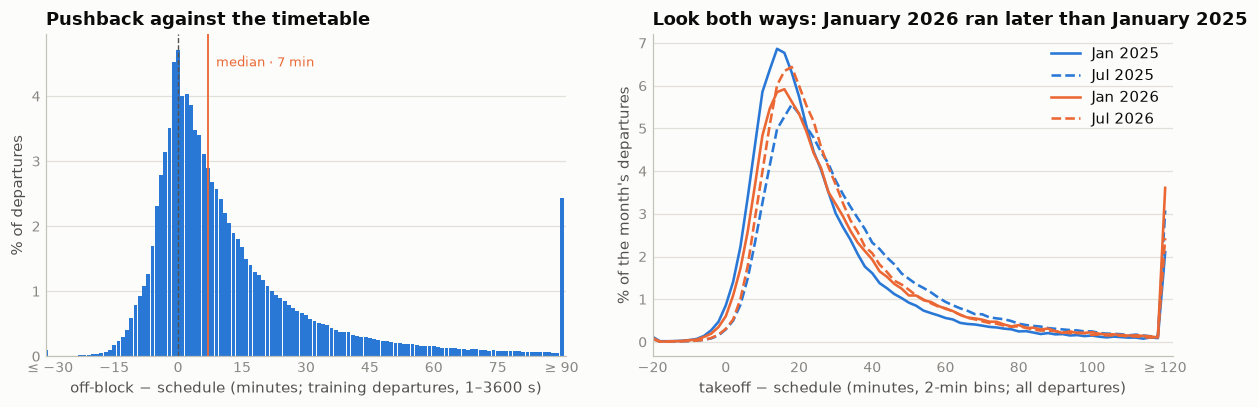

In [5]:
# the delay the schedule measures: off-block − schedule on the rows we model, per hub; taxi-out by delay band; the far
# tail; and — computable on both files — takeoff − schedule in the two ranking months against their 2025 twins
print("pushback delay = off-block − schedule (minutes), training departures 1–3600 s, per hub:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.10), 1) p10,
           round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.90), 1) p90,
           round(100.0*count(*) FILTER (BLOCK_TIME_UTC_mvt < SCHED_TIME_UTC_mvt)/count(*), 1) pct_pushed_early,
           round(100.0*count(*) FILTER (epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) > 3600)/count(*), 1) pct_over_1h_late,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5), 1) med_takeoff_minus_sched
    FROM {TGT} GROUP BY 1 ORDER BY med""").df().to_string(index=False))

print("\ntaxi-out by pushback-delay band (training departures 1–3600 s):")
print(con.sql(f"""
    SELECT CASE WHEN d < -15 THEN '1 · more than 15 min early' WHEN d < 0 THEN '2 · early' WHEN d < 15 THEN '3 · 0–15 min late'
                WHEN d < 60 THEN '4 · 15–60 min late' WHEN d < 180 THEN '5 · 1–3 h late' ELSE '6 · over 3 h late' END band,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(avg(TAXITIME_SEC_mvt)) mean_taxi,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM (SELECT *, epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 d FROM {TGT}) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe far tail — departures whose takeoff is more than 12 h from the schedule (training, raw labels), per hub:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) unmatched,
           round(100.0*count(*) FILTER (abs(abs(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) - 86400) < 7200)/count(*)) pct_about_a_day,
           mode(MARKET_SEGMENT_flt) segment, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {T} WHERE PHASE_mvt = 'DEP' AND abs(epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) > 12*3600
    GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nlook both ways — takeoff − schedule (minutes) in the ranking months and their 2025 twins, all departures:")
print(con.sql(f"""
    SELECT yr, mon, count(*) n, round(quantile_cont(g, 0.5), 1) med, round(quantile_cont(g, 0.9), 1) p90,
           round(100.0*count(*) FILTER (g > 60)/count(*), 1) pct_over_1h
    FROM (SELECT 2025 yr, month(MVT_TIME_UTC_mvt) mon, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 g FROM {T}
          WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7)
          UNION ALL SELECT 2026, month(MVT_TIME_UTC_mvt), epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 FROM {R} WHERE PHASE_mvt = 'DEP')
    GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))

delay = con.sql(f"""
    SELECT greatest(least(floor(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0), 90), -31)::INT m, count(*) n
    FROM {TGT} GROUP BY 1 ORDER BY 1""").df()
curves = con.sql(f"""
    SELECT yr, mon, greatest(least(floor(g/2)*2, 120), -20)::INT m, 100.0*count(*)/sum(count(*)) OVER (PARTITION BY yr, mon) pct
    FROM (SELECT 2025 yr, month(MVT_TIME_UTC_mvt) mon, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 g FROM {T}
          WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7)
          UNION ALL SELECT 2026, month(MVT_TIME_UTC_mvt), epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 FROM {R} WHERE PHASE_mvt = 'DEP')
    GROUP BY 1, 2, 3 ORDER BY 1, 2, 3""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.bar(delay.m, 100 * delay.n / delay.n.sum(), width=0.9, color=BLUE)
a1.axvline(0, color=INK2, lw=0.9, ls="--")
med = con.sql(f"SELECT quantile_cont(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0, 0.5) FROM {TGT}").fetchone()[0]
a1.axvline(med, color=ORANGE, lw=1.2)
a1.text(med + 2, a1.get_ylim()[1] * 0.9, f"median · {med:.0f} min", color=ORANGE, fontsize=8.5)
a1.set_xlim(-31, 91)
a1.set_xticks([-30, -15, 0, 15, 30, 45, 60, 75, 90], ["≤ −30", "−15", "0", "15", "30", "45", "60", "75", "≥ 90"])
a1.set_title("Pushback against the timetable")
a1.set_xlabel("off-block − schedule (minutes; training departures, 1–3600 s)")
a1.set_ylabel("% of departures")
style(a1)
for (yr, mon), g in curves.groupby(["yr", "mon"]):
    a2.plot(g.m, g.pct, color=BLUE if yr == 2025 else ORANGE, ls="-" if mon == 1 else "--", lw=1.7,
            label=f"{'Jan' if mon == 1 else 'Jul'} {yr}")
a2.set_xlim(-20, 122)
a2.set_xticks([-20, 0, 20, 40, 60, 80, 100, 120], ["−20", "0", "20", "40", "60", "80", "100", "≥ 120"])
a2.set_title("Look both ways: January 2026 ran later than January 2025")
a2.set_xlabel("takeoff − schedule (minutes, 2-min bins; all departures)")
a2.set_ylabel("% of the month's departures")
a2.legend(loc="upper right")
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()


### 10a · The schedule as a corruption gauge

`VALIDATION/FINDINGS.md` found that a few hundred departures a year — 584 labelled over 7,200 s in
2025, nearly all at Fiumicino and nearly all without a flight plan — decide most of the score, and
called them unfixable and only hedgeable. The schedule says what they are. On these rows the
airport captured no pushback and wrote the **scheduled time as the block time**; the "taxi-out"
is then takeoff − schedule, the flight's delay to the second. Both ends of that difference are
known at prediction time. This cell works on raw labels, all departures, by design.

| takeoff − schedule, on Fiumicino departures without a plan | what the gauge reads |
|---|---|
| under 1 h | mostly real pushbacks and a normal taxi |
| 1–2 h | four block stamps in ten are the schedule's |
| 2–6 h | six in ten; the label averages two hours |
| over 6 h | nearly all; the label is the gap, tens of thousands of seconds |


the corrupt labels (over 7,200 s): where the block stamp sits against the schedule, and the label against takeoff − schedule:
  n  lirf  no_plan  pct_block_within_5min_of_sched  pct_within_30min  resid_p10  resid_p50  resid_p90
584   480      481                            77.1              86.8     -780.0        0.0        6.0

Fiumicino departures without a plan, by band of takeoff − schedule — a mixture of two populations:
      band   n  pct_block_is_sched  corrupt  mean_label  mean_gap_s  rmse_label_eq_gap  rmse_band_mean
 1 · < 1 h 112                42.9       24      3576.0       544.0             6722.0          4514.0
 2 · 1–2 h 748                37.6        2      2925.0      5740.0             3659.0          2445.0
 3 · 2–6 h 564                61.5      351      7218.0     10402.0             6472.0          6242.0
4 · 6–12 h  34                97.1       33     32011.0     32657.0             3766.0          8861.0
5 · > 12 h  29                62.1       29     67859.0

       hub  no_plan     n  pct_block_is_sched  corrupt  mean_label
      LIRF     True   627                63.5      413     11367.0
      LIRF    False  2751                 1.2       40      1402.0
other hubs     True  4318                 0.2       37      1314.0
other hubs    False 32156                 0.0       62      1136.0



honest holdout on raw labels — 328,009 Nov+Dec departures, 61 labelled over 7,200 s (support ≥ 30, else the coarser rung):
                                                       rung  rmse_all  rmse_lirf
                                                    airport     496.5     1290.0
                                             + no-plan flag     475.0     1171.1
mixture: LIRF, no plan → p·gap + (1−p)·other mean, per band     460.8     1088.4
                               + band of takeoff − schedule     456.8     1091.7
           rule: LIRF, no plan, gap ≥ 2 h → predict the gap     391.4      596.8

where the holdout's squared error about the airport mean lives, by band:
      band      n  corrupt  pct_squared_error
 1 · < 1 h 300253        1               42.3
 2 · 1–2 h  21483        0               13.0
 3 · 2–6 h   5840       52                8.1
4 · 6–12 h    311        4                6.2
5 · > 12 h    122        4               30.4

the ranking file — Fiumicino departures

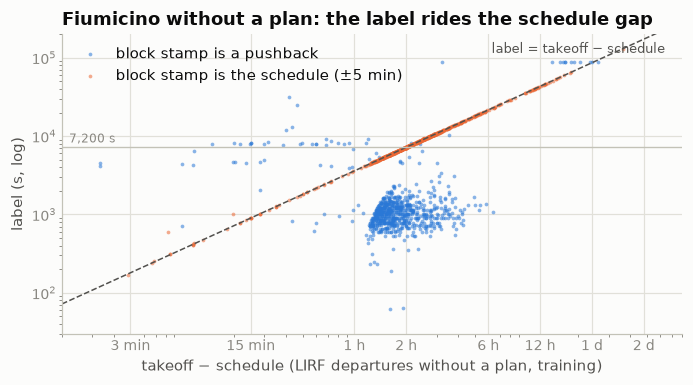

In [6]:
# 10a — raw labels, all departures (this cell deviates from TGT on purpose: the corrupt labels are the subject).
# Where the corrupt rows' two stamps sit against the schedule; the mixture at Fiumicino without a plan, by band of
# takeoff − schedule; the scope at other hubs; an honest raw-label holdout; and the candidates in the ranking file
RAWDEP = f"(SELECT *, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) gap_s, (FLIGHT_ID_mvt IS NULL) no_plan FROM {T} WHERE PHASE_mvt = 'DEP')"
BAND = ("CASE WHEN gap_s < 3600 THEN '1 · < 1 h' WHEN gap_s < 7200 THEN '2 · 1–2 h' WHEN gap_s < 6*3600 THEN '3 · 2–6 h' "
        "WHEN gap_s < 12*3600 THEN '4 · 6–12 h' ELSE '5 · > 12 h' END")
print("the corrupt labels (over 7,200 s): where the block stamp sits against the schedule, and the label against takeoff − schedule:")
print(con.sql(f"""
    SELECT count(*) n, count(*) FILTER (ADEP_mvt = 'LIRF') lirf, count(*) FILTER (no_plan) no_plan,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300)/count(*), 1) pct_block_within_5min_of_sched,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 1800)/count(*), 1) pct_within_30min,
           round(quantile_cont(TAXITIME_SEC_mvt - gap_s, 0.10)) resid_p10, round(quantile_cont(TAXITIME_SEC_mvt - gap_s, 0.5)) resid_p50,
           round(quantile_cont(TAXITIME_SEC_mvt - gap_s, 0.90)) resid_p90
    FROM {RAWDEP} WHERE TAXITIME_SEC_mvt > 7200""").df().to_string(index=False))

print("\nFiumicino departures without a plan, by band of takeoff − schedule — a mixture of two populations:")
print(con.sql(f"""
    WITH d AS (SELECT {BAND} band, gap_s, TAXITIME_SEC_mvt::DOUBLE y,
                      abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300 block_is_sched
               FROM {RAWDEP} WHERE ADEP_mvt = 'LIRF' AND no_plan),
         bm AS (SELECT band, avg(y) m FROM d GROUP BY 1)
    SELECT band, count(*) n, round(100.0*count(*) FILTER (block_is_sched)/count(*), 1) pct_block_is_sched,
           count(*) FILTER (y > 7200) corrupt, round(avg(y)) mean_label, round(avg(gap_s)) mean_gap_s,
           round(sqrt(avg((y - gap_s)^2))) rmse_label_eq_gap, round(sqrt(avg((y - m)^2))) rmse_band_mean
    FROM d JOIN bm USING (band) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))
print("\n    the same rows where the block stamp IS the schedule (within 5 min), any band:")
print(con.sql(f"""
    SELECT {BAND} band, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_label, round(avg(gap_s)) mean_gap_s,
           round(sqrt(avg((TAXITIME_SEC_mvt - gap_s)^2))) rmse_label_eq_gap
    FROM {RAWDEP} WHERE ADEP_mvt = 'LIRF' AND no_plan AND abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nscope — departures with takeoff − schedule of 2 h or more, elsewhere:")
print(con.sql(f"""
    SELECT CASE WHEN ADEP_mvt = 'LIRF' THEN 'LIRF' ELSE 'other hubs' END hub, no_plan, count(*) n,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300)/count(*), 1) pct_block_is_sched,
           count(*) FILTER (TAXITIME_SEC_mvt > 7200) corrupt, round(avg(TAXITIME_SEC_mvt)) mean_label
    FROM {RAWDEP} WHERE gap_s >= 7200 GROUP BY 1, 2 ORDER BY 1, 2 DESC""").df().to_string(index=False))

# honest raw-label holdout: fit Jan–Oct, score Nov+Dec on ALL departures as labelled
con.sql(f"""
    CREATE OR REPLACE TABLE sch_raw AS
    SELECT ADEP_mvt hub, no_plan, TAXITIME_SEC_mvt::DOUBLE y, gap_s, {BAND} band,
           abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300 block_is_sched, month(MVT_TIME_UTC_mvt) >= 11 is_val
    FROM {RAWDEP}""")
n_val, n_corrupt = con.sql("SELECT count(*), count(*) FILTER (y > 7200) FROM sch_raw WHERE is_val").fetchone()
print(f"\nhonest holdout on raw labels — {n_val:,} Nov+Dec departures, {n_corrupt} labelled over 7,200 s (support ≥ 30, else the coarser rung):")
print(con.sql("""
    WITH h AS (SELECT hub, avg(y) m FROM sch_raw WHERE NOT is_val GROUP BY 1),
         f AS (SELECT hub, no_plan, avg(y) m, count(*) c FROM sch_raw WHERE NOT is_val GROUP BY ALL),
         fb AS (SELECT hub, no_plan, band, avg(y) m, count(*) c FROM sch_raw WHERE NOT is_val GROUP BY ALL),
         -- the mixture, fitted on Jan–Oct: p = share whose block stamp is the schedule; m0 = mean label of the others
         mix AS (SELECT hub, no_plan, band, avg(block_is_sched::INT) p, avg(y) FILTER (NOT block_is_sched) m0, count(*) c
                 FROM sch_raw WHERE NOT is_val GROUP BY ALL),
         v AS (SELECT r.*, h.m p_airport, coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m) p_flag,
                      coalesce(CASE WHEN fb.c >= 30 THEN fb.m END, CASE WHEN f.c >= 30 THEN f.m END, h.m) p_band,
                      CASE WHEN r.hub = 'LIRF' AND r.no_plan AND r.gap_s >= 7200 THEN r.gap_s
                           ELSE coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m) END p_rule,
                      CASE WHEN r.hub = 'LIRF' AND r.no_plan AND mix.c >= 30 THEN mix.p * r.gap_s + (1 - mix.p) * mix.m0
                           ELSE coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m) END p_mix
               FROM sch_raw r JOIN h USING (hub) LEFT JOIN f USING (hub, no_plan) LEFT JOIN fb USING (hub, no_plan, band)
               LEFT JOIN mix USING (hub, no_plan, band) WHERE is_val)
    SELECT rung, round(sqrt(avg((y - p)^2)), 1) rmse_all, round(sqrt(avg((y - p)^2) FILTER (hub = 'LIRF')), 1) rmse_lirf
    FROM (SELECT 'airport' rung, y, hub, p_airport p FROM v UNION ALL SELECT '+ no-plan flag', y, hub, p_flag FROM v
          UNION ALL SELECT '+ band of takeoff − schedule', y, hub, p_band FROM v
          UNION ALL SELECT 'rule: LIRF, no plan, gap ≥ 2 h → predict the gap', y, hub, p_rule FROM v
          UNION ALL SELECT 'mixture: LIRF, no plan → p·gap + (1−p)·other mean, per band', y, hub, p_mix FROM v)
    GROUP BY 1 ORDER BY rmse_all DESC""").df().to_string(index=False))
print("\nwhere the holdout's squared error about the airport mean lives, by band:")
print(con.sql("""
    WITH h AS (SELECT hub, avg(y) m FROM sch_raw WHERE NOT is_val GROUP BY 1)
    SELECT band, count(*) n, count(*) FILTER (y > 7200) corrupt,
           round(100.0*sum((y - m)^2)/sum(sum((y - m)^2)) OVER (), 1) pct_squared_error
    FROM sch_raw JOIN h USING (hub) WHERE is_val GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe ranking file — Fiumicino departures without a plan, by band and month:")
print(con.sql(f"""
    SELECT {BAND} band, count(*) FILTER (month(MVT_TIME_UTC_mvt) = 1) jan_2026, count(*) FILTER (month(MVT_TIME_UTC_mvt) = 7) jul_2026
    FROM (SELECT *, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) gap_s FROM {R} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LIRF' AND FLIGHT_ID_mvt IS NULL)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

pts = con.sql(f"""
    SELECT gap_s/3600.0 g, TAXITIME_SEC_mvt y, abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300 block_is_sched
    FROM {RAWDEP} WHERE ADEP_mvt = 'LIRF' AND no_plan AND gap_s > 60 AND TAXITIME_SEC_mvt > 0""").df()
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for flag, c, lbl in [(False, BLUE, "block stamp is a pushback"), (True, ORANGE, "block stamp is the schedule (±5 min)")]:
    g = pts[pts.block_is_sched == flag]
    ax.scatter(g.g, g.y, s=6, color=c, alpha=0.55, lw=0, label=lbl)
xx = np.logspace(np.log10(0.02), np.log10(80), 50)
ax.plot(xx, xx * 3600, color=INK2, lw=1, ls="--")
ax.text(20, 20 * 3600 * 1.6, "label = takeoff − schedule", fontsize=8.5, color=INK2, ha="center")
ax.axhline(7200, color=BASELINE, lw=0.9)
ax.text(0.022, 7200 * 1.15, "7,200 s", fontsize=8, color=MUTED)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(0.02, 80); ax.set_ylim(30, 200000)
ax.set_xticks([0.05, 0.25, 1, 2, 6, 12, 24, 48], ["3 min", "15 min", "1 h", "2 h", "6 h", "12 h", "1 d", "2 d"])
ax.set_xlabel("takeoff − schedule (LIRF departures without a plan, training)")
ax.set_ylabel("label (s, log)")
ax.set_title("Fiumicino without a plan: the label rides the schedule gap")
ax.legend(loc="upper left")
style(ax, x_grid=True)
fig.tight_layout()
plt.show()


In [7]:
# what the schedule buys on the rows we model — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the
# coarser rung: (1) the hour read on the schedule vs on the takeoff; (2) the delay on top of the AOBT_3 anchor, schedule-
# based vs plan-based; (3) scheduled demand — departures and arrivals timetabled around our slot — against §8's actual window
LOCAL_S = f"timezone({TZ.replace('CASE hub', 'CASE ADEP_mvt')}, SCHED_TIME_UTC_mvt)"
con.sql(f"""
    CREATE OR REPLACE TABLE sch_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           hour({LOCAL}) h_takeoff, hour({LOCAL_S}) h_sched,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g_aobt3, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt) g_sched,
           epoch(MVT_TIME_UTC_mvt - EOBT_1_flt) g_eobt1, epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt) push_vs_sched,
           epoch(AOBT_3_flt - EOBT_1_flt) push_vs_plan
    FROM {TGT}""")


def sch_cat(keys):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM sch_d WHERE NOT is_val GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM sch_d WHERE NOT is_val GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM sch_d v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0]


def sch_ladder(*bins):
    """bins: (gap column, number of quantile bins), nested left to right on top of the airport mean."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}" for k, (c, n) in enumerate(bins))
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}" for k, (c, _) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE sch_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM sch_d WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM sch_d JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE sch_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM sch_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN sch_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN sch_r{k}.c >= 30 THEN sch_r{k}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2))
                       FROM sch_b v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM sch_d WHERE is_val").fetchone()[0]
print(f"(1) the hour, read on which clock? — {n_val:,} Nov+Dec departures; the two hours differ on "
      f"{con.sql('SELECT round(100.0*count(*) FILTER (h_takeoff != h_sched)/count(*), 1) FROM sch_d').fetchone()[0]}% of rows")
for name, keys in [("airport", "hub"), ("+ local hour of takeoff (§8)", "hub, h_takeoff"),
                   ("+ local hour of the schedule", "hub, h_sched"), ("+ both hours", "hub, h_takeoff, h_sched")]:
    print(f"    {name:44s} {sch_cat(keys):7.1f} s")

print("\n(2) the delay on top of the anchor — airport × 20 bins of takeoff − AOBT_3, then × 5 bins of:")
print(f"    {'anchor alone (§9)':44s} {sch_ladder(('g_aobt3', 20)):7.1f} s")
for name, col in [("takeoff − schedule", "g_sched"), ("AOBT_3 − schedule, the pushback delay", "push_vs_sched"),
                  ("AOBT_3 − EOBT_1, the delay against the plan", "push_vs_plan"), ("takeoff − EOBT_1 (§9)", "g_eobt1")]:
    print(f"    {'× ' + name:44s} {sch_ladder(('g_aobt3', 20), (col, 5)):7.1f} s")
print(f"    {'× both delays (5 × 5)':44s} {sch_ladder(('g_aobt3', 20), ('push_vs_plan', 5), ('push_vs_sched', 5)):7.1f} s")
print(f"    {'schedule alone: airport × 20 bins of takeoff − schedule':44s} {sch_ladder(('g_sched', 20)):7.1f} s")

# (3) scheduled demand: timetabled departures / arrivals around our scheduled slot, per hub, computed identically on both files
con.sql(f"""
    CREATE OR REPLACE TABLE sch_ev AS
    SELECT ds, MVT_ID_mvt id, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, PHASE_mvt ph,
           MVT_TIME_UTC_mvt t, SCHED_TIME_UTC_mvt s, RUNWAY_mvt rwy, AOBT_3_flt aobt3, TAXITIME_SEC_mvt taxi
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})""")
con.sql("""
    CREATE OR REPLACE TABLE sch_win AS
    SELECT ds, id, ph,
           sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER ws sdep_c60, sum(CASE WHEN ph = 'ARR' THEN 1 ELSE 0 END) OVER ws sarr_c60,
           sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER wa dep_c30
    FROM sch_ev
    WINDOW ws AS (PARTITION BY ds, hub ORDER BY s RANGE BETWEEN INTERVAL 30 MINUTE PRECEDING AND INTERVAL 30 MINUTE FOLLOWING),
           wa AS (PARTITION BY ds, hub ORDER BY t RANGE BETWEEN INTERVAL 15 MINUTE PRECEDING AND INTERVAL 15 MINUTE FOLLOWING)""")
print("\n(3) scheduled demand — the same windows on both files (departure rows):")
print(con.sql("""
    SELECT ds, count(*) n, round(avg(sdep_c60), 1) mean_dep_scheduled_pm30, round(avg(sarr_c60), 1) mean_arr_scheduled_pm30,
           round(avg(dep_c30), 1) mean_dep_actual_pm15
    FROM sch_win WHERE ph = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
con.sql("""
    CREATE OR REPLACE TABLE sch_lad AS
    SELECT e.id, e.hub, e.rwy, e.taxi::DOUBLE y, epoch(e.t - e.aobt3) anchor, (e.t >= TIMESTAMPTZ '2025-11-01') is_val,
           w.sdep_c60, w.sarr_c60, w.dep_c30
    FROM sch_ev e JOIN sch_win w USING (ds, id)
    WHERE e.ds = 'training' AND e.ph = 'DEP' AND e.taxi BETWEEN 1 AND 3600 AND e.rwy IS NOT NULL AND e.aobt3 IS NOT NULL""")
print(con.sql("""
    SELECT round(corr(sdep_c60, dep_c30), 3) corr_scheduled_vs_actual_departures, round(corr(y, sdep_c60), 3) corr_taxi_scheduled,
           round(corr(y, dep_c30), 3) corr_taxi_actual FROM sch_lad""").df().to_string(index=False))
con.sql("""
    CREATE OR REPLACE TABLE sch_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                         quantile_cont(sdep_c60, [0.2,0.4,0.6,0.8]) qs, quantile_cont(sarr_c60, [0.2,0.4,0.6,0.8]) qr,
                         quantile_cont(dep_c30, [0.2,0.4,0.6,0.8]) qd
                  FROM sch_lad WHERE NOT is_val GROUP BY 1)
    SELECT hub, rwy, y, is_val, list_count(list_filter(qa, x -> x <= anchor)) q_anc,
           list_count(list_filter(qs, x -> x <= sdep_c60)) q_sdep, list_count(list_filter(qr, x -> x <= sarr_c60)) q_sarr,
           list_count(list_filter(qd, x -> x <= dep_c30)) q_dep
    FROM sch_lad JOIN cuts USING (hub)""")


def sch_rungs(rungs):
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE sch_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c "
                f"FROM sch_wb WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN sch_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN sch_s{i}.c >= 30 THEN sch_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM sch_wb v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM sch_wb WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]), ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"])]
n_val = con.sql("SELECT count(*) FROM sch_wb WHERE is_val").fetchone()[0]
print(f"\n    ladder on the {n_val:,} Nov+Dec departures with runway + anchor:")
for name, r in sch_rungs(BASE):
    print(f"    {name:52s} {r:7.1f} s")
for name, keys in [("+ departures scheduled within ±30 min of our slot", ["q_sdep"]),
                   ("+ arrivals scheduled within ±30 min of our slot", ["q_sarr"]),
                   ("+ departures actually within ±15 min of takeoff (§8)", ["q_dep"]),
                   ("+ actual ±15 min, then scheduled ±30 min on top", ["q_dep", "q_sdep"])]:
    rung = BASE + [(f"r{i}", ["hub", "rwy", "q_anc"] + keys[:i + 1]) for i in range(len(keys))]
    print(f"    {name:52s} {sch_rungs(rung)[-1][1]:7.1f} s")


(1) the hour, read on which clock? — 327,485 Nov+Dec departures; the two hours differ on 40.4% of rows
    airport                                        357.3 s
    + local hour of takeoff (§8)                   351.5 s
    + local hour of the schedule                   352.0 s
    + both hours                                   342.3 s

(2) the delay on top of the anchor — airport × 20 bins of takeoff − AOBT_3, then × 5 bins of:


    anchor alone (§9)                              293.5 s


    × takeoff − schedule                           265.3 s


    × AOBT_3 − schedule, the pushback delay        268.4 s


    × AOBT_3 − EOBT_1, the delay against the plan   257.1 s


...

    × both delays (5 × 5)                          252.0 s
    schedule alone: airport × 20 bins of takeoff − schedule   320.7 s



(3) scheduled demand — the same windows on both files (departure rows):
      ds       n  mean_dep_scheduled_pm30  mean_arr_scheduled_pm30  mean_dep_actual_pm15
training 2085047                     40.4                     33.3                  18.7
 ranking  344841                     39.7                     32.6                  18.3


 corr_scheduled_vs_actual_departures  corr_taxi_scheduled  corr_taxi_actual
                               0.822                0.073             0.098



    ladder on the 324,631 Nov+Dec departures with runway + anchor:
    airport                                                355.4 s
    + runway                                               341.8 s
    + AOBT_3 anchor                                        283.6 s
    + departures scheduled within ±30 min of our slot      280.2 s


    + arrivals scheduled within ±30 min of our slot        282.3 s
    + departures actually within ±15 min of takeoff (§8)   278.1 s
    + actual ±15 min, then scheduled ±30 min on top        278.5 s


                                               feature        kind  n / levels  pearson_r  spearman_ρ     η
                            schedule epoch — the trend     numeric     2080533      0.012       0.015      
           hour of the schedule, the hub's local clock categorical          24                        0.112
                                    takeoff − schedule     numeric     2080533      0.190       0.383      
                AOBT_3 − schedule — the pushback delay     numeric     2059401      0.101       0.150      
       departures scheduled within ±30 min of our slot     numeric     2059401      0.073       0.094      
         arrivals scheduled within ±30 min of our slot     numeric     2059401      0.060       0.099      
takeoff − schedule on raw labels, all departures (10a)     numeric     2085047      0.232       0.387      


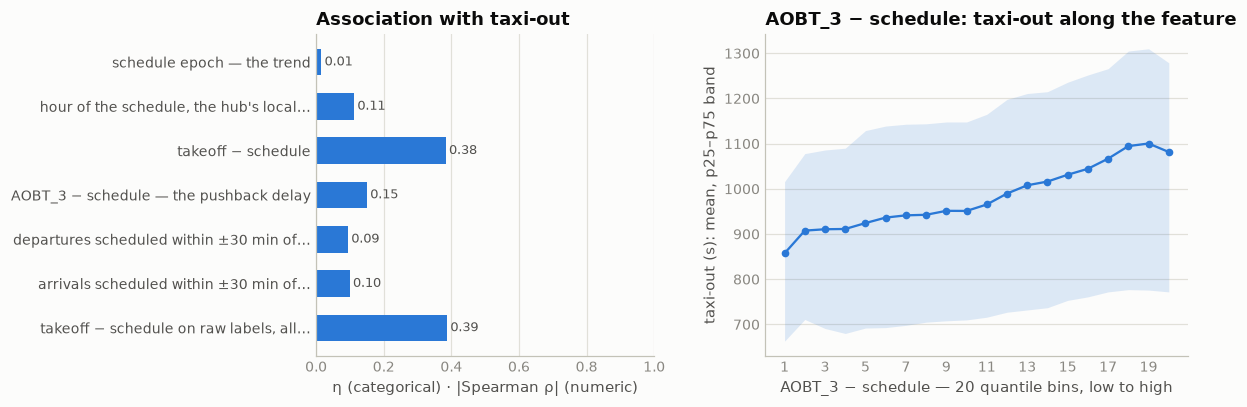

In [8]:
# correlation with the target: the stamp is a calendar; its derived forms are the gaps to takeoff and to the anchor,
# the scheduled hour, the scheduled-demand windows — and, on raw labels, the gauge of 10a
a = target_assoc([("schedule epoch — the trend", "num", "epoch(SCHED_TIME_UTC_mvt)"),
                  ("hour of the schedule, the hub's local clock", "cat", f"hour({LOCAL_S})"),
                  ("takeoff − schedule", "num", "epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)"),
                  ("AOBT_3 − schedule — the pushback delay", "num", "epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt)"),
                  ("departures scheduled within ±30 min of our slot", "num", "sdep_c60", 1, "sch_lad", "y"),
                  ("arrivals scheduled within ±30 min of our slot", "num", "sarr_c60", 1, "sch_lad", "y"),
                  ("takeoff − schedule on raw labels, all departures (10a)", "num", "gap_s", 1, RAWDEP)])
assoc_chart(a, "epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt)", kind="num", title="AOBT_3 − schedule")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Never null, a whole minute, on the 5-minute grid** | zero nulls on 4,857,331 rows; 100% of departures on a multiple of 5 minutes, 99.8% of arrivals; the earliest training departure was timetabled for 31 Dec 2024 22:40 | the only clock written before the day: every difference against it is a delay |
| **On departures it is the plan's filed off-block — usually** | equal to `IOBT_flt` on 74.4% of matched departures (`LOBT_flt` 74.0%, `EOBT_1_flt` 55.5%); when they differ the plan sits *later* 88.5% of the time, by a median 20 min, and still on the 5-minute grid 82.1% of the time. Regional 81.1% equal, Cargo 65.1%, Military 52.0% | the schedule is the timetable and the filed clocks are its revisions; their difference is an early word on delay (the `IOBT`/`EOBT_1` sections) |
| Unmatched departures have one too | 22,424 rows, 98.3% on the grid, median takeoff 88 min after it | the schedule is the movement side's own field: it survives where the whole `_flt` block is missing — and those 88 minutes are §2b's delayed flights |
| On arrivals it is the scheduled *in-block* | in-block − schedule median −3.1 min (LTFM) to +3.8 (LSZH); landing − schedule −17.9 to −2.0 | not a feature (arrivals are never predicted), but the right anchor for a scheduled-arrival window |
| **Pushback delay is per hub, and a quarter of flights push early** | median off-block − schedule 3.0 min at EGLL and LTFM to 10.1 at LSZH; early pushbacks 12.3% (LSZH) to 37.3% (EGLL); over an hour late 3.3–6.9% | the timetable is kept loosely, differently at each airport |
| **Taxi-out barely moves with the delay on clean rows** | by band of pushback delay: means 954–1,039 s, medians 899–967 s; early pushbacks (1,008 s) taxi longer than punctual ones (961 s); the over-3-hours-late 1,039 s | ρ 0.15 with the pushback delay, 0.38 with takeoff − schedule (which contains the taxi itself); what the delay buys shows only on top of the anchor — the signal row below |
| **January 2026 ran later than January 2025; July earlier** | takeoff − schedule, all departures: Jan 2025 median 21.3 min, p90 57.1, 9.1% over an hour → Jan 2026 **24.7 / 71.0 / 13.5%**; Jul 2025 28.6 / 73.0 / 14.9% → Jul 2026 25.2 / 65.0 / 11.7% | computable on the ranking file, this is the first drift the sweep has seen: the scored January is a worse month than its twin. Delay features are how the model can know it; calendar features cannot |
| The far tail is cargo — and Fiumicino | 631 departures with takeoff more than 12 h from schedule: EDDF 360, EHAM 121, LFPG 39, mostly cargo, only a fifth about a day off — freighters rescheduled to a new date; LIRF's 32, of which 29 have no plan, carry a median label of **58,137 s** | the cargo rows are real flights with a stale timetable; Fiumicino's are 10a |
| **10a · the corrupt block stamp is the schedule's** | of the 584 labels over 7,200 s (480 at LIRF, 481 without a plan), the block stamp is within 5 min of the schedule on 77.1%, within 30 min on 86.8%; label − (takeoff − schedule) has p10 −780 s, **median 0**, p90 +6 s | no pushback was captured and the system wrote the timetable; the "taxi-out" is the delay, and both its ends are in the ranking file |
| **10a · Fiumicino without a plan is a mixture** | by band of takeoff − schedule, the block stamp is the schedule's on 42.9% (< 1 h), 37.6% (1–2 h), 61.5% (2–6 h), 97.1% (6–12 h), 62.1% (> 12 h); on those rows label = gap within 3–61 s RMSE (n = 48 / 281 / 347 / 33 / 18); on the others an ordinary taxi | the label is takeoff − schedule with probability p(band), else a taxi: the conditional mean the model must learn is p · gap + (1 − p) · taxi |
| **10a · Fiumicino's, and only without a plan** | gap ≥ 2 h: LIRF without a plan 627 rows, 63.5% block = schedule, 413 corrupt, mean label 11,367 s; LIRF with a plan 2,751 rows, 1.2%, 40 corrupt, 1,402 s; other hubs without a plan 4,318 rows, 0.2%, 37 corrupt, 1,314 s | the gauge is airport × no-plan × gap, a three-way interaction — not a global delay feature |
| **10a · honest holdout on raw labels** | 328,009 Nov+Dec departures, 61 over 7,200 s: airport 496.5 → + no-plan flag 475.0 → + band of takeoff − schedule 456.8 → **the rule "LIRF, no plan, gap ≥ 2 h → predict the gap" 391.4 s** (LIRF 1,290 → 597); the band-fitted mixture 460.8 | the rule takes 84 s off a group-mean ladder. It beats the fitted mixture because the rule's 58 holdout rows were 83% corrupt (48 of 58) against 62% in the fit months: p moves, and the model has to learn it from the tail — which must therefore stay in training (`VALIDATION/FINDINGS.md`, §3) |
| 10a · where the error lives | the > 12 h band — 122 rows — carries 30.4% of the holdout's squared error about the airport mean; 2–12 h another 14.3% | a few hundred rows, and the schedule points at them |
| **10a · the candidates in the scored set** | LIRF departures without a plan by band, Jan + Jul 2026: 2–6 h 41 + 114, 6–12 h 8 + 7, > 12 h 3 + 8 | 181 rows over 2 h; on 2025's rates roughly 110 of them carry a label of hours, and July has the most |
| **The hour is worth more read twice** | airport 357.3 → + local hour of takeoff 351.5 (§8) · + local hour of the schedule 352.0 · **+ both 342.3 s**; the two hours differ on 40.4% of rows | the pair encodes the delay in whole hours; either alone does not |
| **The plan's delay beats the schedule's** | on airport × 20 bins of takeoff − `AOBT_3` (293.5): × takeoff − schedule 265.3 · × `AOBT_3` − schedule 268.4 · × `AOBT_3` − `EOBT_1` **257.1** · × takeoff − `EOBT_1` 252.4 (§9) · × both delays 252.0 | the plan is refiled towards reality, the schedule is not; the schedule's delay adds 0.4 s on top of the plan's — but it is never missing, which the plan's is on 1.53% of predictions |
| Scheduled demand adds nothing over the actual window | departures scheduled within ±30 min of our slot correlate 0.822 with §8's actual count; on the runway × anchor ladder (283.6) they take it to 280.2, the actual count to 278.1, both to 278.5; scheduled arrivals 282.3 | at prediction time the actual takeoffs are known, and they are the better count |

**Decisions**

| issue | decision | why |
|---|---|---|
| the corrupt Fiumicino rows | **no repair, no removal**: keep them in training and give the model takeoff − schedule, the no-plan flag and the airport, so it learns the gauge; test it in the harness as an explicit rule too | the score uses the label as delivered, and the gauge is the only thing in the file that predicts it |
| the schedule's delay vs the plan's | keep both | the plan's is 11 s better on the anchor ladder; the schedule's is never missing |
| scheduled-demand windows | not a feature | a weaker copy of the actual window, nothing on top of it |
| the hour | read it on both clocks | 342.3 against 351.5 s |

**State after §10** — unchanged: never null, nothing repaired.

**Use in modeling.** (1) Takeoff − schedule and `AOBT_3` − schedule, per airport — the pipeline
builds the first already. (2) **The gauge**: airport × no-plan × takeoff − schedule, with the
tail kept in training, is the largest lever this sweep has found; the harness should measure it
as a feature and as a rule, and `VALIDATION/FINDINGS.md`'s break-even logic applies to how much of
2025's corruption 2026 carries. (3) Local hour on both clocks. (4) No scheduled-demand windows.
In the closing matrix the column enters as epoch seconds, the third copy of the clock: 1.00 with the
takeoff and off-block stamps, 0.01 with the target — everything it knows is in its differences.


## 11 · `AIRCRAFT_TYPE_mvt` — what is taxiing

The ICAO type designator of the aircraft — `A320`, `B738`, `B77W` — as the airport recorded it;
the flight plan carries its own copy in `AIRCRAFT_TYPE_flt`. It says how big the aircraft is,
whether it is a helicopter, and — through the fleet an airline flies on a route — a good deal about
who is flying where. This section settles what the code is worth on its own, what it carries beyond
itself, and what to do with the few rows that lack it.

| step | question | what came out |
|---|---|---|
| **census** | present where; who lacks it; does the plan's copy agree? | null on 0.07% of departures — and those are Fiumicino's plan-less departures, 10a's slice by another name; 99.66% agreement with the plan, and the disagreements are variants of one type |
| **cardinality** | how many types matter; does 2026 bring new ones? | 269 types; 24 of them are nine departures in ten, in 2026 as in 2025; 18 rows of 8 unseen types |
| **what the type carries** | the wake-turbulence class, and rotorcraft | one class per type, which fills 91% of the plan's missing classes; §4a's rotorcraft list gains ten codes |
| **signal** | the type on top of the airport and on top of runway × anchor; the coarser forms | 19 s on the airport, 9 s on the anchor base; the raw code beats its class; the plan's copy is no better |
| **11a · the disagreements** | which side is right, and does the choice matter? | mostly per-hub spellings of one aircraft; one of them changed in November 2025, so the plan's code comes first |


In [4]:
# census by file × phase; the rows without a type — who they are; and the movement's type against the plan's
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
print("AIRCRAFT_TYPE_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL) n_null,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL)/count(*), 2) pct_null,
           count(DISTINCT AIRCRAFT_TYPE_mvt) n_types,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_flt IS NULL)/count(*), 2) pct_plan_type_null,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt = AIRCRAFT_TYPE_flt)/count(AIRCRAFT_TYPE_flt), 2) pct_agree_with_plan
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe rows without a type — by file, phase and hub; whether a plan was matched, and whether the plan has a type:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, count(*) n,
           count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL) n_matched, count(AIRCRAFT_TYPE_flt) plan_type_present,
           mode(FLIGHT_RULE_mvt) rule_, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {BOTH} WHERE AIRCRAFT_TYPE_mvt IS NULL GROUP BY 1, 2, 3 ORDER BY 1 DESC, 2, n DESC""").df().to_string(index=False))

print("\nno type ⇔ no plan, at Fiumicino — departures, both files:")
print(con.sql(f"""
    SELECT src, CASE WHEN ADEP_mvt = 'LIRF' THEN 'LIRF' ELSE 'other hubs' END hub,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL AND AIRCRAFT_TYPE_mvt IS NULL) no_plan_no_type,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL) no_plan_with_type,
           count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NULL) plan_no_type
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe label on the type-less departures (training, raw labels) — 10a's slice by another name:")
print(con.sql(f"""
    SELECT count(*) n, count(*) FILTER (TAXITIME_SEC_mvt > 7200) over_7200s,
           round(100.0*count(*) FILTER (TAXITIME_SEC_mvt > 7200)/count(*), 1) pct_over_7200s,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label, round(avg(TAXITIME_SEC_mvt)) mean_label
    FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NULL""").df().to_string(index=False))

print("\nmovement type vs plan type — the disagreements are variants (matched training departures, 1–3600 s):")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt movement, AIRCRAFT_TYPE_flt plan, count(*) n,
           round(100.0*count(*)/sum(count(*)) OVER (), 1) pct_of_disagreements
    FROM {TGT} WHERE AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 10""").df().to_string(index=False))
print(con.sql(f"""
    SELECT MARKET_SEGMENT_flt segment, count(*) n,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt)/count(*), 2) pct_disagree
    FROM {TGT} WHERE AIRCRAFT_TYPE_flt IS NOT NULL GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))


AIRCRAFT_TYPE_mvt by file × phase:
     src  ph       n  n_null  pct_null  n_types  pct_plan_type_null  pct_agree_with_plan
training ARR 2082750     142      0.01      267                0.74                99.67
training DEP 2085047    1507      0.07      269                1.08                99.66
 ranking ARR  344693      21      0.01      196                0.74                99.83
 ranking DEP  344841     388      0.11      199                1.53                99.82

the rows without a type — by file, phase and hub; whether a plan was matched, and whether the plan has a type:
     src  ph  hub    n  n_matched  plan_type_present rule_  med_label
training ARR LIRF  125          0                  0     I      602.0
training ARR LTFM    7          0                  0     I      177.0
training ARR LFPG    3          0                  0     I        5.0
training ARR LEMD    3          0                  0     I      823.0
training ARR LSZH    2          0                  0     V

the 24 most frequent types — nine departures in ten:


 typ      n   pct  cum_pct wake  mean_taxi  med_taxi
A320 342417 16.46     16.5    M      927.0     844.0
B738 218118 10.49     27.0    M      970.0     942.0
A20N 169539  8.15     35.1    M     1011.0     948.0
A321 162020  7.79     42.9    M      909.0     843.0
A21N 148807  7.15     50.0    M     1055.0    1000.0
A319 134517  6.47     56.5    M      934.0     849.0
E190  78811  3.79     60.3    M      804.0     758.0
BCS3  77264  3.72     64.0    M      940.0     896.0
B77W  67033  3.22     67.2    H     1190.0    1132.0
B789  61183  2.94     70.2    H     1212.0    1152.0
A359  56274  2.71     72.9    H     1122.0    1029.0
A333  47001  2.26     75.2    H     1095.0    1018.0
B38M  45165  2.17     77.3    M     1137.0    1098.0
B772  33905  1.63     79.0    H     1260.0    1208.0
A332  31895  1.53     80.5    H     1085.0    1016.0
CRJX  30017  1.44     81.9    M      815.0     800.0
E195  28833  1.39     83.3    M      778.0     728.0
E295  27068  1.30     84.6    M      784.0    

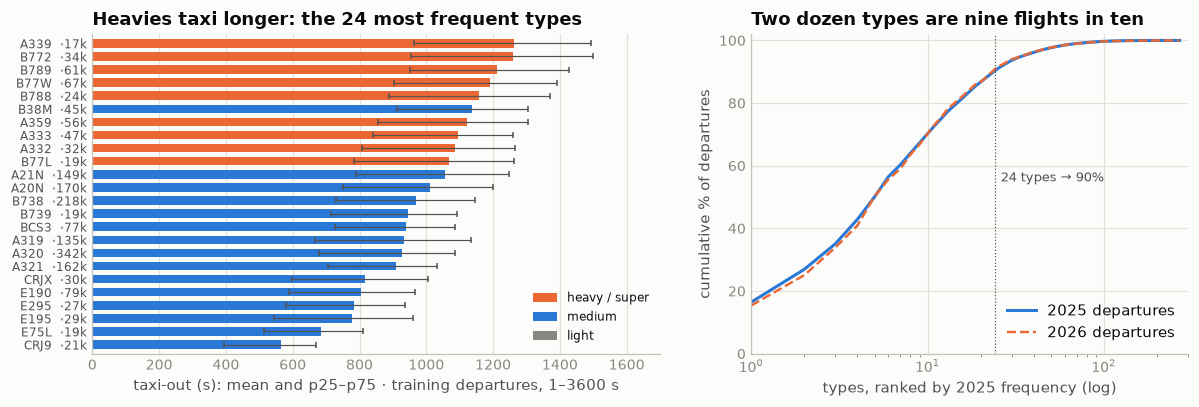

In [5]:
# how many types matter, whether 2026 brings new ones, and taxi-out by type (training departures, 1–3600 s)
print("the 24 most frequent types — nine departures in ten:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct,
           round(100.0*sum(count(*)) OVER (ORDER BY count(*) DESC, AIRCRAFT_TYPE_mvt)/sum(count(*)) OVER (), 1) cum_pct,
           mode(WK_TBL_CAT_flt) wake, round(avg(TAXITIME_SEC_mvt)) mean_taxi, quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM {TGT} WHERE AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 24""").df().to_string(index=False))

print("\ncoverage — types ranked by 2025 frequency, cumulative share of departures, 2025 vs 2026:")
print(con.sql(f"""
    WITH c AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1),
         rk AS (SELECT typ, row_number() OVER (ORDER BY n DESC, typ) rk FROM c),
         r AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {R} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1)
    SELECT k top_types, round(100.0*(SELECT sum(c.n) FROM c JOIN rk USING (typ) WHERE rk.rk <= k)/(SELECT sum(n) FROM c), 1) pct_2025,
           round(100.0*(SELECT sum(r.n) FROM r JOIN rk USING (typ) WHERE rk.rk <= k)/(SELECT sum(n) FROM r), 1) pct_2026
    FROM (VALUES (5), (10), (24), (50), (71), (100), (270)) v(k) ORDER BY k""").df().to_string(index=False))

print("\n2026 departures whose type is new, or rare in 2025:")
print(con.sql(f"""
    WITH c AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT count(*) FILTER (c.typ IS NULL) rows_of_unseen_types, count(DISTINCT r.AIRCRAFT_TYPE_mvt) FILTER (c.typ IS NULL) unseen_types,
           string_agg(DISTINCT r.AIRCRAFT_TYPE_mvt, ' ') FILTER (c.typ IS NULL) unseen_list,
           count(*) FILTER (c.n < 30) rows_of_types_under_30_in_2025,
           count(*) FILTER (c.n < 200) rows_of_types_under_200_in_2025
    FROM {R} r LEFT JOIN c ON c.typ = r.AIRCRAFT_TYPE_mvt WHERE r.PHASE_mvt = 'DEP' AND r.AIRCRAFT_TYPE_mvt IS NOT NULL""").df().to_string(index=False))

top = con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n, mode(WK_TBL_CAT_flt) wake, avg(TAXITIME_SEC_mvt) m,
           quantile_cont(TAXITIME_SEC_mvt, 0.25) p25, quantile_cont(TAXITIME_SEC_mvt, 0.75) p75
    FROM {TGT} WHERE AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 24""").df().sort_values("m")
cov = con.sql(f"""
    WITH c AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1),
         rk AS (SELECT typ, n, row_number() OVER (ORDER BY n DESC, typ) rk FROM c),
         r AS (SELECT AIRCRAFT_TYPE_mvt typ, count(*) n FROM {R} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1)
    SELECT rk.rk, 100.0*sum(rk.n) OVER (ORDER BY rk.rk)/(SELECT sum(n) FROM c) pct_2025,
           100.0*sum(coalesce(r.n, 0)) OVER (ORDER BY rk.rk)/(SELECT sum(n) FROM r) pct_2026
    FROM rk LEFT JOIN r USING (typ) ORDER BY rk.rk""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
col = {"H": ORANGE, "J": ORANGE, "M": BLUE, "L": MUTED}
yy = np.arange(len(top))
a1.barh(yy, top.m, height=0.65, color=[col.get(w, BASELINE) for w in top.wake])
a1.errorbar(top.m, yy, xerr=[top.m - top.p25, top.p75 - top.m], fmt="none", ecolor=INK2, elinewidth=0.8, capsize=2)
a1.set_yticks(yy, [f"{t}  ·{n/1000:.0f}k" for t, n in zip(top.typ, top.n)], fontsize=8, color=INK2)
a1.set_xlim(0, 1700)
a1.set_title("Heavies taxi longer: the 24 most frequent types")
a1.set_xlabel("taxi-out (s): mean and p25–p75 · training departures, 1–3600 s")
for w, lbl in [("H", "heavy / super"), ("M", "medium"), ("L", "light")]:
    a1.barh([-10], [0], color=col[w], label=lbl)
a1.set_ylim(-0.7, len(top) - 0.3)
a1.legend(loc="lower right", fontsize=8)
style(a1, x_grid=True, y_grid=False)
a2.plot(cov.rk, cov.pct_2025, color=BLUE, lw=2, label="2025 departures")
a2.plot(cov.rk, cov.pct_2026, color=ORANGE, lw=1.6, ls="--", label="2026 departures")
a2.set_xscale("log")
a2.axvline(24, color=INK2, lw=0.8, ls=":")
a2.text(26, 55, "24 types → 90%", fontsize=8.5, color=INK2)
a2.set_xlim(1, 300)
a2.set_ylim(0, 102)
a2.set_title("Two dozen types are nine flights in ten")
a2.set_xlabel("types, ranked by 2025 frequency (log)")
a2.set_ylabel("cumulative % of departures")
a2.legend(loc="lower right")
style(a2, x_grid=True)
fig.tight_layout(w_pad=2.5)
plt.show()


In [6]:
# two things the type carries beyond itself: the wake-turbulence class (a lookup that fills the plan's missing category)
# and rotorcraft (§4a's list, completed by a systematic search of the codes)
con.sql(f"""
    CREATE OR REPLACE TABLE typ_wake AS
    SELECT typ, arg_max(wk, n) wake_from_type, max(n)/sum(n) purity, sum(n) n
    FROM (SELECT AIRCRAFT_TYPE_mvt typ, WK_TBL_CAT_flt wk, count(*) n FROM {T}
          WHERE PHASE_mvt = 'DEP' AND WK_TBL_CAT_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL GROUP BY 1, 2)
    GROUP BY 1""")
print("wake class from the type — one class per type, learned from 2025 departures with a plan:")
print(con.sql("""
    SELECT count(*) n_types, count(*) FILTER (purity < 0.98) impure_types, round(100.0*sum(n) FILTER (purity >= 0.98)/sum(n), 2) pct_rows_in_pure_types,
           string_agg(typ || ' ' || round(100*purity) || '%', ', ') FILTER (purity < 0.98) impure_list
    FROM typ_wake""").df().to_string(index=False))
print(con.sql(f"""
    SELECT src, count(*) departures, count(*) FILTER (WK_TBL_CAT_flt IS NULL) plan_wake_null,
           count(*) FILTER (WK_TBL_CAT_flt IS NULL AND l.wake_from_type IS NOT NULL) filled_from_type,
           count(*) FILTER (WK_TBL_CAT_flt IS NULL AND l.wake_from_type IS NULL) still_null,
           round(100.0*count(*) FILTER (l.wake_from_type = WK_TBL_CAT_flt)/count(*) FILTER (WK_TBL_CAT_flt IS NOT NULL AND l.wake_from_type IS NOT NULL), 2) pct_agree_where_both
    FROM {BOTH} d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
print("\nwake class and taxi-out, plan's class where present else the type's (training departures, 1–3600 s):")
print(con.sql(f"""
    SELECT coalesce(WK_TBL_CAT_flt, l.wake_from_type, '∅') wake, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct,
           round(avg(TAXITIME_SEC_mvt)) mean_taxi, quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM {TGT} d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

# rotorcraft: every ICAO rotorcraft designator we could name, checked against the data; the ones present join §4a's list
CANDIDATES = ("('A119','A129','A149','AS55','AS65','B105','B212','B222','B412','B427','B430','B47G','B47T','EC25','EC30','EC75',"
              "'H135','H175','H225','H500','H53','H60','H64','R22','R66','S64','S65','MD52','MD60','AS3B','G2CA','A2RT','CH7A',"
              "'K126','KA32','MI8','MI17','MI2','UH1','UH60','S70','BK17','EXPL','ALO2','ALO3','GAZL','HUCO','S330','RVAL')")
print("\nrotorcraft codes present in the data beyond §4a's list (both files, both phases):")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n, count(*) FILTER (PHASE_mvt = 'DEP') dep,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (PHASE_mvt = 'DEP')) med_taxi_out,
           mode(CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) hub, mode(FLIGHT_RULE_mvt) rule_,
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL) rule_null
    FROM {BOTH} WHERE AIRCRAFT_TYPE_mvt IN {CANDIDATES} AND AIRCRAFT_TYPE_mvt NOT IN {HELI_ALL}
    GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))
ROTORCRAFT = HELI_ALL[:-1] + ",'EC30','G2CA','R66','R22','AS55','GAZL','AS65','A119','H53','H60')"
print("\nrotorcraft (the completed list) per hub — training departures, raw labels:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi, round(quantile_cont(TAXITIME_SEC_mvt, 0.9)) p90,
           round(100.0*count(*) FILTER (FLIGHT_RULE_mvt = 'V')/count(*), 1) pct_vfr, mode(RUNWAY_mvt) rwy
    FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_mvt IN {ROTORCRAFT} GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))
print("\nand the one generic code:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n, count(*) FILTER (PHASE_mvt = 'DEP') dep, mode(CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) hub,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan
    FROM {BOTH} WHERE AIRCRAFT_TYPE_mvt = 'ZZZZ' GROUP BY 1""").df().to_string(index=False))


wake class from the type — one class per type, learned from 2025 departures with a plan:
 n_types  impure_types  pct_rows_in_pure_types                                  impure_list
     238             4                   99.99 B350 93.0%, SW3 75.0%, SW4 94.0%, ZZZZ 59.0%
     src  departures  plan_wake_null  filled_from_type  still_null  pct_agree_where_both
training     2085047           22544             20490        2054                 99.99
 ranking      344841            5304              4810         494                 99.99

wake class and taxi-out, plan's class where present else the type's (training departures, 1–3600 s):
wake       n   pct  mean_taxi  med_taxi
   M 1628202 78.26      932.0     878.0
   H  424128 20.39     1166.0    1090.0
   J   14768  0.71     1404.0    1327.0
   L   12275  0.59      652.0     552.0
   ∅    1160  0.06      868.0     850.5

rotorcraft codes present in the data beyond §4a's list (both files, both phases):
 typ  n  dep  med_taxi_out  hub rul

In [7]:
# what the type buys — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the coarser rung:
# on top of the airport; on top of airport × runway × AOBT_3 anchor (§9's base); and the coarser forms as fallbacks
con.sql(f"""
    CREATE OR REPLACE TABLE typ_d AS
    SELECT ADEP_mvt hub, RUNWAY_mvt rwy, AIRCRAFT_TYPE_mvt typ, AIRCRAFT_TYPE_flt typ_plan,
           coalesce(WK_TBL_CAT_flt, l.wake_from_type) wake, (AIRCRAFT_TYPE_mvt IN {ROTORCRAFT}) rotor,
           TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor
    FROM {TGT} d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt""")


def typ_cat(keys):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM typ_d WHERE NOT is_val GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM typ_d WHERE NOT is_val GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM typ_d v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM typ_d WHERE is_val").fetchone()[0]
print(f"(1) on top of the airport mean — {n_val:,} Nov+Dec departures:")
for name, keys in [("airport", "hub"), ("+ type (movement)", "hub, typ"), ("+ type (plan; missing = own level)", "hub, typ_plan"),
                   ("+ wake class", "hub, wake"), ("+ rotorcraft flag", "hub, rotor"), ("+ wake class, then type on top", "hub, wake, typ")]:
    print(f"    {name:40s} {typ_cat(keys):7.1f} s")

con.sql("""
    CREATE OR REPLACE TABLE typ_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa FROM typ_d WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT typ_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc FROM typ_d JOIN cuts USING (hub)
    WHERE rwy IS NOT NULL AND anchor IS NOT NULL""")


def typ_rungs(rungs):
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE typ_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM typ_wb WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN typ_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN typ_s{i}.c >= 30 THEN typ_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM typ_wb v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM typ_wb WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]), ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"])]
n_val = con.sql("SELECT count(*) FROM typ_wb WHERE is_val").fetchone()[0]
print(f"\n(2) on top of airport × runway × anchor — the {n_val:,} Nov+Dec departures with runway and anchor (§9's base):")
for name, r in typ_rungs(BASE):
    print(f"    {name:40s} {r:7.1f} s")
for name, keys in [("+ type", ["typ"]), ("+ wake class", ["wake"]), ("+ wake class, then type on top", ["wake", "typ"])]:
    rung = BASE + [(f"r{i}", ["hub", "rwy", "q_anc"] + keys[:i + 1]) for i in range(len(keys))]
    print(f"    {name:40s} {typ_rungs(rung)[-1][1]:7.1f} s")

print("\nthe same type, different hubs — median taxi-out of two workhorses and one heavy (training, 1–3600 s):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (AIRCRAFT_TYPE_mvt = 'A320')) a320,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (AIRCRAFT_TYPE_mvt = 'B738')) b738,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (AIRCRAFT_TYPE_mvt = 'B77W')) b77w,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) all_types
    FROM {TGT} GROUP BY 1 ORDER BY all_types""").df().to_string(index=False))


(1) on top of the airport mean — 327,485 Nov+Dec departures:
    airport                                    357.3 s
    + type (movement)                          338.0 s
    + type (plan; missing = own level)         338.5 s
    + wake class                               347.3 s
    + rotorcraft flag                          357.1 s
    + wake class, then type on top             338.0 s



(2) on top of airport × runway × anchor — the 324,631 Nov+Dec departures with runway and anchor (§9's base):
    airport                                    355.4 s
    + runway                                   341.8 s
    + AOBT_3 anchor                            283.6 s
    + type                                     274.5 s


    + wake class                               279.0 s
    + wake class, then type on top             273.4 s

the same type, different hubs — median taxi-out of two workhorses and one heavy (training, 1–3600 s):
 hub   a320   b738   b77w  all_types
LSZH  703.0  733.0  880.0      712.0
EHAM  752.0  686.0  881.0      742.0
EDDM  769.0  834.0  900.0      774.0
EDDF  742.0  987.0 1023.0      837.0
LEBL  797.0 1099.0 1000.0      906.0
LFPG  845.0  957.0 1081.0      954.0
LTFM  901.0  911.0 1073.0      963.0
LEMD  905.0 1031.0  961.0      985.0
LIRF  962.0  964.0 1251.0     1022.0
EGLL 1311.0 1255.0 1381.0     1319.0


In [8]:
# closing state — the column after §11: nothing filled. The plan's type is never there when the movement's is missing,
# and the missing type is a marker in its own right (10a's slice), so the null stays
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL) type_null_before,
           count(*) FILTER (coalesce(AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt) IS NULL) type_null_after_coalesce,
           count(*) FILTER (WK_TBL_CAT_flt IS NULL) wake_null_before,
           count(*) FILTER (coalesce(WK_TBL_CAT_flt, l.wake_from_type) IS NULL) wake_null_after_lookup
    FROM {BOTH} d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))
print("\ntype: before = after on every count. Wake class: the type's lookup fills the plan's gaps (a derived form, not a repair of this column)")


     src  ph       n  type_null_before  type_null_after_coalesce  wake_null_before  wake_null_after_lookup
training ARR 2082750               142                       142             15516                     679
training DEP 2085047              1507                      1507             22544                    2054
 ranking ARR  344693                21                        21              2564                     125
 ranking DEP  344841               388                       388              5304                     494

type: before = after on every count. Wake class: the type's lookup fills the plan's gaps (a derived form, not a repair of this column)


                                                feature        kind  n / levels  pearson_r  spearman_ρ     η
                           aircraft type — the raw code categorical         150                        0.359
                                        the plan's type categorical         142                        0.353
type — the plan's code first, else the movement's (11a) categorical         149                        0.359
                                wake class — the plan's categorical           5                        0.263
            wake class — plan's, else the type's lookup categorical           5                        0.267
                                          is rotorcraft categorical           3                        0.051
                                           type missing categorical           2                        0.004
                           type disagrees with the plan categorical           3                        0.010


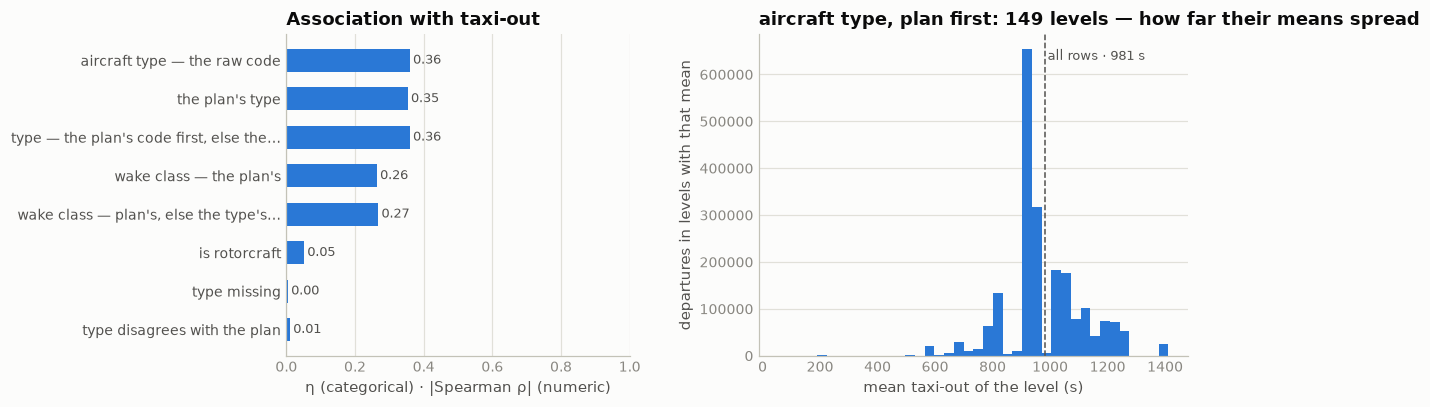

In [8]:
# correlation with the target: the raw code, the plan's code, 11a's final form, the two wake classes, the rotorcraft flag,
# and the two flags a missing or disagreeing type raises
a = target_assoc([("aircraft type — the raw code", "cat", "AIRCRAFT_TYPE_mvt", 30),
                  ("the plan's type", "cat", "AIRCRAFT_TYPE_flt", 30),
                  ("type — the plan's code first, else the movement's (11a)", "cat", TYPE_FINAL, 30),
                  ("wake class — the plan's", "cat", "WK_TBL_CAT_flt"),
                  ("wake class — plan's, else the type's lookup", "cat", "coalesce(WK_TBL_CAT_flt, l.wake_from_type)", 1,
                   f"({TGT[1:-1]}) d LEFT JOIN typ_wake l ON l.typ = d.AIRCRAFT_TYPE_mvt"),
                  ("is rotorcraft", "cat", f"AIRCRAFT_TYPE_mvt IN {ROTORCRAFT}"),
                  ("type missing", "cat", "AIRCRAFT_TYPE_mvt IS NULL"),
                  ("type disagrees with the plan", "cat", "AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt")])
assoc_chart(a, TYPE_FINAL, kind="cat", min_support=30, title="aircraft type, plan first")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Present on all but 0.07% of departures — and the missing ones are one slice** | 1,507 training departures without a type, 1,487 of them at LIRF; 388 in the ranking file, 383 at LIRF. Every one lacks a plan, and no plan-less Fiumicino departure has a type (1,487 / 0 / 0 in training, 383 / 0 / 0 in ranking), while elsewhere 20,917 plan-less departures do. Their labels: median 3,953 s, 29.1% over 7,200 s | a missing type at Fiumicino *is* 10a's corrupt slice, in one column. The null stays: a tree branches on it |
| **The plan's copy agrees 99.66% of the time; the disagreements are variants** | B772 vs B77L 40.8% of them, AT72 vs AT76 20.0%, E75S vs E170 8.4%; by segment cargo 4.57%, non-scheduled 4.03%, mainline 0.12% | the first reading here was to keep the movement's, the two being worth the same on the ladder (338.5 vs 338.0 s). 11a sorts the disagreements: three quarters are per-hub spellings, and Schiphol's changed in November 2025 — so the final form takes the plan's code first |
| **Two dozen types are nine departures in ten** | 269 types; 5 cover 50.0%, 24 cover 90.3%, 71 cover 99.1% — and 2026 to the decimal (90.8% / 99.0%); 18 rows of 8 unseen types, 141 rows of types with under 30 departures in 2025 | the code works as a native categorical; the tail that needs a fallback is a few hundred rows |
| **Heavies taxi four minutes longer than mediums; lights half as long** | medians by wake class: M 878 s, H 1,090, J 1,327, L 552; among the top 24 types, CRJ9 535 s to A339 1,201 | size is the type's first signal — long-haul stands sit far from the runway, and heavies need the long one |
| **The hub still dominates the type** | A320 median 703 s at LSZH, 1,311 at EGLL; B77W 880 to 1,381; the hubs' own medians 712 to 1,319 | the type is a within-airport adjustment: airport × type, never type alone |
| **The type buys 19 s on the airport and 9 s on the anchor base — the raw code, not its class** | airport 357.3 → + type **338.0**, + wake class 347.3, + rotorcraft flag 357.1; runway × anchor 283.6 → + type **274.5**, + wake class 279.0, class then type 273.4 | the ladder's third-largest step after the anchor and the runway; the class carries half of it, the code the rest |
| **One wake class per type — and it fills the plan's gaps** | 238 types with a class, 4 impure (`B350`, `SW3`, `SW4`, `ZZZZ`); the lookup agrees with the plan 99.99% where both exist; it fills 20,490 of the 22,544 missing classes on training departures and 4,810 of 5,304 in ranking, leaving the type-less rows (2,054 / 494) | a derived form for the wake-category section, not a repair of this column |
| **§4a's rotorcraft list missed ten codes** | `EC30` 64 rows, `G2CA` 14, `R66` 12, `R22` 10, `AS55`, `A119`, `H53` 4 each, `GAZL`, `AS65`, `H60` 2 each — 118 rows, 59 departures, two of them without a rule. The completed list per hub: EHAM 1,028 departures (median 177 s, off runway 22), LSZH 397 (median 1 s, off helipad `H`), EDDM 24 (419 s) | `ROTORCRAFT`, defined here, supersedes `HELI_ALL` from this section on; §4a's counts stand as written |
| One generic code | `ZZZZ`: 67 rows, 31 departures, at LFPG, median label 569 s, 3 without a plan | a real aircraft of undeclared type; its own level, not a null |

**Decisions**

| issue | decision | why |
|---|---|---|
| the missing type | **left null** | it marks 10a's slice, and the plan's copy never exists where it is missing |
| the plan's copy | **first, where it exists** — `TYPE_FINAL` (11a); the movement's where there is no plan | Schiphol changed its spelling of the 777 freighter in November 2025 and 2026 follows the plan's; elsewhere the two are equal |
| coarser forms | the raw code is the feature; the wake class is a derived form for its own section | class then code beats code alone by 1.1 s |
| the rotorcraft list | `ROTORCRAFT` = `HELI_ALL` + the ten codes found here | the systematic search over every rotorcraft designator we could name |
| `ZZZZ` | its own level | a real aircraft, a normal taxi |

**State after §11** — unchanged: 1,507 / 388 departures without a type before and after; nothing repaired.

**Use in modeling.** The type as `TYPE_FINAL` (11a), a native categorical, per airport, with the
null kept as a level. Rare codes fall back to the wake class of the type's lookup; unseen
codes to the airport. The rotorcraft × airport flag of §4 is built from `ROTORCRAFT`. In the closing
matrix the column enters as `TYPE_FINAL`, rare codes pooled below 200 rows: 0.70 with the flight number (a fleet
is an airline), 0.49 with the rule, 0.36 with the target.


### 11a · When the movement and the plan disagree on the type

Two records of one aircraft: the airport's, `AIRCRAFT_TYPE_mvt`, and the operator's filing,
`AIRCRAFT_TYPE_flt`. They differ on 7,013 training departures — 0.34% of the matched ones. §11
took the movement's code on the grounds that the two are worth the same on the ladder. This
sub-section asks what the disagreements are, which side is right, and whether the choice matters
anywhere. It does, in one place, and that place reverses §11's decision.

| what a disagreement can be | how to tell |
|---|---|
| an **airport convention** — one hub writes a sibling or generic code for every flight the plan files as X | the same plan code at other hubs: one hub near 100%, the rest at 0 |
| a **swap** — a different variant flew than was filed | many operators, no hub pattern, each side true to its own history |
| a **stale plan** — one number filed all year with a type it does not fly | one operator, one number, the airport's code consistent everywhere else |


In [6]:
# 11a — the departures whose movement type and plan type differ: what kind of difference, where, and how often
DIS = (f"(SELECT * FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL "
       f"AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt)")
print("what kind of difference (training departures, raw labels):")
print(con.sql(f"""
    SELECT count(*) n,
           count(*) FILTER (substr(AIRCRAFT_TYPE_mvt, 1, 1) = substr(AIRCRAFT_TYPE_flt, 1, 1)) same_maker_letter,
           count(*) FILTER (substr(AIRCRAFT_TYPE_mvt, 1, 3) = substr(AIRCRAFT_TYPE_flt, 1, 3)) same_first_three,
           count(*) FILTER (lm.wake_from_type = lp.wake_from_type) same_wake_class,
           count(*) FILTER (lm.wake_from_type != lp.wake_from_type) wake_class_differs
    FROM {DIS} d LEFT JOIN typ_wake lm ON lm.typ = d.AIRCRAFT_TYPE_mvt LEFT JOIN typ_wake lp ON lp.typ = d.AIRCRAFT_TYPE_flt""").df().to_string(index=False))
print("    the pairs that change the wake class, most frequent first:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt || '→' || AIRCRAFT_TYPE_flt pair, lm.wake_from_type || '→' || lp.wake_from_type wake, count(*) n, mode(ADEP_mvt) hub
    FROM {DIS} d JOIN typ_wake lm ON lm.typ = d.AIRCRAFT_TYPE_mvt JOIN typ_wake lp ON lp.typ = d.AIRCRAFT_TYPE_flt
    WHERE lm.wake_from_type != lp.wake_from_type GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

print("\nthe ten most frequent pairs — where, whose, and the wake class of each code:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt movement, AIRCRAFT_TYPE_flt plan, count(*) n, arg_max(ADEP_mvt, c_hub) hub,
           round(100.0*max(c_hub)/count(*)) pct_at_that_hub,
           count(DISTINCT AIRCRAFT_OPERATOR_flt) n_operators, round(100.0*max(c_op)/count(*)) pct_top_operator,
           mode(MARKET_SEGMENT_flt) segment, any_value(lm.wake_from_type) wake_movement, any_value(lp.wake_from_type) wake_plan
    FROM (SELECT *, count(*) OVER (PARTITION BY AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt, AIRCRAFT_OPERATOR_flt) c_op,
                    count(*) OVER (PARTITION BY AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt, ADEP_mvt) c_hub FROM {DIS}) d
    LEFT JOIN typ_wake lm ON lm.typ = d.AIRCRAFT_TYPE_mvt LEFT JOIN typ_wake lp ON lp.typ = d.AIRCRAFT_TYPE_flt
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 10""").df().to_string(index=False))

print("\nby hub — rate among matched departures, and the pair that dominates there:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt) n_differ,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt)/count(*), 2) pct,
           arg_max(pair, c) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt) top_pair
    FROM (SELECT ADEP_mvt, AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt, AIRCRAFT_TYPE_mvt || '→' || AIRCRAFT_TYPE_flt pair,
                 count(*) OVER (PARTITION BY ADEP_mvt, AIRCRAFT_TYPE_mvt, AIRCRAFT_TYPE_flt) c
          FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL)
    GROUP BY 1 ORDER BY pct DESC""").df().to_string(index=False))

print("\nrate by month in training, and in the ranking file:")
print(con.sql(f"""
    SELECT yr, month(MVT_TIME_UTC_mvt) mon, count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt) n_differ,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt)/count(*), 2) pct
    FROM (SELECT 2025 yr, * FROM {T} UNION ALL SELECT 2026, * FROM {R})
    WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL
    GROUP BY 1, 2 ORDER BY 1, 2""").df().set_index(["yr", "mon"]).T.to_string())
print("\nSchiphol's B772→B77L by month — a convention that ended:")
print(con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) FILTER (AIRCRAFT_TYPE_mvt = 'B772') recorded_b772,
           count(*) FILTER (AIRCRAFT_TYPE_mvt = 'B77L') recorded_b77l
    FROM (SELECT * FROM {T} UNION ALL SELECT * FROM {R}) WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM' AND AIRCRAFT_TYPE_flt = 'B77L'
    GROUP BY 1, 2 ORDER BY 1, 2""").df().set_index(["yr", "mon"]).T.to_string())
print("\nthe other conventions in the ranking file — plan code → share the movement side still records as the first code:")
print(pd.DataFrame([(hub, f"{m}→{p}", *con.sql(f"""SELECT count(*), round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt = '{m}')/count(*)) FROM {R}
                                                     WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = '{hub}' AND AIRCRAFT_TYPE_flt = '{p}'""").fetchone())
                    for hub, m, p in [("EHAM", "B772", "B77L"), ("LFPG", "AT72", "AT76"), ("EGLL", "AT72", "AT76"), ("EDDF", "E75S", "E170"), ("LFPG", "E195", "E295")]],
                   columns=["hub", "pair", "plan_rows_2026", "pct_still_recorded_as_first"]).to_string(index=False))
print("\nthe ranking file's pairs:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt movement, AIRCRAFT_TYPE_flt plan, count(*) n, mode(ADEP_mvt) hub
    FROM {R} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))


what kind of difference (training departures, raw labels):
   n  same_maker_letter  same_first_three  same_wake_class  wake_class_differs
7013               6771              4846             6713                 288
    the pairs that change the wake class, most frequent first:
     pair wake   n  hub
B763→B738  H→M 199 LFPG
A321→A332  M→H   8 EDDF
C25C→C25M  M→L   6 LSZH
B738→A332  M→H   6 LTFM
C25A→C56X  L→M   4 LTFM
A321→A359  M→H   3 EGLL

the ten most frequent pairs — where, whose, and the wake class of each code:


movement plan    n  hub  pct_at_that_hub  n_operators  pct_top_operator       segment wake_movement wake_plan
    B772 B77L 2855 EHAM             99.0           17              29.0         Cargo             H         H
    AT72 AT76 1403 LFPG             74.0            7              38.0         Cargo             M         M
    E75S E170  588 EDDF            100.0            3              84.0      Regional             M         M
    B763 B738  199 LFPG            100.0            1             100.0      Mainline             H         M
    A320 A20N  159 LFPG             53.0           23              47.0       Lowcost             M         M
    AT72 AT75  136 LFPG             98.0            3              71.0 Non-Scheduled             M         M
    E195 E295  113 LFPG             93.0            3              92.0      Mainline             M         M
    A20N A320  102 LFPG             73.0           15              67.0       Lowcost             M         M
    B738 B

 hub  n_differ  pct  top_pair
EHAM      3093 1.27 B772→B77L
LFPG      2264 0.96 AT72→AT76
EDDF       674 0.30 E75S→E170
EGLL       410 0.17 AT72→AT76
LTFM       333 0.12 A320→A20N
LSZH       147 0.11 S22T→SR22
EDDM        67 0.04 E195→E190
LEBL        13 0.01 A20N→A320
LEMD        12 0.01 A320→A20N
LIRF         0 0.00       NaN

rate by month in training, and in the ranking file:
yr          2025                                                                                          2026        
mon           1       2       3       4       5       6       7       8       9       10     11      12     1       7 
n_differ  527.00  519.00  607.00  616.00  650.00  671.00  707.00  641.00  635.00  650.00  483.0  307.00  300.0  312.00
pct         0.35    0.36    0.37    0.35    0.35    0.37    0.38    0.34    0.35    0.35    0.3    0.19    0.2    0.16

Schiphol's B772→B77L by month — a convention that ended:


yr            2025                                                        2026     
mon             1    2    3    4    5    6    7    8    9    10   11   12   1    7 
recorded_b772  268  244  283  271  282  255  258  262  256  301  157    0    0    0
recorded_b77l    1    1   20    0    3    0    0    0    0    1  127  311  300  322

the other conventions in the ranking file — plan code → share the movement side still records as the first code:
 hub      pair  plan_rows_2026  pct_still_recorded_as_first
EHAM B772→B77L             622                          0.0
LFPG AT72→AT76             187                        100.0
EGLL AT72→AT76              71                        100.0
EDDF E75S→E170              55                        100.0
LFPG E195→E295              12                         58.0

the ranking file's pairs:
movement plan   n  hub
    AT72 AT76 262 LFPG
    E75S E170  55 EDDF
    AT72 AT73  30 LFPG
    A320 A20N  16 LFPG
    A20N A320  13 LFPG
    B763 B738  11 LFPG


In [7]:
# which side is right? Three referees: the same plan code at other hubs (an airport's convention shows as one hub near
# 100% and the rest at 0), each side's own history for the flight number, and — what matters — the honest ladder on
# the rows that differ
print("referee 1 — of all departures the plan files as the second code, the share each hub's movement side records as the first (hubs with ≥ 20):")
PAIRS = [("B772", "B77L"), ("AT72", "AT76"), ("E75S", "E170"), ("B763", "B738"), ("A320", "A20N"), ("AT72", "AT75"),
         ("E195", "E295"), ("B738", "B38M"), ("A321", "A21N"), ("E135", "E35L")]
grid = pd.concat([con.sql(f"""
    SELECT '{m}→{p}' pair, ADEP_mvt hub, count(*) n_plan_rows, round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt = '{m}')/count(*)) pct
    FROM {T} WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt = '{p}' AND AIRCRAFT_TYPE_mvt IS NOT NULL
    GROUP BY 1, 2 HAVING count(*) >= 20""").df() for m, p in PAIRS], ignore_index=True)
print(grid.pivot(index="pair", columns="hub", values="pct").reindex([f"{m}→{p}" for m, p in PAIRS]).fillna("·").to_string())

print("\nreferee 2 — the type each side usually gives that flight number at that hub over 2025 (numbers with ≥ 10 departures):")
con.sql(f"""
    CREATE OR REPLACE TABLE typ_usual AS
    SELECT hub, fn, arg_max(m, nm) usual_movement, arg_max(p, np) usual_plan, sum(nm) n_flights
    FROM (SELECT ADEP_mvt hub, FLIGHT_mvt fn, AIRCRAFT_TYPE_mvt m, AIRCRAFT_TYPE_flt p,
                 count(*) OVER (PARTITION BY ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_mvt) nm,
                 count(*) OVER (PARTITION BY ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_flt) np
          FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL AND AIRCRAFT_TYPE_flt IS NOT NULL)
    GROUP BY 1, 2""")
print(con.sql(f"""
    SELECT count(*) n_differ, count(*) FILTER (u.n_flights >= 10) with_history,
           round(100.0*count(*) FILTER (u.n_flights >= 10 AND u.usual_movement = d.AIRCRAFT_TYPE_mvt)/count(*) FILTER (u.n_flights >= 10), 1) movement_is_its_usual,
           round(100.0*count(*) FILTER (u.n_flights >= 10 AND u.usual_plan = d.AIRCRAFT_TYPE_flt)/count(*) FILTER (u.n_flights >= 10), 1) plan_is_its_usual,
           round(100.0*count(*) FILTER (u.n_flights >= 10 AND u.usual_movement = d.AIRCRAFT_TYPE_mvt AND u.usual_plan = d.AIRCRAFT_TYPE_flt)/count(*) FILTER (u.n_flights >= 10), 1) both_are_their_usual
    FROM {DIS} d LEFT JOIN typ_usual u ON u.hub = d.ADEP_mvt AND u.fn = d.FLIGHT_mvt""").df().to_string(index=False))

print("\nthe one pair that changes the wake class — B763→B738, one operator at LFPG: its LFPG departures by plan × movement type:")
OP = f"(SELECT mode(AIRCRAFT_OPERATOR_flt) FROM {DIS} WHERE AIRCRAFT_TYPE_mvt = 'B763' AND AIRCRAFT_TYPE_flt = 'B738')"
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_flt plan, AIRCRAFT_TYPE_mvt movement, count(*) n, count(DISTINCT FLIGHT_mvt) n_numbers, mode(STAND_mvt) stand,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LFPG' AND AIRCRAFT_OPERATOR_flt = {OP}
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))
print("    the same operator's B738 plans at other hubs, as the movement side records them:")
print(con.sql(f"""
    SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt movement, count(*) n FROM {T}
    WHERE PHASE_mvt = 'DEP' AND ADEP_mvt != 'LFPG' AND AIRCRAFT_TYPE_flt = 'B738' AND AIRCRAFT_OPERATOR_flt = {OP}
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))
print("    B763 and B738 at LFPG in general (training, 1–3600 s):")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt movement, count(*) n, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi, mode(STAND_mvt) stand
    FROM {TGT} WHERE ADEP_mvt = 'LFPG' AND AIRCRAFT_TYPE_mvt IN ('B763', 'B738') GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nreferee 3 — honest ladder on the rows that differ: airport × type means fitted on Jan–Oct (all departures, 1–3600 s), scored on the Nov+Dec rows that differ:")
con.sql(f"""
    CREATE OR REPLACE TABLE typ_dis AS
    SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt tm, AIRCRAFT_TYPE_flt tp, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt differs
    FROM {TGT}""")
print(con.sql("""
    WITH fm AS (SELECT hub, tm, avg(y) m, count(*) c FROM typ_dis WHERE NOT is_val GROUP BY 1, 2),
         fp AS (SELECT hub, tp, avg(y) m, count(*) c FROM typ_dis WHERE NOT is_val GROUP BY 1, 2),
         h AS (SELECT hub, avg(y) m FROM typ_dis WHERE NOT is_val GROUP BY 1)
    SELECT count(*) n_rows_that_differ, round(sqrt(avg((y - h.m)^2)), 1) airport,
           round(sqrt(avg((y - coalesce(CASE WHEN fm.c >= 30 THEN fm.m END, h.m))^2)), 1) airport_x_movement_type,
           round(sqrt(avg((y - coalesce(CASE WHEN fp.c >= 30 THEN fp.m END, h.m))^2)), 1) airport_x_plan_type
    FROM typ_dis JOIN h USING (hub) LEFT JOIN fm USING (hub, tm) LEFT JOIN fp USING (hub, tp) WHERE is_val AND differs""").df().to_string(index=False))
TYPE_FINAL = "coalesce(AIRCRAFT_TYPE_flt, AIRCRAFT_TYPE_mvt)"
print("\nthe three forms on the same ladder — airport × type, fit Jan–Oct, scored on Nov+Dec (1–3600 s):")
con.sql(f"""CREATE OR REPLACE TABLE typ_dis AS
            SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt tm, AIRCRAFT_TYPE_flt tp, {TYPE_FINAL} tpf, TAXITIME_SEC_mvt::DOUBLE y,
                   month(MVT_TIME_UTC_mvt) >= 11 is_val,
                   AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt differs
            FROM {TGT}""")


def typ_form(col, where="TRUE"):
    return con.sql(f"""
        WITH f AS (SELECT hub, {col} t, avg(y) m, count(*) c FROM typ_dis WHERE NOT is_val GROUP BY 1, 2),
             h AS (SELECT hub, avg(y) m FROM typ_dis WHERE NOT is_val GROUP BY 1)
        SELECT round(sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2)), 1), count(*)
        FROM typ_dis v LEFT JOIN f ON f.hub = v.hub AND f.t = v.{col} JOIN h ON h.hub = v.hub WHERE v.is_val AND {where}""").fetchone()


rows = []
for scope, where in [("all rows", "TRUE"), ("rows where the codes differ", "v.differs"), ("EHAM, plan says B77L", "v.hub = 'EHAM' AND v.tp = 'B77L'")]:
    r = [typ_form(c, where) for c in ("tm", "tp", "tpf")]
    rows.append((scope, r[0][1], r[0][0], r[1][0], r[2][0]))
print(pd.DataFrame(rows, columns=["scope", "n_val", "movement's code", "plan's code (null = own level)", "plan first, else movement"]).to_string(index=False))
print("\n    why Schiphol's freighters decide it — their Jan–Oct rows by movement code, and what Nov+Dec looked like:")
print(con.sql("""
    SELECT tm movement_code, count(*) FILTER (NOT is_val) n_fit, round(avg(y) FILTER (NOT is_val)) mean_fit,
           count(*) FILTER (is_val) n_val, round(avg(y) FILTER (is_val)) mean_val
    FROM typ_dis WHERE hub = 'EHAM' AND tp = 'B77L' GROUP BY 1 ORDER BY 2 DESC""").df().to_string(index=False))

print("\ntaxi-out where the two codes differ vs agree, per hub (medians, 1–3600 s):")
print(con.sql("""
    SELECT hub, count(*) FILTER (differs) n_differ, round(quantile_cont(y, 0.5) FILTER (differs)) med_differ,
           round(quantile_cont(y, 0.5) FILTER (NOT differs)) med_agree
    FROM typ_dis GROUP BY 1 HAVING count(*) FILTER (differs) >= 50 ORDER BY n_differ DESC""").df().to_string(index=False))

print("\nthe ranking file's mismatches under the rule — does each land on a level the training file supports at that hub?")
print(con.sql(f"""
    WITH tr AS (SELECT ADEP_mvt hub, {TYPE_FINAL} tf, AIRCRAFT_TYPE_mvt tm FROM {T} WHERE PHASE_mvt = 'DEP'),
         trf AS (SELECT hub, tf, count(*) n FROM tr GROUP BY 1, 2), trm AS (SELECT hub, tm, count(*) n FROM tr GROUP BY 1, 2),
         rk AS (SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt tm, AIRCRAFT_TYPE_flt tp, count(*) n FROM {R}
                WHERE PHASE_mvt = 'DEP' AND AIRCRAFT_TYPE_flt IS NOT NULL AND AIRCRAFT_TYPE_mvt != AIRCRAFT_TYPE_flt GROUP BY 1, 2, 3)
    SELECT rk.hub, rk.tm movement, rk.tp plan, rk.n rows_2026, coalesce(f.n, 0) training_rows_plan_first, coalesce(m.n, 0) training_rows_movement
    FROM rk LEFT JOIN trf f ON f.hub = rk.hub AND f.tf = rk.tp LEFT JOIN trm m ON m.hub = rk.hub AND m.tm = rk.tm
    ORDER BY rk.n DESC LIMIT 8""").df().to_string(index=False))
print("\nall ranking departures — share whose type level has ≥ 30 training rows at the same hub, under each form:")
print(con.sql(f"""
    WITH trf AS (SELECT ADEP_mvt hub, {TYPE_FINAL} t, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2),
         trm AS (SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt t, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2),
         rk AS (SELECT ADEP_mvt hub, AIRCRAFT_TYPE_mvt tm, {TYPE_FINAL} tf FROM {R} WHERE PHASE_mvt = 'DEP')
    SELECT count(*) n_2026, round(100.0*count(*) FILTER (f.n >= 30)/count(*), 2) pct_supported_plan_first,
           round(100.0*count(*) FILTER (m.n >= 30)/count(*), 2) pct_supported_movement,
           count(*) FILTER (f.n >= 30 AND coalesce(m.n, 0) < 30) only_plan_first_supports, count(*) FILTER (m.n >= 30 AND coalesce(f.n, 0) < 30) only_movement_supports,
           (SELECT count(*) FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM' AND {TYPE_FINAL} = 'B77L') eham_b77l_training_rows_plan_first,
           (SELECT count(*) FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM' AND AIRCRAFT_TYPE_mvt = 'B77L') eham_b77l_training_rows_movement
    FROM rk LEFT JOIN trf f ON f.hub = rk.hub AND f.t = rk.tf LEFT JOIN trm m ON m.hub = rk.hub AND m.t = rk.tm""").df().to_string(index=False))


referee 1 — of all departures the plan files as the second code, the share each hub's movement side records as the first (hubs with ≥ 20):


hub         EDDF EDDM   EGLL  EHAM  LEBL LEMD   LFPG LIRF LSZH  LTFM
pair                                                                
B772→B77L    0.0  0.0    0.0  86.0   0.0  0.0    0.0  0.0  0.0   1.0
AT72→AT76    0.0  0.0  100.0     ·   0.0  0.0  100.0  0.0    ·   1.0
E75S→E170  100.0  0.0      ·   0.0   0.0    ·    0.0    ·    ·   0.0
B763→B738    0.0  0.0    0.0   0.0   0.0  0.0    1.0  0.0  0.0   0.0
A320→A20N    0.0  0.0    0.0   0.0   0.0  0.0    1.0  0.0  0.0   1.0
AT72→AT75    0.0    ·      ·     ·   0.0  0.0  100.0    ·    ·   0.0
E195→E295    0.0  0.0    0.0   0.0   0.0  0.0   74.0  0.0  0.0   6.0
B738→B38M    0.0  0.0    0.0   0.0   0.0  0.0    3.0  0.0  1.0   0.0
A321→A21N    0.0  0.0    0.0   0.0   0.0  0.0    0.0  0.0  0.0   0.0
E135→E35L    0.0  0.0      ·   3.0   0.0  0.0      ·    ·  0.0   7.0

referee 2 — the type each side usually gives that flight number at that hub over 2025 (numbers with ≥ 10 departures):


 n_differ  with_history  movement_is_its_usual  plan_is_its_usual  both_are_their_usual
     7013          6598                   79.2               77.2                  70.7

the one pair that changes the wake class — B763→B738, one operator at LFPG: its LFPG departures by plan × movement type:
plan movement    n  n_numbers stand  med_taxi
B738     B738 1995        122   Q21     948.0
B737     B737  291         41   Q21     790.0
B734     B734  280         32   P82     790.0
B738     B763  199          1   I47    1208.0
A320     A320   12          5   Q12    1140.0
A321     A321    4          4   Q21    1765.0
    the same operator's B738 plans at other hubs, as the movement side records them:
 hub movement  n
LEMD     B738 48
EDDF     B738  5
EHAM     B738  2
LEBL     B738  2
LIRF     B738  1
    B763 and B738 at LFPG in general (training, 1–3600 s):
movement     n  med_taxi stand
    B738 15439     957.0   B12
    B763  2902    1013.0   M15

referee 3 — honest ladder on the rows th

                      scope  n_val  movement's code  plan's code (null = own level)  plan first, else movement
                   all rows 327485            338.0                           338.5                      337.9
rows where the codes differ    790            426.6                           426.7                      426.7
       EHAM, plan says B77L    595            431.5                           365.2                      365.2

    why Schiphol's freighters decide it — their Jan–Oct rows by movement code, and what Nov+Dec looked like:
movement_code  n_fit  mean_fit  n_val  mean_val
         B772   2679    1092.0    157     984.0
         B77L     26     984.0    437    1061.0
         B77W      0       NaN      1    1028.0

taxi-out where the two codes differ vs agree, per hub (medians, 1–3600 s):
 hub  n_differ  med_differ  med_agree
EHAM      3092       991.0      740.0
LFPG      2261       966.0      954.0
EDDF       673      1002.0      836.0
EGLL       408      1144.0

**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Almost every disagreement is a sibling code** | 7,013 rows; 6,771 share the maker's letter, 4,846 the first three characters; the wake class differs on 288, and 199 of those are one pair, B763→B738 | the two sides rarely describe different aircraft — they spell the same one differently |
| **Three quarters are airport conventions** | B772→B77L: 2,855 rows, 99% at EHAM, 17 operators — Schiphol records 86% of its 3,302 B77L plans as B772, every other hub 0%. AT72→AT76: 1,403 rows — LFPG and EGLL write AT72 for 100% of their AT76 plans, the other hubs 0–1%. E75S→E170: 588 rows, EDDF 100% of 587 plans. AT72→AT75: LFPG 100% | the airport's system maps some filed codes onto its own: a fixed per-hub spelling, not an error about the aircraft |
| **The rest are swaps** | A320↔A20N 261 rows across 23 and 15 operators, B738↔B38M 112, A321↔A21N 82, E190↔E195 72; referee 2: the movement's code is the number's usual movement code on 79.2% of differing rows, the plan's its usual plan code on 77.3%, both at once on 70.8% | ceo for neo, NG for MAX: the plan was filed for the fleet, the airport recorded the tail; neither side is wrong |
| **One stale plan** | B763→B738: 199 rows, one operator, one flight number at LFPG, off stand `I47` with a median taxi of 1,208 s against 948 s for the operator's 738s from `Q21`; the same operator's B738 plans are recorded B738 at every other hub | a 767 flying under a plan template that says 738: the airport is right, and the filed code carries the wrong wake class |
| **Which code predicts taxi: no difference — until a convention changes** | the 790 differing rows of Nov+Dec, airport × type means: movement's code 426.6 s, plan's 426.7; all rows 338.0 vs 338.5 | on its own the choice is worth nothing |
| **And Schiphol's changed** | EHAM's B77L plans were recorded B772 from January to October 2025 (244–301 a month), 157 against 127 in November, and B77L only from December — 311 in December, **300 + 322 in the 2026 file**. LFPG's, EGLL's and EDDF's conventions hold in 2026 at 100% | a model keyed on airport × movement code learns Schiphol's freighters as B772 and meets them as B77L in 2026, with 26 Jan–Oct rows of B77L to go on |
| **The plan's code first is the form that survives it** | EHAM's B77L plans in Nov+Dec, 595 rows: movement-code means 431.5 s, plan-code means **365.2**; all rows 337.9 vs 338.0; the differing rows unchanged at 426.7. Jan–Oct: B772-coded 1,092 s over 2,679 rows, B77L-coded 984 over 26; Nov+Dec actual 1,061 over 437 | 66 s on 595 rows, and the 2026 file has 622 of them at EHAM alone. `TYPE_FINAL` = the plan's code where a plan exists, else the movement's — which stays for the 1.08% without a plan, 10a's slice included |
| **The ranking file's mismatches need no repair** | 612 rows, the same spellings as in training: under the rule each lands on a level with hundreds to thousands of training rows at its hub (LFPG's 187 `AT76` plans meet 1,034; EDDF's 55 `E170` meet 587). Over all 344,841 ranking departures, 99.61% land on a level with ≥ 30 training rows at their hub under either form; the forms differ on 33 + 18 rows. Schiphol's 2026 freighters meet 3,315 training rows coded `B77L` under the rule, 477 under the movement's code | consistency between the years is the test, not correctness: the same rule on both files keeps every spelling aligned, and only where a convention changed does the choice of source matter |
| Disagreement itself is not a signal | η 0.010 in §11's correlation cell; the medians where the codes differ follow the aircraft (EHAM 991 vs 740 s: freighters), not the disagreement | no flag |

**Decisions**

| issue | decision | why |
|---|---|---|
| the type's final form | **`TYPE_FINAL` = the plan's code, else the movement's** — this reverses §11's "keep the movement's" | one airport changed its spelling in November 2025 and 2026 follows the plan's; everywhere else the two forms are equal |
| the B763→B738 stale plan | accept the plan's B738 with the rest | 199 rows under one number; the number's own history (§3) carries what the code loses |
| a disagreement flag | none | η 0.010 |
| the 612 mismatches in the ranking file | **nothing to repair** — the same rule on both files | they land on supported levels; a family merge would cost the freighter-vs-passenger distinction for no gain |

**Use in modeling.** Build the type as `TYPE_FINAL`; the pipeline's `aircraft_type` should switch
from the movement's column to this coalesce. The closing matrix carries the type in this form.


## 12 · `RUNWAY_mvt` — where the taxi ends

The departure runway — `36L`, `27R`, `18` — as the airport recorded it; on arrival rows the
landing runway. It is the taxi's destination in space: the stand is where the taxi starts (its own
section), the runway is where it ends, and at most hubs the choice of runway is a choice of
distance. It is also the *configuration* — which way the airport is operating this hour, which the
wind decides and, at Zurich, the clock. Known at prediction time on every row.

| step | question | what came out |
|---|---|---|
| **census** | present where; is every value a runway? | never null; two helipad codes, and an `NA` sentinel on 221 rows |
| **the geometry** | which runways each hub uses, and what each costs | Schiphol's Polderbaan `36L` 1,049 s against 627 s from `24`; Heathrow's three all 1,310–1,332 |
| **the configuration** | how many runways at once, and how the choice moves with the month and the hour | one at Heathrow, two at Schiphol, Frankfurt and Istanbul; the wind month to month, the clock at Zurich; 2026 inside 2025's range |
| **signal** | the runway alone, coarser and richer forms, and on top of the anchor | 13.8 s alone, 7.6 s on top of the anchor; nothing from switching or the count in use; the pair with the stand is the real feature |


In [4]:
# census by file × phase: never null — but three codes are not runways; and the rows that carry the 'NA' sentinel
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
print("RUNWAY_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (RUNWAY_mvt IS NULL) n_null, count(DISTINCT RUNWAY_mvt) n_values,
           count(*) FILTER (NOT regexp_matches(RUNWAY_mvt, '^(0[1-9]|[12][0-9]|3[0-6])[LCR]?$')) not_a_runway_designator
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe values that are not runway designators (both files, both phases):")
print(con.sql(f"""
    SELECT RUNWAY_mvt code, count(*) n, count(*) FILTER (PHASE_mvt = 'DEP') departures,
           mode(CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) hub, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt IN {HELI_ALL})/count(*)) pct_rotorcraft
    FROM {BOTH} WHERE NOT regexp_matches(RUNWAY_mvt, '^(0[1-9]|[12][0-9]|3[0-6])[LCR]?$') GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nthe 'NA' rows — a sentinel for an unknown runway, by file, phase and hub:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, count(*) n,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan, mode(AIRCRAFT_TYPE_mvt) typ, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label,
           count(*) FILTER (STAND_mvt IS NULL) no_stand
    FROM {BOTH} WHERE RUNWAY_mvt = 'NA' GROUP BY 1, 2, 3 ORDER BY 1 DESC, 2, n DESC""").df().to_string(index=False))


RUNWAY_mvt by file × phase:
     src  ph       n  n_null  n_values  not_a_runway_designator
training ARR 2082750       0        54                      808
training DEP 2085047       0        53                      452
 ranking ARR  344693       0        49                      148
 ranking DEP  344841       0        50                       94

the values that are not runway designators (both files, both phases):
code   n  departures  hub  med_label  pct_rotorcraft
   H 919         466 LSZH        1.0            88.0
 HEL 361          40 EHAM      173.0           100.0
  NA 221          40 LFPG      591.0             2.0
   7   1           0 LIRF      229.0             0.0

the 'NA' rows — a sentinel for an unknown runway, by file, phase and hub:
     src  ph  hub   n  no_plan  typ  med_label  no_stand
training ARR LFPG 115       11 E190      582.0         0
training ARR LIRF  22        1 A21N      572.0         0
training ARR EDDF  12        9 B350      454.0         0
training ARR 

In [5]:
# each hub's runways: share and taxi-out, which are departure runways, and how many are in use at once; and what 2026 brings
print("runways per hub — departures 1–3600 s, share of the hub and median taxi-out:")
print(con.sql(f"""
    SELECT hub, count(*) n_runways, string_agg(rwy || ' ' || pct || '% ' || med || ' s', ' · ' ORDER BY n DESC) runways
    FROM (SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (PARTITION BY ADEP_mvt), 1) pct,
                 round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med
          FROM {TGT} GROUP BY 1, 2)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\ndeparture-only, arrival-only and shared runways (training, both phases, runways with ≥ 100 movements; 'only' = the other phase under 5%):")
print(con.sql(f"""
    WITH u AS (SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, RUNWAY_mvt rwy,
                      count(*) FILTER (PHASE_mvt = 'DEP') dep, count(*) FILTER (PHASE_mvt = 'ARR') arr
               FROM {T} GROUP BY 1, 2 HAVING count(*) >= 100)
    SELECT hub, string_agg(rwy, ' ' ORDER BY dep DESC) FILTER (arr < 0.05*(dep + arr)) departure_only,
           string_agg(rwy, ' ' ORDER BY arr DESC) FILTER (dep < 0.05*(dep + arr)) arrival_only,
           string_agg(rwy, ' ' ORDER BY dep + arr DESC) FILTER (arr >= 0.05*(dep + arr) AND dep >= 0.05*(dep + arr)) shared
    FROM u GROUP BY 1 ORDER BY 1""").df().fillna("—").to_string(index=False))

print("\nhow many departure runways a hub uses at once (training departures):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, round(avg(nd), 2) runways_per_day, round(avg(nh), 2) runways_per_hour,
           round(100.0*avg((nh = 1)::INT), 1) pct_hours_on_one_runway
    FROM (SELECT ADEP_mvt, date_trunc('day', MVT_TIME_UTC_mvt) d, count(DISTINCT RUNWAY_mvt) nd FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2) a
    JOIN (SELECT ADEP_mvt, date_trunc('day', MVT_TIME_UTC_mvt) d, date_trunc('hour', MVT_TIME_UTC_mvt) h, count(DISTINCT RUNWAY_mvt) nh
          FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2, 3) b USING (ADEP_mvt, d)
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\n2026 — runways new at their hub, runways of 2025 that are gone, and 2026 departures on runways with under 30 training departures:")
print(con.sql(f"""
    WITH s25 AS (SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2),
         s26 AS (SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2)
    SELECT 'new in 2026' what, string_agg(hub || ' ' || rwy || ' (' || n || ')', ', ' ORDER BY n DESC) list_
    FROM s26 WHERE (hub, rwy) NOT IN (SELECT hub, rwy FROM s25)
    UNION ALL SELECT 'gone in 2026', string_agg(hub || ' ' || rwy || ' (' || n || ' in 2025)', ', ' ORDER BY n DESC)
    FROM s25 WHERE (hub, rwy) NOT IN (SELECT hub, rwy FROM s26)
    UNION ALL SELECT '2026 rows on runways rare in 2025', count(*)::VARCHAR || ' of ' || (SELECT count(*) FROM {R} WHERE PHASE_mvt = 'DEP')
    FROM {R} r LEFT JOIN s25 ON s25.hub = r.ADEP_mvt AND s25.rwy = r.RUNWAY_mvt WHERE r.PHASE_mvt = 'DEP' AND coalesce(s25.n, 0) < 30""").df().to_string(index=False))


runways per hub — departures 1–3600 s, share of the hub and median taxi-out:
 hub  n_runways                                                                                                                                                                                                                         runways
EDDF          6                                                                                                                18 60.8% 887.0 s · 25C 20.0% 735.0 s · 07C 18.8% 776.0 s · 25L 0.2% 858.0 s · 07R 0.2% 884.0 s · NA 0.0% 517.0 s
EDDM          4                                                                                                                                                   26L 34.5% 719.0 s · 26R 23.4% 774.0 s · 08R 22.2% 847.0 s · 08L 19.9% 721.0 s
EGLL          5                                                                                                                               09R 36.6% 1310.0 s · 27R 32.1% 1332.0 s · 27L 31.2% 1316.0 s 

 hub  departure_only    arrival_only            shared
EDDF          18 07C 25L 25R 07R 07L               25C
EDDM               —               —   26L 26R 08R 08L
EGLL             09R             09L           27L 27R
EHAM   24 36L 18L 09   18R 06 36R 27 18C 36C 22 04 HEL
LEBL         24L 06R      24R 06L 02                 —
LEMD 36R 36L 14L 14R 32R 32L 18L 18R                 —
LFPG         08L 26R      26L 08R NA   27R 09L 09R 27L
LIRF              25         16L 34R           16R 34L
LSZH        32 16 10              14           28 34 H
LTFM     35L 17R 34R         35R 17L     36 34L 18 16R

how many departure runways a hub uses at once (training departures):


 hub  runways_per_day  runways_per_hour  pct_hours_on_one_runway
EDDF             3.01              1.99                      7.5
EDDM             2.70              1.93                     10.6
EGLL             1.85              1.03                     97.0
EHAM             4.23              2.23                     23.6
LEBL             3.53              1.28                     73.3
LEMD             2.69              1.73                     30.4
LFPG             2.96              1.84                     19.9
LIRF             2.85              1.48                     52.8
LSZH             4.59              1.74                     33.8
LTFM             3.73              2.06                      6.9

2026 — runways new at their hub, runways of 2025 that are gone, and 2026 departures on runways with under 30 training departures:
                             what                                                                                                                         

share of each hub's busiest 2025 runway, by month — and in the two ranking months:


 hub top_rwy  m01  m02  m03  m04  m05  m06  m07  m08  m09  m10  m11  m12  jan26  jul26
EDDF      18 64.0 59.0 55.0 56.0 57.0 63.0 65.0 62.0 60.0 63.0 66.0 60.0   62.0   63.0
EDDM     26L 35.0 20.0 24.0 20.0 37.0 41.0 47.0 43.0 37.0 34.0 38.0 29.0   33.0   47.0
EGLL     09R 20.0 53.0 55.0 71.0 62.0 15.0 11.0 35.0 31.0 27.0 21.0 38.0   46.0   38.0
EHAM      24 43.0 28.0 20.0 15.0 18.0 49.0 33.0 37.0 46.0 49.0 44.0 29.0   32.0   23.0
LEBL     24L 80.0 71.0 49.0 62.0 74.0 74.0 75.0 70.0 61.0 73.0 81.0 64.0   75.0   59.0
LEMD     36R 34.0 47.0 32.0 35.0 41.0 40.0 38.0 39.0 43.0 45.0 37.0 47.0   43.0   30.0
LFPG     08L 27.0 37.0 46.0 46.0 41.0 19.0 12.0 31.0 28.0 39.0 21.0 29.0   22.0   31.0
LIRF      25 79.0 92.0 88.0 90.0 92.0 92.0 91.0 94.0 94.0 89.0 86.0 90.0   92.0   89.0
LSZH      28 62.0 70.0 62.0 59.0 60.0 58.0 57.0 66.0 64.0 57.0 72.0 71.0   71.0   59.0
LTFM      36 34.0 43.0 39.0 55.0 36.0 58.0 53.0 56.0 59.0 37.0 29.0 53.0   26.0   52.0



Zurich's departure runway by local hour (% of the hour's departures, training) — a regime, not the wind:
h     5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
rwy                                                                             
28     0   0  74  78  85  68  83  72  58  58  72  76  78  76  80  57   4   0   0
32   100  95  25  21   6   6   9  10  12  15  15  16  13  13  12  35  95  94  61
16     0   0   1   1   7  23   5  15  27  21   8   4   7   9   4   5   0   0   1
10     0   0   0   0   1   2   2   3   3   4   4   3   2   2   3   2   0   0   0


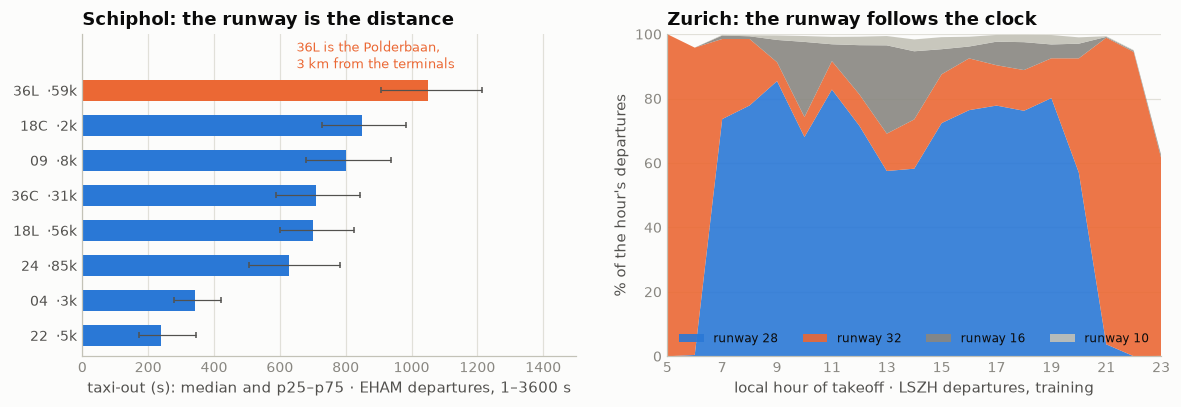

In [6]:
# the configuration in time: which runway is in use swings with the wind month to month, and follows the clock at
# Zurich; the two ranking months sit inside 2025's range
print("share of each hub's busiest 2025 runway, by month — and in the two ranking months:")
print(con.sql(f"""
    WITH top AS (SELECT hub, arg_max(rwy, n) top_rwy FROM (SELECT ADEP_mvt hub, RUNWAY_mvt rwy, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2) GROUP BY 1),
         d AS (SELECT 2025 yr, month(MVT_TIME_UTC_mvt) mon, ADEP_mvt hub, RUNWAY_mvt rwy FROM {T} WHERE PHASE_mvt = 'DEP'
               UNION ALL SELECT 2026, month(MVT_TIME_UTC_mvt), ADEP_mvt, RUNWAY_mvt FROM {R} WHERE PHASE_mvt = 'DEP')
    SELECT hub, top_rwy,
           {', '.join(f"round(100.0*count(*) FILTER (yr = 2025 AND mon = {m} AND rwy = top_rwy)/count(*) FILTER (yr = 2025 AND mon = {m})) m{m:02d}" for m in range(1, 13))},
           round(100.0*count(*) FILTER (yr = 2026 AND mon = 1 AND rwy = top_rwy)/count(*) FILTER (yr = 2026 AND mon = 1)) jan26,
           round(100.0*count(*) FILTER (yr = 2026 AND mon = 7 AND rwy = top_rwy)/count(*) FILTER (yr = 2026 AND mon = 7)) jul26
    FROM d JOIN top USING (hub) GROUP BY 1, 2 ORDER BY 1""").df().to_string(index=False))

hourly = con.sql(f"""
    SELECT RUNWAY_mvt rwy, hour({LOCAL}) h, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LSZH' GROUP BY 1, 2""").df()
piv = hourly.pivot(index="h", columns="rwy", values="n").fillna(0)
piv = piv.reindex(range(5, 24)).fillna(0)
share = piv.div(piv.sum(axis=1), axis=0) * 100
print("\nZurich's departure runway by local hour (% of the hour's departures, training) — a regime, not the wind:")
print(share[["28", "32", "16", "10"]].round(0).astype(int).T.to_string())

eham = con.sql(f"""
    SELECT RUNWAY_mvt rwy, count(*) n, quantile_cont(TAXITIME_SEC_mvt, 0.5) med, quantile_cont(TAXITIME_SEC_mvt, 0.25) p25, quantile_cont(TAXITIME_SEC_mvt, 0.75) p75
    FROM {TGT} WHERE ADEP_mvt = 'EHAM' GROUP BY 1 HAVING count(*) >= 1000 ORDER BY med""").df()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
yy = np.arange(len(eham))
a1.barh(yy, eham.med, height=0.6, color=[ORANGE if r == "36L" else BLUE for r in eham.rwy])
a1.errorbar(eham.med, yy, xerr=[eham.med - eham.p25, eham.p75 - eham.med], fmt="none", ecolor=INK2, elinewidth=0.8, capsize=2)
a1.set_yticks(yy, [f"{r}  ·{n/1000:.0f}k" for r, n in zip(eham.rwy, eham.n)], color=INK2)
a1.text(eham.med.max() * 0.62, yy[-1] + 0.5, "36L is the Polderbaan,\n3 km from the terminals", fontsize=8.5, color=ORANGE, va="bottom")
a1.set_xlim(0, 1500)
a1.set_ylim(-0.6, len(eham) + 0.6)
a1.set_title("Schiphol: the runway is the distance")
a1.set_xlabel("taxi-out (s): median and p25–p75 · EHAM departures, 1–3600 s")
style(a1, x_grid=True, y_grid=False)
cols = {"28": BLUE, "32": ORANGE, "16": MUTED, "10": BASELINE}
a2.stackplot(share.index, [share[r] for r in cols], labels=[f"runway {r}" for r in cols], colors=list(cols.values()), alpha=0.9)
a2.set_xlim(5, 23)
a2.set_ylim(0, 100)
a2.set_xticks(range(5, 24, 2))
a2.set_title("Zurich: the runway follows the clock")
a2.set_xlabel("local hour of takeoff · LSZH departures, training")
a2.set_ylabel("% of the hour's departures")
a2.legend(loc="lower center", ncol=4, fontsize=8, frameon=False)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()


In [7]:
# what the runway buys — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the coarser rung: alone, as the
# direction only, with the hour, with two context flags, on top of the anchor, and with the two columns it pairs with
con.sql(f"""
    CREATE OR REPLACE TABLE rwy_ev AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, RUNWAY_mvt rwy, substr(RUNWAY_mvt, 1, 2) direction, hour({LOCAL}) h_local,
           AIRCRAFT_TYPE_mvt typ, STAND_mvt stand, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor,
           (RUNWAY_mvt != lag(RUNWAY_mvt) OVER w AND epoch(MVT_TIME_UTC_mvt - lag(MVT_TIME_UTC_mvt) OVER w) < 1800) switched,
           count(DISTINCT RUNWAY_mvt) OVER (PARTITION BY ADEP_mvt, date_trunc('hour', MVT_TIME_UTC_mvt)) runways_this_hour
    FROM {T} WHERE PHASE_mvt = 'DEP'
    WINDOW w AS (PARTITION BY ADEP_mvt ORDER BY MVT_TIME_UTC_mvt)""")
con.sql("CREATE OR REPLACE TABLE rwy_d AS SELECT * FROM rwy_ev WHERE y BETWEEN 1 AND 3600")


def rwy_cat(keys, tbl="rwy_d"):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM {tbl} WHERE NOT is_val GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM {tbl} v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM rwy_d WHERE is_val").fetchone()[0]
print(f"(1) on top of the airport mean — {n_val:,} Nov+Dec departures:")
for name, keys in [("airport", "hub"), ("+ runway", "hub, rwy"), ("+ direction only (first two characters)", "hub, direction"),
                   ("+ local hour (§8)", "hub, h_local"), ("+ runway × local hour", "hub, rwy, h_local"),
                   ("+ runway × switched from the previous departure", "hub, rwy, switched"),
                   ("+ runway × runways in use this hour", "hub, rwy, runways_this_hour"),
                   ("+ type (§11)", "hub, typ"), ("+ runway × type", "hub, rwy, typ"),
                   ("+ stand (its own section)", "hub, stand"), ("+ runway × stand", "hub, rwy, stand")]:
    print(f"    {name:50s} {rwy_cat(keys):7.1f} s")

print("\nshare of departures whose runway differs from the previous departure's within 30 min, per hub — and the two medians:")
print(con.sql("""
    SELECT hub, round(100.0*avg(switched::INT), 1) pct_switched, round(quantile_cont(y, 0.5) FILTER (switched)) med_switched,
           round(quantile_cont(y, 0.5) FILTER (NOT switched)) med_same
    FROM rwy_d GROUP BY 1 ORDER BY 2 DESC""").df().to_string(index=False))

con.sql("""
    CREATE OR REPLACE TABLE rwy_b AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,0.7,0.75,0.8,0.85,0.9,0.95]) qa
                  FROM rwy_d WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT rwy_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc FROM rwy_d JOIN cuts USING (hub) WHERE anchor IS NOT NULL""")
n_val = con.sql("SELECT count(*) FROM rwy_b WHERE is_val").fetchone()[0]
print(f"\n(2) conditional on the anchor — the {n_val:,} Nov+Dec departures with an AOBT_3, airport × 20 anchor bins first:")
for name, keys in [("airport", "hub"), ("+ AOBT_3 anchor", "hub, q_anc"), ("+ anchor, then runway", "hub, q_anc, rwy"), ("runway without the anchor", "hub, rwy")]:
    print(f"    {name:50s} {rwy_cat(keys, 'rwy_b'):7.1f} s")


(1) on top of the airport mean — 327,485 Nov+Dec departures:
    airport                                              357.3 s
    + runway                                             343.5 s
    + direction only (first two characters)              345.6 s
    + local hour (§8)                                    351.5 s
    + runway × local hour                                338.4 s
    + runway × switched from the previous departure      343.1 s
    + runway × runways in use this hour                  342.5 s
    + type (§11)                                         338.0 s


    + runway × type                                      323.1 s
    + stand (its own section)                            323.6 s
    + runway × stand                                     306.0 s

share of departures whose runway differs from the previous departure's within 30 min, per hub — and the two medians:
 hub  pct_switched  med_switched  med_same
EDDF          55.0         812.0     866.0
LEMD          53.7         970.0    1001.0
LTFM          52.8         968.0     957.0
LFPG          51.8         959.0     950.0
EDDM          51.7         768.0     779.0
EHAM          44.2         716.0     764.0
LSZH          16.6         817.0     695.0
LIRF           9.2        1252.0    1015.0
LEBL           2.9        1030.0     903.0
EGLL           0.2        1193.0    1319.0



(2) conditional on the anchor — the 324,631 Nov+Dec departures with an AOBT_3, airport × 20 anchor bins first:
    airport                                              355.4 s
    + AOBT_3 anchor                                      290.8 s
    + anchor, then runway                                283.2 s
    runway without the anchor                            341.8 s


                                          feature        kind  n / levels  pearson_r  spearman_ρ     η
runway — the code, per airport it is the geometry categorical          53                        0.488
        direction only — the first two characters categorical          25                        0.428
    switched from the previous departure's runway categorical           3                        0.099
                         runways in use this hour     numeric     2080533     -0.205       -0.19      
                          a helipad code (H, HEL) categorical           2                        0.024
                                  the NA sentinel categorical           2                        0.001


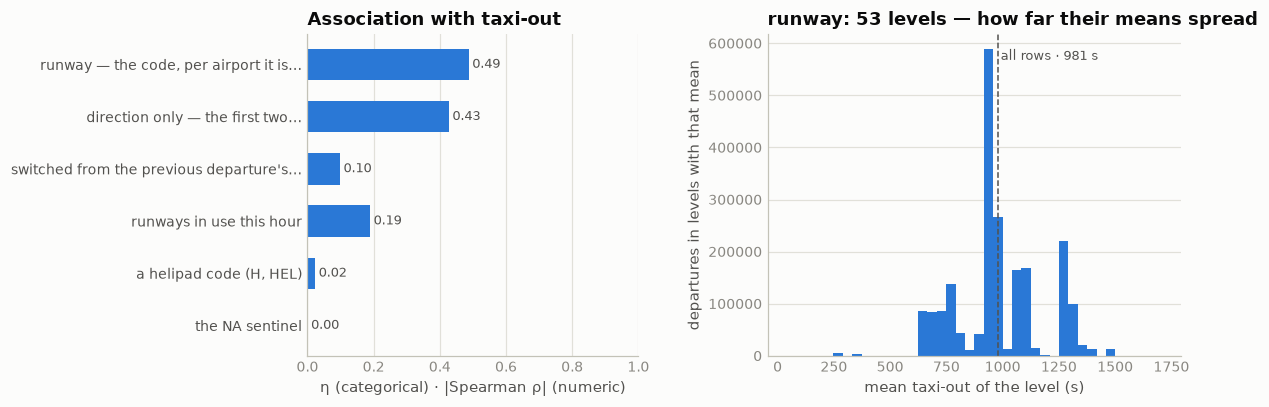

In [8]:
# correlation with the target: the runway, its direction, the two context flags, and the helipad codes
a = target_assoc([("runway — the code, per airport it is the geometry", "cat", "RUNWAY_mvt"),
                  ("direction only — the first two characters", "cat", "substr(RUNWAY_mvt, 1, 2)"),
                  ("switched from the previous departure's runway", "cat", "switched", 1, "rwy_d", "y"),
                  ("runways in use this hour", "num", "runways_this_hour", 1, "rwy_d", "y"),
                  ("a helipad code (H, HEL)", "cat", "RUNWAY_mvt IN ('H', 'HEL')"),
                  ("the NA sentinel", "cat", "RUNWAY_mvt = 'NA'")])
assoc_chart(a, "RUNWAY_mvt", kind="cat", title="runway")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Never null — but three codes are not runways** | 0 nulls on 4,857,331 rows, 53 values on training departures. `H`: 919 rows, 466 departures at LSZH, median label 1 s, 88% rotorcraft. `HEL`: 361 rows, 40 departures at EHAM, 100% rotorcraft. `NA`: 221 rows, 40 departures (LIRF 24, EDDF 8, EGLL 3, EHAM 1) and 2 + 2 in the 2026 file. `7`: one arrival | the helipads are real levels (§4's helicopters); `NA` is a sentinel for an unknown runway and stays a level of its own — 40 rows, nothing to repair |
| **Within an airport the runway is the distance** | EHAM: `24` median 627 s, `18L` 701, `36C` 711, **`36L` 1,049** — the Polderbaan, 3 km from the terminals; EDDF `18` 887 vs `25C` 735; LTFM `36` 891 vs `17R` 1,267; LIRF `25` 1,011 vs `16R` 1,329. EGLL's three: 1,310, 1,316, 1,332 | geometry, and at Heathrow none: its runways are equally far from everything |
| **Most hubs segregate departures from arrivals** | LEMD: `36R 36L 14L 14R` depart only, `32R 32L 18L 18R` land only; EDDF `18` departs only, `25C` shared; EHAM `24 36L 18L 09` depart, `18R 06 36R 27` land; EGLL `09R` departs, `09L` lands, `27L`/`27R` alternate; EDDM shares all four | the real choice is 2–4 departure runways per hub |
| **One runway at Heathrow, two elsewhere** | departure runways per hour: EGLL 1.03 (97% of hours on one), LEBL 1.28, LIRF 1.48, LEMD 1.73, LSZH 1.74, LFPG 1.84, EDDM 1.93, EDDF 1.99, LTFM 2.06, EHAM 2.23 | the parallel-operation hubs alternate runways departure by departure — the next row |
| **The wind sets it month to month; the clock at Zurich** | share of the busiest runway: EGLL `09R` 11% (July) to 71% (April), EHAM `24` 15% to 49%, LFPG `08L` 12% to 46%; LIRF `25` 79–94%. LSZH: `32` carries 95–100% of departures before 07h and after 21h, `28` 74–85% through the day, `16` up to 27% at 13h | Zurich's regime is readable from the hour; elsewhere the row's own runway is the configuration, and it is known |
| **2026 sits inside 2025** | the two ranking months' shares fall within 2025's monthly range at nine hubs; LTFM `36` is at 26% in January 2026 against 29–59% in 2025. New in 2026: LFPG `NA`, 2 rows. Gone: LTFM `34R`, 308 rows in 2025. 19 of 344,841 ranking departures use a runway with under 30 training rows | no drift to handle |
| **Alone it buys 13.8 s; on top of the anchor, 7.6** | airport 357.3 → + runway **343.5**; direction only 345.6; runway × local hour 338.4 (the hour alone 351.5). With the anchor first: 290.8 → 283.2; the runway without it 341.8 | the base of every ladder since §7. The anchor absorbs half of it: an aircraft that took long to reach a far runway is late against `AOBT_3` too |
| **Switching and the count in use add nothing** | runway × switched from the previous departure 343.1, × runways in use this hour 342.5. Switching is 52–55% of departures at EDDF, LEMD, LTFM, LFPG and EDDM — parallel operations alternate — and 0.2% at EGLL | both flags are the hub's operating mode, which the airport and the code already say |
| **The pair with the stand is the feature** | runway × type 323.1 (type alone 338.0), runway × stand **306.0** (stand alone 323.6) | stand → runway is the taxi route itself; the stand section owns it |
| Across hubs the code carries the airport | η 0.488 over 53 levels, direction 0.428 — Heathrow's `09R`/`27R`/`27L` are Heathrow's alone, and Heathrow taxis 1,300 s | the marginal number is mostly the airport's; the within-airport gain is the ladder row |

**Decisions**

| issue | decision | why |
|---|---|---|
| the `NA` sentinel | its own level, no repair | 40 departures, 2 + 2 in 2026, no source to repair from |
| the helipad codes | their own levels | real, and §4's helicopters use them |
| the switch flag, the count in use | not features | 0.4 and 1.0 s |
| runway × hour | left to the model | Zurich's regime is what a tree reads from runway + local hour |

**State after §12** — unchanged: never null, nothing repaired.

**Use in modeling.** The runway as a native categorical, per airport — the pipeline does this. Its
own worth is the 14 s at the base of the ladders; its value is in the pairs, with the stand above
all. In the closing matrix it enters raw, rare codes pooled below 30 rows: 0.91 with the airport
(the codes are the hub's own), 0.49 with the target.


## 13 · `STAND_mvt` — where the taxi starts

The stand the aircraft left from — `B15`, `302`, `T13` — as the airport recorded it; on arrival
rows the stand it parked at. With the runway (§12) it is the *route*: where the taxi begins and
where it ends, and at every hub the two together are the geometry the model has to learn. Present
on all but a handful of rows in both files. The pipeline's strongest feature by gain is a rolling
mean of taxi-out from the stand (`VALIDATION/FINDINGS.md`, §4) — this column with a memory.

| step | question | what came out |
|---|---|---|
| **census** | present where; is every value a stand? | 28 + 4 departures without one; an `UNKNOWN` sentinel for Barcelona's cargo apron; named areas at Zurich and Paris |
| **the geometry** | how far apart a hub's stands are, and the route stand × runway | a hub's p10 and p90 stands are 4–11 minutes apart; at Schiphol pier × runway runs from 518 s to 1,439 s |
| **look both ways** | stands 2026 uses that 2025 did not know | Frankfurt's new pier (1,804 July departures) and Munich's renumbered apron (1,177): 3,000 rows the stand cannot see |
| **signal** | the stand and its prefix — alone, with the runway, cascaded, on the anchor; then turnaround and pier traffic | 34 s alone, 51 with the runway, 18 on top of the anchor; the prefix carries most of it and is the fallback; turnaround and pier traffic add nothing |


In [4]:
# census by file × phase: all but a handful of rows carry a stand; the values that are not stands but named areas; and the
# prefix — the pier, apron or terminal the stand belongs to — that later cells use as the stand's coarser form
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
PFX = "CASE WHEN regexp_matches(STAND_mvt, '^[A-Z]') THEN regexp_extract(STAND_mvt, '^([A-Z]+)', 1) ELSE substr(STAND_mvt, 1, 1) END"
print("STAND_mvt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (STAND_mvt IS NULL) n_null, count(DISTINCT STAND_mvt) n_values,
           count(*) FILTER (STAND_mvt = 'UNKNOWN') unknown_sentinel
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe rows without a stand (both files, departures) — where and who:")
print(con.sql(f"""
    SELECT src, ADEP_mvt hub, count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan, mode(MARKET_SEGMENT_flt) segment,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND STAND_mvt IS NULL GROUP BY 1, 2 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

print("\nvalues that are names rather than stand numbers (both files, both phases; ≥ 20 rows):")
print(con.sql(f"""
    SELECT STAND_mvt code, mode(CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) hub, count(*) n,
           count(*) FILTER (PHASE_mvt = 'DEP') departures, mode(MARKET_SEGMENT_flt) segment, mode(AIRCRAFT_TYPE_mvt) typ,
           round(100.0*count(*) FILTER (AIRCRAFT_TYPE_mvt IN {HELI_ALL})/count(*)) pct_rotorcraft,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (PHASE_mvt = 'DEP')) med_taxi_out
    FROM {BOTH} WHERE STAND_mvt IS NOT NULL AND NOT regexp_matches(STAND_mvt, '[0-9]')
    GROUP BY 1 HAVING count(*) >= 20 ORDER BY n DESC""").df().to_string(index=False))

print("\nhow each hub names its stands — leading letters or digits, and the number of prefixes (piers / aprons / terminals):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(DISTINCT STAND_mvt) n_stands,
           round(100.0*count(*) FILTER (regexp_matches(STAND_mvt, '^[A-Z]'))/count(*), 1) pct_letter_first,
           count(DISTINCT {PFX}) n_prefixes, string_agg(DISTINCT {PFX}, ' ') prefixes
    FROM {T} WHERE PHASE_mvt = 'DEP' AND STAND_mvt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))


STAND_mvt by file × phase:
     src  ph       n  n_null  n_values  unknown_sentinel
training ARR 2082750      36      1849              1628
training DEP 2085047      28      1899              1477
 ranking ARR  344693       5      1692               269
 ranking DEP  344841       4      1697               249

the rows without a stand (both files, departures) — where and who:
     src  hub  n  no_plan       segment  med_label
training LFPG 14        3      Mainline       -2.0
training LIRF 10        8 Non-Scheduled     1350.0
training EGLL  4        0      Mainline     1772.0
 ranking LFPG  2        0      Mainline        NaN
 ranking EGLL  2        0      Mainline        NaN

values that are names rather than stand numbers (both files, both phases; ≥ 20 rows):
   code  hub    n  departures       segment  typ  pct_rotorcraft  med_taxi_out
UNKNOWN LEBL 3623        1726         Cargo B752             0.0         735.0
    MFG LSZH 2401        1244         Other DA40             0.0     

stand medians within each hub — departures 1–3600 s, stands with ≥ 100 rows: how far the p10 and p90 stands are apart:


 hub  n_stands    p10    p50    p90 nearest  nearest_med farthest  farthest_med
EHAM       192  332.0  727.0  963.0    HG01        176.0      R72        1233.0
LSZH       116  406.0  729.0  933.0     HPW          7.0      C55        1088.0
EDDM       155  598.0  771.0  847.0     342        534.0      907        1138.0
LEBL       169  618.0  873.0 1206.0     422        414.0     119A        1455.0
EDDF       185  493.0  877.0 1061.0    V172        354.0     V322        1325.0
LFPG       290  832.0  969.0 1174.0     R13        537.0      N04        1435.0
LTFM       256  777.0  970.0 1086.0     601        490.0      A11        1207.0
LEMD       270  691.0  976.0 1354.0     606        469.0      145        1688.0
LIRF       121  839.0 1010.0 1331.0     230        775.0      902        1568.0
EGLL       179 1137.0 1325.0 1442.0    246L        899.0      547        1511.0

Schiphol: median taxi-out by pier × runway (piers with ≥ 2,000 departures, the four main runways) — the route, not the 

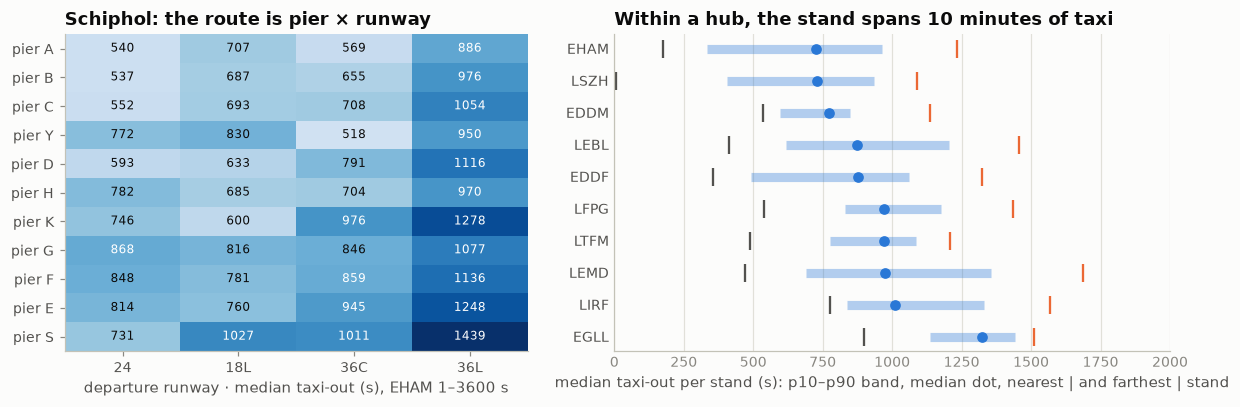

In [5]:
# the geometry: how far apart the stands of one hub are in taxi-out, and the stand × runway pair that is the route
print("stand medians within each hub — departures 1–3600 s, stands with ≥ 100 rows: how far the p10 and p90 stands are apart:")
spread = con.sql(f"""
    SELECT hub, count(*) n_stands, round(quantile_cont(med, 0.1)) p10, round(quantile_cont(med, 0.5)) p50, round(quantile_cont(med, 0.9)) p90,
           arg_min(stand, med) nearest, round(min(med)) nearest_med, arg_max(stand, med) farthest, round(max(med)) farthest_med
    FROM (SELECT ADEP_mvt hub, STAND_mvt stand, quantile_cont(TAXITIME_SEC_mvt, 0.5) med FROM {TGT} WHERE STAND_mvt IS NOT NULL
          GROUP BY 1, 2 HAVING count(*) >= 100)
    GROUP BY 1 ORDER BY p50""").df()
print(spread.to_string(index=False))

print("\nSchiphol: median taxi-out by pier × runway (piers with ≥ 2,000 departures, the four main runways) — the route, not the stand or the runway alone:")
heat = con.sql(f"""
    SELECT {PFX} pier, RUNWAY_mvt rwy, quantile_cont(TAXITIME_SEC_mvt, 0.5) med, count(*) n
    FROM {TGT} WHERE ADEP_mvt = 'EHAM' AND RUNWAY_mvt IN ('24', '36L', '18L', '36C') AND STAND_mvt IS NOT NULL
      AND {PFX} IN (SELECT {PFX} FROM {TGT} WHERE ADEP_mvt = 'EHAM' AND STAND_mvt IS NOT NULL GROUP BY 1 HAVING count(*) >= 2000)
    GROUP BY 1, 2 HAVING count(*) >= 30""").df()
hm = heat.pivot(index="pier", columns="rwy", values="med")[["24", "18L", "36C", "36L"]]
hm = hm.loc[hm.mean(axis=1).sort_values().index]
print(hm.round(0).fillna(-1).astype(int).replace(-1, "·").to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
im = a1.imshow(hm.values, cmap="Blues", vmin=300, vmax=1400, aspect="auto")
a1.set_xticks(range(hm.shape[1]), hm.columns, color=INK2)
a1.set_yticks(range(hm.shape[0]), [f"pier {p}" for p in hm.index], color=INK2)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        if not np.isnan(v):
            a1.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 850 else INK)
a1.set_title("Schiphol: the route is pier × runway")
a1.set_xlabel("departure runway · median taxi-out (s), EHAM 1–3600 s")
a1.grid(False)
yy = np.arange(len(spread))
a2.hlines(yy, spread.p10, spread.p90, color=BLUE, lw=6, alpha=0.35)
a2.plot(spread.p50, yy, "o", color=BLUE, ms=6)
a2.plot(spread.nearest_med, yy, "|", color=INK2, ms=12, mew=1.5)
a2.plot(spread.farthest_med, yy, "|", color=ORANGE, ms=12, mew=1.5)
a2.set_yticks(yy, spread.hub, color=INK2)
a2.invert_yaxis()
a2.set_xlim(0, 2000)
a2.set_title("Within a hub, the stand spans 10 minutes of taxi")
a2.set_xlabel("median taxi-out per stand (s): p10–p90 band, median dot, nearest | and farthest | stand")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()


In [6]:
# look both ways: stands are renumbered and piers are built. What 2026 uses that 2025 barely knew, and where it happened
print("2026 departures on stands new to their hub, or with under 30 training departures — and whether the prefix has support:")
print(con.sql(f"""
    WITH s25 AS (SELECT ADEP_mvt hub, STAND_mvt stand, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2),
         p25 AS (SELECT ADEP_mvt hub, {PFX} pfx, count(*) n FROM {T} WHERE PHASE_mvt = 'DEP' AND STAND_mvt IS NOT NULL GROUP BY 1, 2)
    SELECT r.ADEP_mvt hub, count(*) rows_2026, count(*) FILTER (s25.stand IS NULL) on_new_stands, count(DISTINCT r.STAND_mvt) FILTER (s25.stand IS NULL) new_stands,
           count(*) FILTER (coalesce(s25.n, 0) < 30) on_stands_under_30, count(*) FILTER (coalesce(s25.n, 0) < 30 AND coalesce(p25.n, 0) >= 30) of_which_prefix_supported,
           count(*) FILTER (coalesce(s25.n, 0) < 30 AND month(r.MVT_TIME_UTC_mvt) = 7) of_which_in_july
    FROM {R} r LEFT JOIN s25 ON s25.hub = r.ADEP_mvt AND s25.stand = r.STAND_mvt
    LEFT JOIN p25 ON p25.hub = r.ADEP_mvt AND p25.pfx = {PFX.replace('STAND_mvt', 'r.STAND_mvt')}
    WHERE r.PHASE_mvt = 'DEP' AND r.STAND_mvt IS NOT NULL GROUP BY 1 ORDER BY on_stands_under_30 DESC""").df().to_string(index=False))

print("\nFrankfurt — departures from the J and H5/H9 stands by month; Munich — stands 103–108 against 120/121:")
print(con.sql(f"""
    SELECT yr, mon, count(*) FILTER (ADEP_mvt = 'EDDF' AND STAND_mvt LIKE 'J%') eddf_j, count(*) FILTER (ADEP_mvt = 'EDDF' AND STAND_mvt IN ('H5', 'H9')) eddf_h5_h9,
           count(*) FILTER (ADEP_mvt = 'EDDF') eddf_all,
           count(*) FILTER (ADEP_mvt = 'EDDM' AND STAND_mvt IN ('103', '104', '105', '106', '107', '108')) eddm_103_108,
           count(*) FILTER (ADEP_mvt = 'EDDM' AND STAND_mvt IN ('120', '121')) eddm_120_121
    FROM (SELECT 2025 yr, month(MVT_TIME_UTC_mvt) mon, * FROM {T} UNION ALL SELECT 2026, month(MVT_TIME_UTC_mvt), * FROM {R})
    WHERE PHASE_mvt = 'DEP' GROUP BY 1, 2 ORDER BY 1, 2""").df().set_index(["yr", "mon"]).T.to_string())
print("\nFrankfurt's new pier in July 2026 — its runway and its takeoff − AOBT_3 gap against the rest of the hub:")
print(con.sql(f"""
    SELECT (STAND_mvt LIKE 'J%' OR STAND_mvt IN ('H5', 'H9')) new_pier, count(*) n, mode(RUNWAY_mvt) rwy,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt), 0.5)) med_gap_s
    FROM {R} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EDDF' AND month(MVT_TIME_UTC_mvt) = 7 GROUP BY 1 ORDER BY 1""").df().to_string(index=False))


2026 departures on stands new to their hub, or with under 30 training departures — and whether the prefix has support:
 hub  rows_2026  on_new_stands  new_stands  on_stands_under_30  of_which_prefix_supported  of_which_in_july
EDDF      36317            300           6                2151                       2150              2088
EDDM      25966           1182          10                1212                       1204              1201
LSZH      23150             58          11                 221                        197                87
LEMD      36954             14           7                 184                        181               127
LTFM      47581              6           2                 181                        172               113
LFPG      39870              8           5                 135                        132                74
LEBL      30080              1           1                  83                         83                51
LIRF      26899  

 new_pier     n rwy  med_gap_s
    False 18846  18      915.0
     True  1804  18      979.0


In [7]:
# what the stand buys — honest ladders, fit Jan–Oct → Nov+Dec, cell support ≥ 30 else the coarser rung: the stand and its
# prefix alone, paired with the runway, cascaded, on top of the anchor; then two things the stand's history could add —
# the turnaround (minutes since the last arrival parked there, known at prediction time) and the pier's own traffic
con.sql(f"""
    CREATE OR REPLACE TABLE std_ev AS
    SELECT ds, MVT_ID_mvt id, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, PHASE_mvt ph, STAND_mvt stand, {PFX} pfx,
           MVT_TIME_UTC_mvt t, BLOCK_TIME_UTC_mvt b, AOBT_3_flt aobt3, RUNWAY_mvt rwy, AIRCRAFT_TYPE_mvt typ, TAXITIME_SEC_mvt taxi
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking' ds, * FROM {R})""")
con.sql("""
    CREATE OR REPLACE TABLE std_turn AS
    SELECT ds, id, epoch(aobt3 - last_ib)/60.0 turn_min FROM (
        SELECT d.ds, d.id, d.aobt3, max(a.ib) last_ib
        FROM (SELECT * FROM std_ev WHERE ph = 'DEP' AND stand IS NOT NULL AND aobt3 IS NOT NULL) d
        LEFT JOIN (SELECT ds, hub, stand, b ib FROM std_ev WHERE ph = 'ARR' AND b IS NOT NULL AND stand IS NOT NULL) a
          ON a.ds = d.ds AND a.hub = d.hub AND a.stand = d.stand AND a.ib < d.aobt3 AND a.ib > d.aobt3 - INTERVAL 24 HOUR
        GROUP BY 1, 2, 3)""")
con.sql("""
    CREATE OR REPLACE TABLE std_pier AS
    SELECT ds, id, sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER (PARTITION BY ds, hub, pfx ORDER BY t
                                                                    RANGE BETWEEN INTERVAL 15 MINUTE PRECEDING AND INTERVAL 15 MINUTE FOLLOWING) pier_dep_c30
    FROM std_ev WHERE stand IS NOT NULL""")
con.sql("""
    CREATE OR REPLACE TABLE std_d AS
    SELECT e.hub, e.rwy, e.stand, e.pfx, e.typ, e.taxi::DOUBLE y, month(e.t) >= 11 is_val, epoch(e.t - e.aobt3) anchor, tr.turn_min, p.pier_dep_c30,
           CASE WHEN tr.turn_min IS NULL THEN 'no arrival in 24 h' WHEN tr.turn_min < 45 THEN 'under 45 min' WHEN tr.turn_min < 90 THEN '45–90'
                WHEN tr.turn_min < 180 THEN '90–180' ELSE 'over 3 h' END turn_band
    FROM std_ev e LEFT JOIN std_turn tr USING (ds, id) LEFT JOIN std_pier p USING (ds, id)
    WHERE e.ds = 'training' AND e.ph = 'DEP' AND e.taxi BETWEEN 1 AND 3600""")


def std_cat(keys, tbl="std_d"):
    return con.sql(f"""
        WITH f AS (SELECT {keys}, avg(y) m, count(*) c FROM {tbl} WHERE NOT is_val GROUP BY ALL),
             h AS (SELECT hub, avg(y) m FROM {tbl} WHERE NOT is_val GROUP BY 1)
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m))^2))
        FROM {tbl} v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM std_d WHERE is_val").fetchone()[0]
print(f"(1) on top of the airport mean — {n_val:,} Nov+Dec departures (a missing stand is its own level):")
for name, keys in [("airport", "hub"), ("+ prefix (pier / apron / terminal)", "hub, pfx"), ("+ stand", "hub, stand"), ("+ runway (§12)", "hub, rwy"),
                   ("+ runway × prefix", "hub, rwy, pfx"), ("+ runway × stand", "hub, rwy, stand"), ("+ runway × stand × type", "hub, rwy, stand, typ")]:
    print(f"    {name:44s} {std_cat(keys):7.1f} s")
print("    runway × stand, cascading to runway × prefix, runway, airport when a cell has under 30 rows:", end=" ")
print(con.sql("""
    WITH f3 AS (SELECT hub, rwy, stand, avg(y) m, count(*) c FROM std_d WHERE NOT is_val GROUP BY ALL),
         f2 AS (SELECT hub, rwy, pfx, avg(y) m, count(*) c FROM std_d WHERE NOT is_val GROUP BY ALL),
         f1 AS (SELECT hub, rwy, avg(y) m, count(*) c FROM std_d WHERE NOT is_val GROUP BY ALL),
         h AS (SELECT hub, avg(y) m FROM std_d WHERE NOT is_val GROUP BY 1)
    SELECT round(sqrt(avg((v.y - coalesce(CASE WHEN f3.c >= 30 THEN f3.m END, CASE WHEN f2.c >= 30 THEN f2.m END,
                                          CASE WHEN f1.c >= 30 THEN f1.m END, h.m))^2)), 1)
    FROM std_d v LEFT JOIN f3 USING (hub, rwy, stand) LEFT JOIN f2 USING (hub, rwy, pfx) LEFT JOIN f1 USING (hub, rwy) JOIN h USING (hub) WHERE v.is_val""").fetchone()[0], "s")

con.sql("""
    CREATE OR REPLACE TABLE std_wb AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                         quantile_cont(pier_dep_c30, [0.2,0.4,0.6,0.8]) qp FROM std_d WHERE NOT is_val AND anchor IS NOT NULL GROUP BY 1)
    SELECT std_d.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc, list_count(list_filter(qp, x -> x <= pier_dep_c30)) q_pier
    FROM std_d JOIN cuts USING (hub) WHERE anchor IS NOT NULL AND rwy IS NOT NULL AND stand IS NOT NULL""")


def std_rungs(rungs):
    out, joins, preds = [], [], []
    for i, (name, keys) in enumerate(rungs):
        con.sql(f"CREATE OR REPLACE TABLE std_s{i} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM std_wb WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN std_s{i} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN std_s{i}.c >= 30 THEN std_s{i}.m END")
        out.append((name, con.sql(f"""
            SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}, g.m))^2)) FROM std_wb v {' '.join(joins)}
            CROSS JOIN (SELECT avg(y) m FROM std_wb WHERE NOT is_val) g WHERE v.is_val""").fetchone()[0]))
    return out


BASE = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]), ("+ AOBT_3 anchor (§9's base)", ["hub", "rwy", "q_anc"]),
        ("+ prefix", ["hub", "rwy", "q_anc", "pfx"]), ("+ stand", ["hub", "rwy", "q_anc", "pfx", "stand"])]
n_val = con.sql("SELECT count(*) FROM std_wb WHERE is_val").fetchone()[0]
print(f"\n(2) on top of airport × runway × anchor — the {n_val:,} Nov+Dec departures with runway, stand and anchor:")
for name, r in std_rungs(BASE):
    print(f"    {name:44s} {r:7.1f} s")
for name, keys in [("+ turnaround band, on top", ["turn_band"]), ("+ pier departures within ±15 min, on top", ["q_pier"])]:
    print(f"    {name:44s} {std_rungs(BASE + [('x', BASE[-1][1] + keys)])[-1][1]:7.1f} s")

print("\nthe turnaround — minutes from the last arrival's in-block at the stand to our AOBT_3 (training departures with an anchor):")
print(con.sql("""
    SELECT turn_band, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(avg(y)) mean_taxi, round(quantile_cont(y, 0.5)) med_taxi
    FROM std_d WHERE anchor IS NOT NULL GROUP BY 1 ORDER BY min(coalesce(turn_min, 1e9))""").df().to_string(index=False))


(1) on top of the airport mean — 327,485 Nov+Dec departures (a missing stand is its own level):
    airport                                        357.3 s
    + prefix (pier / apron / terminal)             335.5 s
    + stand                                        323.6 s
    + runway (§12)                                 343.5 s
    + runway × prefix                              314.5 s
    + runway × stand                               306.0 s
    + runway × stand × type                        318.6 s
    runway × stand, cascading to runway × prefix, runway, airport when a cell has under 30 rows: 

300.3 s



(2) on top of airport × runway × anchor — the 324,629 Nov+Dec departures with runway, stand and anchor:
    airport                                        355.4 s
    + runway                                       341.8 s
    + AOBT_3 anchor (§9's base)                    283.6 s
    + prefix                                       268.6 s
    + stand                                        265.5 s


    + turnaround band, on top                      265.1 s


    + pier departures within ±15 min, on top       265.5 s

the turnaround — minutes from the last arrival's in-block at the stand to our AOBT_3 (training departures with an anchor):
         turn_band      n  pct  mean_taxi  med_taxi
      under 45 min 121666  5.9      886.0     825.0
             45–90 871665 42.3      931.0     888.0
            90–180 459078 22.3     1057.0     995.0
          over 3 h 567448 27.6     1016.0     954.0
no arrival in 24 h  39544  1.9     1010.0     958.0


                                                 feature        kind  n / levels  pearson_r  spearman_ρ     η
                                        stand — the code categorical        1494                        0.495
                        prefix — pier, apron or terminal categorical          45                        0.327
                                  route — stand × runway categorical        6427                        0.666
                                    the UNKNOWN sentinel categorical           3                        0.015
turnaround — minutes since the last arrival parked there     numeric     2019857       0.02       0.128      
            departures from the same pier within ±15 min     numeric     2080514       0.06       0.069      


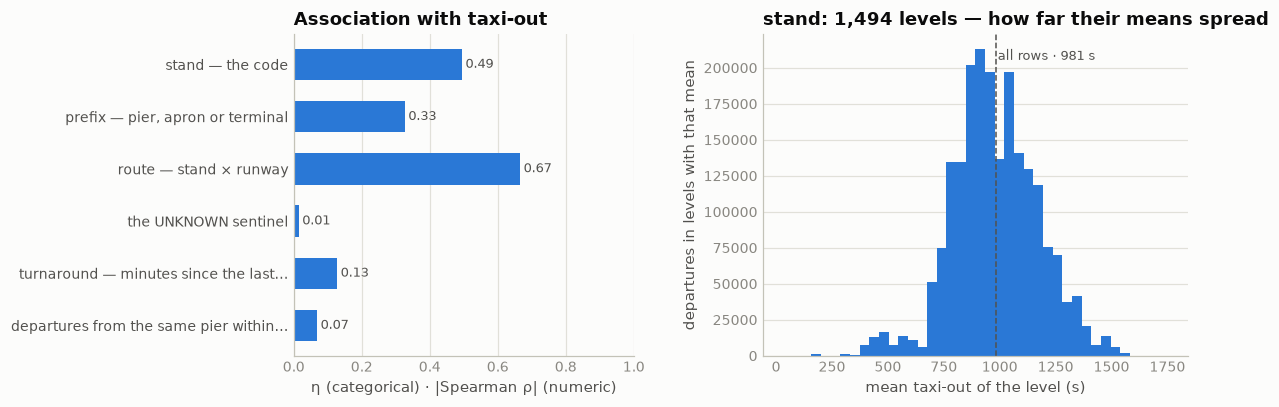

In [8]:
# correlation with the target: the stand, its prefix, the route (stand × runway), the sentinel, the turnaround and the pier's traffic
a = target_assoc([("stand — the code", "cat", "STAND_mvt", 30),
                  ("prefix — pier, apron or terminal", "cat", PFX, 30),
                  ("route — stand × runway", "cat", "STAND_mvt || '→' || RUNWAY_mvt", 30),
                  ("the UNKNOWN sentinel", "cat", "STAND_mvt = 'UNKNOWN'"),
                  ("turnaround — minutes since the last arrival parked there", "num", "turn_min", 1, "std_d", "y"),
                  ("departures from the same pier within ±15 min", "num", "pier_dep_c30", 1, "std_d", "y")])
assoc_chart(a, "STAND_mvt", kind="cat", min_support=30, title="stand")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Present on all but 32 departures** | 28 training departures without a stand (LFPG 14, LIRF 10, EGLL 4) and 4 in the ranking file; 1,899 distinct values on training departures, 1,697 in 2026 | nothing to repair — a missing stand is its own level |
| **Not every value is a stand** | `UNKNOWN`: 1,477 training departures and 249 in 2026, all but 14 at LEBL, cargo (`B752`), median taxi 735 s — the freight apron's stands go unrecorded. Named areas at LSZH (`MFG` 1,244 departures, `REG` 939, `HAN` 487, `HPW` 366: the GA aprons and the helipad) and LFPG (`CFE`, `CFW`: the two cargo areas, 641 + 637 departures, A388 the mode, 1,433 and 1,145 s) | real levels with real geometry — keep them all, `UNKNOWN` included: it is one apron |
| **Every hub names its stands its own way — and the prefix is the pier** | letter-first at EDDF, EHAM, LFPG (100%), LSZH (94%), LTFM (89%); digit-first at EDDM, EGLL, LEBL, LIRF; LEMD mixed (31% letters — the `T` stands of Terminal 4). 8–31 prefixes per hub | the prefix — the leading letters, else the first digit — is a 45-level coarser form that says "which pier" at every hub |
| **Within a hub, the stand spans 4–11 minutes of taxi** | stands with ≥ 100 rows, p10 → p90 of their medians: EHAM 332 → 963 s (`HG01` 176, `R72` 1,233), LSZH 406 → 933, LEMD 691 → 1,354 (`606` 469, `145` 1,688), LEBL 618 → 1,206, LIRF 839 → 1,331; EGLL 1,137 → 1,442 — even Heathrow's nearest stand is 899 s | the second geometric coordinate after the runway; together they are the route |
| **The route is pier × runway, not a sum** | Schiphol medians: pier A to runway `24` 540 s, to `36L` 886; pier S to `36C` 1,011, to `36L` 1,439; pier Y to `36C` 518 but to `24` 772 | the runway that is far for one pier is near for another — an interaction |
| **2026 uses stands 2025 did not know** | Frankfurt: the `J` stands carried 4–19 departures a month in 2025 and **1,512 in July 2026**, `H5`/`H9` 292 more — a new pier, its July gap to `AOBT_3` 979 s against 915 for the rest of the hub. Munich: stands `120`/`121` stop in August 2025 (1,203 + 707 rows), `103`–`108` appear in July 2026 (1,177 rows). Over all hubs 4,297 ranking departures sit on stands with under 30 training rows, 3,363 of them at these two hubs, 4,158 with a prefix that has support | the stand is blind on 1.2% of the scored set, nearly all in July; the prefix covers 97% of those rows — and at Frankfurt the prefix `J` itself has 133 rows, so the runway and the anchor carry the rest |
| **Alone it buys 34 s; with the runway 51; on top of the anchor 18** | airport 357.3 → + prefix **335.5** → + stand **323.6**; runway 343.5 → × prefix 314.5 → × stand **306.0**; × type on top 318.6 (too sparse); stand → prefix → runway → airport cascading at 30 rows **300.3**. On §9's base 283.6 → + prefix 268.6 → + stand **265.5** | the largest single step after the anchor; the prefix carries 60–80% of it and is the right fallback; the cascade beats the flat pair by 5.7 s |
| **Turnaround and pier traffic add nothing** | minutes from the last arrival's in-block at the stand to our `AOBT_3`: 98.1% of departures have one within 24 h, median 92 min; taxi by band 886 s (under 45 min) → 931 (45–90) → 1,057 (90–180) → 1,016 (over 3 h); on the ladder +0.4 s. Departures from the same pier within ±15 min: +0.0 s, ρ 0.07 | the stand's history that matters is *where it is*, which the code already says |
| Across hubs the code carries the airport | η: stand 0.495 (1,494 levels with ≥ 30 rows), prefix 0.327, the route stand × runway 0.666 (6,427 levels); `UNKNOWN` 0.015 | as with the runway (§12), the marginal number includes the hub; the within-hub gain is the ladder row |

**Decisions**

| issue | decision | why |
|---|---|---|
| the 32 missing stands | left null, their own level | no source to fill from |
| `UNKNOWN` and the named areas | kept as levels | each is one apron with its own geometry |
| the stand's coarser form | **the prefix** — leading letters, else the first digit — as a second feature and the fallback below 30 rows | 60–80% of the stand's gain in 45 levels, and it covers 97% of 2026's rows on rare stands |
| turnaround, pier traffic | not features | +0.4 and 0.0 s |
| stand × runway × type as a group | no | 318.6 against 306.0: too sparse; a tree finds the interaction from the three columns |

**State after §13** — unchanged: nothing repaired.

**Use in modeling.** The stand as a native categorical, per airport — the pipeline does this — plus the
prefix as an explicit second column, so the model has a fallback where the stand is new; the cascade
says the fallback is worth having. The harness's rolling stand mean is this column with a memory and
will be blank for Frankfurt's new pier and Munich's new apron in July 2026, which is exactly where
the prefix must exist. In the closing matrix the stand enters raw, rare codes pooled below 30 rows: 0.83 with the airport, 0.49 with
the rule (the GA aprons), 0.50 with the target.


## 14 · `TAXITIME_SEC_mvt` — the target

The taxi-out time in seconds: takeoff (§8) minus off-block (§9), to the second, on every departure;
on arrival rows the taxi-in, in-block minus landing. It is what the score is computed on — RMSE over
the 344,841 departures of January and July 2026 — and it is blank on exactly those rows. Everything
the sweep has measured so far was measured against it on a window of plausible values, 1–3,600 s.
This section is about the column as delivered: its body, its tails, what the score sees of each,
which rows should train, what the loss rewards, and what can be said about the 2026 labels without
seeing them. It closes the questions §9 and §10a left open.

| step | question | what came out |
|---|---|---|
| **census** | present where; is it exactly the difference of the two stamps? | an integer, the exact difference on every row of both files; null on the 344,841 rows we predict and on one arrival |
| **the shape** | the body and the tails, per hub; which rows own the squared error | a right-skewed quarter of an hour; the 0.2% of rows over an hour own 55% of the squared error, 34 rows over 12 h a third of it |
| **the score** | on an honest holdout, what each band of the label adds to the RMSE; what the band between one and two hours is | four rows over 12 h add 274 s of the 497; the 1–2 h band is mostly 10a's block-stamp defect on rows *with* a plan, which the anchor cannot see |
| **which rows train, and the loss** | the training filter; the mean against the median and the log; the rows at or below zero | keep every label from 1 s up, no ceiling — it pays only through the features that see the tail; the mean wins; the near-zeros cost nothing either way |
| **look both ways** | what is visible of the 2026 labels: the corrupt slice's size, the arrival half, the proxy, the month | the slice is 178% of January 2025's and 82% of July's; the arrivals' corruption is another defect and persists; the proxy moves at three hubs; the month swings each hub by 50–209 s |


In [4]:
# census by file × phase: the label is takeoff − off-block to the second on departures (in-block − landing on arrivals), an integer
# column, blank exactly on the rows we predict; then the raw order statistics of departures — the ranking row is null by construction
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
print("column type:", con.sql(f"SELECT typeof(TAXITIME_SEC_mvt) FROM {T} LIMIT 1").fetchone()[0])
print("\nTAXITIME_SEC_mvt by file × phase — where it is, its range, its tails, and whether it is exactly the difference of the two stamps:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (TAXITIME_SEC_mvt IS NULL) n_null, min(TAXITIME_SEC_mvt) mn, max(TAXITIME_SEC_mvt) mx,
           count(*) FILTER (TAXITIME_SEC_mvt < 0) negative, count(*) FILTER (TAXITIME_SEC_mvt = 0) zero, count(*) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 12) s1_12,
           count(*) FILTER (TAXITIME_SEC_mvt BETWEEN 13 AND 3600) s13_3600, count(*) FILTER (TAXITIME_SEC_mvt BETWEEN 3601 AND 7200) s3601_7200,
           count(*) FILTER (TAXITIME_SEC_mvt > 7200) over_7200,
           count(*) FILTER (TAXITIME_SEC_mvt != CASE WHEN PHASE_mvt = 'DEP' THEN epoch(MVT_TIME_UTC_mvt - BLOCK_TIME_UTC_mvt)
                                                     ELSE epoch(BLOCK_TIME_UTC_mvt - MVT_TIME_UTC_mvt) END) not_the_identity,
           count(*) FILTER (extract(microsecond FROM MVT_TIME_UTC_mvt) % 1000000 != 0 OR extract(microsecond FROM BLOCK_TIME_UTC_mvt) % 1000000 != 0) sub_second_stamps
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nraw order statistics, departures, both files:")
display(order_stats("TAXITIME_SEC_mvt", "PHASE_mvt = 'DEP'"))


column type: INTEGER

TAXITIME_SEC_mvt by file × phase — where it is, its range, its tails, and whether it is exactly the difference of the two stamps:


     src  ph       n  n_null    mn     mx  negative  zero  s1_12  s13_3600  s3601_7200  over_7200  not_the_identity  sub_second_stamps
training ARR 2082750       1 -2652 604797       220    16    247   2081826         299        141                 0                  0
training DEP 2085047       0   -12 131167       369    19    370   2080163        3542        584                 0                  0
 ranking ARR  344693       0   -12  50517        39     5     48    344456         118         27                 0                  0
 ranking DEP  344841  344841  <NA>   <NA>         0     0      0         0           0          0                 0                  0

raw order statistics, departures, both files:


,n,n_null,n_unique,min,p01,p25,p50,p75,p99,max
set,,,,,,,,,,
training 2025,2085047,0,5176,-12,291.0,719.0,912.0,1188.0,2339.0,131167
ranking 2026,344841,344841,0,<NA>,NaN,NaN,NaN,NaN,NaN,<NA>


per hub and over all ten, training departures, raw labels — and the same mean and spread on the 1–3,600 s window:


    hub       n   mean     sd    p50    p90    p99    p999     mx  le_0  over_3600  over_7200  pct_sse_over_3600  mean_1_3600  sd_1_3600
   LSZH  134907  741.0  385.0  711.0 1080.0 1707.0  2505.0  87341   313         26          6               41.8        741.0      292.0
   EHAM  247951  785.0  318.0  742.0 1157.0 1775.0  2934.0  11032     3         82          3                4.7        783.0      311.0
   EDDM  167334  812.0  302.0  774.0 1135.0 1921.0  3007.0   6899     0         59          0                5.3        811.0      294.0
   EDDF  230141  863.0  330.0  837.0 1251.0 1819.0  2927.0   6907     0         73          0                3.5        862.0      324.0
   LEBL  179705  957.0  331.0  906.0 1357.0 1962.0  2963.0   3604     5          1          0                0.0        957.0      331.0
   LEMD  212242 1015.0  313.0  985.0 1402.0 1932.0  2704.0   3598     0          0          0                0.0       1015.0      313.0
   LFPG  239552 1020.0  453.0  954.0 1444

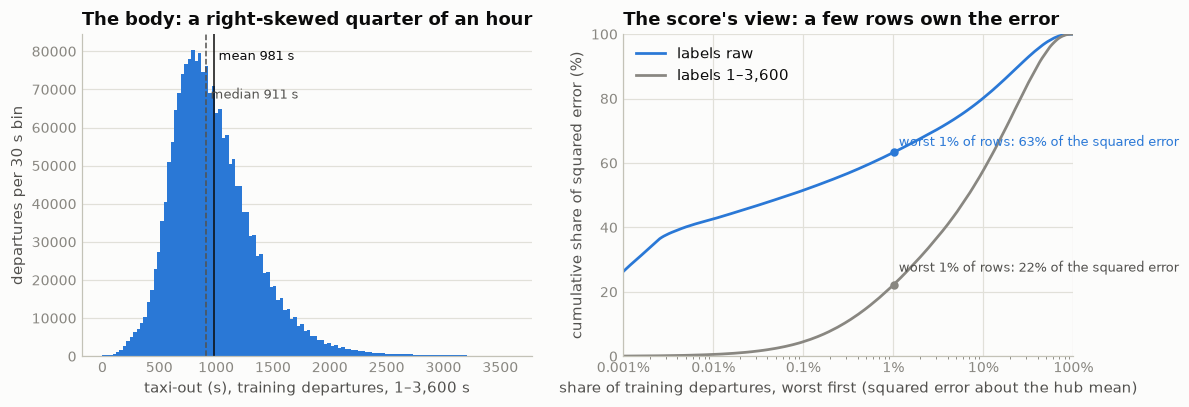

In [5]:
# the shape, on raw labels (the tails are the subject): per hub the body, the tails, and the share of the squared error about the hub's
# mean that the labels over an hour own; the label by band, rows against squared error; and the two pictures — the body, and the score's view
print("per hub and over all ten, training departures, raw labels — and the same mean and spread on the 1–3,600 s window:")
print(con.sql(f"""
    SELECT coalesce(ADEP_mvt, 'all ten') hub, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean, round(stddev(TAXITIME_SEC_mvt)) sd,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) p50, round(quantile_cont(TAXITIME_SEC_mvt, 0.9)) p90, round(quantile_cont(TAXITIME_SEC_mvt, 0.99)) p99,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.999)) p999, max(TAXITIME_SEC_mvt) mx,
           count(*) FILTER (TAXITIME_SEC_mvt <= 0) le_0, count(*) FILTER (TAXITIME_SEC_mvt > 3600) over_3600, count(*) FILTER (TAXITIME_SEC_mvt > 7200) over_7200,
           round(100.0*sum(CASE WHEN TAXITIME_SEC_mvt > 3600 THEN (TAXITIME_SEC_mvt - m)^2 ELSE 0 END)/sum((TAXITIME_SEC_mvt - m)^2), 1) pct_sse_over_3600,
           round(avg(TAXITIME_SEC_mvt) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) mean_1_3600,
           round(stddev(TAXITIME_SEC_mvt) FILTER (TAXITIME_SEC_mvt BETWEEN 1 AND 3600)) sd_1_3600
    FROM (SELECT *, avg(TAXITIME_SEC_mvt) OVER (PARTITION BY ADEP_mvt) m FROM {RAWDEP})
    GROUP BY GROUPING SETS ((ADEP_mvt), ()) ORDER BY grouping(ADEP_mvt), mean""").df().to_string(index=False))

LBAND = ("CASE WHEN y <= 0 THEN '0 · ≤ 0' WHEN y <= 12 THEN '1 · 1–12 s' WHEN y <= 600 THEN '2 · 13–600' WHEN y <= 1200 THEN '3 · 601–1,200' "
         "WHEN y <= 1800 THEN '4 · 1,201–1,800' WHEN y <= 3600 THEN '5 · 1,801–3,600' WHEN y <= 7200 THEN '6 · 3,601–7,200' "
         "WHEN y <= 43200 THEN '7 · 2–12 h' ELSE '8 · > 12 h' END")
print("\nthe label by band — share of rows against share of the squared error about the hub mean (training departures), and who sits in each band:")
print(con.sql(f"""
    SELECT {LBAND} band, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 3) pct_rows,
           round(100.0*sum((y - m)^2)/sum(sum((y - m)^2)) OVER (), 1) pct_sse,
           round(100.0*count(*) FILTER (ADEP_mvt = 'LIRF')/count(*)) pct_lirf, round(100.0*count(*) FILTER (no_plan)/count(*), 1) pct_no_plan,
           round(100.0*count(*) FILTER (AOBT_3_flt IS NULL)/count(*), 1) pct_no_anchor
    FROM (SELECT *, TAXITIME_SEC_mvt::DOUBLE y, avg(TAXITIME_SEC_mvt) OVER (PARTITION BY ADEP_mvt) m FROM {RAWDEP}) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

body = con.sql(f"SELECT TAXITIME_SEC_mvt::DOUBLE y FROM {TGT}").df().y
curves = con.sql(f"""
    WITH d AS (SELECT y, (y - avg(y) OVER (PARTITION BY hub))^2 e, 'raw' k FROM (SELECT ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y FROM {RAWDEP})
               UNION ALL
               SELECT y, (y - avg(y) OVER (PARTITION BY hub))^2 e, '1–3,600' k FROM (SELECT ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y FROM {TGT})),
         o AS (SELECT k, e, row_number() OVER (PARTITION BY k ORDER BY e DESC) r, count(*) OVER (PARTITION BY k) n,
                      sum(e) OVER (PARTITION BY k ORDER BY e DESC) cum, sum(e) OVER (PARTITION BY k) tot FROM d)
    SELECT k, 100.0*r/n pct_rows, 100.0*cum/tot pct_sse FROM o WHERE r <= 2000 OR r % 500 = 0 ORDER BY k, r""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.hist(body, bins=120, range=(0, 3600), color=BLUE)
a1.axvline(body.mean(), color=INK, lw=1)
a1.axvline(body.median(), color=INK2, ls="--", lw=1)
a1.text(body.mean() + 40, a1.get_ylim()[1] * 0.92, f"mean {body.mean():.0f} s", fontsize=8.5, color=INK)
a1.text(body.median() + 40, a1.get_ylim()[1] * 0.80, f"median {body.median():.0f} s", fontsize=8.5, color=INK2)
a1.set_title("The body: a right-skewed quarter of an hour")
a1.set_xlabel("taxi-out (s), training departures, 1–3,600 s")
a1.set_ylabel("departures per 30 s bin")
style(a1)
for k, col in [("raw", BLUE), ("1–3,600", MUTED)]:
    c = curves[curves.k == k]
    a2.plot(c.pct_rows, c.pct_sse, color=col, lw=1.8, label=f"labels {k}")
    at1 = c[c.pct_rows >= 1].iloc[0]
    a2.plot(at1.pct_rows, at1.pct_sse, "o", color=col, ms=4.5)
    a2.text(1.15, at1.pct_sse + (2 if k == "raw" else 4), f"worst 1% of rows: {at1.pct_sse:.0f}% of the squared error", fontsize=8.5, color=col if k == "raw" else INK2)
a2.set_xscale("log")
a2.set_xlim(1e-3, 100)
a2.set_ylim(0, 100)
a2.set_xticks([1e-3, 1e-2, 0.1, 1, 10, 100], ["0.001%", "0.01%", "0.1%", "1%", "10%", "100%"])
a2.set_title("The score's view: a few rows own the error")
a2.set_xlabel("share of training departures, worst first (squared error about the hub mean)")
a2.set_ylabel("cumulative share of squared error (%)")
a2.legend(loc="upper left")
style(a2, x_grid=True)
fig.tight_layout(w_pad=2.5)
plt.show()


In [6]:
# the score, honestly: the airport mean fit on Jan–Oct raw labels, scored on every raw Nov+Dec label — which band of the label owns the
# error and what each adds to the RMSE; then the anatomy of the band between one and two hours, which the tail analyses skip: is it a
# long taxi, and does the anchor see it? Last, the same block-stamp defect as 10a's on rows WITH a plan, by the plan's pushback delay
con.sql(f"""
    CREATE OR REPLACE TABLE lab_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, no_plan, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val, date_trunc('day', MVT_TIME_UTC_mvt) dy,
           month(MVT_TIME_UTC_mvt) mon, gap_s, {BAND} band, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) anchor, epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt) push_delay,
           abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300 blk_is_sched, epoch(AOBT_3_flt - BLOCK_TIME_UTC_mvt) aobt3_after_blk
    FROM {RAWDEP}""")
n_val = con.sql("SELECT count(*) FROM lab_d WHERE is_val").fetchone()[0]
print(f"Nov+Dec holdout, {n_val:,} departures on raw labels, the airport mean fit on Jan–Oct raw labels — the squared error by band of the label:")
print(con.sql(f"""
    WITH h AS (SELECT hub, avg(y) m FROM lab_d WHERE NOT is_val GROUP BY 1),
         p AS (SELECT v.y, h.m FROM lab_d v JOIN h USING (hub) WHERE v.is_val)
    SELECT CASE WHEN y <= 0 THEN '0 · ≤ 0' WHEN y <= 12 THEN '1 · 1–12 s' WHEN y <= 3600 THEN '2 · 13–3,600' WHEN y <= 7200 THEN '3 · 3,601–7,200'
                WHEN y <= 43200 THEN '4 · 2–12 h' ELSE '5 · > 12 h' END band,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 3) pct_rows, round(100.0*sum((y - m)^2)/sum(sum((y - m)^2)) OVER (), 1) pct_sse,
           round(sqrt(sum((y - m)^2)/{n_val}), 1) rmse_contribution
    FROM p GROUP BY 1 ORDER BY 1""").df().to_string(index=False))
print(con.sql("""
    WITH h AS (SELECT hub, avg(y) m FROM lab_d WHERE NOT is_val GROUP BY 1),
         p AS (SELECT v.y, h.m FROM lab_d v JOIN h USING (hub) WHERE v.is_val)
    SELECT round(sqrt(avg((y - m)^2)), 1) rmse_every_label, round(sqrt(avg((y - m)^2) FILTER (y <= 7200)), 1) rmse_labels_to_7200,
           round(sqrt(avg((y - m)^2) FILTER (y BETWEEN 1 AND 3600)), 1) rmse_labels_1_3600 FROM p""").df().to_string(index=False))

print("\nthe band between one and two hours (3,601–7,200 s), training departures, per hub: who has a plan, whether the block stamp is the schedule's,")
print("how far the plan's pushback sits after the block stamp, whether the anchor gap sees the label, and whether the day itself was slow:")
print(con.sql("""
    WITH hd AS (SELECT hub, dy, quantile_cont(y, 0.5) med_day FROM lab_d GROUP BY 1, 2)
    SELECT hub, count(*) n, round(100.0*count(*) FILTER (NOT no_plan)/count(*)) pct_plan, round(100.0*count(*) FILTER (blk_is_sched)/count(*)) pct_block_is_sched,
           round(quantile_cont(y, 0.5)) med_label, round(quantile_cont(anchor, 0.5)) med_anchor_gap, round(quantile_cont(aobt3_after_blk, 0.5)) med_aobt3_after_block,
           round(100.0*count(*) FILTER (abs(anchor - y) <= 600)/count(anchor)) pct_anchor_within_10min,
           round(100.0*count(*) FILTER (med_day > 1500)/count(*)) pct_on_slow_days, mode(mon) top_month
    FROM lab_d JOIN hd USING (hub, dy) WHERE y BETWEEN 3601 AND 7200 GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))
print("  base rate of a block stamp within 5 min of the schedule on 1–3,600 s rows: "
      + con.sql("SELECT string_agg(hub || ' ' || p || '%', ' · ' ORDER BY p DESC) FROM (SELECT hub, round(100.0*count(*) FILTER (blk_is_sched)/count(*)) p FROM lab_d WHERE y BETWEEN 1 AND 3600 GROUP BY 1)").fetchone()[0])
print("  label − anchor gap, p10/p50/p90 — in the band:", con.sql("SELECT quantile_cont(y - anchor, [0.1, 0.5, 0.9]) FROM lab_d WHERE y BETWEEN 3601 AND 7200").fetchone()[0],
      " on 1–3,600 s rows:", con.sql("SELECT quantile_cont(y - anchor, [0.1, 0.5, 0.9]) FROM lab_d WHERE y BETWEEN 1 AND 3600").fetchone()[0])

DBAND = ("CASE WHEN push_delay IS NULL THEN '0 · no anchor' WHEN push_delay < 900 THEN '1 · < 15 min' WHEN push_delay < 2700 THEN '2 · 15–45 min' "
         "WHEN push_delay < 5400 THEN '3 · 45–90 min' WHEN push_delay < 10800 THEN '4 · 90–180 min' ELSE '5 · > 3 h' END")
print("\ndepartures with a plan, by the plan's pushback delay AOBT_3 − schedule — Fiumicino against the other nine hubs: how often the block stamp is the")
print("schedule's, how often the label passes an hour, and the label against the anchor gap:")
print(con.sql(f"""
    SELECT CASE WHEN hub = 'LIRF' THEN 'LIRF' ELSE 'other nine' END hubs, {DBAND} delay_band, count(*) n,
           round(100.0*count(*) FILTER (blk_is_sched)/count(*), 1) pct_block_is_sched, round(100.0*count(*) FILTER (y > 3600)/count(*), 2) pct_label_over_1h,
           round(avg(y)) mean_label, round(quantile_cont(y, 0.5)) med_label, round(avg(anchor)) mean_anchor_gap, round(avg(gap_s)) mean_takeoff_minus_sched
    FROM lab_d WHERE NOT no_plan AND anchor IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2""").df().to_string(index=False))


Nov+Dec holdout, 328,009 departures on raw labels, the airport mean fit on Jan–Oct raw labels — the squared error by band of the label:
           band      n  pct_rows  pct_sse  rmse_contribution
        0 · ≤ 0     41     0.012      0.0                8.6
     1 · 1–12 s     37     0.011      0.0                8.5
   2 · 13–3,600 327448    99.829     52.3              358.9
3 · 3,601–7,200    422     0.129      6.4              125.5
     4 · 2–12 h     57     0.017     11.0              164.4
     5 · > 12 h      4     0.001     30.3              273.5
 rmse_every_label  rmse_labels_to_7200  rmse_labels_1_3600
            496.5                380.5               359.3

the band between one and two hours (3,601–7,200 s), training departures, per hub: who has a plan, whether the block stamp is the schedule's,
how far the plan's pushback sits after the block stamp, whether the anchor gap sees the label, and whether the day itself was slow:
 hub    n  pct_plan  pct_block_is_sched  med_

      hubs     delay_band       n  pct_block_is_sched  pct_label_over_1h  mean_label  med_label  mean_anchor_gap  mean_takeoff_minus_sched
      LIRF   1 · < 15 min  100296                59.5               0.02      1028.0      967.0            931.0                    1044.0
      LIRF  2 · 15–45 min   43184                12.4               0.38      1307.0     1148.0            925.0                    2475.0
      LIRF  3 · 45–90 min   11864                 7.3               7.77      1476.0     1141.0            938.0                    4548.0
      LIRF 4 · 90–180 min    3150                 1.8               3.33      1373.0     1088.0            947.0                    8048.0
      LIRF      5 · > 3 h     722                 0.0               1.25      1257.0     1088.0            912.0                   16211.0
other nine   1 · < 15 min 1298357                52.6               0.01       935.0      892.0           1033.0                    1102.0
other nine  2 · 15–45 min  

In [7]:
# which rows train, and what the loss rewards — honest ladders, fit Jan–Oct, scored on every raw Nov+Dec label (and, beside it, on the
# 1–3,600 s rows and at Fiumicino): the training filter against three predictors; the sweep's ladders on the labels as scored; the mean
# against the median and the geometric mean; and what the rows at or below zero cost
con.sql("""
    CREATE OR REPLACE TABLE lab_b AS
    WITH cuts AS (SELECT hub, quantile_cont(anchor, [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]) c
                  FROM lab_d WHERE NOT is_val AND y >= 1 GROUP BY 1)
    SELECT d.*, CASE WHEN anchor IS NULL THEN -1 ELSE list_count(list_filter(c, x -> x <= anchor)) END a20,
           CASE WHEN push_delay IS NULL THEN 0 WHEN push_delay < 900 THEN 1 WHEN push_delay < 2700 THEN 2 WHEN push_delay < 5400 THEN 3 WHEN push_delay < 10800 THEN 4 ELSE 5 END dband
    FROM lab_d d JOIN cuts USING (hub)""")


def lab_cat(keys, filt="y >= 1", stat="avg"):
    """Group means on the fit rows that pass the training filter, cell support ≥ 30 else the airport's; RMSE on every raw
    holdout label, on the 1–3,600 s holdout rows, and at LIRF."""
    return con.sql(f"""
        WITH f AS (SELECT {keys}, {stat}(y) m, count(*) c FROM lab_b WHERE NOT is_val AND ({filt}) GROUP BY ALL),
             h AS (SELECT hub, {stat}(y) m FROM lab_b WHERE NOT is_val AND ({filt}) GROUP BY 1),
             p AS (SELECT v.y, v.hub, coalesce(CASE WHEN f.c >= 30 THEN f.m END, h.m) yhat FROM lab_b v LEFT JOIN f USING ({keys}) JOIN h USING (hub) WHERE v.is_val)
        SELECT round(sqrt(avg((y - yhat)^2)), 1), round(sqrt(avg((y - yhat)^2) FILTER (y BETWEEN 1 AND 3600)), 1),
               round(sqrt(avg((y - yhat)^2) FILTER (hub = 'LIRF')), 1) FROM p""").fetchone()


FILTERS = [("1–3,600 (the notebook's TGT)", "y BETWEEN 1 AND 3600"), ("1–7,200 (pipeline/train.py)", "y BETWEEN 1 AND 7200"),
           ("1 and up (the harness)", "y >= 1"), ("every label, negatives included", "TRUE")]
PREDS = [("airport", "hub"), ("airport × no-plan", "hub, no_plan"), ("airport × no-plan × band of takeoff − schedule (10a)", "hub, no_plan, band")]
k_val, k_fit, n_fit = con.sql("SELECT count(*) FILTER (is_val AND y > 7200), count(*) FILTER (NOT is_val AND y > 7200), count(*) FILTER (NOT is_val) FROM lab_b").fetchone()
print(f"(1) the training filter — {n_val:,} Nov+Dec departures scored on raw labels, {k_val} of them over 7,200 s ({1e4 * k_val / n_val:.1f} per 10,000, "
      f"against {k_fit} in {n_fit:,} Jan–Oct rows, {1e4 * k_fit / n_fit:.1f} per 10,000):")
rows = [(fn, pn, *lab_cat(keys, filt)) for fn, filt in FILTERS for pn, keys in PREDS]
print(pd.DataFrame(rows, columns=["training filter", "predictor", "rmse, every label", "rmse, 1–3,600 rows", "rmse, LIRF"]).to_string(index=False))

print("\n(2) the sweep's ladders on the labels as scored (fit on labels ≥ 1):")
for name, keys in [("airport", "hub"), ("airport × 20 bins of takeoff − AOBT_3 (§9)", "hub, a20"), ("airport × no-plan × band (10a)", "hub, no_plan, band"),
                   ("10a × the plan's pushback-delay band", "hub, no_plan, band, dband"), ("airport × anchor bins × 10a", "hub, a20, no_plan, band"),
                   ("airport × anchor bins × 10a × delay band", "hub, a20, no_plan, band, dband")]:
    a, c, l = lab_cat(keys)
    print(f"  {name:48s} every label {a:7.1f}   1–3,600 rows {c:6.1f}   LIRF {l:7.1f}")

print("\n(3) what the loss rewards — the airport's mean, median and geometric mean (fit on labels ≥ 1):")
for name, stat in [("mean", "avg"), ("median", "median"), ("geometric mean", None)]:
    if stat is None:
        a, c, l = con.sql("""
            WITH h AS (SELECT hub, exp(avg(ln(y))) m FROM lab_b WHERE NOT is_val AND y >= 1 GROUP BY 1),
                 p AS (SELECT v.y, v.hub, h.m yhat FROM lab_b v JOIN h USING (hub) WHERE v.is_val)
            SELECT round(sqrt(avg((y - yhat)^2)), 1), round(sqrt(avg((y - yhat)^2) FILTER (y BETWEEN 1 AND 3600)), 1),
                   round(sqrt(avg((y - yhat)^2) FILTER (hub = 'LIRF')), 1) FROM p""").fetchone()
    else:
        a, c, l = lab_cat("hub", stat=stat)
    print(f"  {name:16s} every label {a:7.1f}   1–3,600 rows {c:6.1f}   LIRF {l:7.1f}")
print(con.sql("""
    SELECT hub, round(avg(y)) mean, round(median(y)) med, round(exp(avg(ln(y)))) geo_mean, round(avg(y) FILTER (y <= 3600)) mean_1_3600
    FROM lab_b WHERE NOT is_val AND y >= 1 GROUP BY 1 ORDER BY mean""").df().to_string(index=False))

print("\n(4) the rows at or below zero, and the 1–12 s rows, on the holdout under the airport mean — their share of the squared error:")
print(con.sql("""
    WITH h AS (SELECT hub, avg(y) m FROM lab_b WHERE NOT is_val AND y >= 1 GROUP BY 1),
         p AS (SELECT v.y, h.m FROM lab_b v JOIN h USING (hub) WHERE v.is_val)
    SELECT CASE WHEN y <= 0 THEN '≤ 0' WHEN y <= 12 THEN '1–12 s' ELSE 'the rest' END rows_, count(*) n, round(sqrt(avg((y - m)^2))) rmse_within,
           round(100.0*sum((y - m)^2)/(SELECT sum((y - m)^2) FROM p), 2) pct_sse
    FROM p GROUP BY 1 ORDER BY 1""").df().to_string(index=False))


(1) the training filter — 328,009 Nov+Dec departures scored on raw labels, 61 of them over 7,200 s (1.9 per 10,000, against 523 in 1,757,038 Jan–Oct rows, 3.0 per 10,000):


                training filter                                            predictor  rmse, every label  rmse, 1–3,600 rows  rmse, LIRF
   1–3,600 (the notebook's TGT)                                              airport              495.8               357.3      1285.6
   1–3,600 (the notebook's TGT)                                    airport × no-plan              495.8               357.1      1286.8
   1–3,600 (the notebook's TGT) airport × no-plan × band of takeoff − schedule (10a)              491.4               352.6      1284.3
    1–7,200 (pipeline/train.py)                                              airport              496.0               358.1      1286.9
    1–7,200 (pipeline/train.py)                                    airport × no-plan              488.9               358.3      1248.5
    1–7,200 (pipeline/train.py) airport × no-plan × band of takeoff − schedule (10a)              489.4               354.1      1274.5
         1 and up (the harness)                 

  median           every label   498.8   1–3,600 rows  360.0   LIRF  1287.3
  geometric mean   every label   499.6   1–3,600 rows  361.6   LIRF  1285.4
 hub   mean    med  geo_mean  mean_1_3600
LSZH  739.0  712.0     678.0        738.0
EHAM  786.0  745.0     725.0        785.0
EDDM  798.0  772.0     758.0        797.0
EDDF  858.0  834.0     797.0        857.0
LEBL  963.0  914.0     908.0        963.0
LFPG 1010.0  953.0     952.0       1004.0
LEMD 1018.0  988.0     970.0       1018.0
LTFM 1056.0  964.0     992.0       1045.0
LIRF 1211.0 1028.0    1077.0       1129.0
EGLL 1364.0 1319.0    1310.0       1353.0

(4) the rows at or below zero, and the 1–12 s rows, on the holdout under the airport mean — their share of the squared error:
   rows_      n  rmse_within  pct_sse
  1–12 s     37        799.0     0.03
the rest 327931        496.0    99.94
     ≤ 0     41        770.0     0.03


In [8]:
# look both ways: the 2026 labels are hidden, but three things are not — the size of the slice that carries the corruption, the
# arrival half's labels (they survive, corrupt ones included), and the anchor gap, the label's proxy. Last, the annual cycle per hub
s = con.sql(f"""
    SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan_rows,
           round(100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*), 2) pct_of_lirf_departures,
           count(*) FILTER (FLIGHT_ID_mvt IS NULL AND TAXITIME_SEC_mvt > 7200) corrupt
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LIRF' GROUP BY 1, 2 ORDER BY 1, 2""").df()
s["corrupt_pct"] = (100 * s.corrupt / s.no_plan_rows).round(1)
r25 = s[s.yr == 2025].copy()
year_rate = r25.corrupt.sum() / r25.no_plan_rows.sum()
s.loc[s.yr == 2026, ["corrupt", "corrupt_pct"]] = None
s["expected_at_the_month_rate"] = [round(r.no_plan_rows * r25[r25.mon == r.mon].corrupt.iloc[0] / r25[r25.mon == r.mon].no_plan_rows.iloc[0]) if r.yr == 2026 else None for r in s.itertuples()]
s["expected_at_the_year_rate"] = [round(r.no_plan_rows * year_rate) if r.yr == 2026 else None for r in s.itertuples()]
print(f"the slice that carries the corruption — Fiumicino departures without a plan, the two scored months (2025's share over 7,200 s: {100*year_rate:.1f}% over the year, "
      f"{r25.corrupt_pct.min():.1f}–{r25.corrupt_pct.max():.1f}% by month):")
print(s[s.mon.isin([1, 7])].sort_values(["mon", "yr"]).to_string(index=False, na_rep="·"))

print("\nthe arrival half's corrupt labels (in-block − landing over 7,200 s) — a different defect: the stamp is not the schedule's and the plan is there:")
print(con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (ADES_mvt = 'LIRF') lirf, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           round(100.0*count(*) FILTER (abs(epoch(BLOCK_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)) <= 300)/count(*), 1) pct_block_within_5min_of_sched,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label, round(quantile_cont(epoch(BLOCK_TIME_UTC_mvt - ARVT_3_flt), 0.5)) med_block_minus_plan_in_block
    FROM {BOTH} WHERE PHASE_mvt = 'ARR' AND TAXITIME_SEC_mvt > 7200 GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))
m = con.sql(f"""
    SELECT hub, yr, mon, round(10000.0*count(*) FILTER (ph = 'DEP' AND y > 7200)/count(*) FILTER (ph = 'DEP'), 2) dep_per_10k,
           round(10000.0*count(*) FILTER (ph = 'ARR' AND y > 7200)/count(*) FILTER (ph = 'ARR'), 2) arr_per_10k,
           count(*) FILTER (ph = 'ARR' AND y > 7200) arr_n
    FROM (SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub, PHASE_mvt ph, TAXITIME_SEC_mvt y, year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon FROM {BOTH})
    GROUP BY 1, 2, 3 ORDER BY 1, 2, 3""").df()
d25 = m[m.yr == 2025]
print(f"  across the 120 hub × month cells of 2025 the departure and arrival rates correlate {d25.dep_per_10k.corr(d25.arr_per_10k):.2f}"
      f" (Fiumicino's 12 months alone: {d25[d25.hub == 'LIRF'].dep_per_10k.corr(d25[d25.hub == 'LIRF'].arr_per_10k):.2f})")
print("  Fiumicino, corrupt per 10,000 movements — departures 2025, arrivals 2025 and 2026:")
print(m[(m.hub == "LIRF") & m.mon.isin([1, 7])].sort_values(["mon", "yr"]).to_string(index=False, na_rep="·"))

print("\nthe label's proxy at prediction time — median takeoff − AOBT_3 on departures with an anchor, and the arrival half's median taxi-in, per hub:")
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt hub, year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g
               FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND AOBT_3_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) IN (1, 7)),
         a AS (SELECT ADES_mvt hub, year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, TAXITIME_SEC_mvt y
               FROM {BOTH} WHERE PHASE_mvt = 'ARR' AND month(MVT_TIME_UTC_mvt) IN (1, 7)),
         pd_ AS (SELECT hub, {', '.join(f"round(quantile_cont(g, 0.5) FILTER (yr = {y} AND mon = {mo})) proxy_{'jan' if mo == 1 else 'jul'}_{y % 100}" for mo in (1, 7) for y in (2025, 2026))}
                 FROM d GROUP BY 1),
         pa AS (SELECT hub, {', '.join(f"round(quantile_cont(y, 0.5) FILTER (yr = {y} AND mon = {mo})) taxi_in_{'jan' if mo == 1 else 'jul'}_{y % 100}" for mo in (1, 7) for y in (2025, 2026))}
                FROM a GROUP BY 1)
    SELECT * FROM pd_ JOIN pa USING (hub) ORDER BY hub""").df().to_string(index=False))

print("\nthe annual cycle per hub — monthly mean on 1–3,600 s rows: the low and high month, the swing, and the two scored months:")
print(con.sql("""
    WITH mm AS (SELECT hub, mon, avg(y) mean FROM lab_d WHERE y BETWEEN 1 AND 3600 GROUP BY 1, 2)
    SELECT hub, round(avg(mean)) year_mean, arg_min(mon, mean) low_month, round(min(mean)) low, arg_max(mon, mean) high_month, round(max(mean)) high,
           round(max(mean) - min(mean)) swing, round(avg(mean) FILTER (mon = 1)) jan, round(avg(mean) FILTER (mon = 7)) jul
    FROM mm GROUP BY 1 ORDER BY swing DESC""").df().to_string(index=False))


the slice that carries the corruption — Fiumicino departures without a plan, the two scored months (2025's share over 7,200 s: 29.5% over the year, 21.7–47.5% by month):
  yr  mon  no_plan_rows  pct_of_lirf_departures  corrupt  corrupt_pct  expected_at_the_month_rate  expected_at_the_year_rate
2025    1            60                    0.53     13.0         21.7                           ·                          ·
2026    1           107                    0.97        ·            ·                        23.0                       32.0
2025    7           337                    2.22     84.0         24.9                           ·                          ·
2026    7           276                    1.74        ·            ·                        69.0                       81.0

the arrival half's corrupt labels (in-block − landing over 7,200 s) — a different defect: the stamp is not the schedule's and the plan is there:
     src   n  lirf  no_plan  pct_block_within_5min_of_sched

  across the 120 hub × month cells of 2025 the departure and arrival rates correlate 0.85 (Fiumicino's 12 months alone: 0.52)
  Fiumicino, corrupt per 10,000 movements — departures 2025, arrivals 2025 and 2026:
 hub   yr  mon  dep_per_10k  arr_per_10k  arr_n
LIRF 2025    1        11.49         1.77      2
LIRF 2026    1         0.00         3.62      4
LIRF 2025    7        65.74         8.56     13
LIRF 2026    7         0.00         8.23     13

the label's proxy at prediction time — median takeoff − AOBT_3 on departures with an anchor, and the arrival half's median taxi-in, per hub:


 hub  proxy_jan_25  proxy_jan_26  proxy_jul_25  proxy_jul_26  taxi_in_jan_25  taxi_in_jan_26  taxi_in_jul_25  taxi_in_jul_26
EDDF         907.0         954.0         896.0         929.0           545.0           550.0           565.0           502.0
EDDM         720.0         722.0         721.0         718.0           312.0           353.0           364.0           359.0
EGLL        1320.0        1317.0        1376.0        1321.0           426.0           473.0           427.0           427.0
EHAM         812.0         863.0         900.0         964.0           599.0           617.0           412.0           335.0
LEBL         758.0         760.0         767.0         765.0           189.0           201.0           208.0           218.0
LEMD         984.0         987.0         985.0         981.0           489.0           471.0           520.0           496.0
LFPG         899.0         897.0         898.0         959.0           544.0           547.0           550.0           541.0


                                feature        kind  n / levels  pearson_r  spearman_ρ     η
takeoff − AOBT_3 vs raw label, all rows     numeric     2062577      0.536       0.615      
               … vs the label 1–7,200 s     numeric     2062337      0.529       0.615      
         … vs the label 1–3,600 s (TGT)     numeric     2059401      0.545       0.616      
           … vs log of the label, ≥ 1 s     numeric     2062440      0.527       0.615      
         airport vs raw label, all rows categorical          10                        0.335
         airport vs the label 1–3,600 s categorical          10                        0.450
  takeoff − schedule vs raw label (10a)     numeric     2085047      0.232       0.387      
  takeoff − schedule vs label 1–3,600 s     numeric     2080533      0.190       0.383      


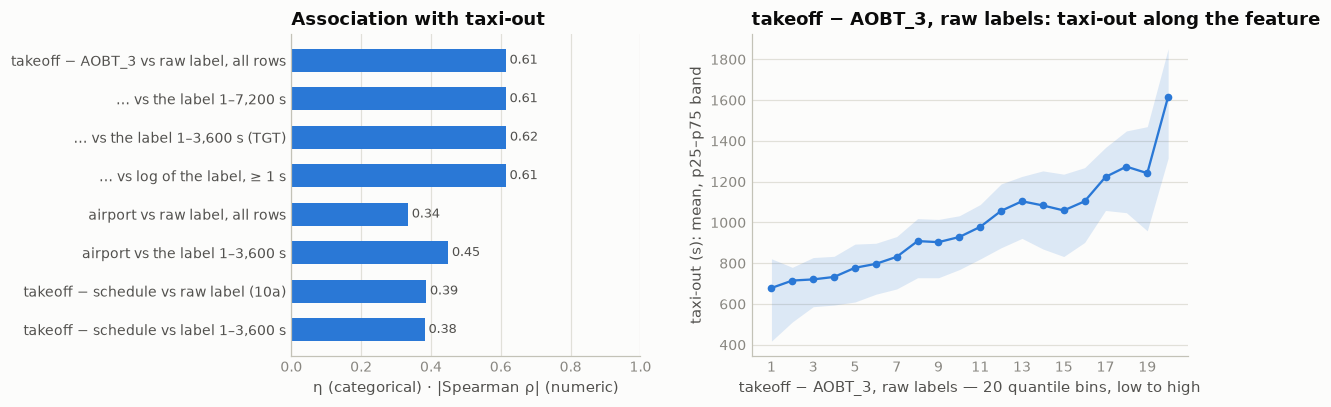

In [9]:
# correlation with the target — turned around: the target in its forms against its two best stand-ins, the anchor gap (ρ) and the airport (η),
# and against 10a's gauge. Raw labels over every departure, the notebook's 1–3,600 s window, a 7,200 s ceiling, the log: what the tail does to a marginal measure
RAW1 = f"(SELECT * FROM {RAWDEP} WHERE TAXITIME_SEC_mvt >= 1)"
RAW72 = f"(SELECT * FROM {RAWDEP} WHERE TAXITIME_SEC_mvt BETWEEN 1 AND 7200)"
ANCHOR = "epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)"
a = target_assoc([("takeoff − AOBT_3 vs raw label, all rows", "num", ANCHOR, 1, RAWDEP),
                  ("… vs the label 1–7,200 s", "num", ANCHOR, 1, RAW72),
                  ("… vs the label 1–3,600 s (TGT)", "num", ANCHOR),
                  ("… vs log of the label, ≥ 1 s", "num", ANCHOR, 1, RAW1, "ln(TAXITIME_SEC_mvt)"),
                  ("airport vs raw label, all rows", "cat", "ADEP_mvt", 1, RAWDEP),
                  ("airport vs the label 1–3,600 s", "cat", "ADEP_mvt"),
                  ("takeoff − schedule vs raw label (10a)", "num", "gap_s", 1, RAWDEP),
                  ("takeoff − schedule vs label 1–3,600 s", "num", "epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)")])
assoc_chart(a, ANCHOR, kind="num", src=RAWDEP, title="takeoff − AOBT_3, raw labels")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Integer seconds, the exact difference of the two stamps, blank exactly where we predict** | `INTEGER`; equal to takeoff − off-block (in-block − landing on arrivals) on all 4,857,331 rows of both files, no sub-second stamps; null on 344,841 of 344,841 ranking departures and on one training arrival; 5,176 distinct values. Range −12 to 131,167 s on training departures, −2,652 to 604,797 on arrivals | nothing is rounded or estimated: the label is the two stamps, and §9's hidden endpoint is the whole problem |
| **The body: a right-skewed quarter of an hour** | all ten hubs on 1–3,600 s: mean 981 s, median 911, sd 388; raw p01 291, p25 719, p75 1,188, p99 2,339. Hub means on the window from LSZH 741 to EGLL 1,354; sd 292 (LSZH) to 443 (LIRF) | the shape the association cells and ladders of §1–§13 have been working on |
| **The tails: 0.2% of rows, half the squared error** | all ten hubs: raw sd 546 against 388 on the window, p99.9 4,501 s. Rows over an hour: 3,542 at 1–2 h (0.17% of rows, 8.1% of the squared error about the hub means), 550 at 2–12 h (14.8%), **34 over 12 h (31.7%)** — 4,126 rows, 54.6%. The worst 1% of rows carry 63% of it, against 22% on the window. LIRF: sd 1,332 raw, 443 on the window; its rows over an hour own 88.7% of its squared error. Of the rows over 2 h, 82–91% are Fiumicino's and 81–97% have neither plan nor anchor | RMSE is the tail's metric. The window is the right place to measure *association*; the score has to be measured on the labels as delivered |
| **On the holdout, four rows are more than half the RMSE** | Nov+Dec, 328,009 departures, the airport mean fit on Jan–Oct raw labels: 496.5 s. By band, what each adds to it: 13–3,600 s (99.83% of rows) 358.9 s; 3,601–7,200 (422 rows) 125.5; 2–12 h (57 rows) 164.4; **over 12 h (4 rows) 273.5**. The same predictions score 380.5 on labels up to 7,200 s and 359.3 on the window | the 357 s the sweep has been improving is the floor; what sits on it is decided by a few dozen rows — `VALIDATION/FINDINGS.md` §2 in the notebook's own numbers |
| **The band between one and two hours is mostly 10a's defect on rows *with* a plan — and the anchor cannot see it** | LIRF's 1,487 rows: 79% have a plan, 84% carry a block stamp within 5 min of the schedule (41% on its clean rows), the plan's `AOBT_3` sits a median 3,355 s *after* the block stamp, takeoff − `AOBT_3` is 1,078 s where the label is 4,561, and 0% of anchors are within 10 min of the label. EGLL 691, EDDF 73, EDDM 59, LSZH 20: `AOBT_3` 2,768–3,568 s after the block, 0–19% within 10 min. Label − anchor gap in the band: p10 1,015, median 3,057, p90 4,446 s, against −363 / −52 / +306 on the window. The two real ones: LTFM 773 (59% on days whose median taxi passed 1,500 s — February's snow) and EHAM 79 (83% within 10 min, 5 January) | an off-block stamp written an hour before the aircraft moved is unpredictable from the anchor, which is the model's strongest feature; only the pushback delay can hint at it — the next row |
| **At Fiumicino, a delayed flight's label carries its delay one time in ten** | departures with a plan, by the plan's pushback delay `AOBT_3` − schedule: 15–45 min, LIRF 43,184 rows, block = schedule on 12.4% (other hubs 2.4%), mean label 1,307 s over an anchor gap of 925 (others 1,039 over 955); 45–90 min, 7.3% (0.4%), 1,476 over 938, the label passing an hour on 7.8% (0.8%); 90–180 min 1.8% (0.1%). Under 15 min the two sides agree (59.5% vs 52.6%: a punctual pushback *is* within 5 min of the schedule) | label = anchor gap + pushback delay with probability ~10% at LIRF, and those rows sit inside the 1–3,600 s window as "clean" ones. Airport × pushback delay is how the model learns it — §10 saw the delay's gain without the mechanism |
| **Keeping the tail in training pays only through the features that see it** | training filter → predictor, scored on every raw label: airport alone 495.8 (fit 1–3,600) · 496.0 (1–7,200) · 496.5 (≥ 1) — a wash, the holdout's tail being thinner than the fit's (61 rows over 7,200 s in 328,009, 1.9 per 10,000, against 523 in 1,757,038, 3.0); airport × no-plan 495.8 · 488.9 · **475.0**; 10a's gauge 491.4 · 489.4 · **466.9**. LIRF 1,285.6 → 1,149.6. The window rows pay 2–4 s for the hedge (airport 357.3 → 359.3, the gauge 352.6 → 356.5). Negatives in or out: 466.8 vs 466.9 | the harness's `≥ 1, no ceiling` is right, and it is right *because* airport, no-plan and takeoff − schedule are in the model; `pipeline/train.py`'s 7,200 ceiling costs 22 s on the gauge and should be aligned |
| **The sweep's ladders on the labels as scored** | fit on labels ≥ 1: airport 496.5 → × 20 anchor bins **427.8** (302.5 on the window, §9's 293.5 with the tail in the fit) → × 10a's gauge 417.8 → × the pushback-delay band **411.4** (284.9 on the window, LIRF 1,136); the gauge alone 466.9, with the delay band 459.0 | every honest number in §7–§13 is a window number; on raw labels the same ladder sits 120–130 s higher, and the gap is the tail's, not the features' |
| **The loss rewards the mean** | airport-level fit on labels ≥ 1: mean 496.5 · median 498.8 · geometric mean 499.6 on every label; 359.3 · 360.0 · 361.6 on the window. Per hub the mean sits 24–183 s above the median (EDDF 24, LTFM 92, LIRF 183) and 40–134 s above the geometric mean | squared loss on the raw label: no log transform, no median objective — and no clipping of predictions at a plausible taxi, since the gauge's prediction for a corrupt row is the gap itself, hours |
| **The rows at or below zero cost nothing either way** | 388 training departures at or below zero (369 negative, 19 zero) and 370 at 1–12 s — 64.7% and 63.5% of them without a plan (§9: Zurich's helipad and the collapsed airliner stamps). On the holdout 41 + 37 rows, 0.03% + 0.03% of the squared error; in training or out, 466.8 vs 466.9 | §9's open question closed: no repair, no removal; they train where the label is ≥ 1 s, as the harness has it, and it does not matter |
| **2026 carries the corrupt slice, and January's is bigger** | Fiumicino departures without a plan: January 2025 60 rows (0.53% of LIRF's departures), 13 corrupt (21.7%); **January 2026 107 rows (0.97%)** — 23 corrupt expected at January's rate, 32 at the year's 29.5%; July 2025 337 rows (2.22%), 84 corrupt (24.9%); **July 2026 276 (1.74%)** — 69 / 81 expected. 2025's monthly share never fell below 21.7% | the slice is 178% of its January 2025 size and 82% of July's, against break-evens of 7.4% and 34.2% of 2025's rate (`VALIDATION/FINDINGS.md` §3): the tail bet holds in both months, and the gauge matters more in January 2026 than it did in January 2025 |
| **The arrival half's corruption is another defect — and it is also there in 2026** | 141 training arrivals over 7,200 s (119 at LIRF), 6 without a plan, the block stamp within 5 min of the schedule on 12.8%, a median 8,043 s *after* the plan's in-block `ARVT_3`: an in-block stamp hours late, not the timetable written as a stamp. 27 in the ranking file (17 LIRF, none without a plan), the same shape. LIRF arrivals per 10,000: January 1.77 → 3.62, July 8.56 → 8.23. Across the 120 hub × month cells of 2025 the two phases' rates correlate 0.85 (LIRF's twelve months alone 0.52) | not the gauge's mechanism, so no direct read on the departure rate — but whatever produces bad stamps at Fiumicino was running in both scored months at 2025's level or above |
| **The label's proxy says 2026 sits on 2025, with three moves** | median takeoff − `AOBT_3`, 2025 → 2026: EDDF 907 → 954 (January), 896 → 929 (July); EHAM 812 → 863, 900 → 964; LFPG 898 → 959 (July); EGLL 1,376 → 1,321 (July); the other six within ±18 s. Arrivals' median taxi-in: EHAM July 412 → 335, EDDF July 565 → 502, EGLL January 426 → 473 | the moves are where §13 saw a new pier (Frankfurt) and §12 saw configurations swing (Schiphol); the anchor gap carries them into the prediction because it is a feature — the calendar cannot |
| **The month moves each hub by 50–209 s, and the scored months sit at the extremes** | monthly means on the window: LIRF 1,020 (February) → 1,229 (July), EDDM 766 (March) → 944 (December), LFPG 929 → 1,093 (November), LTFM 986 → 1,141 (February, the snow), EHAM 716 (June) → 846 (March), LEBL 887 (January) → 1,008 (July), EGLL 1,307 → 1,402 (July); LSZH 723 → 773 (January). July is the high month at LIRF, LEBL and EGLL; January the high at LSZH and the low at LEBL | §8 read the calendar as flat because the hubs cancel; per hub it is a ±100 s effect with 2025's own January and July in the file, so hub × month is a real feature — but a weather month (LTFM's February) does not transfer |
| **What the tail does to a marginal measure** | takeoff − `AOBT_3`: ρ 0.615 on every label form (r 0.527–0.545) — the corrupt rows have no anchor, so its correlation never sees them; the airport's η 0.450 on the window, **0.335** raw; takeoff − schedule r 0.190 on the window, **0.232** raw — the one feature whose correlation *rises* with the tail, 10a's gauge | the notebook's window is the right place for association (a raw η is a statement about 34 rows); the raw-label ladders above are where the tail is measured |

**Decisions**

| issue | decision | why |
|---|---|---|
| the training label filter | **every label from 1 s up, no ceiling** — as the harness has it (`MAX_TAXI_SEC = 200_000`); `pipeline/train.py`'s 7,200 ceiling to be aligned | 489.4 → 466.9 on the gauge ladder; the tail pays only through the features that see it, so those features (airport, no-plan, takeoff − schedule, the pushback delay) must be in the model |
| the rows at or below zero, and §9's 289 collapsed stamps | out below 1 s, in from 1 s, no repair | 0.06% of the holdout's squared error; 466.8 vs 466.9 either way |
| the objective | **squared loss on the raw label**; no log transform; no ceiling on predictions | mean 496.5 < median 498.8 < geometric mean 499.6; a corrupt row's best prediction is hours |
| the band between one and two hours | no repair; the pushback delay per airport as the feature that sees it (`AOBT_3` − schedule, kept by §10) | 417.8 → 411.4 on the raw ladder, 294.5 → 284.9 on the window; the mechanism is 10a's, on rows with a plan |
| the statistics window | 1–3,600 s stays for association cells and feature ladders; raw labels for anything that touches the score | sd 388 against 546; a raw η is a statement about 34 rows |
| the month | hub × month as a feature, no weather memory | 50–209 s per hub; 2025's own January and July are in the file; LTFM's February was snow |
| the 2026 corruption | no hedge beyond the tail in training and the gauge | the slice is 178% / 82% of 2025's in the two months, both far above break-even |

**State after §14** — unchanged: the label is never touched. 344,841 ranking departures null before and after; every training value as delivered.

**Use in modeling.** Fit for the mean of the raw label with squared loss, on every training departure
with a label ≥ 1 s, with no ceiling on labels or predictions. The score is the window's 357 s plus
what a few dozen rows add, and the model reaches those rows only through the features that describe
them: the airport, the no-plan flag, takeoff − schedule and the pushback delay `AOBT_3` − schedule
per airport (§10, §10a), and hub × month. Expect the tail to be at least 2025's size in both scored
months. In the closing matrix the target is the last row and column, on the window; the tail's
associations are this section's correlation cell.


## 15 · `LOBT_flt` — the plan's last off-block time

The first of the flight plan's clocks: the **last known off-block time** the Network Manager held
for the flight — the estimated off-block of the plan's most recent filing. On departure rows it is
the plan's own word on when our flight would leave the stand; on arrival rows it is the off-block
at the origin. It survives in the ranking file wherever a plan was matched, so takeoff − LOBT is
computable on every departure we predict that has a plan. The section asks what the clock is worth
on its own, how it relates to the plan's three other clocks (the initial `IOBT_flt`, the M1
estimate `EOBT_1_flt` and the flown `AOBT_3_flt`, each with its own section) and to the timetable,
and what the two delays it separates — the one the airline filed and the one it did not — buy on
top of §9's anchor.

| step | question | what came out |
|---|---|---|
| **census** | present where; which grid; against the schedule; the rows where it sits after the takeoff | wherever a plan is, bar 46 + 7 empty blocks; a whole minute on the 5-minute grid; the schedule on 74%, 20 min later on the rest; after the takeoff on 0.83% — stale plans of early leavers |
| **the plan's clocks** | last against initial, M1 and actual | "last known" is the initial one on 99.45% of departures: the day's delay is never refiled; the pushback comes a median 4 min after it, before it on 30% |
| **the two delays** | the filed delay LOBT − schedule and the unfiled delay `AOBT_3` − LOBT against taxi-out — and against the anchor's error | the unfiled delay moves taxi-out by 5 minutes across its bands and the anchor's error by 11: where the two clocks disagree the truth lies between |
| **signal** | honest ladders: the gap alone; the two delays on §9's anchor against §10's schedule- and `EOBT_1`-based ones; the flags; 2026 against 2025 | 301.2 alone; the unfiled delay takes the anchor 293.5 → 261.0, 7 s better than the schedule's, 4 s behind `EOBT_1`'s; the filed delay and the flags nothing; 2026 sits on 2025 |
| **closing state** | what §2's twin layers fill | 1,898 + 479 departures get their twin's clock; 0.99% / 1.40% stay without one |


In [3]:
# census by file × phase: present wherever a plan was matched, bar a few dozen rows whose plan block is empty behind its ID; a whole
# minute on the timetable's grid; then the plan's last off-block against the schedule, and the rows where it sits after the takeoff itself
BOTH = f"(SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})"
print("LOBT_flt by file × phase:")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (LOBT_flt IS NULL) n_null, count(*) FILTER (FLIGHT_ID_mvt IS NULL) no_plan,
           count(*) FILTER (LOBT_flt IS NULL AND FLIGHT_ID_mvt IS NOT NULL) null_with_an_id,
           round(100.0*count(*) FILTER (extract(second FROM LOBT_flt) = 0)/count(LOBT_flt), 1) pct_on_minute,
           round(100.0*count(*) FILTER (extract(minute FROM LOBT_flt) % 5 = 0 AND extract(second FROM LOBT_flt) = 0)/count(LOBT_flt), 1) pct_on_5min_grid,
           count(DISTINCT LOBT_flt) n_unique, strftime(min(LOBT_flt), '%Y-%m-%d %H:%M') first_stamp, strftime(max(LOBT_flt), '%Y-%m-%d %H:%M') last_stamp
    FROM {BOTH} GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nthe rows with a FLIGHT_ID but no LOBT — an empty plan block behind the ID (both files):")
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(IOBT_flt) iobt, count(EOBT_1_flt) eobt1, count(AOBT_3_flt) aobt3, count(ARVT_3_flt) arvt3,
           count(CALLSIGN_flt) callsign, count(AIRCRAFT_OPERATOR_flt) operator_, count(MARKET_SEGMENT_flt) segment,
           string_agg(DISTINCT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt END, ' ') dep_hubs
    FROM {BOTH} WHERE FLIGHT_ID_mvt IS NOT NULL AND LOBT_flt IS NULL GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().fillna("").to_string(index=False))

print("\ndepartures with a plan: the last off-block against the schedule (training):")
print(con.sql(f"""
    SELECT count(*) n, round(100.0*count(*) FILTER (LOBT_flt = SCHED_TIME_UTC_mvt)/count(*), 1) pct_equal_to_schedule,
           round(100.0*count(*) FILTER (LOBT_flt > SCHED_TIME_UTC_mvt)/count(*) FILTER (LOBT_flt != SCHED_TIME_UTC_mvt), 1) pct_later_when_different,
           round(quantile_cont(epoch(LOBT_flt - SCHED_TIME_UTC_mvt)/60.0, 0.5) FILTER (LOBT_flt != SCHED_TIME_UTC_mvt), 1) med_min_later_when_different,
           round(quantile_cont(epoch(LOBT_flt - SCHED_TIME_UTC_mvt)/60.0, 0.9) FILTER (LOBT_flt != SCHED_TIME_UTC_mvt), 1) p90_when_different,
           round(100.0*count(*) FILTER (LOBT_flt > MVT_TIME_UTC_mvt)/count(*), 2) pct_after_the_takeoff
    FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL""").df().to_string(index=False))

print("\nthe plan's last off-block after the actual takeoff — who, and is the plan stale or wrong (training departures):")
print(con.sql(f"""
    SELECT count(*) n, round(quantile_cont(epoch(LOBT_flt - MVT_TIME_UTC_mvt)/60.0, 0.5), 1) med_min_after_takeoff,
           round(quantile_cont(epoch(LOBT_flt - MVT_TIME_UTC_mvt)/60.0, 0.9), 1) p90_min,
           round(100.0*count(*) FILTER (LOBT_flt = IOBT_flt)/count(*), 1) pct_never_refiled,
           round(100.0*count(*) FILTER (abs(epoch(AOBT_3_flt - BLOCK_TIME_UTC_mvt)) <= 300)/count(AOBT_3_flt), 1) pct_aobt3_within_5min_of_block,
           round(100.0*count(*) FILTER (AOBT_3_flt > MVT_TIME_UTC_mvt)/count(AOBT_3_flt), 1) pct_aobt3_also_after_takeoff,
           round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_label
    FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt > MVT_TIME_UTC_mvt""").df().to_string(index=False))
print(con.sql(f"""
    SELECT coalesce(MARKET_SEGMENT_flt, '∅') segment, count(*) n, round(100.0*count(*) FILTER (LOBT_flt > MVT_TIME_UTC_mvt)/count(*), 2) pct_lobt_after_takeoff,
           round(100.0*count(*) FILTER (LOBT_flt > AOBT_3_flt)/count(AOBT_3_flt), 1) pct_lobt_after_aobt3,
           round(100.0*count(*) FILTER (LOBT_flt != IOBT_flt)/count(*), 2) pct_refiled
    FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))


LOBT_flt by file × phase:


     src  ph       n  n_null  no_plan  null_with_an_id  pct_on_minute  pct_on_5min_grid  n_unique      first_stamp       last_stamp
training ARR 2082750   15449     8506             6943           97.9              90.7    266771 2025-01-01 00:00 2025-12-31 23:02
training DEP 2085047   22470    22424               46           99.7              94.9    186897 2025-01-01 00:20 2025-12-31 23:40
 ranking ARR  344693    2552     1409             1143           97.9              90.7     44714 2026-01-01 00:00 2026-07-31 22:55
 ranking DEP  344841    5290     5283                7           99.8              94.3     32779 2026-01-01 00:04 2026-07-31 23:30

the rows with a FLIGHT_ID but no LOBT — an empty plan block behind the ID (both files):
     src  ph    n  iobt  eobt1  aobt3  arvt3  callsign  operator_  segment                      dep_hubs
training ARR 6943     0      0      0      0         0          0        0                              
training DEP   46     0      0      0    

      segment       n  pct_lobt_after_takeoff  pct_lobt_after_aobt3  pct_refiled
     Mainline 1325748                    0.49                  29.6         0.59
      Lowcost  399482                    0.93                  27.7         0.56
     Regional  210865                    0.53                  26.7         0.16
        Cargo   60021                    3.68                  42.9         0.69
     Business   44498                    6.73                  39.0         0.63
Non-Scheduled   14577                    2.33                  27.2         0.50
        Other    6673                    3.21                  37.5         0.57
     Military     713                    6.45                  34.2         0.56


In [4]:
# the last off-block against the plan's other clocks: how often it equals the initial one, the M1 estimate and the actual; the gaps
# in minutes; the pattern of the three filed clocks per flight; and the same per hub (training departures with a plan)
print("LOBT against the plan's other clocks — training departures with a plan:")
print(con.sql(f"""
    SELECT count(*) n,
           round(100.0*count(*) FILTER (LOBT_flt = IOBT_flt)/count(*), 2) eq_iobt, round(100.0*count(*) FILTER (LOBT_flt > IOBT_flt)/count(*), 2) after_iobt,
           round(100.0*count(*) FILTER (LOBT_flt < IOBT_flt)/count(*), 2) before_iobt,
           round(100.0*count(*) FILTER (LOBT_flt = EOBT_1_flt)/count(*), 1) eq_eobt1, round(100.0*count(*) FILTER (LOBT_flt < EOBT_1_flt)/count(*), 1) before_eobt1,
           round(100.0*count(*) FILTER (LOBT_flt > EOBT_1_flt)/count(*), 1) after_eobt1,
           round(100.0*count(*) FILTER (LOBT_flt <= AOBT_3_flt)/count(AOBT_3_flt), 1) at_or_before_aobt3, round(100.0*count(*) FILTER (LOBT_flt > AOBT_3_flt)/count(AOBT_3_flt), 1) after_aobt3,
           count(*) FILTER (IOBT_flt IS NULL) iobt_null, count(*) FILTER (EOBT_1_flt IS NULL) eobt1_null, count(*) FILTER (AOBT_3_flt IS NULL) aobt3_null
    FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL""").df().to_string(index=False))

print("\nthe gaps in minutes — quantiles p01 / p10 / p25 / p50 / p75 / p90 / p99 (training departures with a plan):")
for name, expr in [("LOBT − IOBT, the refile", "epoch(LOBT_flt - IOBT_flt)/60"),
                   ("   … where the two differ", "CASE WHEN LOBT_flt != IOBT_flt THEN epoch(LOBT_flt - IOBT_flt)/60 END"),
                   ("LOBT − schedule, the filed delay", "epoch(LOBT_flt - SCHED_TIME_UTC_mvt)/60"),
                   ("EOBT_1 − LOBT", "epoch(EOBT_1_flt - LOBT_flt)/60"),
                   ("   … where the two differ", "CASE WHEN EOBT_1_flt != LOBT_flt THEN epoch(EOBT_1_flt - LOBT_flt)/60 END"),
                   ("AOBT_3 − LOBT, the unfiled delay", "epoch(AOBT_3_flt - LOBT_flt)/60"),
                   ("off-block − LOBT (hidden)", "epoch(BLOCK_TIME_UTC_mvt - LOBT_flt)/60"),
                   ("takeoff − LOBT", "epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60")]:
    q, n = con.sql(f"SELECT quantile_cont({expr}, [0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]), count({expr}) FROM {T} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL").fetchone()
    print(f"  {name:34s} n = {n:>9,}   " + "  ".join(f"{x:6.1f}" for x in q))

print("\nthe three filed clocks per flight — which agree (training departures 1–3,600 s with all three):")
print(con.sql(f"""
    SELECT CASE WHEN IOBT_flt = LOBT_flt AND LOBT_flt = EOBT_1_flt THEN '1 · all three equal'
                WHEN IOBT_flt = LOBT_flt THEN '2 · IOBT = LOBT, EOBT_1 differs' WHEN LOBT_flt = EOBT_1_flt THEN '3 · LOBT = EOBT_1, IOBT differs'
                WHEN IOBT_flt = EOBT_1_flt THEN '4 · IOBT = EOBT_1, LOBT differs' ELSE '5 · all different' END pattern,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct,
           round(quantile_cont(epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt)/60, 0.5), 1) med_pushback_delay_min,
           round(quantile_cont(epoch(EOBT_1_flt - LOBT_flt)/60, 0.5), 1) med_eobt1_minus_lobt, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi
    FROM {TGT} WHERE LOBT_flt IS NOT NULL AND IOBT_flt IS NOT NULL AND EOBT_1_flt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nper hub — refiled share, early pushers, the unfiled delay and takeoff − LOBT (training departures 1–3,600 s with a plan):")
print(con.sql(f"""
    SELECT ADEP_mvt hub, count(*) n, round(100.0*count(*) FILTER (LOBT_flt != IOBT_flt)/count(*), 2) pct_refiled,
           round(100.0*count(*) FILTER (LOBT_flt > AOBT_3_flt)/count(AOBT_3_flt), 1) pct_pushed_before_lobt,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.1), 1) unfiled_p10, round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.5), 1) unfiled_p50,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.9), 1) unfiled_p90,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60, 0.5), 1) med_takeoff_minus_lobt
    FROM {TGT} WHERE LOBT_flt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))


LOBT against the plan's other clocks — training departures with a plan:
      n  eq_iobt  after_iobt  before_iobt  eq_eobt1  before_eobt1  after_eobt1  at_or_before_aobt3  after_aobt3  iobt_null  eobt1_null  aobt3_null
2062577    99.45        0.29         0.26      70.0          11.7         18.3                70.5         29.5          0           0           0

the gaps in minutes — quantiles p01 / p10 / p25 / p50 / p75 / p90 / p99 (training departures with a plan):
  LOBT − IOBT, the refile            n = 2,062,577      0.0     0.0     0.0     0.0     0.0     0.0     0.0
     … where the two differ          n =    11,267    -14.1    -8.3    -4.0     1.0     9.2    15.4    42.2


  LOBT − schedule, the filed delay   n = 2,062,577    -10.0     0.0     0.0     0.0     0.0    25.0   120.0
  EOBT_1 − LOBT                      n = 2,062,577    -15.0    -5.0     0.0     0.0     0.0     4.0    21.0


     … where the two differ          n =   618,141    -20.0   -10.0    -9.0    -4.0     6.0    10.0    35.0


  AOBT_3 − LOBT, the unfiled delay   n = 2,062,577    -18.0    -7.0    -2.0     4.0    11.0    20.0    46.0


  off-block − LOBT (hidden)          n = 2,062,577    -14.0    -4.5    -0.1     4.2    11.0    18.9    43.7


  takeoff − LOBT                     n = 2,062,577      0.9     9.4    14.2    20.6    28.4    38.0    64.0

the three filed clocks per flight — which agree (training departures 1–3,600 s with all three):


                        pattern       n   pct  med_pushback_delay_min  med_eobt1_minus_lobt  med_taxi
            1 · all three equal 1431676 69.52                     6.0                   0.0     906.0
2 · IOBT = LOBT, EOBT_1 differs  616581 29.94                    11.0                  -4.0     945.0
3 · LOBT = EOBT_1, IOBT differs   10964  0.53                    17.0                   0.0    1061.0
4 · IOBT = EOBT_1, LOBT differs      38  0.00                    29.0                   0.8    1152.0
              5 · all different     142  0.01                    23.5                  -0.6    1121.0

per hub — refiled share, early pushers, the unfiled delay and takeoff − LOBT (training departures 1–3,600 s with a plan):


 hub      n  pct_refiled  pct_pushed_before_lobt  unfiled_p10  unfiled_p50  unfiled_p90  med_takeoff_minus_lobt
EDDF 228115         0.36                    23.2         -4.0          5.0         21.0                    20.5
EDDM 166276         0.12                    25.5         -5.0          5.0         21.0                    17.0
EGLL 237449         0.55                    39.7         -9.0          1.0         17.0                    25.0
EHAM 243794         0.02                    26.3         -5.0          4.0         18.0                    19.3
LEBL 177837         0.90                    25.7         -6.0          5.0         21.0                    19.5
LEMD 211295         0.54                    22.7         -4.0          5.0         20.0                    21.6
LFPG 235375         0.06                    27.0         -6.0          5.0         25.0                    21.9
LIRF 157994         0.14                    26.3         -6.0          5.0         21.0                 

taxi-out by the refile LOBT − IOBT (training departures 1–3,600 s with a plan):


               refile       n   pct  mean_taxi  med_taxi  med_unfiled_delay_min
  1 · refiled earlier    5204  0.25     1127.0    1023.0                   13.0
      2 · not refiled 2048257 99.46      981.0     911.0                    4.0
3 · later by ≤ 15 min    4769  0.23     1142.0    1043.0                    6.4
        4 · 15–60 min    1135  0.06     1231.0    1159.0                    5.2
         5 · over 1 h      36  0.00     1420.0    1219.0                    4.6

taxi-out by the unfiled delay AOBT_3 − LOBT — and the anchor's error, mean label minus mean takeoff − AOBT_3 (same rows, with an anchor):


     unfiled_delay      n  pct  mean_taxi  med_taxi  mean_anchor_gap  label_minus_anchor
1 · > 30 min early   3088  0.1     1000.0     892.0           2887.0             -1887.0
   2 · 10–30 early  96274  4.7      880.0     833.0           1258.0              -378.0
    3 · 2–10 early 347173 16.9      902.0     851.0           1093.0              -191.0
4 · on the plan ±2 434416 21.1      926.0     889.0           1004.0               -79.0
     5 · 2–10 late 614562 29.8      965.0     909.0            955.0                10.0
    6 · 10–30 late 483607 23.5     1085.0    1017.0            950.0               136.0
    7 · 30–60 late  77532  3.8     1239.0    1117.0            944.0               295.0
 8 · over 1 h late   2749  0.1     1695.0    1507.0            229.0              1466.0


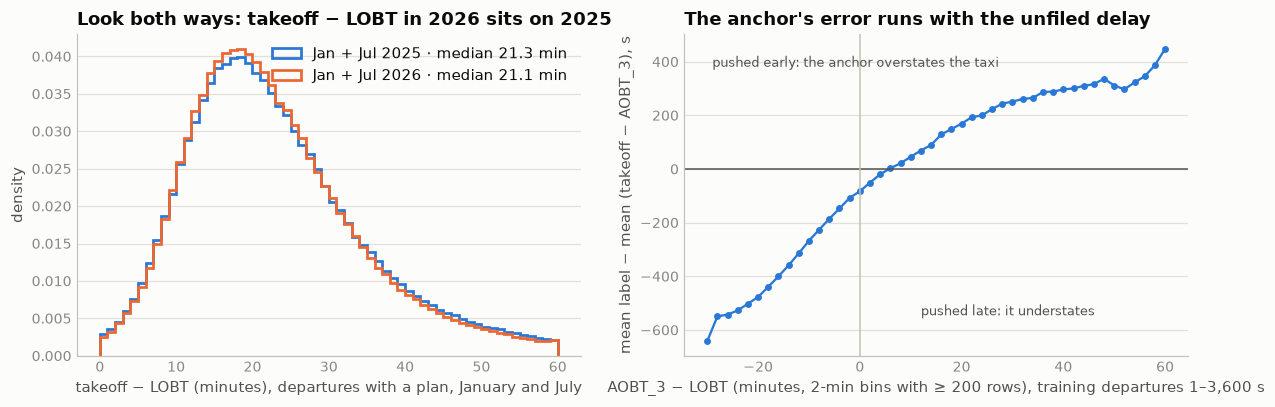

In [5]:
# the two delays the clock measures, and the anchor's error along the unfiled one: taxi-out by band of the refile and of the unfiled delay,
# with the mean label against the mean anchor gap; the picture — the feature in 2026 against 2025, and the anchor's error along the delay
print("taxi-out by the refile LOBT − IOBT (training departures 1–3,600 s with a plan):")
print(con.sql(f"""
    SELECT CASE WHEN d < 0 THEN '1 · refiled earlier' WHEN d = 0 THEN '2 · not refiled' WHEN d <= 15 THEN '3 · later by ≤ 15 min' WHEN d <= 60 THEN '4 · 15–60 min' ELSE '5 · over 1 h' END refile,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 2) pct, round(avg(TAXITIME_SEC_mvt)) mean_taxi, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.5), 1) med_unfiled_delay_min
    FROM (SELECT *, epoch(LOBT_flt - IOBT_flt)/60 d FROM {TGT} WHERE LOBT_flt IS NOT NULL) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\ntaxi-out by the unfiled delay AOBT_3 − LOBT — and the anchor's error, mean label minus mean takeoff − AOBT_3 (same rows, with an anchor):")
print(con.sql(f"""
    SELECT CASE WHEN d < -30 THEN '1 · > 30 min early' WHEN d < -10 THEN '2 · 10–30 early' WHEN d < -2 THEN '3 · 2–10 early' WHEN d <= 2 THEN '4 · on the plan ±2' WHEN d <= 10 THEN '5 · 2–10 late'
                WHEN d <= 30 THEN '6 · 10–30 late' WHEN d <= 60 THEN '7 · 30–60 late' ELSE '8 · over 1 h late' END unfiled_delay,
           count(*) n, round(100.0*count(*)/sum(count(*)) OVER (), 1) pct, round(avg(TAXITIME_SEC_mvt)) mean_taxi, round(quantile_cont(TAXITIME_SEC_mvt, 0.5)) med_taxi,
           round(avg(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt))) mean_anchor_gap, round(avg(TAXITIME_SEC_mvt) - avg(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt))) label_minus_anchor
    FROM (SELECT *, epoch(AOBT_3_flt - LOBT_flt)/60 d FROM {TGT} WHERE LOBT_flt IS NOT NULL AND AOBT_3_flt IS NOT NULL) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

lob_h = con.sql(f"""
    SELECT CASE WHEN src = 'training' THEN '2025' ELSE '2026' END yr, epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60.0 g
    FROM {BOTH} WHERE PHASE_mvt = 'DEP' AND LOBT_flt IS NOT NULL AND month(MVT_TIME_UTC_mvt) IN (1, 7)""").df()
lob_e = con.sql(f"""
    SELECT round(epoch(AOBT_3_flt - LOBT_flt)/120.0) * 2 d, count(*) n, avg(TAXITIME_SEC_mvt) m, avg(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)) a
    FROM {TGT} WHERE LOBT_flt IS NOT NULL AND AOBT_3_flt IS NOT NULL GROUP BY 1 HAVING count(*) >= 200 AND d BETWEEN -30 AND 60 ORDER BY 1""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for yr, col in [("2025", BLUE), ("2026", ORANGE)]:
    v = lob_h[lob_h.yr == yr].g
    a1.hist(v, bins=60, range=(0, 60), density=True, histtype="step", lw=1.8, color=col, label=f"Jan + Jul {yr} · median {v.median():.1f} min")
a1.set_title("Look both ways: takeoff − LOBT in 2026 sits on 2025")
a1.set_xlabel("takeoff − LOBT (minutes), departures with a plan, January and July")
a1.set_ylabel("density")
a1.legend(loc="upper right")
style(a1)
a2.plot(lob_e.d, lob_e.m - lob_e.a, "o-", color=BLUE, ms=3.5)
a2.axhline(0, color=INK2, lw=1)
a2.axvline(0, color=BASELINE, lw=1)
a2.set_title("The anchor's error runs with the unfiled delay")
a2.set_xlabel("AOBT_3 − LOBT (minutes, 2-min bins with ≥ 200 rows), training departures 1–3,600 s")
a2.set_ylabel("mean label − mean (takeoff − AOBT_3), s")
a2.text(-29, (lob_e.m - lob_e.a).max() * 0.85, "pushed early: the anchor overstates the taxi", fontsize=8.5, color=INK2)
a2.text(12, (lob_e.m - lob_e.a).min() * 0.85, "pushed late: it understates", fontsize=8.5, color=INK2)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()


In [6]:
# what the clock buys — honest ladders, fit Jan–Oct → Nov+Dec, quantile bins cut on the fit rows per airport, cell support ≥ 30 else the
# coarser rung: takeoff − LOBT alone; the two delays on top of §9's anchor, against §10's schedule- and EOBT_1-based ones; the flags.
# Then look both ways: the feature in the two scored months against their 2025 twins
con.sql(f"""
    CREATE OR REPLACE TABLE lob_d AS
    SELECT MVT_ID_mvt id, ADEP_mvt hub, TAXITIME_SEC_mvt::DOUBLE y, month(MVT_TIME_UTC_mvt) >= 11 is_val,
           epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) g_aobt3, epoch(MVT_TIME_UTC_mvt - LOBT_flt) g_lobt,
           epoch(AOBT_3_flt - LOBT_flt) unfiled, epoch(LOBT_flt - SCHED_TIME_UTC_mvt) filed,
           epoch(AOBT_3_flt - SCHED_TIME_UTC_mvt) un_sched, epoch(AOBT_3_flt - EOBT_1_flt) un_eobt1,
           CASE WHEN LOBT_flt IS NULL THEN NULL WHEN LOBT_flt != IOBT_flt THEN 1 ELSE 0 END refiled,
           CASE WHEN LOBT_flt IS NULL THEN NULL WHEN LOBT_flt > MVT_TIME_UTC_mvt THEN 1 ELSE 0 END lobt_after_takeoff
    FROM {TGT}""")


def lob_ladder(*bins):
    """bins: (column, number of quantile bins — 0 keeps the column's own values as levels), nested left to right on top of the airport mean."""
    cuts = ", ".join(f"quantile_cont({c}, [{', '.join(str(i / n) for i in range(1, n))}]) c{k}" for k, (c, n) in enumerate(bins) if n)
    qcols = "".join(f", CASE WHEN {c} IS NULL THEN -1 ELSE list_count(list_filter(c{k}, x -> x <= {c})) END q{k}" if n else f", coalesce({c}, -1) q{k}"
                    for k, (c, n) in enumerate(bins))
    con.sql(f"""CREATE OR REPLACE TABLE lob_b AS
                WITH cuts AS (SELECT hub{', ' + cuts if cuts else ''} FROM lob_d WHERE NOT is_val GROUP BY 1)
                SELECT hub, y, is_val{qcols} FROM lob_d JOIN cuts USING (hub)""")
    keys, joins, preds = ["hub"], [], []
    for k in range(len(bins) + 1):
        if k:
            keys = keys + [f"q{k - 1}"]
        con.sql(f"CREATE OR REPLACE TABLE lob_r{k} AS SELECT {', '.join(keys)}, avg(y) m, count(*) c FROM lob_b WHERE NOT is_val GROUP BY ALL")
        joins.append(f"LEFT JOIN lob_r{k} USING ({', '.join(keys)})")
        preds.append(f"CASE WHEN lob_r{k}.c >= 30 THEN lob_r{k}.m END")
    return con.sql(f"""SELECT sqrt(avg((v.y - coalesce({', '.join(reversed(preds))}))^2)) FROM lob_b v {' '.join(joins)} WHERE v.is_val""").fetchone()[0]


n_val = con.sql("SELECT count(*) FROM lob_d WHERE is_val").fetchone()[0]
print(f"honest ladders — {n_val:,} Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):")
for name, bins in [("airport", ()),
                   ("airport × takeoff − LOBT, 20 bins", (("g_lobt", 20),)),
                   ("airport × takeoff − AOBT_3, 20 bins — §9's anchor", (("g_aobt3", 20),)),
                   ("anchor × AOBT_3 − LOBT, 5 bins — the unfiled delay", (("g_aobt3", 20), ("unfiled", 5))),
                   ("anchor × LOBT − schedule, 5 bins — the filed delay", (("g_aobt3", 20), ("filed", 5))),
                   ("anchor × unfiled × filed", (("g_aobt3", 20), ("unfiled", 5), ("filed", 5))),
                   ("anchor × AOBT_3 − schedule, 5 bins — §10's", (("g_aobt3", 20), ("un_sched", 5))),
                   ("anchor × AOBT_3 − EOBT_1, 5 bins — §10's", (("g_aobt3", 20), ("un_eobt1", 5))),
                   ("anchor × unfiled × AOBT_3 − EOBT_1", (("g_aobt3", 20), ("unfiled", 5), ("un_eobt1", 5))),
                   ("anchor × refiled flag", (("g_aobt3", 20), ("refiled", 0))),
                   ("anchor × LOBT-after-takeoff flag", (("g_aobt3", 20), ("lobt_after_takeoff", 0))),
                   ("anchor × unfiled × refiled flag", (("g_aobt3", 20), ("unfiled", 5), ("refiled", 0)))]:
    print(f"  {name:56s} {lob_ladder(*bins):6.1f}")

print("\nlook both ways — the feature in the scored months against their 2025 twins (all departures):")
print(con.sql(f"""
    SELECT yr, mon, count(*) n, round(100.0*count(LOBT_flt)/count(*), 2) pct_with_lobt,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60, 0.5), 1) med_takeoff_minus_lobt, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - LOBT_flt)/60, 0.9), 1) p90,
           round(quantile_cont(epoch(AOBT_3_flt - LOBT_flt)/60, 0.5), 1) med_unfiled_delay, round(quantile_cont(epoch(LOBT_flt - SCHED_TIME_UTC_mvt)/60, 0.9), 1) p90_filed_delay,
           round(100.0*count(*) FILTER (LOBT_flt != IOBT_flt)/count(LOBT_flt), 2) pct_refiled,
           round(100.0*count(*) FILTER (LOBT_flt > MVT_TIME_UTC_mvt)/count(LOBT_flt), 2) pct_lobt_after_takeoff
    FROM (SELECT year(MVT_TIME_UTC_mvt) yr, month(MVT_TIME_UTC_mvt) mon, * FROM {BOTH} WHERE PHASE_mvt = 'DEP') WHERE mon IN (1, 7)
    GROUP BY 1, 2 ORDER BY 2, 1""").df().to_string(index=False))


honest ladders — 327,485 Nov+Dec departures 1–3,600 s (rows without the clock fall to the airport's own rung):
  airport                                                   357.3
  airport × takeoff − LOBT, 20 bins                         301.2


  airport × takeoff − AOBT_3, 20 bins — §9's anchor         293.5


  anchor × AOBT_3 − LOBT, 5 bins — the unfiled delay        261.0


  anchor × LOBT − schedule, 5 bins — the filed delay        292.4


  anchor × unfiled × filed                                  259.2


...

  anchor × AOBT_3 − EOBT_1, 5 bins — §10's                  257.1


  anchor × unfiled × AOBT_3 − EOBT_1                        255.3
  anchor × refiled flag                                     293.0


  anchor × LOBT-after-takeoff flag                          293.1


  anchor × unfiled × refiled flag                           260.3

look both ways — the feature in the scored months against their 2025 twins (all departures):


  yr  mon      n  pct_with_lobt  med_takeoff_minus_lobt  p90  med_unfiled_delay  p90_filed_delay  pct_refiled  pct_lobt_after_takeoff
2025    1 153706          99.07                    19.0 36.9                2.0             25.0         0.19                    1.23
2026    1 152719          98.39                    20.9 40.7                3.0             35.0         0.24                    1.00
2025    7 190713          97.94                    23.2 44.4                7.0             35.0         0.71                    0.50
2026    7 192122          98.52                    21.6 40.0                5.0             30.0         0.96                    0.51


In [7]:
# closing state — the column after §15: nothing of its own repaired; §2's twin layers hand the departures they recover their twin's
# whole plan block, this clock included. Before → after per file, and the final distribution of takeoff − LOBT
TWINS = (f"(SELECT MVT_ID_mvt, LOBT_flt lobt_twin FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet') "
         f"UNION ALL SELECT MVT_ID_mvt, LOBT_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")
st = con.sql(f"""
    SELECT src, count(*) n, count(*) FILTER (LOBT_flt IS NULL) null_before, count(*) FILTER (coalesce(LOBT_flt, lobt_twin) IS NULL) null_after,
           count(*) FILTER (LOBT_flt IS NULL AND lobt_twin IS NOT NULL) filled_by_twins,
           round(100.0*count(*) FILTER (coalesce(LOBT_flt, lobt_twin) IS NULL)/count(*), 2) pct_null_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(LOBT_flt, lobt_twin))/60, 0.1), 1) p10_takeoff_minus_lobt_after,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(LOBT_flt, lobt_twin))/60, 0.5), 1) p50, round(quantile_cont(epoch(MVT_TIME_UTC_mvt - coalesce(LOBT_flt, lobt_twin))/60, 0.9), 1) p90
    FROM {BOTH} d LEFT JOIN {TWINS} w USING (MVT_ID_mvt) WHERE PHASE_mvt = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df()
print(st.to_string(index=False))
assert (st.null_before - st.filled_by_twins == st.null_after).all()
print("\nevery remaining null is a departure without a plan (or with an empty plan block behind its ID): nothing else to fill from")


     src       n  null_before  null_after  filled_by_twins  pct_null_after  p10_takeoff_minus_lobt_after  p50  p90
training 2085047        22470       20572             1898            0.99                           9.4 20.6 38.0
 ranking  344841         5290        4811              479            1.40                          10.0 21.1 40.2

every remaining null is a departure without a plan (or with an empty plan block behind its ID): nothing else to fill from


                          feature        kind  n / levels  pearson_r  spearman_ρ     η
           LOBT epoch — the trend     numeric     2059401      0.011       0.015      
                   takeoff − LOBT     numeric     2059401      0.499       0.507      
AOBT_3 − LOBT — the unfiled delay     numeric     2059401      0.230       0.196      
LOBT − schedule — the filed delay     numeric     2059401      0.028       0.020      
         LOBT − IOBT — the refile     numeric     2059401      0.015       0.024      
            refiled (LOBT ≠ IOBT) categorical           3                        0.032
           LOBT after the takeoff categorical           3                        0.073
                     LOBT missing categorical           2                        0.007


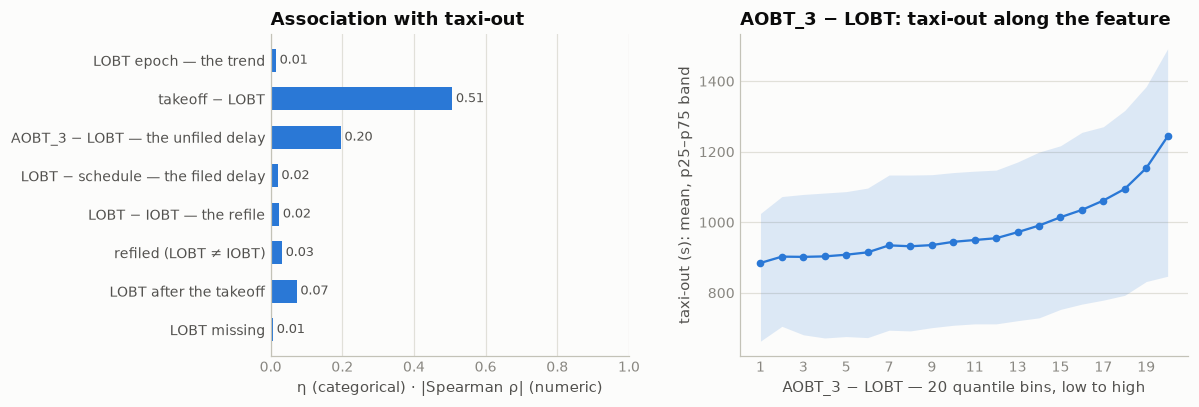

In [8]:
# correlation with the target: the stamp itself is a calendar; its model-facing forms are the gap to takeoff, the two delays it splits
# the pushback delay into, the refile, and the two flags
a = target_assoc([("LOBT epoch — the trend", "num", "epoch(LOBT_flt)"),
                  ("takeoff − LOBT", "num", "epoch(MVT_TIME_UTC_mvt - LOBT_flt)"),
                  ("AOBT_3 − LOBT — the unfiled delay", "num", "epoch(AOBT_3_flt - LOBT_flt)"),
                  ("LOBT − schedule — the filed delay", "num", "epoch(LOBT_flt - SCHED_TIME_UTC_mvt)"),
                  ("LOBT − IOBT — the refile", "num", "epoch(LOBT_flt - IOBT_flt)"),
                  ("refiled (LOBT ≠ IOBT)", "cat", "LOBT_flt != IOBT_flt"),
                  ("LOBT after the takeoff", "cat", "LOBT_flt > MVT_TIME_UTC_mvt"),
                  ("LOBT missing", "cat", "LOBT_flt IS NULL")])
assoc_chart(a, "epoch(AOBT_3_flt - LOBT_flt)", kind="num", title="AOBT_3 − LOBT")


**Findings**

| fact | evidence | what it means for us |
|---|---|---|
| **Present wherever a plan is — and 53 IDs have nothing behind them** | null on 22,470 training departures: 22,424 without a plan and 46 with a `FLIGHT_ID` whose whole plan block is empty (no callsign, operator or clock); 5,290 in the ranking file (5,283 + 7). On arrivals the empty block is common: 6,943 + 1,143 rows | the "no plan" flag should read the block, not the ID — `LOBT_flt IS NULL` differs from `FLIGHT_ID_mvt IS NULL` on 53 departures; otherwise nothing to repair |
| **A whole minute on the timetable's grid, and usually the timetable itself** | 99.7% on the minute, 94.9% on the 5-minute grid, 186,897 distinct values; equal to the schedule on 74.0% of departures with a plan, and where different later 87.9% of the time, by a median 20 min (p90 70) | the plan's clock is the schedule plus the slot moved at filing — the *filed* delay, LOBT − schedule, zero on three flights in four |
| **"Last known" is the initial one: the day's delay is never refiled** | equal to `IOBT_flt` on 99.45%; 11,267 refiled rows (0.55%), moved by a median +1 min (p10 −8, p90 +15, p99 +42); refiled flights taxi longer either way — medians 1,023 s (earlier), 1,043 to 1,219 s (later), 911 not refiled; LTFM refiles most, 2.08%, EHAM 0.02%. `EOBT_1` is the clock that moves: it differs on 30.0% of departures, by a median −4 min | §2b's mechanism in the whole file: a matcher keyed on the plan's off-block loses the flights that ran late. `IOBT_flt` (§16) is this column's copy on 99.45% of rows; the differences belong to `EOBT_1`'s section |
| **The pushback comes 4 min after the plan's clock — and before it on 30%** | `AOBT_3` − LOBT p10 −7, median +4, p90 +20, p99 +46 min; the hidden off-block − LOBT −4.5 / +4.2 / +18.9; takeoff − LOBT 9.4 / 20.6 / 38.0, p99 64. Early pushers per hub: LSZH 12.9%, EDDF to LFPG 23–27%, EGLL 39.7%, **LTFM 52.0%** with a median unfiled delay of −1 min | the *unfiled* delay, `AOBT_3` − LOBT, is what happened on the day, and its sign and size are per hub |
| **After the actual takeoff on 0.83% — stale plans of flights that left early** | 17,133 rows, LOBT a median 2.6 min (p90 11) after the takeoff; 99.9% never refiled; `AOBT_3` within 5 min of the block stamp on 62.2% and itself after the takeoff on 1.4%; median label 624 s. Business 6.73%, Military 6.45%, Cargo 3.68%, Mainline 0.49% | the plan is the right flight, with a filed slot the aircraft did not wait for; takeoff − LOBT goes negative and says so. No repair — the flag adds 0.4 s on the ladder |
| **The anchor's error runs with the unfiled delay** | mean label − mean (takeoff − `AOBT_3`) by band of `AOBT_3` − LOBT: −378 s at 10–30 min early, −191 at 2–10 early, −79 on the plan, +10 at 2–10 late, +136 at 10–30, **+295 at 30–60 late**, +1,466 over an hour (2,749 rows, §14's defect); taxi-out itself 833 → 1,117 s median across the same bands | the two clocks are two estimates of the hidden off-block, and where they disagree the truth lies between: the further the pushback ran ahead of the plan the more the anchor overstates the taxi, the further behind the more it understates. This is the mechanism behind the gains §9 and §10 found in delay features |
| **The unfiled delay buys 32 s on the anchor; the filed delay nothing** | airport 357.3 → × takeoff − LOBT 301.2 (§9's number); the anchor 293.5 → × `AOBT_3` − LOBT **261.0** → × LOBT − schedule on top 259.2; the filed delay alone 292.4; §10's `AOBT_3` − schedule 268.4 and `AOBT_3` − `EOBT_1` 257.1; the unfiled delay × the `EOBT_1` one 255.3; the refiled flag 293.0, the after-takeoff flag 293.1 | LOBT's delay beats the schedule's by 7 s because the schedule's mixes the filed slot in; `EOBT_1`'s beats it by 4 s because that clock moved on the day. The feature is `AOBT_3` − LOBT per airport; LOBT − schedule, the refile and the flags are not |
| **2026 sits on 2025** | with a plan: January 99.07% → 98.39%, July 97.94% → 98.52%; takeoff − LOBT median January 19.0 → 20.9 min (p90 36.9 → 40.7), July 23.2 → 21.6 (44.4 → 40.0); the unfiled delay January 2 → 3 min, July 7 → 5; refiled 0.19 → 0.24%, 0.71 → 0.96%; after the takeoff 1.23 → 1.00%, 0.50 → 0.51% | January 2026 runs later than its twin and July earlier, as §10 saw on the schedule; the plan's clock carries the same drift into the prediction |
| Marginal | takeoff − LOBT ρ 0.507; the unfiled delay r 0.230 (ρ 0.196); the filed delay 0.028; the refile 0.015; the flags η 0.032 (refiled), 0.073 (after the takeoff), 0.007 (missing); the stamp 0.011 | the gap to takeoff is the label plus the unfiled delay, so it correlates like the anchor's cousin; the rest is small, and the ladder says the same |

**Decisions**

| issue | decision | why |
|---|---|---|
| the 46 + 7 IDs with an empty block | define "no plan" on the block (`LOBT_flt IS NULL`), not on the ID | the same on all but 53 departures, and the block is what the features read |
| the twin layers' clock | adopted: 1,898 training and 479 ranking departures take their twin's LOBT (§2) | the same leg's plan, verbatim |
| feature forms | takeoff − LOBT (the pipeline builds it) and **`AOBT_3` − LOBT per airport**; not LOBT − schedule, not the refile, not the after-takeoff flag | 261.0 against 293.5; 292.4, 293.0 and 293.1 for the rest |
| LOBT after the takeoff | no repair | a stale slot on the right flight; the negative gap is the information |
| which of the filed clocks carries the role | LOBT; `IOBT_flt` is its copy (§16 to confirm), `EOBT_1_flt` the one that moved | 99.45% equal; `EOBT_1` differs on 30.0% |

**State after §15** — the twin layers of §2, departures:

| `LOBT_flt` null | training | ranking |
|---|---:|---:|
| before → after | 22,470 → 20,572 (1,898 from the twins) | 5,290 → 4,811 (479) |
| left, and why | 0.99% — no plan block | 1.40% — no plan block |

takeoff − LOBT after, minutes: p10 9.4 / 10.0, median 20.6 / 21.1, p90 38.0 / 40.2 (training / ranking).

**Use in modeling.** Two features per airport: takeoff − LOBT, which `build_features` in
`pipeline/common.py` already makes, and the unfiled delay `AOBT_3` − LOBT, which it does not —
the second is the one that corrects the anchor. Take the clock from the twin layers where the raw
one is missing, and read "no plan" off the block. Nothing from LOBT − schedule, the refile or the
after-takeoff rows. In the closing matrix the column enters as epoch seconds, the twins' clock
included: 1.00 with the three movement clocks, 0.01 with the target — the fourth copy of the calendar.


## Features so far — how they correlate with each other

One matrix, extended as the sweep goes on: every section adds its column here once it has been
through. Each column enters in the form the pipeline should consume — `FLIGHT_RULE_mvt` and
`ADES_mvt` after their recoveries (§4a, §6a), the three timestamps as epoch seconds, `AIRCRAFT_TYPE_mvt` as §11a's plan-first form, `RUNWAY_mvt` and `STAND_mvt` raw, `LOBT_flt` as epoch seconds with
§2's twin layers filled in (§15) — on training
departures with a plausible label (1–3600 s), with the target (§14) as the last row and column — the tail's
associations are in §14's own correlation cell, on raw labels. Three
measures, one per pair type, all on a 0–1 scale so the cells are comparable at a glance:

| pair | measure |
|---|---|
| numeric × numeric | \|Pearson r\| |
| categorical × categorical | **Cramér's V** — χ² of the contingency table, normalised by min(levels) − 1; rare levels pooled (flight number ≥ 20 rows, destination and aircraft type ≥ 200, runway and stand ≥ 30) |
| numeric × categorical | **correlation ratio η** — sqrt(between-level / total variance), the R of a one-hot regression on the levels |

Read it for two things: which columns are the *same information twice* (V near 1), and which
carry the target (the last row). The per-section "correlation with the target" cells use the
same three measures on the columns' derived forms too.

|r| for numeric pairs · Cramér's V for categorical pairs · η for mixed pairs:
                    MVT_ID_mvt  FLIGHT_ID_mvt  FLIGHT_mvt  FLIGHT_RULE_mvt  ADEP_mvt  ADES_mvt  PHASE_mvt  MVT_TIME_UTC_mvt  BLOCK_TIME_UTC_mvt  SCHED_TIME_UTC_mvt  AIRCRAFT_TYPE_mvt  RUNWAY_mvt  STAND_mvt  LOBT_flt  TAXITIME_SEC_mvt
MVT_ID_mvt                1.00           0.99        0.52             0.00      0.08      0.07        0.0              0.99                0.99                0.99               0.05        0.16       0.12      0.99              0.01
FLIGHT_ID_mvt             0.99           1.00        0.51             0.00      0.01      0.06        0.0              1.00                1.00                1.00               0.04        0.14       0.10      1.00              0.01
FLIGHT_mvt                0.52           0.51        1.00             0.52      0.97      0.94        0.0              0.52                0.52                0.52               0.70        0.53       0.32      0.52     

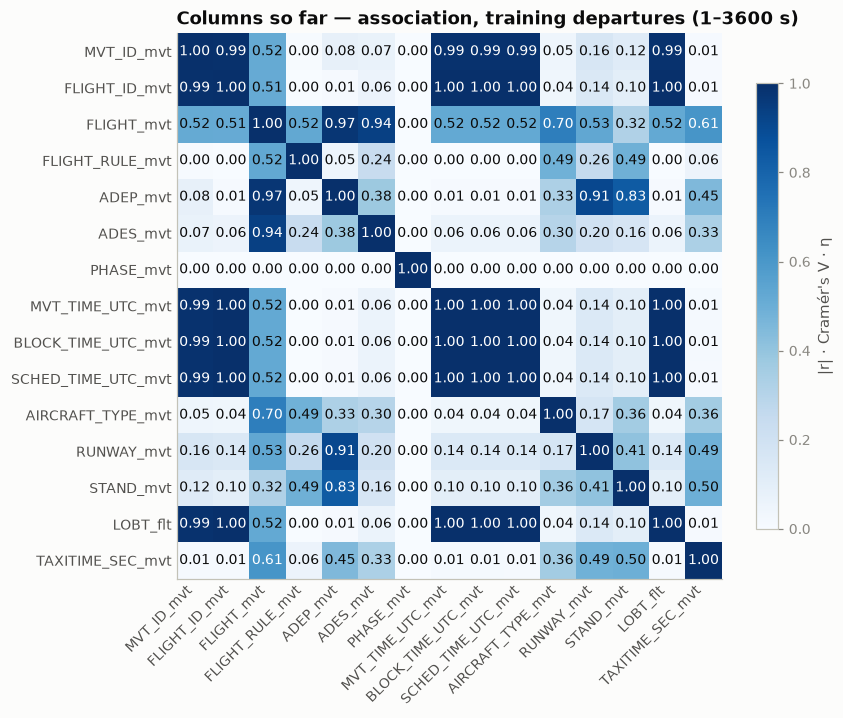

In [7]:
# ---- features so far, against each other ----
# One base table of training departures (1–3600 s): the columns covered so far, each in the form the
# pipeline should consume (the recovered rule and destination, the plan-first type of §11a, the twins' LOBT of §15), plus the target. To add a column from
# a later section: one line in the SELECT, one line in FEATURES.
con.sql(f"""
    CREATE OR REPLACE TABLE assoc_base AS
    SELECT t.MVT_ID_mvt, t.FLIGHT_ID_mvt, t.FLIGHT_mvt, t.rule_final AS FLIGHT_RULE_mvt, t.ADEP_mvt,
           d.dest_final AS ADES_mvt, t.PHASE_mvt, epoch(t.MVT_TIME_UTC_mvt) AS MVT_TIME_UTC_mvt,
           epoch(t.BLOCK_TIME_UTC_mvt) AS BLOCK_TIME_UTC_mvt, epoch(t.SCHED_TIME_UTC_mvt) AS SCHED_TIME_UTC_mvt,
           coalesce(t.AIRCRAFT_TYPE_flt, t.AIRCRAFT_TYPE_mvt) AS AIRCRAFT_TYPE_mvt, t.RUNWAY_mvt, t.STAND_mvt,
           epoch(coalesce(t.LOBT_flt, w.lobt_twin)) AS LOBT_flt,
           t.TAXITIME_SEC_mvt::DOUBLE AS TAXITIME_SEC_mvt
    FROM (SELECT * FROM ({FINAL}) WHERE ds = 'training' AND PHASE_mvt = 'DEP'
            AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600) t
    LEFT JOIN (SELECT MVT_ID_mvt, dest_final FROM ({FINALD}) WHERE ds = 'training') d USING (MVT_ID_mvt)
    LEFT JOIN {TWINS} w USING (MVT_ID_mvt)""")

FEATURES = [  # (column, kind, min_support for pooling rare levels)
    ("MVT_ID_mvt", "num", 1), ("FLIGHT_ID_mvt", "num", 1), ("FLIGHT_mvt", "cat", 20),
    ("FLIGHT_RULE_mvt", "cat", 1), ("ADEP_mvt", "cat", 1), ("ADES_mvt", "cat", 200),
    ("PHASE_mvt", "cat", 1), ("MVT_TIME_UTC_mvt", "num", 1), ("BLOCK_TIME_UTC_mvt", "num", 1),
    ("SCHED_TIME_UTC_mvt", "num", 1), ("AIRCRAFT_TYPE_mvt", "cat", 200), ("RUNWAY_mvt", "cat", 30),
    ("STAND_mvt", "cat", 30), ("LOBT_flt", "num", 1), ("TAXITIME_SEC_mvt", "num", 1),
]
names = [f[0] for f in FEATURES]
kind = {f[0]: f[1] for f in FEATURES}
sup = {f[0]: f[2] for f in FEATURES}
M = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for a, b in itertools.combinations(names, 2):
    if kind[a] == "num" and kind[b] == "num":
        v = abs(rho(a, "assoc_base", b)[0])
    elif kind[a] == "cat" and kind[b] == "cat":
        v = cramers_v(a, b, "assoc_base", sup[a], sup[b])
    else:
        c, n = (a, b) if kind[a] == "cat" else (b, a)
        v = eta(c, "assoc_base", n, sup[c])[0]
    M.loc[a, b] = M.loc[b, a] = v
print("|r| for numeric pairs · Cramér's V for categorical pairs · η for mixed pairs:")
print(M.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right", color=INK2)
ax.set_yticks(range(len(names)), names, color=INK2)
for i in range(len(names)):
    for j in range(len(names)):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.55 else INK)
ax.set_title("Columns so far — association, training departures (1–3600 s)")
ax.grid(False)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, shrink=0.75, label="|r| · Cramér's V · η")
fig.tight_layout()
plt.show()

**Reading the matrix**

| what it shows | cells | reading |
|---|---|---|
| **The two IDs and the three timestamps are one clock** | `MVT_ID_mvt` × `MVT_TIME_UTC_mvt` 0.99, `FLIGHT_ID_mvt` × `MVT_TIME_UTC_mvt` 1.00, the two IDs 0.99, `BLOCK_TIME_UTC_mvt` and `SCHED_TIME_UTC_mvt` × `MVT_TIME_UTC_mvt` 1.00 | both IDs are timestamps in disguise (§1, §2); off-block is takeoff minus a quarter of an hour and the schedule is off-block minus the delay — none of the five touches the target (0.01) |
| **`SCHED_TIME_UTC_mvt` hides its value in a difference too** | its row is the takeoff clock's row to two decimals; 0.01 with the target | takeoff − schedule is the delay (ρ 0.38 in §10's correlation cell) and, at Fiumicino without a plan, the corrupt label itself (§10a). A marginal measure of the stamp sees none of that |
| **`BLOCK_TIME_UTC_mvt` is the target's other endpoint, and the matrix cannot see it** | its row is `MVT_TIME_UTC_mvt`'s row to two decimals; 0.01 with the target | the label is the *difference* of the two clocks, which no marginal measure of either one carries. Hidden at prediction time anyway (§9); what stands in for it is takeoff − `AOBT_3` (ρ 0.62 in §9's correlation cell), which enters with the anchor's own section |
| **`LOBT_flt` is the fourth copy of the clock** | its row is `MVT_TIME_UTC_mvt`'s to two decimals: 1.00 with the takeoff, off-block and schedule stamps, 0.99 with the movement ID, 0.01 with the target | the plan's last off-block is the schedule on three flights in four (§15); what it knows is in its differences — takeoff − LOBT (ρ 0.51) and the unfiled delay `AOBT_3` − LOBT, worth 32 s on the anchor in §15's ladder — which no marginal measure of the stamp sees |
| **The flight number contains almost everything** | `FLIGHT_mvt` × `ADEP_mvt` 0.97, × `ADES_mvt` 0.94, × `FLIGHT_RULE_mvt` 0.52, × the clock 0.52 | a number *is* airline + route + slot, which is why its η with the target (0.61) is the highest here — and why it must be encoded with fallbacks, not used raw (§3: a fifth of 2026's numbers are new) |
| **The type is the fleet, and the fleet is the airline** | `AIRCRAFT_TYPE_mvt` × `FLIGHT_mvt` 0.70, × `FLIGHT_RULE_mvt` 0.49, × `ADEP_mvt` 0.33, × `ADES_mvt` 0.30 | a flight number is flown by one type most days, and VFR is light aircraft and helicopters (§4, §11); against the target the type reads 0.36 — heavies taxi longer (§11), and the number already knows the type |
| **The runway is the airport, spelled differently** | `RUNWAY_mvt` × `ADEP_mvt` 0.91, × `FLIGHT_mvt` 0.53, × `FLIGHT_RULE_mvt` 0.26, × `AIRCRAFT_TYPE_mvt` 0.17 | runway codes are hub-specific, so across hubs the code names the airport first and the distance second — its 0.49 against the target is mostly Heathrow's 1,300 s; the within-airport worth is §12's 14 s, and the pair with the stand (§12: 306 s) is where it counts |
| **The stand is the airport too — and the rule** | `STAND_mvt` × `ADEP_mvt` 0.83, × `FLIGHT_RULE_mvt` 0.49, × `RUNWAY_mvt` 0.41, × `AIRCRAFT_TYPE_mvt` 0.36, × `FLIGHT_mvt` 0.32 | stand codes are the hub's own, the GA aprons are where VFR parks (§4, §13), and a stand hosts a fleet; its 0.50 against the target is the highest of the geometry columns, and §13's ladder puts the within-hub worth at 34 s alone and 51 with the runway — the route is the feature |
| **Rule and destination travel together** | `FLIGHT_RULE_mvt` × `ADES_mvt` 0.24 | VFR flights go to off-airport places (§4, §6a); the rule adds little the destination does not already say |
| **Airport and destination overlap only partly** | 0.38 | each hub has its own destination set, but destination keeps signal of its own (§6: −21 s on the ladder after the airport) |
| **`PHASE_mvt` is a row of zeros** | constant on departures | nothing to correlate on the rows we predict (§7) — it stays in the matrix as a reminder, not a feature |
| **The target's row is a window number** | `TAXITIME_SEC_mvt` enters raw, on 1–3,600 s rows; on every label the airport's η falls 0.45 → 0.34 and takeoff − schedule's r rises 0.19 → 0.23 (§14's correlation cell) | the matrix measures association, and association is a window quantity; what the tail is worth is §14's raw-label ladders (airport 496.5 → 411.4 s), not a cell here |
| **What carries the target, alone** | `TAXITIME_SEC_mvt` row: `FLIGHT_mvt` 0.61, `STAND_mvt` 0.50, `RUNWAY_mvt` 0.49, `ADEP_mvt` 0.45, `AIRCRAFT_TYPE_mvt` 0.36, `ADES_mvt` 0.33, `FLIGHT_RULE_mvt` 0.06, the IDs and the four raw timestamps 0.01 | the ranking matches the ladders: airport is the anchor, destination the next step, the rule a rare-row flag. The raw timestamp carries nothing by itself — its value is in what is derived from it (§8: local hour, the window) and in the differences against the off-block clocks. These are marginal, in-sample associations; the honest holdout numbers in each section are what to believe about *gain* |